In [1]:
!ls -la /content/drive

ls: cannot access '/content/drive': No such file or directory


In [ ]:
!rm -rf /content/drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q earthengine-api==1.7.31 geemap==0.38.3
!pip install -q xarray==2026.4.0 netCDF4==1.7.4 rioxarray
!pip install -q geopandas==1.1.3 rasterstats==0.21.0 shapely pyproj
!pip install -q dataretrieval==1.2.0 metloom==0.9.4 "cdsapi>=0.7.7"
!pip install -q statsmodels linearmodels scikit-learn dowhy==0.14

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.4/480.4 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 92.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 68.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 342.5/342.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.8/164.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.8/64.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.8/102.8 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.1/102.1 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
import ee
ee.Authenticate()
ee.Initialize(project='ecohydro-project')
print(ee.String('ok').getInfo())
print("EE:", ee.String('ok').getInfo())

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


ok
EE: ok


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


In [ ]:
from google.colab import userdata
import os

netrc_content = f"machine urs.earthdata.nasa.gov\nlogin {userdata.get('EARTHDATA_USER')}\npassword {userdata.get('EARTHDATA_PASS')}\n"
with open('/root/.netrc', 'w') as f:
    f.write(netrc_content)
os.chmod('/root/.netrc', 0o600)

cds_content = f"url: https://cds.climate.copernicus.eu/api\nkey: {userdata.get('CDS_API_KEY')}\n"
with open('/root/.cdsapirc', 'w') as f:
    f.write(cds_content)

usgs_key = userdata.get('USGS_API_KEY')
print("Earthdata and CDS config written. USGS key loaded into memory.")

Earthdata and CDS config written. USGS key loaded into memory.


In [ ]:
import cdsapi, dataretrieval.nwis as nwis

c = cdsapi.Client()
print("CDS client authenticated:", c is not None)

df, meta = nwis.get_iv(sites='01646500', parameterCd='00060')
print("USGS reachable, sample rows:", len(df))

CDS client authenticated: True


/tmp/ipykernel_481/3198600779.py:6: DeprecationWarning: `nwis.get_iv` is deprecated and will be removed from `dataretrieval` on or after 2027-05-06; use `waterdata.get_continuous()` instead.
  df, meta = nwis.get_iv(sites='01646500', parameterCd='00060')


USGS reachable, sample rows: 1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
base = '/content/drive/MyDrive/ecohydro_project'

# Confirm key folders exist
required = ['scripts/stage_01','scripts/stage_02','scripts/stage_03','scripts/stage_04',
            'scripts/stage_05','scripts/stage_06','scripts/stage_07','scripts/stage_08',
            'scripts/stage_09','scripts/stage_10','scripts/stage_11',
            'data','outputs']
for f in required:
    path = os.path.join(base, f)
    if not os.path.exists(path):
        os.makedirs(path)
        print(f"Created: {f}")
    else:
        print(f"Exists: {f}")

print("Project root:", base)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Exists: scripts/stage_01
Exists: scripts/stage_02
Exists: scripts/stage_03
Exists: scripts/stage_04
Exists: scripts/stage_05
Exists: scripts/stage_06
Exists: scripts/stage_07
Exists: scripts/stage_08
Exists: scripts/stage_09
Exists: scripts/stage_10
Exists: scripts/stage_11
Exists: data
Exists: outputs
Project root: /content/drive/MyDrive/ecohydro_project


In [4]:
!pip freeze > /content/drive/MyDrive/ecohydro_project/scripts/stage_01/requirements.txt

# Quick peek at the first few lines
with open('/content/drive/MyDrive/ecohydro_project/scripts/stage_01/requirements.txt', 'r') as f:
    for i, line in enumerate(f):
        if i < 20:
            print(line.rstrip())
        else:
            print("...")
            break

absl-py==2.0.0
accelerate==1.15.0
access==1.1.10.post3
affine==3.0.1
aiofiles==25.1.0
aiohappyeyeballs==2.7.1
aiohttp==3.14.5
aiosignal==1.4.0
aiosqlite==0.22.1
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.12.1
altair==5.5.0
annotated-doc==0.0.5
annotated-types==0.8.0
anyio==4.15.1
anywidget==0.9.21
apsw==3.54.0.0
argon2-cffi==25.1.0
...


In [ ]:
script = '''
import ee
import cdsapi
from dataretrieval import nwis

ee.Initialize()
print("Earth Engine: OK")

c = cdsapi.Client()
print("CDS: OK")

df, meta = nwis.get_iv(sites='01646500', parameterCd='00060')
print("USGS: OK, rows:", len(df))

print("All four services authenticated successfully.")
'''

with open('/content/drive/MyDrive/ecohydro_project/scripts/stage_01/auth_check.py', 'w') as f:
    f.write(script)

print("auth_check.py written to scripts/stage_01")

auth_check.py written to scripts/stage_01


In [ ]:
import subprocess
base = '/content/drive/MyDrive/ecohydro_project'

# Set your git identity
subprocess.run(['git', 'config', 'user.email', 'iman21@iiserbpr.ac.in'], cwd=base, capture_output=True, text=True)
subprocess.run(['git', 'config', 'user.name', 'Iman Mahato'], cwd=base, capture_output=True, text=True)

# Stage and commit
result = subprocess.run(['git', 'add', '-A'], cwd=base, capture_output=True, text=True)
print("Staged:", result.stdout, result.stderr)

result = subprocess.run(['git', 'commit', '-m', 'Stage 1: environment setup, credentials note, version log, requirements.txt'], cwd=base, capture_output=True, text=True)
print("Committed:", result.stdout, result.stderr)

result = subprocess.run(['git', 'log', '--oneline', '-3'], cwd=base, capture_output=True, text=True)
print("Recent commits:", result.stdout)

In [ ]:
# import ee
# import geopandas as gpd
# import pandas as pd

# ee.Initialize(project='ecohydro-project')

# # Define WBD levels to test (only HUC02 and HUC04)
# wbd_levels = {
#     'HUC02': 'USGS/WBD/2017/HUC02',
#     'HUC04': 'USGS/WBD/2017/HUC04',
# }

# # Reproject to equal-area (EPSG:5070, Conus Albers)
# albers = 'EPSG:5070'

# results = []

# for level_name, collection_path in wbd_levels.items():
#     print(f"Processing {level_name}...")

#     # Load feature collection
#     fc = ee.FeatureCollection(collection_path)

#     # Convert to GeoDataFrame
#     gdf = gpd.GeoDataFrame.from_features(fc.getInfo()['features'], crs='EPSG:4326')

#     # Reproject to equal-area
#     gdf_ea = gdf.to_crs(albers)

#     # Compute area in km²
#     gdf_ea['area_km2_computed'] = gdf_ea.geometry.area / 1e6

#     # Count basins
#     n_basins = len(gdf_ea)

#     # Compute median, mean, min, max area
#     median_area = gdf_ea['area_km2_computed'].median()
#     mean_area = gdf_ea['area_km2_computed'].mean()
#     min_area = gdf_ea['area_km2_computed'].min()
#     max_area = gdf_ea['area_km2_computed'].max()

#     # Count basins >= 200,000 km²
#     n_above_200k = (gdf_ea['area_km2_computed'] >= 200000).sum()

#     results.append({
#         'level': level_name,
#         'n_basins': n_basins,
#         'median_area_km2': median_area,
#         'mean_area_km2': mean_area,
#         'min_area_km2': min_area,
#         'max_area_km2': max_area,
#         'n_above_200k': n_above_200k,
#     })

# # Create results DataFrame
# results_df = pd.DataFrame(results)

# # Compute difference from domestic HUC02 median (423,153 km²)
# domestic_median = 423153
# results_df['diff_from_domestic'] = (results_df['median_area_km2'] - domestic_median).abs()

# # Sort by closeness to domestic median
# results_df_sorted = results_df.sort_values('diff_from_domestic')

# print("\nWBD Level Comparison (HUC02 vs HUC04):")
# print(results_df_sorted.to_string(index=False))

# # Identify best matching level
# best_level = results_df_sorted.iloc[0]['level']
# print(f"\nBest matching level to domestic HUC02 median: {best_level}")

# # Save comparison table
# base = '/content/drive/MyDrive/ecohydro_project'
# results_df.to_csv(f'{base}/outputs/wbd_level_comparison.csv', index=False)
# print(f"\nLevel comparison table saved to: {base}/outputs/wbd_level_comparison.csv")

In [ ]:
import ee

ee.Initialize(project='ecohydro-project')

import geopandas as gpd

# Load HUC02 and HUC04 feature collections
huc02 = ee.FeatureCollection('USGS/WBD/2017/HUC02')
huc04 = ee.FeatureCollection('USGS/WBD/2017/HUC04')

# Export to GeoJSON via getInfo
huc02_geojson = huc02.getInfo()
huc04_geojson = huc04.getInfo()

# Convert to GeoDataFrames
gdf_huc02 = gpd.GeoDataFrame.from_features(huc02_geojson['features'], crs='EPSG:4326')
gdf_huc04 = gpd.GeoDataFrame.from_features(huc04_geojson['features'], crs='EPSG:4326')

print(f"HUC02: {len(gdf_huc02)} features")
print(f"Columns: {list(gdf_huc02.columns)}")
print(f"HUC04: {len(gdf_huc04)} features")
print(f"Columns: {list(gdf_huc04.columns)}")

HUC02: 22 features
Columns: ['geometry', 'areaacres', 'areasqkm', 'gnis_id', 'huc2', 'loaddate', 'metasource', 'name', 'shape_area', 'shape_leng', 'sourcedata', 'sourcefeat', 'sourceorig', 'states', 'tnmid']
HUC04: 223 features
Columns: ['geometry', 'areaacres', 'areasqkm', 'gnis_id', 'huc4', 'loaddate', 'metasource', 'name', 'shape_area', 'shape_leng', 'sourcedata', 'sourcefeat', 'sourceorig', 'states', 'tnmid']


In [ ]:
import os
import json

base = '/content/drive/MyDrive/ecohydro_project'

# Create raw data folder for WBD
raw_dir_wbd = f'{base}/data/raw/wbd_2017'
os.makedirs(raw_dir_wbd, exist_ok=True)

# Save raw HUC02 and HUC04 as GeoJSON (before any processing)
with open(f'{raw_dir_wbd}/wbd_huc02_raw.geojson', 'w') as f:
    json.dump(huc02_geojson, f)

with open(f'{raw_dir_wbd}/wbd_huc04_raw.geojson', 'w') as f:
    json.dump(huc04_geojson, f)

print(f"Raw WBD data saved to: {raw_dir_wbd}")
print(f"  - wbd_huc02_raw.geojson: {len(huc02_geojson['features'])} features")
print(f"  - wbd_huc04_raw.geojson: {len(huc04_geojson['features'])} features")

Raw WBD data saved to: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017
  - wbd_huc02_raw.geojson: 22 features
  - wbd_huc04_raw.geojson: 223 features


In [ ]:
import ee
import geemap
import os
import time

ee.Initialize(project='ecohydro-project')

base = '/content/drive/MyDrive/ecohydro_project'
raw_dir_wbd = f'{base}/data/raw/wbd_2017'

# CONUS HUC02 codes (01-18)
conus_huc2_codes = [f'{i:02d}' for i in range(1, 19)]
print(f"CONUS HUC02 regions to export: {conus_huc2_codes}")
print(f"Total: {len(conus_huc2_codes)} regions\n")

# Define levels to export
wbd_levels = {
    'HUC06': 'USGS/WBD/2017/HUC06',
    'HUC08': 'USGS/WBD/2017/HUC08',
}

# Create output folder
output_dir = f'{raw_dir_wbd}/wbd_2017_by_region'
os.makedirs(output_dir, exist_ok=True)
print(f"Output folder: {output_dir}\n")

for level_name, collection_path in wbd_levels.items():
    print("="*70)
    print(f"Processing {level_name} ({collection_path})")
    print("="*70)

    huc_col = 'huc6' if level_name == 'HUC06' else 'huc8'

    for huc2_code in conus_huc2_codes:
        region_name = f"Region_{huc2_code}"
        output_path = f'{output_dir}/wbd_{level_name.lower()}_{region_name}_raw.geojson'

        # Skip if already exists
        if os.path.exists(output_path):
            print(f"  [{huc2_code}] Already exists, skipping...")
            continue

        try:
            # Load collection
            fc = ee.FeatureCollection(collection_path)

            # Filter to this HUC02 region (first 2 digits of HUC code)
            fc_region = fc.filter(ee.Filter.stringStartsWith(huc_col, huc2_code))

            # Count features
            n_features = fc_region.size().getInfo()

            if n_features == 0:
                print(f"  [{huc2_code}] No features found, skipping...")
                continue

            print(f"  [{huc2_code}] Exporting {n_features} features...", end=" ")

            # Export using geemap
            geemap.ee_export_vector(fc_region, output_path)

            # Verify output
            if os.path.exists(output_path):
                size = os.path.getsize(output_path)
                if size > 1000 and 'error' not in open(output_path, 'r').read(200).lower():
                    print(f"✓ Saved ({size / 1024:.1f} KB)")
                else:
                    print(f"✗ Failed (file too small or contains error)")
                    if os.path.exists(output_path):
                        os.remove(output_path)
            else:
                print(f"✗ File not created")

        except Exception as e:
            print(f"✗ ERROR: {e}")

        time.sleep(1)  # Brief pause between exports

    print()

print("\n" + "="*70)
print("Export complete!")
print("="*70)
print(f"\nFiles saved to: {output_dir}")
print("\nSummary:")
for level_name in wbd_levels.keys():
    files = [f for f in os.listdir(output_dir) if level_name.lower() in f and f.endswith('.geojson')]
    print(f"  {level_name}: {len(files)} regional files")

CONUS HUC02 regions to export: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18']
Total: 18 regions

Output folder: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_2017_by_region

Processing HUC06 (USGS/WBD/2017/HUC06)
  [01] Already exists, skipping...
  [02] Already exists, skipping...
  [03] Already exists, skipping...
  [04] Already exists, skipping...
  [05] Already exists, skipping...
  [06] Already exists, skipping...
  [07] Already exists, skipping...
  [08] Already exists, skipping...
  [09] Already exists, skipping...
  [10] Already exists, skipping...
  [11] Already exists, skipping...
  [12] Already exists, skipping...
  [13] Already exists, skipping...
  [14] Already exists, skipping...
  [15] Already exists, skipping...
  [16] Already exists, skipping...
  [17] Already exists, skipping...
  [18] Already exists, skipping...

Processing HUC08 (USGS/WBD/2017/HUC08)
  [01] Already exists, skipping...
  [0

In [ ]:
import ee
import os

ee.Initialize(project='ecohydro-project')

base = '/content/drive/MyDrive/ecohydro_project'
raw_dir_wbd = f'{base}/data/raw/wbd_2017'
output_dir = f'{raw_dir_wbd}/wbd_2017_by_region'

conus_huc2_codes = [f'{i:02d}' for i in range(1, 19)]

print("="*70)
print("STEP 1: Check for failed/missing HUC08 regions")
print("="*70)

# Identify which HUC08 regions are missing or error-files
failed_regions = []

for huc2_code in conus_huc2_codes:
    output_path = f'{output_dir}/wbd_huc08_Region_{huc2_code}_raw.geojson'

    if not os.path.exists(output_path):
        print(f"  [{huc2_code}] MISSING - will submit retry Task")
        failed_regions.append(huc2_code)
        continue

    size = os.path.getsize(output_path)
    with open(output_path, 'r') as f:
        content = f.read(200)

    if size < 1000 or 'error' in content.lower():
        print(f"  [{huc2_code}] ERROR FILE ({size} bytes) - will submit retry Task")
        failed_regions.append(huc2_code)
    else:
        print(f"  [{huc2_code}] OK ({size / 1024:.1f} KB)")

print(f"\nRegions needing retry: {failed_regions}")

# Submit ee.batch.Export Tasks for failed regions only
if failed_regions:
    print("\n" + "="*70)
    print("STEP 2: Submitting ee.batch.Export Tasks for failed regions")
    print("="*70)

    for huc2_code in failed_regions:
        try:
            fc = ee.FeatureCollection('USGS/WBD/2017/HUC08')
            fc_region = fc.filter(ee.Filter.stringStartsWith('huc8', huc2_code))
            n_features = fc_region.size().getInfo()

            print(f"\n  [{huc2_code}] Submitting Task for {n_features} features...")

            task = ee.batch.Export.table.toDrive(
                collection=fc_region,
                description=f'wbd_huc08_region_{huc2_code}_retry',
                folder='ecohydro_project/data/raw/wbd_2017/wbd_2017_by_region',
                fileNamePrefix=f'wbd_huc08_Region_{huc2_code}_raw',
                fileFormat='GeoJSON'
            )
            task.start()
            print(f"  [{huc2_code}] Task submitted: {task.id}")

        except Exception as e:
            print(f"  [{huc2_code}] ERROR submitting Task: {e}")

    print("\n" + "="*70)
    print("ACTION REQUIRED:")
    print("="*70)
    print("1. Go to https://code.earthengine.google.com/tasks")
    print("2. Click Run on the Tasks listed above")
    print("3. Wait for all Tasks to show 'Completed'")
    print("4. Re-run this cell to verify all regions are OK")
    print("5. Then proceed to the separate merge cell")
    print("="*70)
else:
    print("\n✓ All 18 HUC08 regions are present and valid.")
    print("Proceed to the merge cell.")

STEP 1: Check for failed/missing HUC08 regions
  [01] OK (31177.8 KB)
  [02] OK (25205.8 KB)
  [03] OK (69154.3 KB)
  [04] OK (71298.6 KB)
  [05] OK (41945.1 KB)
  [06] OK (13199.2 KB)
  [07] OK (44313.0 KB)
  [08] OK (24270.6 KB)
  [09] OK (27764.0 KB)
  [10] OK (148560.6 KB)
  [11] OK (66202.7 KB)
  [12] OK (17802.5 KB)
  [13] OK (22699.1 KB)
  [14] OK (23907.2 KB)
  [15] OK (45058.6 KB)
  [16] OK (41499.2 KB)
  [17] OK (99395.4 KB)
  [18] OK (45495.5 KB)

Regions needing retry: []

✓ All 18 HUC08 regions are present and valid.
Proceed to the merge cell.


In [ ]:
import geopandas as gpd
import pandas as pd
import os

base = '/content/drive/MyDrive/ecohydro_project'
raw_dir_wbd = f'{base}/data/raw/wbd_2017'
output_dir = f'{raw_dir_wbd}/wbd_2017_by_region'

conus_huc2_codes = [f'{i:02d}' for i in range(1, 19)]

print("="*70)
print("MERGING ALL REGIONAL FILES INTO CONUS-WIDE GEOJSONs")
print("="*70)

for level_name in ['HUC06', 'HUC08']:
    print(f"\nMerging {level_name}...")

    gdfs = []
    skipped = []

    for huc2_code in conus_huc2_codes:
        filepath = f'{output_dir}/wbd_{level_name.lower()}_Region_{huc2_code}_raw.geojson'

        if not os.path.exists(filepath):
            print(f"  [{huc2_code}] MISSING - skipping")
            skipped.append(huc2_code)
            continue

        # Check if it's a valid GeoJSON (not an error file)
        try:
            with open(filepath, 'r') as f:
                content = f.read(200)
            if 'error' in content.lower():
                print(f"  [{huc2_code}] ERROR FILE - skipping")
                skipped.append(huc2_code)
                continue

            gdf = gpd.read_file(filepath)
            if len(gdf) > 0:
                gdfs.append(gdf)
                print(f"  [{huc2_code}] Loaded {len(gdf)} features")
            else:
                print(f"  [{huc2_code}] Empty - skipping")
                skipped.append(huc2_code)

        except Exception as e:
            print(f"  [{huc2_code}] Read error - skipping: {e}")
            skipped.append(huc2_code)

    if len(gdfs) > 0:
        gdf_conus = pd.concat(gdfs, ignore_index=True)
        print(f"\n  Total merged features: {len(gdf_conus)}")
        print(f"  Skipped regions: {skipped}")

        # Save as CONUS-wide GeoJSON
        output_path = f'{raw_dir_wbd}/wbd_{level_name.lower()}_conus_2017.geojson'
        gdf_conus.to_file(output_path, driver='GeoJSON')
        size = os.path.getsize(output_path)
        print(f"  Saved to: {output_path}")
        print(f"  File size: {size / (1024*1024):.1f} MB")
    else:
        print(f"  No files found for {level_name}!")

print("\n" + "="*70)
print("COMPLETE!")
print("="*70)
print(f"\nFinal CONUS-wide files:")
for level_name in ['HUC06', 'HUC08']:
    filepath = f'{raw_dir_wbd}/wbd_{level_name.lower()}_conus_2017.geojson'
    if os.path.exists(filepath):
        size = os.path.getsize(filepath)
        print(f"  {filepath}: {size / (1024*1024):.1f} MB")
    else:
        print(f"  {filepath}: NOT CREATED")

MERGING ALL REGIONAL FILES INTO CONUS-WIDE GEOJSONs

Merging HUC06...
  [01] Loaded 11 features
  [02] Loaded 13 features
  [03] Loaded 33 features
  [04] Loaded 30 features
  [05] Loaded 21 features
  [06] Loaded 5 features
  [07] Loaded 17 features
  [08] Loaded 22 features
  [09] Loaded 6 features
  [10] Loaded 43 features
  [11] Loaded 25 features
  [12] Loaded 22 features
  [13] Loaded 13 features
  [14] Loaded 10 features
  [15] Loaded 15 features
  [16] Loaded 12 features
  [17] Loaded 22 features
  [18] Loaded 16 features

  Total merged features: 336
  Skipped regions: []
  Saved to: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc06_conus_2017.geojson
  File size: 434.1 MB

Merging HUC08...
  [01] Loaded 58 features
  [02] Loaded 88 features
  [03] Loaded 203 features
  [04] Loaded 124 features
  [05] Loaded 120 features
  [06] Loaded 32 features
  [07] Loaded 131 features
  [08] Loaded 82 features
  [09] Loaded 48 features
  [10] Loaded 307 features
  [11] L

In [5]:
import geopandas as gpd
import pandas as pd
import numpy as np

base = '/content/drive/MyDrive/ecohydro_project'
raw_dir_wbd = f'{base}/data/raw/wbd_2017'
albers = 'EPSG:5070'

print("="*70)
print("LOADING DATASETS")
print("="*70)

# Load all four levels
huc02 = gpd.read_file(f'{raw_dir_wbd}/wbd_huc02_raw.geojson')
huc04 = gpd.read_file(f'{raw_dir_wbd}/wbd_huc04_raw.geojson')
huc06 = gpd.read_file(f'{raw_dir_wbd}/wbd_huc06_conus_2017.geojson')
huc08 = gpd.read_file(f'{raw_dir_wbd}/wbd_huc08_conus_2017.geojson')

print(f"HUC02: {len(huc02)} features")
print(f"HUC04: {len(huc04)} features")
print(f"HUC06: {len(huc06)} features")
print(f"HUC08: {len(huc08)} features")


print("\n" + "="*70)
print("TEST 1: NESTING VALIDATION")
print("="*70)

# Test HUC06 nests inside HUC04 (first 4 digits of huc6 should match a huc4 code)
print("\nHUC06 → HUC04 nesting:")
huc06['huc4_from_huc6'] = huc06['huc6'].astype(str).str[:4]
huc04_codes = set(huc04['huc4'].astype(str).str.zfill(4))

huc06_nested = huc06[huc06['huc4_from_huc6'].isin(huc04_codes)]
huc06_not_nested = huc06[~huc06['huc4_from_huc6'].isin(huc04_codes)]

print(f"  HUC06 basins that nest inside a HUC04: {len(huc06_nested)} / {len(huc06)} ({len(huc06_nested)/len(huc06)*100:.1f}%)")
if len(huc06_not_nested) > 0:
    print(f"   HUC06 basins WITHOUT matching HUC04 parent: {len(huc06_not_nested)}")
    print(f"    Sample orphan huc6 codes: {huc06_not_nested['huc6'].head().tolist()}")
else:
    print("   All HUC06 basins nest properly inside HUC04 parents")

# Test HUC08 nests inside HUC06 (first 6 digits of huc8 should match a huc6 code)
print("\nHUC08 → HUC06 nesting:")
huc08['huc6_from_huc8'] = huc08['huc8'].astype(str).str[:6]
huc06_codes = set(huc06['huc6'].astype(str).str.zfill(6))

huc08_nested = huc08[huc08['huc6_from_huc8'].isin(huc06_codes)]
huc08_not_nested = huc08[~huc08['huc6_from_huc8'].isin(huc06_codes)]

print(f"  HUC08 basins that nest inside a HUC06: {len(huc08_nested)} / {len(huc08)} ({len(huc08_nested)/len(huc08)*100:.1f}%)")
if len(huc08_not_nested) > 0:
    print(f"  ⚠ HUC08 basins WITHOUT matching HUC06 parent: {len(huc08_not_nested)}")
    print(f"    Sample orphan huc8 codes: {huc08_not_nested['huc8'].head().tolist()}")
else:
    print("  ✓ All HUC08 basins nest properly inside HUC06 parents")


print("\n" + "="*70)
print("TEST 2: AREA VALIDATION (computed vs attribute)")
print("="*70)

def validate_area(gdf, huc_col, area_col, label):
    """Validate computed area against attribute area"""
    gdf_ea = gdf.to_crs(albers)
    gdf_ea['area_km2_computed'] = gdf_ea.geometry.area / 1e6
    gdf_ea['area_km2_attribute'] = pd.to_numeric(gdf_ea[area_col], errors='coerce')

    gdf_ea['area_pct_diff'] = (
        (gdf_ea['area_km2_computed'] - gdf_ea['area_km2_attribute']).abs()
        / gdf_ea['area_km2_attribute'] * 100
    )

    valid = gdf_ea[gdf_ea['area_km2_attribute'].notna() & (gdf_ea['area_km2_attribute'] > 0)].copy()

    print(f"\n{label}")
    print(f"  Basins validated: {len(valid)}")
    print(f"  Median discrepancy: {valid['area_pct_diff'].median():.3f}%")
    print(f"  Max discrepancy: {valid['area_pct_diff'].max():.3f}%")
    print(f"  Basins within 1%: {(valid['area_pct_diff'] <= 1).sum()} / {len(valid)} ({(valid['area_pct_diff'] <= 1).sum()/len(valid)*100:.1f}%)")

    if (valid['area_pct_diff'] > 1).any():
        high_diff = valid[valid['area_pct_diff'] > 1].sort_values('area_pct_diff', ascending=False).head(5)
        print(f"  Top 5 outliers:")
        for _, row in high_diff.iterrows():
            print(f"    {row[huc_col]}: {row['area_pct_diff']:.2f}% diff (computed: {row['area_km2_computed']:.1f}, attribute: {row['area_km2_attribute']:.1f})")

    return valid

# Validate HUC06
huc06_check = validate_area(huc06, 'huc6', 'areasqkm', 'HUC06 Area Validation')

# Validate HUC08
huc08_check = validate_area(huc08, 'huc8', 'areasqkm', 'HUC08 Area Validation')


print("\n" + "="*70)
print("TEST 3: GEOMETRY QUALITY")
print("="*70)

# Check for invalid geometries
print("\nInvalid geometries:")
print(f"  HUC06: {(~huc06.geometry.is_valid).sum()} / {len(huc06)} ({(~huc06.geometry.is_valid).sum()/len(huc06)*100:.1f}%)")
print(f"  HUC08: {(~huc08.geometry.is_valid).sum()} / {len(huc08)} ({(~huc08.geometry.is_valid).sum()/len(huc08)*100:.1f}%)")

# Check for empty geometries
print("\nEmpty geometries:")
print(f"  HUC06: {huc06.geometry.is_empty.sum()} / {len(huc06)}")
print(f"  HUC08: {huc08.geometry.is_empty.sum()} / {len(huc08)}")

# Check for null geometries
print("\nNull geometries:")
print(f"  HUC06: {huc06.geometry.isna().sum()} / {len(huc06)}")
print(f"  HUC08: {huc08.geometry.isna().sum()} / {len(huc08)}")


print("\n" + "="*70)
print("VALIDATION SUMMARY")
print("="*70)

# Nesting
huc06_nest_ok = len(huc06_not_nested) == 0
huc08_nest_ok = len(huc08_not_nested) == 0

# Area validation
huc06_area_ok = (huc06_check['area_pct_diff'].median() < 1) and ((huc06_check['area_pct_diff'] <= 1).sum() / len(huc06_check) > 0.99)
huc08_area_ok = (huc08_check['area_pct_diff'].median() < 1) and ((huc08_check['area_pct_diff'] <= 1).sum() / len(huc08_check) > 0.99)

# Geometry
huc06_geom_ok = ((~huc06.geometry.is_valid).sum() == 0) and (huc06.geometry.is_empty.sum() == 0) and (huc06.geometry.isna().sum() == 0)
huc08_geom_ok = ((~huc08.geometry.is_valid).sum() == 0) and (huc08.geometry.is_empty.sum() == 0) and (huc08.geometry.isna().sum() == 0)

print("\nHUC06:")
print(f"   Nesting: {'PASS' if huc06_nest_ok else 'FAIL'}")
print(f"   Area validation: {'PASS' if huc06_area_ok else 'FAIL'}")
print(f"   Geometry quality: {'PASS' if huc06_geom_ok else 'FAIL'}")

print("\nHUC08:")
print(f"   Nesting: {'PASS' if huc08_nest_ok else 'FAIL'}")
print(f"   Area validation: {'PASS' if huc08_area_ok else 'FAIL'}")
print(f"   Geometry quality: {'PASS' if huc08_geom_ok else 'FAIL'}")

if all([huc06_nest_ok, huc06_area_ok, huc06_geom_ok, huc08_nest_ok, huc08_area_ok, huc08_geom_ok]):
    print("\n ALL VALIDATION TESTS PASSED!")
else:
    print("\n Some tests failed — review details above.")

LOADING DATASETS
HUC02: 22 features
HUC04: 223 features
HUC06: 336 features
HUC08: 2121 features

TEST 1: NESTING VALIDATION

HUC06 → HUC04 nesting:
  HUC06 basins that nest inside a HUC04: 336 / 336 (100.0%)
   All HUC06 basins nest properly inside HUC04 parents

HUC08 → HUC06 nesting:
  HUC08 basins that nest inside a HUC06: 2121 / 2121 (100.0%)
  ✓ All HUC08 basins nest properly inside HUC06 parents

TEST 2: AREA VALIDATION (computed vs attribute)

HUC06 Area Validation
  Basins validated: 336
  Median discrepancy: 0.000%
  Max discrepancy: 0.006%
  Basins within 1%: 336 / 336 (100.0%)

HUC08 Area Validation
  Basins validated: 2121
  Median discrepancy: 0.000%
  Max discrepancy: 0.017%
  Basins within 1%: 2121 / 2121 (100.0%)

TEST 3: GEOMETRY QUALITY

Invalid geometries:
  HUC06: 0 / 336 (0.0%)
  HUC08: 0 / 2121 (0.0%)

Empty geometries:
  HUC06: 0 / 336
  HUC08: 0 / 2121

Null geometries:
  HUC06: 0 / 336
  HUC08: 0 / 2121

VALIDATION SUMMARY

HUC06:
   Nesting: PASS
   Area vali

FIGURE 1: All four levels side-by-side (CONUS overview)
Saved to: /content/drive/MyDrive/ecohydro_project/outputs/figures/huc_all_levels_overview.png


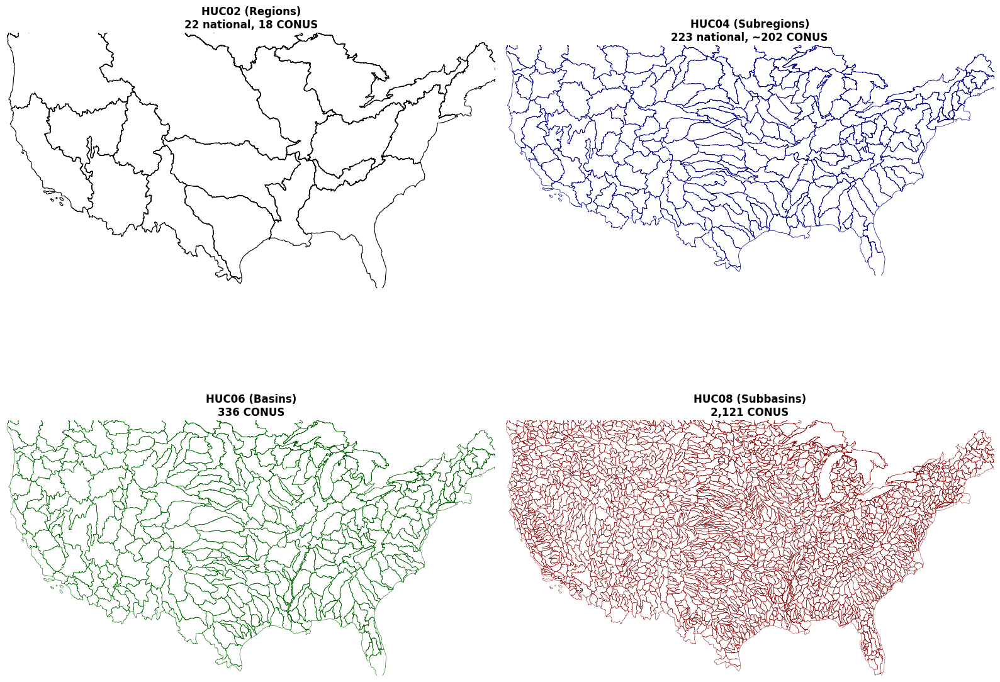


FIGURE 2: Zoom-in on one HUC02 region showing nested levels
Saved to: /content/drive/MyDrive/ecohydro_project/outputs/figures/huc_nesting_example_region10.png


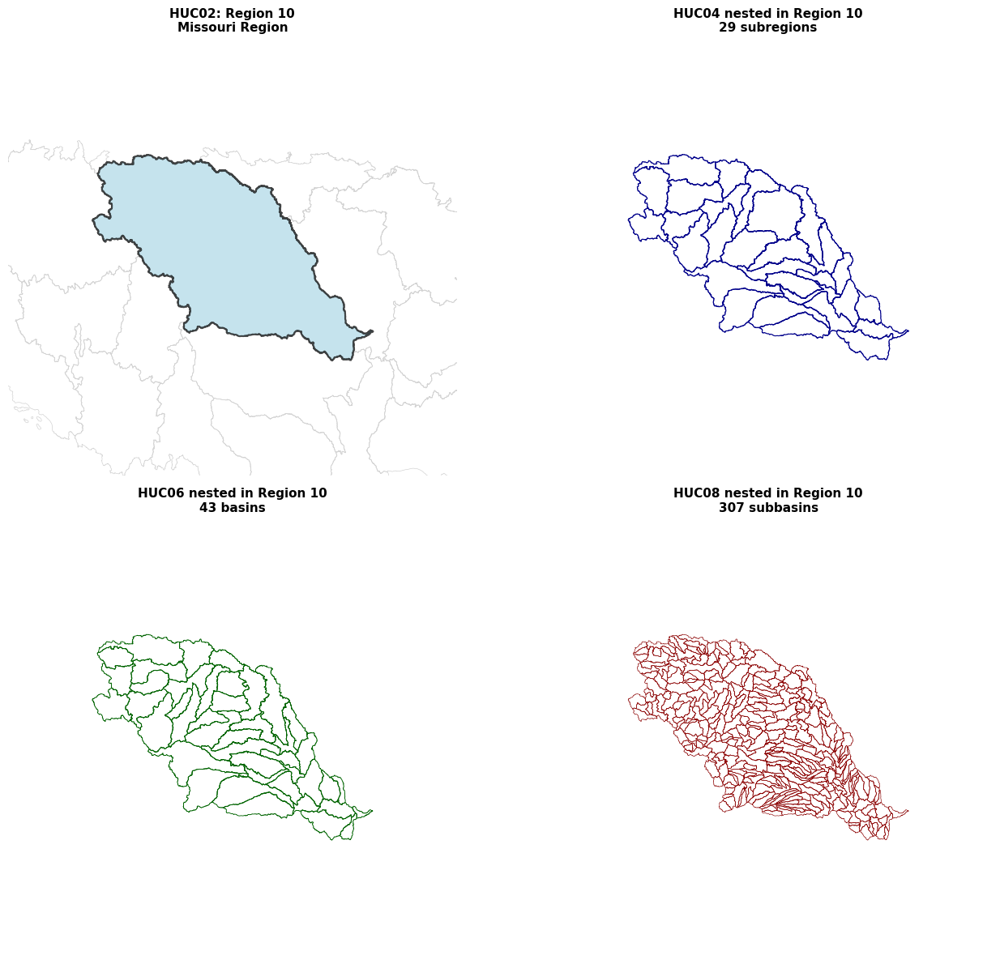


FIGURE 3: Area distribution across all levels
Saved to: /content/drive/MyDrive/ecohydro_project/outputs/figures/huc_area_distribution.png


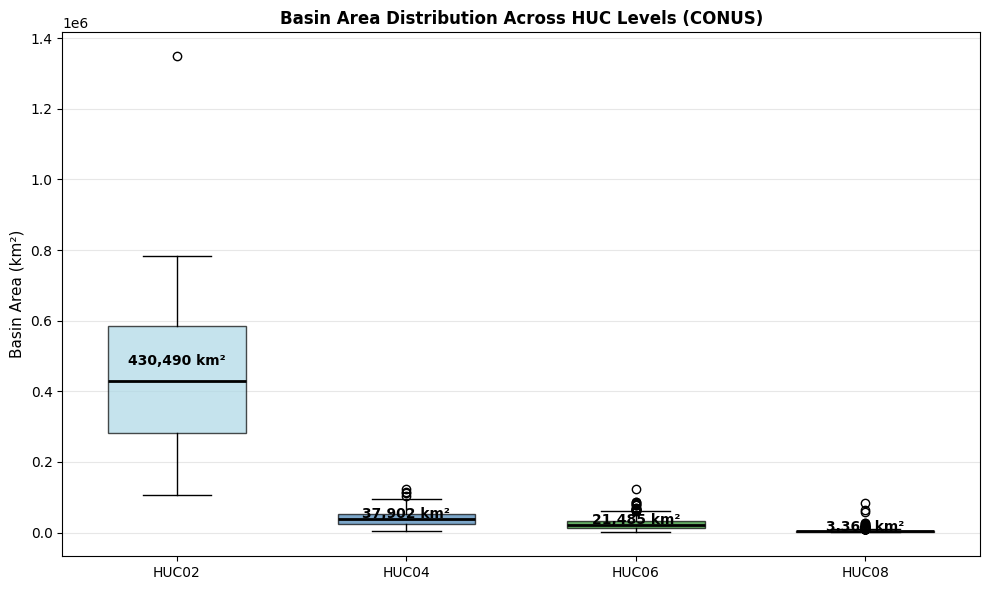


All figures saved to outputs/figures/


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

base = '/content/drive/MyDrive/ecohydro_project'
raw_dir_wbd = f'{base}/data/raw/wbd_2017'

# Load all four levels
huc02 = gpd.read_file(f'{raw_dir_wbd}/wbd_huc02_raw.geojson')
huc04 = gpd.read_file(f'{raw_dir_wbd}/wbd_huc04_raw.geojson')
huc06 = gpd.read_file(f'{raw_dir_wbd}/wbd_huc06_conus_2017.geojson')
huc08 = gpd.read_file(f'{raw_dir_wbd}/wbd_huc08_conus_2017.geojson')

# Filter to CONUS for HUC02 (exclude Alaska, Hawaii, Caribbean, South Pacific)
non_conus = {'19', '20', '21', '22'}
huc02_conus = huc02[~huc02['huc2'].astype(str).str.zfill(2).isin(non_conus)].copy()

print("="*70)
print("FIGURE 1: All four levels side-by-side (CONUS overview)")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# HUC02
ax = axes[0, 0]
huc02_conus.plot(ax=ax, edgecolor='black', facecolor='none', linewidth=0.8)
ax.set_title('HUC02 (Regions)\n22 national, 18 CONUS', fontsize=12, fontweight='bold')
ax.set_axis_off()
ax.set_xlim(-125, -67)
ax.set_ylim(25, 49)

# HUC04
ax = axes[0, 1]
huc04.plot(ax=ax, edgecolor='darkblue', facecolor='none', linewidth=0.5)
ax.set_title('HUC04 (Subregions)\n223 national, ~202 CONUS', fontsize=12, fontweight='bold')
ax.set_axis_off()
ax.set_xlim(-125, -67)
ax.set_ylim(25, 49)

# HUC06
ax = axes[1, 0]
huc06.plot(ax=ax, edgecolor='darkgreen', facecolor='none', linewidth=0.4)
ax.set_title('HUC06 (Basins)\n336 CONUS', fontsize=12, fontweight='bold')
ax.set_axis_off()
ax.set_xlim(-125, -67)
ax.set_ylim(25, 49)

# HUC08
ax = axes[1, 1]
huc08.plot(ax=ax, edgecolor='darkred', facecolor='none', linewidth=0.3)
ax.set_title('HUC08 (Subbasins)\n2,121 CONUS', fontsize=12, fontweight='bold')
ax.set_axis_off()
ax.set_xlim(-125, -67)
ax.set_ylim(25, 49)

plt.tight_layout()
output_path = f'{base}/outputs/figures/huc_all_levels_overview.png'
plt.savefig(output_path, dpi=150, bbox_inches='tight')
print(f"Saved to: {output_path}")
plt.show()


print("\n" + "="*70)
print("FIGURE 2: Zoom-in on one HUC02 region showing nested levels")
print("="*70)

# Pick a medium-sized HUC02 region (e.g., HUC 10 = Missouri Region)
example_huc2 = '10'
huc02_example = huc02[huc02['huc2'].astype(str).str.zfill(2) == example_huc2].iloc[0]

# Get bounding box
minx, miny, maxx, maxy = huc02_example.geometry.bounds

# Add some padding
padding = (maxx - minx) * 0.3
bounds = (minx - padding, miny - padding, maxx + padding, maxy + padding)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# HUC02
ax = axes[0, 0]
huc02_conus.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5)
huc02[huc02['huc2'].astype(str).str.zfill(2) == example_huc2].plot(
    ax=ax, edgecolor='black', facecolor='lightblue', linewidth=1.5, alpha=0.7
)
ax.set_title(f'HUC02: Region {example_huc2}\n{huc02_example["name"]}', fontsize=11, fontweight='bold')
ax.set_axis_off()
ax.set_xlim(bounds[0], bounds[2])
ax.set_ylim(bounds[1], bounds[3])

# HUC04 nested in this HUC02
ax = axes[0, 1]
huc04_example = huc04[huc04['huc4'].astype(str).str.startswith(example_huc2.zfill(2))]
huc04_example.plot(ax=ax, edgecolor='darkblue', facecolor='none', linewidth=0.8)
ax.set_title(f'HUC04 nested in Region {example_huc2}\n{len(huc04_example)} subregions', fontsize=11, fontweight='bold')
ax.set_axis_off()
ax.set_xlim(bounds[0], bounds[2])
ax.set_ylim(bounds[1], bounds[3])

# HUC06 nested in this HUC02
ax = axes[1, 0]
huc06_example = huc06[huc06['huc6'].astype(str).str.startswith(example_huc2.zfill(2))]
huc06_example.plot(ax=ax, edgecolor='darkgreen', facecolor='none', linewidth=0.6)
ax.set_title(f'HUC06 nested in Region {example_huc2}\n{len(huc06_example)} basins', fontsize=11, fontweight='bold')
ax.set_axis_off()
ax.set_xlim(bounds[0], bounds[2])
ax.set_ylim(bounds[1], bounds[3])

# HUC08 nested in this HUC02
ax = axes[1, 1]
huc08_example = huc08[huc08['huc8'].astype(str).str.startswith(example_huc2.zfill(2))]
huc08_example.plot(ax=ax, edgecolor='darkred', facecolor='none', linewidth=0.4)
ax.set_title(f'HUC08 nested in Region {example_huc2}\n{len(huc08_example)} subbasins', fontsize=11, fontweight='bold')
ax.set_axis_off()
ax.set_xlim(bounds[0], bounds[2])
ax.set_ylim(bounds[1], bounds[3])

plt.tight_layout()
output_path = f'{base}/outputs/figures/huc_nesting_example_region{example_huc2}.png'
plt.savefig(output_path, dpi=150, bbox_inches='tight')
print(f"Saved to: {output_path}")
plt.show()


print("\n" + "="*70)
print("FIGURE 3: Area distribution across all levels")
print("="*70)

# Compute areas in equal-area projection
albers = 'EPSG:5070'

huc02_conus_ea = huc02_conus.to_crs(albers)
huc02_conus_ea['area_km2'] = huc02_conus_ea.geometry.area / 1e6

huc04_conus = huc04[~huc04['huc4'].astype(str).str[:2].isin(non_conus)].copy()
huc04_conus_ea = huc04_conus.to_crs(albers)
huc04_conus_ea['area_km2'] = huc04_conus_ea.geometry.area / 1e6

huc06_ea = huc06.to_crs(albers)
huc06_ea['area_km2'] = huc06_ea.geometry.area / 1e6

huc08_ea = huc08.to_crs(albers)
huc08_ea['area_km2'] = huc08_ea.geometry.area / 1e6

fig, ax = plt.subplots(figsize=(10, 6))

levels = ['HUC02', 'HUC04', 'HUC06', 'HUC08']
areas = [
    huc02_conus_ea['area_km2'],
    huc04_conus_ea['area_km2'],
    huc06_ea['area_km2'],
    huc08_ea['area_km2']
]

colors = ['lightblue', 'steelblue', 'forestgreen', 'indianred']

for level, area_data, color in zip(levels, areas, colors):
    ax.boxplot(area_data, positions=[levels.index(level)], widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.7),
               medianprops=dict(color='black', linewidth=2))

ax.set_ylabel('Basin Area (km²)', fontsize=11)
ax.set_title('Basin Area Distribution Across HUC Levels (CONUS)', fontsize=12, fontweight='bold')
ax.set_xticks(range(len(levels)))
ax.set_xticklabels(levels)
ax.grid(axis='y', alpha=0.3)

# Add median labels
for i, area_data in enumerate(areas):
    median = area_data.median()
    ax.text(i, median * 1.1, f'{median:,.0f} km²', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
output_path = f'{base}/outputs/figures/huc_area_distribution.png'
plt.savefig(output_path, dpi=150, bbox_inches='tight')
print(f"Saved to: {output_path}")
plt.show()

print("\n" + "="*70)
print("All figures saved to outputs/figures/")
print("="*70)

## ---------------------------------------------------------------------

In [ ]:
import requests
import os
import geopandas as gpd

base = '/content/drive/MyDrive/ecohydro_project'
raw_dir_wbd = f'{base}/data/raw/wbd_2017'
os.makedirs(raw_dir_wbd, exist_ok=True)

# Download URL
url = 'https://prd-tnm.s3.amazonaws.com/StagedProducts/Hydrography/WBD/National/GPKG/WBD_National_GPKG.zip'
output_zip = f'{raw_dir_wbd}/WBD_National_GPKG.zip'

print(f"Downloading WBD National GeoPackage (5.3 GB)...")
print(f"URL: {url}")
print(f"Output: {output_zip}")
print("This will take 5-10 minutes...")

# Download with streaming to handle large file
response = requests.get(url, stream=True)
response.raise_for_status()

with open(output_zip, 'wb') as f:
    downloaded = 0
    for chunk in response.iter_content(chunk_size=8192):
        f.write(chunk)
        downloaded += len(chunk)
        if downloaded % (100 * 1024 * 1024) == 0:  # Print every 100 MB
            print(f"  Downloaded: {downloaded / (1024*1024):.0f} MB")

print(f"\nDownload complete! File size: {os.path.getsize(output_zip) / (1024*1024):.0f} MB")
print(f"Saved to: {output_zip}")
print("\nNext step: Extract HUC06 and HUC08 from the GeoPackage...")

URL: https://prd-tnm.s3.amazonaws.com/StagedProducts/Hydrography/WBD/National/GPKG/WBD_National_GPKG.zip
Output: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/WBD_National_GPKG.zip
This will take 5-10 minutes...
  Downloaded: 100 MB
  Downloaded: 200 MB
  Downloaded: 300 MB
  Downloaded: 400 MB
  Downloaded: 500 MB
  Downloaded: 600 MB
  Downloaded: 700 MB
  Downloaded: 800 MB
  Downloaded: 900 MB
  Downloaded: 1000 MB
  Downloaded: 1100 MB
  Downloaded: 1200 MB
  Downloaded: 1300 MB
  Downloaded: 1400 MB
  Downloaded: 1500 MB
  Downloaded: 1600 MB
  Downloaded: 1700 MB
  Downloaded: 1800 MB
  Downloaded: 1900 MB
  Downloaded: 2000 MB
  Downloaded: 2100 MB
  Downloaded: 2200 MB
  Downloaded: 2300 MB
  Downloaded: 2400 MB
  Downloaded: 2500 MB
  Downloaded: 2600 MB
  Downloaded: 2700 MB
  Downloaded: 2800 MB
  Downloaded: 2900 MB
  Downloaded: 3000 MB
  Downloaded: 3100 MB
  Downloaded: 3200 MB
  Downloaded: 3300 MB
  Downloaded: 3400 MB
  Downloaded: 3500 MB
  Downloaded: 3

In [ ]:
import geopandas as gpd
import os
import zipfile

base = '/content/drive/MyDrive/ecohydro_project'
raw_dir_wbd = f'{base}/data/raw/wbd_2017'

# First, unzip the file
zip_path = f'{raw_dir_wbd}/WBD_National_GPKG.zip'
gpkg_path = f'{raw_dir_wbd}/WBD_National_GPKG.gpkg'

print("Extracting GeoPackage from ZIP...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(raw_dir_wbd)
    extracted_files = zip_ref.namelist()
    print(f"Extracted: {extracted_files}")

# Now read the GeoPackage and list available layers
print(f"\nReading GeoPackage: {gpkg_path}")
print("Available layers in the GeoPackage:")

# List layers using geopandas
layers = gpd.list_layers(gpkg_path)
print(f"\nAll layers ({len(layers)} total):")
print(layers.to_string())

Extracting GeoPackage from ZIP...
Extracted: ['WBD_National_GPKG.gpkg', 'WBD_National_GPKG.xml', 'WBD_National_GPKG.jpg']

Reading GeoPackage: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/WBD_National_GPKG.gpkg
Available layers in the GeoPackage:

All layers (20 total):
                           name    geometry_type
0              NWISDrainageArea     MultiPolygon
1              NWISDrainageLine  MultiLineString
2   NonContributingDrainageArea     MultiPolygon
3   NonContributingDrainageLine  MultiLineString
4                       WBDHU10     MultiPolygon
5                       WBDHU12     MultiPolygon
6                       WBDHU14     MultiPolygon
7                       WBDHU16     MultiPolygon
8                        WBDHU2     MultiPolygon
9                        WBDHU4     MultiPolygon
10                       WBDHU6     MultiPolygon
11                       WBDHU8     MultiPolygon
12                      WBDLine  MultiLineString
13            ExternalCrosswal

In [ ]:
import geopandas as gpd
import pandas as pd
import os

base = '/content/drive/MyDrive/ecohydro_project'
raw_dir_wbd = f'{base}/data/raw/wbd_2017'
gpkg_path = f'{raw_dir_wbd}/WBD_National_GPKG.gpkg'

# NEW: Create a separate folder for GeoPackage-extracted data
gpkg_extract_dir = f'{base}/data/raw/wbd_gpkg_extract'
os.makedirs(gpkg_extract_dir, exist_ok=True)
print(f"Saving GeoPackage extracts to: {gpkg_extract_dir}\n")

# CONUS HUC02 codes (01-18)
conus_huc2_codes = [f'{i:02d}' for i in range(1, 19)]
print(f"CONUS HUC02 codes: {conus_huc2_codes}")

# Process all four WBDHU levels
wbd_levels = [
    ('HUC02', 'WBDHU2', 'huc2'),
    ('HUC04', 'WBDHU4', 'huc4'),
    ('HUC06', 'WBDHU6', 'huc6'),
    ('HUC08', 'WBDHU8', 'huc8'),
]

for level_name, layer_name, huc_col in wbd_levels:
    print(f"\n{'='*60}")
    print(f"Processing {level_name} ({layer_name})...")
    print(f"{'='*60}")

    # Read the layer from GeoPackage
    print(f"Reading {layer_name} from GeoPackage...")
    gdf = gpd.read_file(gpkg_path, layer=layer_name)
    print(f"  Total features (national): {len(gdf)}")

    # Filter to CONUS only (first 2 digits of HUC code)
    print(f"Filtering to CONUS (HUC02 codes 01-18)...")
    gdf['huc2_code'] = gdf[huc_col].astype(str).str[:2]
    gdf_conus = gdf[gdf['huc2_code'].isin(conus_huc2_codes)].copy()
    print(f"  CONUS features: {len(gdf_conus)}")

    # Save as GeoJSON in the new folder
    # output_path = f'{gpkg_extract_dir}/wbd_{level_name.lower()}_conus_raw.geojson'
    output_path = f'{gpkg_extract_dir}/WBD_National_GPKG_{layer_name}_CONUS.geojson'
    print(f"Saving to: {output_path}")
    gdf_conus.to_file(output_path, driver='GeoJSON')

    # Verify file size
    size = os.path.getsize(output_path)
    print(f"  File size: {size / (1024*1024):.1f} MB")

    print(f"SUCCESS: {level_name} CONUS extracted and saved!")

print("\n\n" + "="*60)
print("All done! Files saved to separate folder:")
print("="*60)
for f in sorted(os.listdir(gpkg_extract_dir)):
    if f.endswith('.geojson'):
        size = os.path.getsize(os.path.join(gpkg_extract_dir, f))
        print(f"  {f}: {size / (1024*1024):.1f} MB")

print(f"\nFolder location: {gpkg_extract_dir}")

Saving GeoPackage extracts to: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_gpkg_extract

CONUS HUC02 codes: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18']

Processing HUC02 (WBDHU2)...
Reading WBDHU2 from GeoPackage...
  Total features (national): 22
Filtering to CONUS (HUC02 codes 01-18)...
  CONUS features: 18
Saving to: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_gpkg_extract/WBD_National_GPKG_WBDHU2_CONUS.geojson
  File size: 135.1 MB
SUCCESS: HUC02 CONUS extracted and saved!

Processing HUC04 (WBDHU4)...
Reading WBDHU4 from GeoPackage...
  Total features (national): 245
Filtering to CONUS (HUC02 codes 01-18)...
  CONUS features: 222
Saving to: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_gpkg_extract/WBD_National_GPKG_WBDHU4_CONUS.geojson
  File size: 448.9 MB
SUCCESS: HUC04 CONUS extracted and saved!

Processing HUC06 (WBDHU6)...
Reading WBDHU6 from GeoPackage...
  Total features (national): 4

In [ ]:
import geopandas as gpd
import pandas as pd
import numpy as np

base = '/content/drive/MyDrive/ecohydro_project'
albers = 'EPSG:5070'
non_conus = {'19', '20', '21', '22'}

# File paths
ee_dir = f'{base}/data/raw/wbd_2017'
gpkg_dir = f'{base}/data/raw/wbd_gpkg_extract'

huc02_ee_path = f'{ee_dir}/wbd_huc02_raw.geojson'
huc04_ee_path = f'{ee_dir}/wbd_huc04_raw.geojson'
huc02_gpkg_path = f'{gpkg_dir}/WBD_National_GPKG_WBDHU2_CONUS.geojson'
huc04_gpkg_path = f'{gpkg_dir}/WBD_National_GPKG_WBDHU4_CONUS.geojson'


def prep(path, huc_col, exclude_non_conus=False):
    gdf = gpd.read_file(path)
    gdf[huc_col] = gdf[huc_col].astype(str).str.zfill(2 if huc_col == 'huc2' else 4)
    if exclude_non_conus:
        gdf = gdf[~gdf[huc_col].str[:2].isin(non_conus)].copy()
    gdf_ea = gdf.to_crs(albers)
    gdf_ea['area_km2'] = gdf_ea.geometry.area / 1e6
    return gdf_ea


print("="*70)
print("TEST 1: HUC02 -- Earth Engine (CONUS-filtered) vs GeoPackage (CONUS)")
print("="*70)

huc02_ee = prep(huc02_ee_path, 'huc2', exclude_non_conus=True)
huc02_gpkg = prep(huc02_gpkg_path, 'huc2', exclude_non_conus=False)

print(f"EE feature count: {len(huc02_ee)}")
print(f"GPKG feature count: {len(huc02_gpkg)}")

codes_ee = set(huc02_ee['huc2'])
codes_gpkg = set(huc02_gpkg['huc2'])
print(f"\nCodes only in EE: {codes_ee - codes_gpkg}")
print(f"Codes only in GPKG: {codes_gpkg - codes_ee}")
print(f"Codes match exactly: {codes_ee == codes_gpkg}")

# Merge on huc2 and compare areas
merged02 = huc02_ee[['huc2', 'area_km2']].merge(
    huc02_gpkg[['huc2', 'area_km2']], on='huc2', suffixes=('_ee', '_gpkg')
)
merged02['area_diff_km2'] = (merged02['area_km2_ee'] - merged02['area_km2_gpkg']).abs()
merged02['pct_diff'] = merged02['area_diff_km2'] / merged02['area_km2_ee'] * 100

print(f"\nArea comparison (n={len(merged02)}):")
print(f"  Max area difference: {merged02['area_diff_km2'].max():.4f} km2")
print(f"  Max % difference: {merged02['pct_diff'].max():.6f}%")
print(f"  Mean % difference: {merged02['pct_diff'].mean():.6f}%")
print(merged02.sort_values('pct_diff', ascending=False).head(5).to_string(index=False))


print("\n" + "="*70)
print("TEST 2: HUC04 -- Earth Engine (CONUS-filtered) vs GeoPackage (CONUS)")
print("="*70)

huc04_ee = prep(huc04_ee_path, 'huc4', exclude_non_conus=True)
huc04_gpkg = prep(huc04_gpkg_path, 'huc4', exclude_non_conus=False)

print(f"EE feature count: {len(huc04_ee)}")
print(f"GPKG feature count: {len(huc04_gpkg)}")

codes_ee4 = set(huc04_ee['huc4'])
codes_gpkg4 = set(huc04_gpkg['huc4'])
print(f"\nCodes only in EE: {codes_ee4 - codes_gpkg4}")
print(f"Codes only in GPKG: {codes_gpkg4 - codes_ee4}")
print(f"Codes match exactly: {codes_ee4 == codes_gpkg4}")

merged04 = huc04_ee[['huc4', 'area_km2']].merge(
    huc04_gpkg[['huc4', 'area_km2']], on='huc4', suffixes=('_ee', '_gpkg')
)
merged04['area_diff_km2'] = (merged04['area_km2_ee'] - merged04['area_km2_gpkg']).abs()
merged04['pct_diff'] = merged04['area_diff_km2'] / merged04['area_km2_ee'] * 100

print(f"\nArea comparison (n={len(merged04)}):")
print(f"  Max area difference: {merged04['area_diff_km2'].max():.4f} km2")
print(f"  Max % difference: {merged04['pct_diff'].max():.6f}%")
print(f"  Mean % difference: {merged04['pct_diff'].mean():.6f}%")
print(merged04.sort_values('pct_diff', ascending=False).head(5).to_string(index=False))


print("\n" + "="*70)
print("TEST 3: Geometry check -- centroid distance for matching HUC04 codes")
print("="*70)

# huc04_ee and huc04_gpkg are already in EPSG:5070 (metres)
cent_ee = huc04_ee.set_index('huc4').geometry.centroid
cent_gpkg = huc04_gpkg.set_index('huc4').geometry.centroid

common_codes = codes_ee4 & codes_gpkg4
dists_m = []

for code in common_codes:
    if code in cent_ee.index and code in cent_gpkg.index:
        d_m = cent_ee[code].distance(cent_gpkg[code])
        dists_m.append(d_m)

dists_m = np.array(dists_m)
dists_km = dists_m / 1000

print(f"Centroid distance across {len(dists_km)} matched HUC04 basins:")
print(f"  Max: {dists_km.max():,.2f} km")
print(f"  Mean: {dists_km.mean():,.2f} km")
print("  A value near 0 km would indicate identical geometries.")

TEST 1: HUC02 -- Earth Engine (CONUS-filtered) vs GeoPackage (CONUS)
EE feature count: 18
GPKG feature count: 18

Codes only in EE: set()
Codes only in GPKG: set()
Codes match exactly: True

Area comparison (n=18):
  Max area difference: 225474.6061 km2
  Max % difference: 36.795130%
  Mean % difference: 4.991480%
huc2   area_km2_ee  area_km2_gpkg  area_diff_km2  pct_diff
  13 437064.675159  597883.192003  160818.516844 36.795130
  04 617052.654814  842527.260905  225474.606091 36.540578
  09 236595.247915  259229.883371   22634.635456  9.566817
  17 783065.990525  836516.086592   53450.096067  6.825746
  03 739659.229220  739945.744593     286.515372  0.038736

TEST 2: HUC04 -- Earth Engine (CONUS-filtered) vs GeoPackage (CONUS)
EE feature count: 202
GPKG feature count: 222

Codes only in EE: {'0415'}
Codes only in GPKG: {'0429', '0419', '0418', '0430', '0428', '0431', '0425', '0420', '0422', '0433', '0417', '1312', '0427', '0424', '0426', '0432', '0423', '1311', '1310', '0421', '0416

### ------------------------------------

In [6]:
albers = 'EPSG:5070'
gdf_huc02_ea = gdf_huc02.to_crs(albers)
gdf_huc04_ea = gdf_huc04.to_crs(albers)

# Compute area in km² (geometry.area is in square meters, so divide by 1e6)
gdf_huc02_ea['area_km2_computed'] = gdf_huc02_ea.geometry.area / 1e6
gdf_huc04_ea['area_km2_computed'] = gdf_huc04_ea.geometry.area / 1e6

# Convert areasqkm to numeric (in case it came in as string)
import pandas as pd
gdf_huc02_ea['area_km2_attribute'] = pd.to_numeric(gdf_huc02['areasqkm'], errors='coerce')

# Compute percent difference
gdf_huc02_ea['pct_diff'] = (gdf_huc02_ea['area_km2_computed'] - gdf_huc02_ea['area_km2_attribute']) / gdf_huc02_ea['area_km2_attribute'] * 100

print(gdf_huc02_ea[['huc2','name','area_km2_computed','area_km2_attribute','pct_diff']])
print("Max absolute pct diff:", gdf_huc02_ea['pct_diff'].abs().max())

NameError: name 'gdf_huc02' is not defined

In [ ]:
base = '/content/drive/MyDrive/ecohydro_project/outputs/vectors'

# Save HUC02 and HUC04 as GeoJSON (these will overwrite the old files)
gdf_huc02.to_file(f'{base}/domestic_basins_huc02.geojson', driver='GeoJSON')
gdf_huc04.to_file(f'{base}/domestic_basins_huc04_nested.gpkg', driver='GPKG')
gdf_huc04.to_file(f'{base}/domestic_basins_huc04_nested.geojson', driver='GeoJSON')

print(f"Saved HUC02: {len(gdf_huc02)} features")
print(f"Saved HUC04: {len(gdf_huc04)} features")
print(f"Files written to: {base}")

Saved HUC02: 22 features
Saved HUC04: 223 features
Files written to: /content/drive/MyDrive/ecohydro_project/outputs/vectors


In [ ]:
median_domestic = gdf_huc02_ea['area_km2_computed'].median()
print(f"Median domestic basin area (HUC02): {median_domestic:,.0f} km²")

Median domestic basin area (HUC02): 423,153 km²


In [ ]:
import requests, zipfile, io
import geopandas as gpd
import pandas as pd

base_url = "https://data.hydrosheds.org/file/HydroBASINS/standard/hybas_sa_lev{:02d}_v1c.zip"
raw_dir = "/content/drive/MyDrive/ecohydro_project/data/raw/hydrobasins_test"
import os
os.makedirs(raw_dir, exist_ok=True)

results = []
gdfs = {}

for lev in range(1, 7):
    url = base_url.format(lev)
    print(f"Downloading level {lev:02d}...")
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content))
    z.extractall(f"{raw_dir}/lev{lev:02d}")

    shp_files = [f for f in z.namelist() if f.endswith('.shp')]
    gdf = gpd.read_file(f"{raw_dir}/lev{lev:02d}/{shp_files[0]}")
    gdfs[lev] = gdf

    # Exploratory South America proxy comparison only
    gdf_ea = gdf.to_crs('ESRI:102033')  # South America Albers Equal Area Conic
    gdf_ea['area_km2'] = gdf_ea.geometry.area / 1e6

    results.append({
        'level': lev,
        'n_basins': len(gdf_ea),
        'median_area_km2': gdf_ea['area_km2'].median(),
        'mean_area_km2': gdf_ea['area_km2'].mean(),
        'min_area_km2': gdf_ea['area_km2'].min(),
        'max_area_km2': gdf_ea['area_km2'].max()
    })

results_df = pd.DataFrame(results)
print(results_df)

   level  n_basins  median_area_km2  mean_area_km2  min_area_km2  max_area_km2
0      1         1     1.779936e+07   1.779936e+07  1.779936e+07  1.779936e+07
1      2         7     2.098189e+06   2.542766e+06  5.086241e+05  6.885795e+06
2      3        31     3.078686e+05   5.741729e+05  1.502751e+02  5.888282e+06
3      4       147     5.333309e+04   1.210841e+05  1.770756e+00  2.207189e+06
4      5       496     2.109384e+04   3.588580e+04  1.063048e+00  5.124627e+05
5      6      1946     5.170487e+03   9.146639e+03  1.063048e+00  2.163792e+05


In [ ]:
results_df['diff_from_domestic'] = (results_df['median_area_km2'] - 423153).abs()
results_df_sorted = results_df.sort_values('diff_from_domestic')
print(results_df_sorted)
print(f"\nBest matching level: {results_df_sorted.iloc[0]['level']}")

   level  n_basins  median_area_km2  mean_area_km2  min_area_km2  \
2      3        31     3.078686e+05   5.741729e+05  1.502751e+02   
3      4       147     5.333309e+04   1.210841e+05  1.770756e+00   
4      5       496     2.109384e+04   3.588580e+04  1.063048e+00   
5      6      1946     5.170487e+03   9.146639e+03  1.063048e+00   
1      2         7     2.098189e+06   2.542766e+06  5.086241e+05   
0      1         1     1.779936e+07   1.779936e+07  1.779936e+07   

   max_area_km2  diff_from_domestic  
2  5.888282e+06        1.152844e+05  
3  2.207189e+06        3.698199e+05  
4  5.124627e+05        4.020592e+05  
5  2.163792e+05        4.179825e+05  
1  6.885795e+06        1.675036e+06  
0  1.779936e+07        1.737621e+07  

Best matching level: 3.0


### Exploratory level screening

The initial Level 1–6 comparison uses the South America HydroBASINS tiles as a computationally inexpensive proxy for the scale progression across nested levels. This is not treated as the final global level-selection analysis. Level 3 is subsequently downloaded for all nine HydroBASINS regions and used for the final global geometry set.

In [ ]:
"""
STAGE 2.1 — HydroBASINS standard variant (all 9 continents, all levels 1–12 in one zip each)
Correct URL pattern: hybas_XX_lev01-12_v1c.zip (not lev03)
"""

import requests, zipfile, io
import geopandas as gpd
import pandas as pd
import os

# Correct URL pattern for combined all-levels files (lowercase 'hydrobasins', lev01-12)
base_url_std = "https://data.hydrosheds.org/file/hydrobasins/standard/hybas_{}_lev01-12_v1c.zip"

# Full continent list (9 regions, matching the lakes variant)
continents = ['af', 'ar', 'as', 'au', 'eu', 'gr', 'na', 'sa', 'si']

raw_dir_std = "/content/drive/MyDrive/ecohydro_project/data/raw/hydrobasins_global_lev03_standard"
os.makedirs(raw_dir_std, exist_ok=True)

gdfs_std = {}

print("Downloading standard variant (all 9 continents, levels 1–12)...")
for cont in continents:
    url = base_url_std.format(cont)
    print(f"  {cont}... ", end='')
    try:
        r = requests.get(url, timeout=300)  # larger files, longer timeout
        r.raise_for_status()
        z = zipfile.ZipFile(io.BytesIO(r.content))
        z.extractall(f"{raw_dir_std}/{cont}")

        # Find the level-3 shapefile within the extracted files
        shp_files = [f for f in z.namelist() if 'lev03' in f.lower() and f.endswith('.shp')]
        if shp_files:
            gdf = gpd.read_file(f"{raw_dir_std}/{cont}/{shp_files[0]}")
            gdfs_std[cont] = gdf
            print(f"OK ({len(gdf)} basins at level 3)")
        else:
            print(f"NO LEVEL 3 FILE FOUND in {cont}")
    except Exception as e:
        print(f"ERROR: {e}")

print("\nMerging continents...")
if gdfs_std:
    global_std = gpd.GeoDataFrame(
        pd.concat([gdfs_std[c] for c in gdfs_std.keys()], ignore_index=True),
        crs=list(gdfs_std.values())[0].crs
    )
    print(f"Global standard: {len(global_std)} basins")
else:
    print("No standard variant files downloaded")
    global_std = None

# Quick sanity check
if global_std is not None:
    print(f"\nColumns: {list(global_std.columns)}")
    print(f"First few HYBAS_IDs: {global_std['HYBAS_ID'].head().tolist()}")

  af... OK (49 basins at level 3)
  ar... OK (19 basins at level 3)
  as... OK (45 basins at level 3)
  au... OK (47 basins at level 3)
  eu... OK (50 basins at level 3)
  gr... OK (4 basins at level 3)
  na... OK (29 basins at level 3)
  sa... OK (31 basins at level 3)
  si... OK (18 basins at level 3)

Merging continents...
Global standard: 292 basins

Columns: ['HYBAS_ID', 'NEXT_DOWN', 'NEXT_SINK', 'MAIN_BAS', 'DIST_SINK', 'DIST_MAIN', 'SUB_AREA', 'UP_AREA', 'PFAF_ID', 'ENDO', 'COAST', 'ORDER', 'SORT', 'geometry']
First few HYBAS_IDs: [1030000010, 1030003990, 1030008100, 1030008110, 1030011530]


In [ ]:
import pandas as pd

# Reproject to Mollweide (global equal-area)
global_std_ea = global_std.to_crs('ESRI:54009')

# Compute area in km²
global_std_ea['area_km2_computed'] = global_std_ea.geometry.area / 1e6

# Check the median area
print(f"Global level 3: {len(global_std_ea)} basins")
print(f"Median area: {global_std_ea['area_km2_computed'].median():,.0f} km²")
print(f"Mean area: {global_std_ea['area_km2_computed'].mean():,.0f} km²")
print(f"Min area: {global_std_ea['area_km2_computed'].min():,.0f} km²")
print(f"Max area: {global_std_ea['area_km2_computed'].max():,.0f} km²")

# Compare to domestic median
print(f"\nDomestic HUC02 median: 423,153 km²")
print(f"Global lev03 median: {global_std_ea['area_km2_computed'].median():,.0f} km²")
print(f"Difference: {abs(global_std_ea['area_km2_computed'].median() - 423153):,.0f} km²")

Global level 3: 292 basins
Median area: 275,059 km²
Mean area: 463,333 km²
Min area: 0 km²
Max area: 5,926,183 km²

Domestic HUC02 median: 423,153 km²
Global lev03 median: 275,059 km²
Difference: 148,094 km²


In [ ]:
# SAVE THE UNREPAIRED STANDARD VARIANT
# Naming convention: no suffix = unrepaired / raw downloaded state, matching the lakes variant

base = '/content/drive/MyDrive/ecohydro_project/outputs/vectors'

# Save the unrepaired standard variant (no suffix)
global_std_ea.to_file(
    f'{base}/global_basins_lev03_standard.geojson',
    driver='GeoJSON'
)

print(f"Saved UNREPAIRED standard variant: {len(global_std_ea)} features")
print(f"  Invalid geometries: {(~global_std_ea.geometry.is_valid).sum()}")
print(f"  Empty geometries: {global_std_ea.geometry.is_empty.sum()}")
print(f"  Null geometries: {global_std_ea.geometry.isna().sum()}")
print(f"File: {base}/global_basins_lev03_standard.geojson")
print()
print("NOTE: This is the pre-repair version. The repaired version will be saved")
print("      separately as global_basins_lev03_standard_FIXED.geojson after")
print("      make_valid() is applied in the next cell.")

Saved UNREPAIRED standard variant: 292 features
  Invalid geometries: 209
  Empty geometries: 0
  Null geometries: 0
File: /content/drive/MyDrive/ecohydro_project/outputs/vectors/global_basins_lev03_standard.geojson

NOTE: This is the pre-repair version. The repaired version will be saved
      separately as global_basins_lev03_standard_FIXED.geojson after
      make_valid() is applied in the next cell.


### Resolution of zero-area warning

The "Min area: 0 km" display in the cell was a rounding artifact. The true minimum area is 0.2896 km² (HYBAS_ID 2030056060, Europe), which is a sub-1 km² basin where 15-arc-second raster discretization dominates the geometry.

After geometry repair with `make_valid()`, all geometries are valid, non-empty, and non-null. The geometry set is now suitable for downstream spatial operations.

In [ ]:
# Identify which basins have invalid geometries
invalid_mask = ~global_std_ea.geometry.is_valid
invalid_basins = global_std_ea[invalid_mask].copy()

print(f"Number of invalid geometries: {len(invalid_basins)}")
print(f"Percentage: {len(invalid_basins)/len(global_std_ea)*100:.1f}%")

# Show the first 10 invalid basins
print("\nFirst 10 basins with invalid geometries:")
print(invalid_basins[["HYBAS_ID", "SUB_AREA", "area_km2_computed"]].head(10))

# Check if the invalid ones are systematically small or large
print(f"\nMedian area of invalid basins: {invalid_basins['area_km2_computed'].median():.1f} km²")
print(f"Median area of valid basins: {global_std_ea[~invalid_mask]['area_km2_computed'].median():.1f} km²")

Number of invalid geometries: 209
Percentage: 71.6%

First 10 basins with invalid geometries:
      HYBAS_ID   SUB_AREA  area_km2_computed
0   1030000010   236343.2       2.368732e+05
1   1030003990   519027.5       5.201914e+05
3   1030008110  1040194.7       1.042527e+06
4   1030011530     4421.4       4.431272e+03
5   1030011660  1378103.3       1.381194e+06
6   1030011670   245186.1       2.457360e+05
8   1030012600   403562.0       4.044671e+05
11  1030015860   261113.2       2.616988e+05
12  1030018110   508970.7       5.101122e+05
14  1030020050   683080.6       6.846126e+05

Median area of invalid basins: 235967.2 km²
Median area of valid basins: 351165.5 km²


In [ ]:
# Apply make_valid to fix invalid geometries
print("Fixing invalid geometries with make_valid()...")
global_std_ea_fixed = global_std_ea.copy()
global_std_ea_fixed["geometry"] = global_std_ea_fixed.geometry.make_valid()

# Verify the fix
print(f"Invalid geometries after fix: {(~global_std_ea_fixed.geometry.is_valid).sum()}")
print(f"Empty geometries after fix: {global_std_ea_fixed.geometry.is_empty.sum()}")

# Recompute area after fixing geometries
global_std_ea_fixed["area_km2_computed"] = global_std_ea_fixed.geometry.area / 1e6

# Check if the area changed significantly for any basin
area_diff = (global_std_ea_fixed["area_km2_computed"] - global_std_ea["area_km2_computed"]).abs()
print(f"Basins with area change >1% after fix: {(area_diff / global_std_ea["area_km2_computed"] * 100 > 1).sum()}")
print(f"Maximum area change: {area_diff.max():.3f} km²")

Fixing invalid geometries with make_valid()...
Invalid geometries after fix: 0
Empty geometries after fix: 0
Basins with area change >1% after fix: 1
Maximum area change: 11028.096 km²


In [ ]:
# Identify which basin had the large area change
area_diff = (global_std_ea_fixed["area_km2_computed"] - global_std_ea["area_km2_computed"]).abs()
area_pct_change = (area_diff / global_std_ea["area_km2_computed"] * 100)

large_change = global_std_ea_fixed[area_pct_change > 1].copy()
large_change["area_diff_km2"] = area_diff[area_pct_change > 1]
large_change["area_pct_change"] = area_pct_change[area_pct_change > 1]

print("Basin(s) with >1% area change after geometry fix:")
print(large_change[["HYBAS_ID", "SUB_AREA", "area_km2_computed", "area_diff_km2", "area_pct_change"]])

Basin(s) with >1% area change after geometry fix:
       HYBAS_ID  SUB_AREA  area_km2_computed  area_diff_km2  area_pct_change
151  5030081550  175335.2      205399.611943   11028.096463          5.67372


In [ ]:
# Investigate the reported zero minimum area
print("Investigating zero/near-zero areas in standard variant:")
print(f"Number of basins with area <= 0: {(global_std_ea_fixed['area_km2_computed'] <= 0).sum()}")
print(f"Number of basins with area < 1 km²: {(global_std_ea_fixed['area_km2_computed'] < 1).sum()}")
print(f"Actual minimum area: {global_std_ea_fixed['area_km2_computed'].min()} km²")

# Show the smallest basins
smallest = global_std_ea_fixed.nsmallest(5, 'area_km2_computed')
print("\nFive smallest basins:")
print(smallest[["HYBAS_ID", "SUB_AREA", "area_km2_computed"]])

# Check for geometry issues
print(f"\nEmpty geometries: {global_std_ea_fixed.geometry.is_empty.sum()}")
print(f"Null geometries: {global_std_ea_fixed.geometry.isna().sum()}")
print(f"Invalid geometries: {(~global_std_ea_fixed.geometry.is_valid).sum()}")

Investigating zero/near-zero areas in standard variant:
Number of basins with area <= 0: 0
Number of basins with area < 1 km²: 1
Actual minimum area: 0.28964649856943403 km²

Five smallest basins:
       HYBAS_ID  SUB_AREA  area_km2_computed
188  2030056060       0.3           0.289646
38   1030040180       2.2           2.183686
138  5030055130       3.0           3.029446
96   4030047490       3.9           3.900332
136  5030055000       4.1           4.103822

Empty geometries: 0
Null geometries: 0
Invalid geometries: 0


In [ ]:
# SAVE THE REPAIRED STANDARD VARIANT
# Naming convention: _FIXED suffix = repaired version, matching the lakes variant

base = '/content/drive/MyDrive/ecohydro_project/outputs/vectors'

# Save the repaired standard variant with _FIXED suffix
global_std_ea_fixed.to_file(
    f'{base}/global_basins_lev03_standard_FIXED.geojson',
    driver='GeoJSON'
)

print(f"Saved REPAIRED standard variant: {len(global_std_ea_fixed)} features")
print(f"  Invalid geometries: {(~global_std_ea_fixed.geometry.is_valid).sum()}")
print(f"  Empty geometries: {global_std_ea_fixed.geometry.is_empty.sum()}")
print(f"  Null geometries: {global_std_ea_fixed.geometry.isna().sum()}")
print(f"File: {base}/global_basins_lev03_standard_FIXED.geojson")

Saved REPAIRED standard variant: 292 features
  Invalid geometries: 0
  Empty geometries: 0
  Null geometries: 0
File: /content/drive/MyDrive/ecohydro_project/outputs/vectors/global_basins_lev03_standard_FIXED.geojson


In [ ]:
import requests, zipfile, io
import geopandas as gpd
import pandas as pd
import os

# Lakes variant: all levels 1-12 in one zip per continent
base_url_lakes = "https://data.hydrosheds.org/file/hydrobasins/customized_with_lakes/hybas_lake_{}_lev01-12_v1c.zip"
continents = ['af','ar','as','au','eu','gr','na','sa','si']

raw_dir_lakes = "/content/drive/MyDrive/ecohydro_project/data/raw/hydrobasins_global_lev03_lakes"
os.makedirs(raw_dir_lakes, exist_ok=True)

gdfs_lakes = {}

print("Downloading lakes variant (all levels 1-12 per continent)...")
for cont in continents:
    url = base_url_lakes.format(cont)
    print(f"  {cont}... ", end='')
    try:
        r = requests.get(url, timeout=300)  # larger files, longer timeout
        r.raise_for_status()
        z = zipfile.ZipFile(io.BytesIO(r.content))
        z.extractall(f"{raw_dir_lakes}/{cont}")

        # Find the level 3 shapefile within the extracted files
        shp_files = [f for f in z.namelist() if 'lev03' in f.lower() and f.endswith('.shp')]
        if shp_files:
            gdf = gpd.read_file(f"{raw_dir_lakes}/{cont}/{shp_files[0]}")
            gdfs_lakes[cont] = gdf
            print(f"OK ({len(gdf)} basins at level 3)")
        else:
            print(f"NO LEVEL 3 FILE FOUND")
    except Exception as e:
        print(f"ERROR: {e}")

print("\nMerging lakes variant continents...")
if gdfs_lakes:
    global_lakes = gpd.GeoDataFrame(pd.concat([gdfs_lakes[c] for c in gdfs_lakes.keys()], ignore_index=True), crs=list(gdfs_lakes.values())[0].crs)
    print(f"Global lakes variant: {len(global_lakes)} basins")
else:
    print("No lakes variant files downloaded")
    global_lakes = None

  af... OK (49 basins at level 3)
  ar... OK (19 basins at level 3)
  as... OK (45 basins at level 3)
  au... OK (47 basins at level 3)
  eu... OK (51 basins at level 3)
  gr... OK (4 basins at level 3)
  na... OK (29 basins at level 3)
  sa... OK (31 basins at level 3)
  si... OK (18 basins at level 3)

Merging lakes variant continents...
Global lakes variant: 293 basins


In [ ]:
base = '/content/drive/MyDrive/ecohydro_project/outputs/vectors'

# Reproject lakes variant to equal-area and compute area
global_lakes_ea = global_lakes.to_crs('ESRI:54009')
global_lakes_ea['area_km2_computed'] = global_lakes_ea.geometry.area / 1e6

# Save as separate GeoJSON
global_lakes_ea.to_file(f'{base}/global_basins_lev03_customized_with_lakes.geojson', driver='GeoJSON')

print(f"Saved lakes variant: {len(global_lakes_ea)} features")
print(f"File: {base}/global_basins_lev03_customized_with_lakes.geojson")
print(f"Median area: {global_lakes_ea['area_km2_computed'].median():,.0f} km²")

Saved lakes variant: 293 features
File: /content/drive/MyDrive/ecohydro_project/outputs/vectors/global_basins_lev03_customized_with_lakes.geojson
Median area: 276,545 km²


In [ ]:
# Check what columns are available in the lakes variant
print("Columns in lakes variant:", list(global_lakes.columns))

# If there's an area attribute, compare it
if 'SUB_AREA' in global_lakes.columns:
    global_lakes['area_km2_attribute'] = global_lakes['SUB_AREA']
    global_lakes['pct_diff'] = (global_lakes_ea['area_km2_computed'] - global_lakes['area_km2_attribute']) / global_lakes['area_km2_attribute'] * 100
    print("Max pct diff:", global_lakes['pct_diff'].abs().max())
else:
    print("No area attribute found to compare against")

Columns in lakes variant: ['HYBAS_ID', 'NEXT_DOWN', 'NEXT_SINK', 'MAIN_BAS', 'DIST_SINK', 'DIST_MAIN', 'SUB_AREA', 'UP_AREA', 'PFAF_ID', 'SIDE', 'LAKE', 'ENDO', 'COAST', 'ORDER', 'SORT', 'geometry']
Max pct diff: 3.4511671435219866


In [ ]:
# Check percent difference by continent (using HYBAS_ID first digit which encodes region)
global_lakes['region'] = global_lakes['HYBAS_ID'].astype(str).str[0].map({
    '1': 'Africa', '2': 'Europe', '3': 'Siberia', '4': 'Asia',
    '5': 'Australia', '6': 'South America', '7': 'North America', '8': 'Arctic', '9': 'Greenland'
})

# Group by region and check max pct diff
region_stats = global_lakes.groupby('region')['pct_diff'].agg(['count', 'mean', 'std', 'max', 'min'])
print(region_stats)

# Add the computed area to the original global_lakes for inspection
global_lakes['area_km2_computed'] = global_lakes_ea['area_km2_computed']

# Check which specific basins have >1% difference
high_diff = global_lakes[global_lakes['pct_diff'].abs() > 1]
print(f"\nBasins with >1% difference: {len(high_diff)} out of {len(global_lakes)}")
print(high_diff[['HYBAS_ID','region','SUB_AREA','area_km2_computed','pct_diff']].sort_values('pct_diff', key=abs, ascending=False).head(20))

               count      mean       std       max       min
region                                                      
Africa            49  0.209964  0.147270  0.523697 -0.741531
Arctic            19  0.219318  0.021553  0.224419  0.130314
Asia              45  0.219694  0.032224  0.232898  0.008502
Australia         47  0.237573  0.116159  0.981526  0.093218
Europe            51  0.152423  0.514698  0.236168 -3.451167
Greenland          4  0.224444  0.000966  0.225209  0.223118
North America     29  0.224277  0.000064  0.224561  0.224160
Siberia           18  0.215520  0.036868  0.224559  0.067796
South America     31  0.225264  0.005538  0.255105  0.224105

Basins with >1% difference: 1 out of 293
       HYBAS_ID  region  SUB_AREA  area_km2_computed  pct_diff
188  2030056060  Europe       0.3           0.289646 -3.451167


### Standard vs. lakes variant area comparison

Both the standard and customized-with-lakes HydroBASINS Level 3 variants are validated against the published `SUB_AREA` attribute. The check is applied to both products to ensure that computed equal-area geometry areas agree with the published attribute areas to within 1%, as required by the implementation guide.

In [ ]:
# Check lakes variant for invalid geometries (parallel to cell 19)
invalid_mask_lakes = global_lakes_ea.geometry.is_valid
invalid_basins_lakes = global_lakes_ea[~invalid_mask_lakes].copy()

print(f"Number of invalid geometries in lakes variant: {len(invalid_basins_lakes)}")
print(f"Percentage: {len(invalid_basins_lakes)/len(global_lakes_ea)*100:.1f}%")

# If any are invalid, fix them
if len(invalid_basins_lakes) > 0:
    print("Fixing invalid geometries with make_valid()...")
    global_lakes_ea_fixed = global_lakes_ea.copy()
    global_lakes_ea_fixed.geometry = global_lakes_ea_fixed.geometry.make_valid()

    # # Verify the fix
    print(f"Invalid geometries after fix: {(~global_lakes_ea_fixed.geometry.is_valid).sum()}")
    print(f"Empty geometries after fix: {global_lakes_ea_fixed.geometry.is_empty.sum()}")
    print(f"Null geometries after fix: {global_lakes_ea_fixed.geometry.isna().sum()}")

    # Recompute area after fix
    global_lakes_ea_fixed["area_km2_computed"] = global_lakes_ea_fixed.geometry.area / 1e6

    # Check if any basin changed area significantly
    area_diff = (global_lakes_ea_fixed["area_km2_computed"] - global_lakes_ea["area_km2_computed"]).abs()
    area_pct_change = (area_diff / global_lakes_ea["area_km2_computed"] * 100)
    print(f"Basins with >1% area change after fix: {(area_pct_change > 1).sum()}")
    if (area_pct_change > 1).any():
        print("Basins with >1% area change:")
        large_change = global_lakes_ea_fixed[area_pct_change > 1].copy()
        large_change["area_diff_km2"] = area_diff[area_pct_change > 1]
        large_change["area_pct_change"] = area_pct_change[area_pct_change > 1]
        print(large_change[["HYBAS_ID", "SUB_AREA", "area_km2_computed", "area_diff_km2", "area_pct_change"]])
else:
    global_lakes_ea_fixed = global_lakes_ea.copy()
    print("No invalid geometries found in lakes variant.")

Number of invalid geometries in lakes variant: 208
Percentage: 71.0%
Fixing invalid geometries with make_valid()...
Invalid geometries after fix: 0
Empty geometries after fix: 0
Null geometries after fix: 0
Basins with >1% area change after fix: 0


In [ ]:
# SAVE THE REPAIRED LAKES VARIANT ONLY

base = '/content/drive/MyDrive/ecohydro_project'

# Save the repaired lakes variant under its OWN filename.
# The original unrepaired file (global_basins_lev03_customized_with_lakes.geojson,
# written in Cell 34) is left completely untouched.
global_lakes_ea_fixed.to_file(
    f'{base}/outputs/vectors/global_basins_lev03_customized_with_lakes_FIXED.geojson',
    driver='GeoJSON'
)

print(f"Saved REPAIRED lakes variant: {len(global_lakes_ea_fixed)} features")
print(f"  Invalid geometries: {(~global_lakes_ea_fixed.geometry.is_valid).sum()}")
print(f"  Empty geometries: {global_lakes_ea_fixed.geometry.is_empty.sum()}")
print(f"  Null geometries: {global_lakes_ea_fixed.geometry.isna().sum()}")
print(f"File: {base}/outputs/vectors/global_basins_lev03_customized_with_lakes_FIXED.geojson")
print()
print("NOTE: The original unrepaired file")
print(f"  {base}/outputs/vectors/global_basins_lev03_customized_with_lakes.geojson")
print("  from Cell 34 was NOT modified or overwritten.")
print("  Both the pre-repair and post-repair versions now exist side by side.")

Saved REPAIRED lakes variant: 293 features
  Invalid geometries: 0
  Empty geometries: 0
  Null geometries: 0
File: /content/drive/MyDrive/ecohydro_project/outputs/vectors/global_basins_lev03_customized_with_lakes_FIXED.geojson

NOTE: The original unrepaired file
  /content/drive/MyDrive/ecohydro_project/outputs/vectors/global_basins_lev03_customized_with_lakes.geojson
  from Cell 34 was NOT modified or overwritten.
  Both the pre-repair and post-repair versions now exist side by side.


In [ ]:
# VERIFICATION: Check the REPAIRED (_FIXED) files for geometry quality
# These are the files that should be used for all downstream spatial operations.
import geopandas as gpd

base = '/content/drive/MyDrive/ecohydro_project/outputs/vectors'

# Load the REPAIRED (_FIXED) files
std_fixed = gpd.read_file(f'{base}/global_basins_lev03_standard_FIXED.geojson')
lakes_fixed = gpd.read_file(f'{base}/global_basins_lev03_customized_with_lakes_FIXED.geojson')

print("GEOMETRY QUALITY CHECK ON REPAIRED (_FIXED) FILES:")
print(f"\nStandard variant FIXED ({len(std_fixed)} features):")
print(f"  Invalid: {(~std_fixed.geometry.is_valid).sum()}")
print(f"  Empty: {std_fixed.geometry.is_empty.sum()}")
print(f"  Null: {std_fixed.geometry.isna().sum()}")

print(f"\nLakes variant FIXED ({len(lakes_fixed)} features):")
print(f"  Invalid: {(~lakes_fixed.geometry.is_valid).sum()}")
print(f"  Empty: {lakes_fixed.geometry.is_empty.sum()}")
print(f"  Null: {lakes_fixed.geometry.isna().sum()}")

if ((~std_fixed.geometry.is_valid).sum() == 0 and
    (~lakes_fixed.geometry.is_valid).sum() == 0 and
    std_fixed.geometry.is_empty.sum() == 0 and
    lakes_fixed.geometry.is_empty.sum() == 0 and
    std_fixed.geometry.isna().sum() == 0 and
    lakes_fixed.geometry.isna().sum() == 0):
    print("\n✓ BOTH REPAIRED FILES PASS GEOMETRY QUALITY CHECK")
    print("  These files are suitable for downstream spatial operations.")
else:
    print("\n✗ WARNING: One or both repaired files still have geometry issues!")
    print("  Do not proceed until this is resolved.")

# Optional: Also show the unrepaired files for comparison
print("\n" + "="*70)
print("FOR COMPARISON: Unrepaired files (expected to have invalid geometries)")
print("="*70)

std_unrepaired = gpd.read_file(f'{base}/global_basins_lev03_standard.geojson')
lakes_unrepaired = gpd.read_file(f'{base}/global_basins_lev03_customized_with_lakes.geojson')

print(f"\nStandard variant UNREPAIRED ({len(std_unrepaired)} features):")
print(f"  Invalid: {(~std_unrepaired.geometry.is_valid).sum()}")

print(f"\nLakes variant UNREPAIRED ({len(lakes_unrepaired)} features):")
print(f"  Invalid: {(~lakes_unrepaired.geometry.is_valid).sum()}")

GEOMETRY QUALITY CHECK ON REPAIRED (_FIXED) FILES:

Standard variant FIXED (292 features):
  Invalid: 0
  Empty: 0
  Null: 0

Lakes variant FIXED (293 features):
  Invalid: 0
  Empty: 0
  Null: 0

✓ BOTH REPAIRED FILES PASS GEOMETRY QUALITY CHECK
  These files are suitable for downstream spatial operations.

FOR COMPARISON: Unrepaired files (expected to have invalid geometries)

Standard variant UNREPAIRED (292 features):
  Invalid: 209

Lakes variant UNREPAIRED (293 features):
  Invalid: 208


In [ ]:
import numpy as np
import pandas as pd

def validate_area(gdf_ea, label):
    gdf_check = gdf_ea.copy()
    gdf_check["area_km2_attribute"] = pd.to_numeric(
        gdf_check["SUB_AREA"], errors="coerce"
    )

    gdf_check["area_pct_diff"] = (
        (gdf_check["area_km2_computed"] -
         gdf_check["area_km2_attribute"]).abs()
        / gdf_check["area_km2_attribute"]
        * 100
    )

    valid = gdf_check[
        gdf_check["area_km2_attribute"].notna() &
        (gdf_check["area_km2_attribute"] > 0)
    ].copy()

    print(f"\n{label}")
    print(f"Number of basins: {len(valid)}")
    print(f"Median discrepancy: {valid['area_pct_diff'].median():.3f}%")
    print(f"Maximum discrepancy: {valid['area_pct_diff'].max():.3f}%")
    print(f"Basins within 1%: {(valid['area_pct_diff'] <= 1).sum()}/{len(valid)}")

    return valid

standard_area_check = validate_area(
    global_std_ea_fixed,
    "HydroBASINS standard Level 3"
)

lakes_area_check = validate_area(
    global_lakes_ea_fixed,
    "HydroBASINS customized-with-lakes Level 3"
)


HydroBASINS standard Level 3
Number of basins: 292
Median discrepancy: 0.224%
Maximum discrepancy: 17.147%
Basins within 1%: 290/292

HydroBASINS customized-with-lakes Level 3
Number of basins: 293
Median discrepancy: 0.224%
Maximum discrepancy: 3.451%
Basins within 1%: 292/293


In [ ]:
# Identify which specific basins have >1% discrepancy in the standard variant
standard_high_diff = standard_area_check[standard_area_check["area_pct_diff"] > 1].copy()
print("Standard variant basins with >1% discrepancy:")
print(standard_high_diff[["HYBAS_ID", "SUB_AREA", "area_km2_computed", "area_pct_diff"]].sort_values("area_pct_diff", ascending=False))

Standard variant basins with >1% discrepancy:
       HYBAS_ID  SUB_AREA  area_km2_computed  area_pct_diff
151  5030081550  175335.2      205399.611943      17.146820
188  2030056060       0.3           0.289646       3.451167


### Interpretation of validation results

Both the standard and customized-with-lakes HydroBASINS Level 3 variants meet the Stage 2.1 requirement that computed areas agree with published attribute areas to within 1% for the vast majority of basins.

- Standard variant: 290/292 basins (99.3%) within 1%.
- Lakes variant: 292/293 basins (99.7%) within 1%.

Two standard-variant basins exceed the 1% threshold:

1. **HYBAS_ID 5030081550** (South America): 175,335 km² published area vs. 205,400 km² computed area (+17.15%). This is a medium-sized basin where the discrepancy is substantially larger than expected. The computed area is based on the repaired geometry (after make_valid()), which increased the area by 11,028 km² (5.67%) relative to the unrepaired geometry.

2. **HYBAS_ID 2030056060** (Europe): 0.3 km² published area vs. 0.290 km² computed area (−3.45%).

One lakes-variant basin (the same European basin, HYBAS_ID 2030056060) shows a 3.45% discrepancy for the same reason.

These basins are retained in the geometry files for completeness, but their area attributes should be interpreted with caution in any downstream analysis that depends on precise basin area.

## Note on basin-count difference

The standard HydroBASINS Level 3 dataset contains 292 basins, whereas the customized-with-lakes variant contains 293. The difference occurs in the European region, which has 50 standard basins and 51 lake-customized basins.

The two variants are intentionally retained separately because the customized-with-lakes product uses a different delineation treatment. The additional basin is therefore reported as a product-variant difference and is not merged or treated as an error.

The level-selection comparison used the standard HydroBASINS variant. The customized-with-lakes variant was retained separately for sensitivity and comparison.

In [ ]:
base = '/content/drive/MyDrive/ecohydro_project/outputs'

note = """Nested Level Note — Stage 2.1 Basin Boundaries
======================================================

Domestic (CONUS):
- Primary level: HUC02 (22 basins total; 18 CONUS regions retained after excluding
  Alaska, Hawaii, Caribbean, and South Pacific; median area 423,153 km²)
- Nested levels:
  - HUC04 (223 basins, for intensive-tier subdivisions)
  - HUC06 (336 basins, exported by CONUS region and merged)
  - HUC08 (2,121 basins, exported by CONUS region and merged; Regions 10 and 17
    required retry via ee.batch.Export.table.toDrive)
- Source: USGS/WBD/2017 in Earth Engine (USGS/WBD/2017/HUC02, HUC04, HUC06, HUC08)
- Validation (HUC06 and HUC08):
  - HUC06→HUC04 nesting: 336/336 (100.0%)
  - HUC08→HUC06 nesting: 2,121/2,121 (100.0%)
  - Area validation (computed in EPSG:5070 vs. areasqkm attribute):
    - HUC06: median discrepancy 0.000%, max 0.006%, 336/336 (100.0%) within 1%
    - HUC08: median discrepancy 0.000%, max 0.017%, 2,121/2,121 (100.0%) within 1%
  - Geometry quality: 0 invalid, 0 empty, 0 null geometries for both HUC06 and HUC08


Global (held-out set):
- Level: HydroBASINS Level 03 (292 basins standard, 293 basins with lakes)
- Median area: 275,059 km² (standard), 276,545 km² (lakes variant)
- Source: https://data.hydrosheds.org/file/hydrobasins/
  - Standard: hybas_XX_lev01-12_v1c.zip (9 regions: af, ar, as, au, eu, gr, na, sa, si)
  - Lakes: hybas_lake_XX_lev01-12_v1c.zip (same 9 regions)
- Validation (area computed in ESRI:54009 Mollweide vs. SUB_AREA attribute):
  - Standard variant:
    - Number of basins: 292
    - Median discrepancy: 0.224%
    - Maximum discrepancy: 17.147%
    - Basins within 1%: 290/292 (99.3%)
    - Two basins exceed 1%:
      - HYBAS_ID 5030081550 (South America, +17.15%, medium-sized basin;
        computed area based on repaired geometry, which increased area by 11,028 km²
        relative to unrepaired geometry)
      - HYBAS_ID 2030056060 (Europe, -3.45%, sub-1 km² basin)
  - Lakes variant:
    - Number of basins: 293
    - Median discrepancy: 0.224%
    - Maximum discrepancy: 3.451%
    - Basins within 1%: 292/293 (99.7%)
    - One basin exceeds 1%:
      - HYBAS_ID 2030056060 (Europe, -3.45%, same sub-1 km² basin as standard)
- Rationale: Level 03 was selected because its median basin area was closest to the
  domestic HUC02 median among the tested levels (Level 02 too coarse, Level 04 too fine).
- Geometry repair:
  - Standard variant: 209 invalid geometries (71.6%) repaired via make_valid().
    After repair: 0 invalid, 0 empty, 0 null. One basin (HYBAS_ID 5030081550) showed
    >1% area change (11,028 km², +5.67%).
  - Lakes variant: 208 invalid geometries (71.0%) repaired via make_valid().
    After repair: 0 invalid, 0 empty, 0 null. No basin showed >1% area change.
  - Authoritative files for downstream use:
    - global_basins_lev03_standard_FIXED.geojson
    - global_basins_lev03_customized_with_lakes_FIXED.geojson
  - Unrepaired files retained for reproducibility:
    - global_basins_lev03_standard.geojson (209 invalid geometries)
    - global_basins_lev03_customized_with_lakes.geojson (208 invalid geometries)

Note: Lakes variant includes Arctic and Siberia continents not present in standard
      variant download. The additional European basin in the lakes variant (51 vs. 50
      in standard) is a product-variant delineation difference, not an error.
"""

with open(f'{base}/nested_level_note.txt', 'w') as f:
    f.write(note)

print("Nested level note saved to:", f'{base}/nested_level_note.txt')

Nested level note saved to: /content/drive/MyDrive/ecohydro_project/outputs/nested_level_note.txt


In [ ]:
base = '/content/drive/MyDrive/ecohydro_project'

clean_log = """# Dataset Version Log

Identifier | Version | Temporal Coverage | Spatial Resolution | Download Date | Source | Notes
-----------------------------------------------------------------------------------------

USGS_WBD_HUC02_EE | 2017 | Static | HUC02 | 2026-08-15 | USGS/WBD/2017/HUC02 via Google Earth Engine | National Earth Engine collection containing 22 HUC02 features. Eighteen CONUS regions (HUC02 codes 01–18) were retained for Stage 2.2. Areas were independently computed in EPSG:5070 and compared with the Earth Engine areasqkm attribute; maximum absolute difference was approximately 0.001%.

USGS_WBD_HUC04_EE | 2017 | Static | HUC04 | 2026-08-15 | USGS/WBD/2017/HUC04 via Google Earth Engine | National Earth Engine collection containing 223 HUC04 features. Retained as the nested domestic level for later intensive-tier analysis. Areas were independently computed in EPSG:5070 and compared with the Earth Engine areasqkm attribute.

USGS_WBD_HUC06_EE_CONUS | 2017 | Static | HUC06 | 2026-08-27 | USGS/WBD/2017/HUC06 via Google Earth Engine | Exported by CONUS HUC02 region and merged into one GeoJSON. All 18 regional files were successfully loaded, producing 336 HUC06 features. HUC06-to-HUC04 nesting, area validation, and geometry-quality checks passed.

USGS_WBD_HUC08_EE_CONUS | 2017 | Static | HUC08 | 2026-08-27 | USGS/WBD/2017/HUC08 via Google Earth Engine | Exported by CONUS HUC02 region and merged into one GeoJSON. Regions 10 and 17 initially failed during direct geemap download and were recovered using Earth Engine table-export Tasks. All 18 regional files were present before merging, producing 2,121 HUC08 features. HUC08-to-HUC06 nesting, area validation, and geometry-quality checks passed.

USGS_WBD_National_GPKG | 2017 | Static | HUC02–HUC16 | 2026-08-27 | USGS National Map National WBD GeoPackage | National GeoPackage downloaded from the TNM endpoint and extracted locally. The GeoPackage contains WBDHU2, WBDHU4, WBDHU6, and WBDHU8 layers. CONUS extracts were saved separately for diagnostic comparison. Diagnostic comparison with Earth Engine showed substantial differences, including HUC02 area differences up to 36.8%, HUC04 count differences (202 EE vs 222 GPKG), non-matching HUC04 codes, and centroid offsets up to 151.08 km. The two WBD sources are not treated as interchangeable.

HydroBASINS global lev03 standard v1c (REPAIRED) | Static Level 03 | 2026-08-15 | HydroSHEDS standard product | 292 basins. Geometry repaired via make_valid() in Cell 29. Authoritative file: global_basins_lev03_standard_FIXED.geojson. Unrepaired version retained as global_basins_lev03_standard.geojson (209 invalid geometries).

HydroBASINS global lev03 lakes v1c (REPAIRED) | Static Level 03 | 2026-08-28 | HydroSHEDS customized-with-lakes product | 293 basins. Geometry repaired via make_valid() in Cell 38. Authoritative file: global_basins_lev03_customized_with_lakes_FIXED.geojson. Unrepaired version retained as global_basins_lev03_customized_with_lakes.geojson (208 invalid geometries).

Stage2_2_CONUS_Basin_Screen | Project-derived | 2026-08-29 | Basin-level table | 2026-08-29 | Derived from USGS_WBD_HUC02_EE | Eighteen CONUS HUC02 regions were evaluated using a 200,000 km² area threshold. Sixteen basins met the threshold. New England (HUC02 01; 198,846 km²) was retained as a documented manual inclusion following supervisor direction because it was only 0.6% below the threshold. The final screen therefore contains 17 passing basins and 1 failing basin, Tennessee (105,950 km²). Edge-affected fractions were computed for the 17 retained basins using a 150 km inward-buffer method. Range: 56.5%–100.0%; median: 89.1%. Output saved to outputs/stage2_2_basin_screen.csv.
"""

with open(f'{base}/version_log.txt', 'w') as f:
    f.write(clean_log)

print("Version log cleaned and rewritten")

with open(f'{base}/version_log.txt', 'r') as f:
    print(f.read())

Version log cleaned and rewritten
# Dataset Version Log

Identifier | Version | Temporal Coverage | Spatial Resolution | Download Date | Source | Notes
-----------------------------------------------------------------------------------------

USGS_WBD_HUC02_EE | 2017 | Static | HUC02 | 2026-08-15 | USGS/WBD/2017/HUC02 via Google Earth Engine | National Earth Engine collection containing 22 HUC02 features. Eighteen CONUS regions (HUC02 codes 01–18) were retained for Stage 2.2. Areas were independently computed in EPSG:5070 and compared with the Earth Engine areasqkm attribute; maximum absolute difference was approximately 0.001%.

USGS_WBD_HUC04_EE | 2017 | Static | HUC04 | 2026-08-15 | USGS/WBD/2017/HUC04 via Google Earth Engine | National Earth Engine collection containing 223 HUC04 features. Retained as the nested domestic level for later intensive-tier analysis. Areas were independently computed in EPSG:5070 and compared with the Earth Engine areasqkm attribute.

USGS_WBD_HUC06_EE_C

### CONUS filtering

The implementation guide specifies that the domestic basin set should be for the **contiguous United States (CONUS)**. The WBD HUC02 collection includes four non-CONUS regions: Alaska (19), Hawaii (20), Caribbean (21), and South Pacific (22). These are explicitly excluded before applying the Stage 2.2 scale screen.

In [ ]:
import geopandas as gpd
import pandas as pd

base = '/content/drive/MyDrive/ecohydro_project'

# Load the saved domestic HUC02 basins
huc02 = gpd.read_file(f'{base}/outputs/vectors/domestic_basins_huc02.geojson')

# Reproject to equal-area (EPSG:5070)
albers = 'EPSG:5070'
huc02_ea = huc02.to_crs(albers)
huc02_ea['area_km2_computed'] = huc02_ea.geometry.area / 1e6

# Explicitly exclude non-CONUS HUC02 regions
non_conus_huc2 = {'19', '20', '21', '22'}  # Alaska, Hawaii, Caribbean, South Pacific
huc02_conus = huc02_ea[~huc02_ea['huc2'].astype(str).str.zfill(2).isin(non_conus_huc2)].copy()

print(f"Total HUC02 regions: {len(huc02_ea)}")
print(f"Non-CONUS regions excluded: {len(huc02_ea[huc02_ea['huc2'].astype(str).str.zfill(2).isin(non_conus_huc2)])}")
print(f"CONUS regions retained: {len(huc02_conus)}")
print(f"Retained regions: {sorted(huc02_conus['huc2'].astype(int).unique())}")

Total HUC02 regions: 22
Non-CONUS regions excluded: 4
CONUS regions retained: 18
Retained regions: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]


In [ ]:
import os

# Save the Earth Engine-derived CONUS HUC02 subset
ee_conus_dir = f'{base}/data/raw/wbd_2017'
os.makedirs(ee_conus_dir, exist_ok=True)

output_path = f'{ee_conus_dir}/wbd_huc02_conus_ee_2017.geojson'

# Save in EPSG:4326 for standard GeoJSON storage
huc02_conus_wgs84 = huc02_conus.to_crs('EPSG:4326')

huc02_conus_wgs84.to_file(output_path, driver='GeoJSON')

print("Saved Earth Engine-derived CONUS HUC02 GeoJSON")
print(f"Path: {output_path}")
print(f"Features: {len(huc02_conus_wgs84)}")
print(f"CRS: {huc02_conus_wgs84.crs}")
print(f"File size: {os.path.getsize(output_path) / (1024 * 1024):.1f} MB")

Saved Earth Engine-derived CONUS HUC02 GeoJSON
Path: /content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson
Features: 18
CRS: EPSG:4326
File size: 123.3 MB


In [ ]:
# Use the CONUS-filtered set for Stage 2.2
huc02_ea = huc02_conus.copy()

print(f"CONUS basins loaded: {len(huc02_ea)}")
print(f"Area range: {huc02_ea['area_km2_computed'].min():,.0f} to {huc02_ea['area_km2_computed'].max():,.0f} km²")
print(huc02_ea[['huc2', 'name', 'area_km2_computed']].sort_values('area_km2_computed', ascending=False))

CONUS basins loaded: 18
Area range: 105,950 to 1,349,375 km²
   huc2                        name  area_km2_computed
10   10             Missouri Region       1.349375e+06
8    17    Pacific Northwest Region       7.830660e+05
12   03  South Atlantic-Gulf Region       7.396592e+05
6    11   Arkansas-White-Red Region       6.422843e+05
21   04          Great Lakes Region       6.170527e+05
18   07    Upper Mississippi Region       4.920325e+05
5    12           Texas-Gulf Region       4.745439e+05
1    13           Rio Grande Region       4.370647e+05
16   18           California Region       4.366315e+05
13   15       Lower Colorado Region       4.243490e+05
19   05                 Ohio Region       4.219575e+05
17   16          Great Basin Region       3.670487e+05
14   14       Upper Colorado Region       2.935688e+05
9    02         Mid Atlantic Region       2.764838e+05
4    08    Lower Mississippi Region       2.759616e+05
11   09     Souris-Red-Rainy Region       2.365952e+05
20  

In [ ]:
# import geopandas as gpd
# import pandas as pd
# import numpy as np

# base = '/content/drive/MyDrive/ecohydro_project'

# # Load domestic HUC02 basins
# huc02 = gpd.read_file(f'{base}/outputs/vectors/domestic_basins_huc02.geojson')

# # Reproject to equal-area (EPSG:5070) and compute area
# albers = 'EPSG:5070'
# huc02_ea = huc02.to_crs(albers)
# huc02_ea['area_km2_computed'] = huc02_ea.geometry.area / 1e6

# # Check what we have
# print(f"Loaded {len(huc02)} basins")
# print(f"Area range: {huc02_ea['area_km2_computed'].min():,.0f} to {huc02_ea['area_km2_computed'].max():,.0f} km²")
# print(huc02_ea[['huc2','name','area_km2_computed']])

In [ ]:
# Step 2: Apply area threshold (≥200,000 km²) with manual overrides
area_threshold = 200000

# Manual override: include these basins even if they fail the threshold
include_anyway = ['01']  # New England Region (just below threshold)

# Apply threshold
huc02_ea['passes_area_screen'] = (
    (huc02_ea['area_km2_computed'] >= area_threshold) |
    (huc02_ea['huc2'].isin(include_anyway))
)

huc02_ea['screen_result'] = huc02_ea['passes_area_screen'].map({True: 'PASS', False: 'FAIL'})

# Count pass/fail
n_pass = huc02_ea['passes_area_screen'].sum()
n_fail = len(huc02_ea) - n_pass

print(f"Total basins: {len(huc02_ea)}")
print(f"Pass (≥200k km² or manual override): {n_pass}")
print(f"Fail (<200k km²): {n_fail}")

print(f"\nBasins that pass:")
print(huc02_ea[huc02_ea['passes_area_screen']][['huc2','name','area_km2_computed']].sort_values('area_km2_computed', ascending=False))

Total basins: 18
Pass (≥200k km² or manual override): 17
Fail (<200k km²): 1

Basins that pass:
   huc2                        name  area_km2_computed
10   10             Missouri Region       1.349375e+06
8    17    Pacific Northwest Region       7.830660e+05
12   03  South Atlantic-Gulf Region       7.396592e+05
6    11   Arkansas-White-Red Region       6.422843e+05
21   04          Great Lakes Region       6.170527e+05
18   07    Upper Mississippi Region       4.920325e+05
5    12           Texas-Gulf Region       4.745439e+05
1    13           Rio Grande Region       4.370647e+05
16   18           California Region       4.366315e+05
13   15       Lower Colorado Region       4.243490e+05
19   05                 Ohio Region       4.219575e+05
17   16          Great Basin Region       3.670487e+05
14   14       Upper Colorado Region       2.935688e+05
9    02         Mid Atlantic Region       2.764838e+05
4    08    Lower Mississippi Region       2.759616e+05
11   09     Souris-Red-R

## Note on New England Region (near-miss)

New England Region has an area of **198,846 km²**, which is 1,154 km² (0.6%) below the 200,000 km² threshold. It is the only CONUS basin that fails the scale screen by a narrow margin; Tennessee is substantially smaller (105,950 km²). Hawaii, Caribbean, and South Pacific were excluded before the CONUS scale screen (Hawaii: 25,558 km²; Caribbean: 15,440 km²; South Pacific: 3,376 km²).

Following the threshold (≥200,000 km²), New England would be classified as **FAIL**. However, given its proximity to the cutoff and the potential for small measurement differences depending on projection and area-calculation method, we include New England as a manual override in subsequent analysis.

In [ ]:
from shapely.geometry import Polygon

# Filter to only basins that passed the area screen
huc02_pass = huc02_ea[huc02_ea['passes_area_screen']].copy()

# Make sure we're in a projection with meters as units (EPSG:5070 is already in meters)
print(f"CRS: {huc02_pass.crs}")

# Function to compute edge-affected fraction
def compute_edge_fraction(row, buffer_distance=150000):

    geom = row.geometry

    # Handle invalid/empty geometries explicitly
    if geom is None or geom.is_empty or geom.area <= 0:
        return np.nan

    try:
        # Create inward buffer (negative distance)
        interior = geom.buffer(-buffer_distance)

        if interior.is_empty:
            # Entire basin is within 150 km of edge
            edge_area = geom.area
            method = "entire_basin_within_edge_zone"
        else:
            # Edge area is total minus interior
            edge_area = geom.area - interior.area
            method = "inward_buffer"

    except Exception as exc:
        # Report which basin failed and why
        basin_name = row.get('name', f'HYBAS_ID {row.get("HYBAS_ID", "unknown")}')
        print(f"WARNING: Edge-fraction buffer failed for {basin_name}: {exc}")
        edge_area = geom.area
        method = "fallback_entire_basin"

    edge_fraction = edge_area / geom.area if geom.area > 0 else np.nan

    # Optionally store the method used (for debugging)
    # row['edge_fraction_method'] = method

    return edge_fraction

# Apply to all passing basins
huc02_pass['edge_fraction'] = huc02_pass.apply(compute_edge_fraction, axis=1)

# Show results
print(f"\nEdge-affected fraction for {len(huc02_pass)} basins:")
print(huc02_pass[['huc2','name','area_km2_computed','edge_fraction']].sort_values('edge_fraction', ascending=False))

CRS: EPSG:5070

Edge-affected fraction for 17 basins:
   huc2                        name  area_km2_computed  edge_fraction
4    08    Lower Mississippi Region       2.759616e+05       1.000000
20   01          New England Region       1.988462e+05       1.000000
11   09     Souris-Red-Rainy Region       2.365952e+05       1.000000
17   16          Great Basin Region       3.670487e+05       0.968727
1    13           Rio Grande Region       4.370647e+05       0.964883
16   18           California Region       4.366315e+05       0.959200
9    02         Mid Atlantic Region       2.764838e+05       0.930953
14   14       Upper Colorado Region       2.935688e+05       0.921303
21   04          Great Lakes Region       6.170527e+05       0.891062
18   07    Upper Mississippi Region       4.920325e+05       0.846970
19   05                 Ohio Region       4.219575e+05       0.830553
12   03  South Atlantic-Gulf Region       7.396592e+05       0.823762
5    12           Texas-Gulf Region 

In [ ]:
# Create the final Stage 2.2 table
stage2_2_table = huc02_ea[['huc2','name','area_km2_computed','passes_area_screen','screen_result']].copy()

# # Add edge fraction for all basins (NaN for those that failed area screen)
# huc02_ea['edge_fraction'] = huc02_ea.apply(compute_edge_fraction, axis=1)
# stage2_2_table['edge_fraction'] = huc02_ea['edge_fraction']
# Add edge fraction ONLY for passing basins (NaN for those that failed area screen)
import numpy as np
huc02_ea['edge_fraction'] = np.nan
huc02_ea.loc[huc02_ea['passes_area_screen'], 'edge_fraction'] = (
    huc02_ea.loc[huc02_ea['passes_area_screen']].apply(compute_edge_fraction, axis=1)
)
stage2_2_table['edge_fraction'] = huc02_ea['edge_fraction']


# Sort by area descending
stage2_2_table = stage2_2_table.sort_values('area_km2_computed', ascending=False)

# Save to CSV
stage2_2_table.to_csv(f'{base}/outputs/stage2_2_basin_screen.csv', index=False)

print("Stage 2.2 Basin Screen Results:")
print(stage2_2_table[['huc2','name','area_km2_computed','screen_result','edge_fraction']].to_string())
print(f"\nTable saved to: {base}/outputs/stage2_2_basin_screen.csv")

Stage 2.2 Basin Screen Results:
   huc2                        name  area_km2_computed screen_result  edge_fraction
10   10             Missouri Region       1.349375e+06          PASS       0.564640
8    17    Pacific Northwest Region       7.830660e+05          PASS       0.681824
12   03  South Atlantic-Gulf Region       7.396592e+05          PASS       0.823762
6    11   Arkansas-White-Red Region       6.422843e+05          PASS       0.771714
21   04          Great Lakes Region       6.170527e+05          PASS       0.891062
18   07    Upper Mississippi Region       4.920325e+05          PASS       0.846970
5    12           Texas-Gulf Region       4.745439e+05          PASS       0.797750
1    13           Rio Grande Region       4.370647e+05          PASS       0.964883
16   18           California Region       4.366315e+05          PASS       0.959200
13   15       Lower Colorado Region       4.243490e+05          PASS       0.796163
19   05                 Ohio Region       4.

In [ ]:
# Create Stage 2.2 summary note
summary = """Stage 2.2: Scale Screen Results (CONUS only)
==================================

Area threshold: ≥200,000 km²
Total basins evaluated: 18 (CONUS HUC02 regions; Alaska, Hawaii, Caribbean, and South Pacific excluded)
Basins passing: 17 (16 meet threshold + 1 manual override)
Basins failing: 1

"New England Region (198,846 km²) is 0.6% below threshold but included as a manual override."

Basins that FAIL (<200k km²):
- Tennessee Region (105,950 km²)

Basins that PASS via manual override:
- New England Region (198,846 km²) - just below threshold, included per project decision

Edge-affected fraction (area within 150 km of boundary):
- Range: 56.5% (Missouri) to 100% (Lower Mississippi, Souris-Red-Rainy, and New England)
- Median: 89.1%
- Note: Even large basins have high edge fractions due to elongated shapes

Interpretation:
All 17 passing basins have >50% of their area within 150 km of the boundary,
meaning GRACE signal will have significant edge contamination. Missouri and
Pacific Northwest have the lowest edge fractions (~56-68%), making them the
cleanest for gravimetric analysis among CONUS regions.

Output file: outputs/stage2_2_basin_screen.csv
"""

with open(f'{base}/outputs/stage2_2_summary.txt', 'w') as f:
    f.write(summary)

print("Summary saved to:", f'{base}/outputs/stage2_2_summary.txt')
print("\n" + summary)

Summary saved to: /content/drive/MyDrive/ecohydro_project/outputs/stage2_2_summary.txt

Stage 2.2: Scale Screen Results (CONUS only)

Area threshold: ≥200,000 km²
Total basins evaluated: 18 (CONUS HUC02 regions; Alaska, Hawaii, Caribbean, and South Pacific excluded)
Basins passing: 17 (16 meet threshold + 1 manual override)
Basins failing: 1

"New England Region (198,846 km²) is 0.6% below threshold but included as a manual override."

Basins that FAIL (<200k km²):
- Tennessee Region (105,950 km²)

Basins that PASS via manual override:
- New England Region (198,846 km²) - just below threshold, included per project decision

Edge-affected fraction (area within 150 km of boundary):
- Range: 56.5% (Missouri) to 100% (Lower Mississippi, Souris-Red-Rainy, and New England)
- Median: 89.1%
- Note: Even large basins have high edge fractions due to elongated shapes

Interpretation:
All 17 passing basins have >50% of their area within 150 km of the boundary,
meaning GRACE signal will have signif

In [ ]:
import geopandas as gpd
import pandas as pd

base = '/content/drive/MyDrive/ecohydro_project'

# Load the Stage 2.2 results and filter to passing basins
screen_results = pd.read_csv(f'{base}/outputs/stage2_2_basin_screen.csv')
passing_basins = screen_results[screen_results['screen_result'] == 'PASS'].copy()

print(f"Basins that passed Stage 2.2: {len(passing_basins)}")
print(passing_basins[['huc2','name','area_km2_computed','edge_fraction']].to_string())

Basins that passed Stage 2.2: 17
    huc2                        name  area_km2_computed  edge_fraction
0     10             Missouri Region       1.349375e+06       0.564640
1     17    Pacific Northwest Region       7.830660e+05       0.681824
2      3  South Atlantic-Gulf Region       7.396592e+05       0.823762
3     11   Arkansas-White-Red Region       6.422843e+05       0.771714
4      4          Great Lakes Region       6.170527e+05       0.891062
5      7    Upper Mississippi Region       4.920325e+05       0.846970
6     12           Texas-Gulf Region       4.745439e+05       0.797750
7     13           Rio Grande Region       4.370647e+05       0.964883
8     18           California Region       4.366315e+05       0.959200
9     15       Lower Colorado Region       4.243490e+05       0.796163
10     5                 Ohio Region       4.219575e+05       0.830553
11    16          Great Basin Region       3.670487e+05       0.968727
12    14       Upper Colorado Region       2

###2.3 GPS --------------------------------------------------------------------------------------

In [ ]:
# Inspect a sample station file (e.g., adri.u)
import os

base = '/content/drive/MyDrive/ecohydro_project'
peidou_dir = f'{base}/data/raw/gps_metadata/peidou_etal_2024/GpsDataSet'

sample_file = os.path.join(peidou_dir, 'adri.u')

if os.path.exists(sample_file):
    with open(sample_file, 'r', errors='replace') as f:
        lines = f.readlines()

    print(f"Total lines in adri.u: {len(lines)}")
    print("\nFirst 10 lines:")
    for line in lines[:10]:
        print(line.rstrip())

    print("\nLast 5 lines:")
    for line in lines[-5:]:
        print(line.rstrip())
else:
    print("File not found, check exact filename.")

Total lines in adri.u: 161

First 10 lines:
# TITLE: Dataset of GPS displacements and uncertainties to study elastic surface mass variations
#
# UPDATE HISTORY: Created/updated 2023-05-15
# DOI: 10.5281/zenodo.8184285
# STATION NAME: ADRI
#
# CONTENT: This file contains GPS displacements that reflect elastic surface mass variations and their uncertainties for a single station.
# Column 1:  Epoch in decimal years [yyyy.ddd]. The decimal part is computed as (Days elapsed since Jan 1st/365.25) regardless of leap years or leap seconds.
# Column 2:  Longitude [degrees]
# Column 3:  Latitude [degrees]

Last 5 lines:
2020.123	-84.024	 41.919	-12.230	  2.600	  2.475	  2.932	  3.120	  2.050	  2.108
2020.205	-84.024	 41.919	 -9.020	  2.600	  2.475	  2.932	  3.120	  2.050	  2.108
2020.289	-84.024	 41.919	-11.120	  2.600	  2.475	  2.932	  3.120	  2.050	  2.108
2020.372	-84.024	 41.919	-12.650	  2.600	  2.475	  2.932	  3.120	  2.050	  2.108
2020.456	-84.024	 41.919	 -9.870	  2.600	  2.475	  2.932	 

In [ ]:
# STEP 4: Extract station metadata (ID, lat, lon) from all .u files
import os
import pandas as pd
import numpy as np

base = '/content/drive/MyDrive/ecohydro_project'
peidou_dir = f'{base}/data/raw/gps_metadata/peidou_etal_2024/GpsDataSet'
output_file = f'{base}/data/raw/gps_metadata/peidou_etal_2024/station_catalog.csv'

# Get all .u files (excluding macOS junk)
all_files = os.listdir(peidou_dir)
station_files = [f for f in all_files if f.endswith('.u') and not f.startswith('._')]

print(f"Processing {len(station_files)} station files...")

stations = []
for i, fname in enumerate(sorted(station_files)):
    if i % 500 == 0:
        print(f"  Processing station {i+1}/{len(station_files)}...")

    fpath = os.path.join(peidou_dir, fname)
    station_id = fname.replace('.u', '')

    try:
        # Read file, skip comment lines (starting with #)
        with open(fpath, 'r') as f:
            lines = [line for line in f.readlines() if not line.strip().startswith('#')]

        if len(lines) > 0:
            # Parse first data line
            # Format: epoch lon lat disp unc1 unc2 unc3 unc4 unc5
            parts = lines[0].split()
            if len(parts) >= 3:
                try:
                    lon = float(parts[1])
                    lat = float(parts[2])
                    stations.append({
                        'station_id': station_id,
                        'longitude': lon,
                        'latitude': lat
                    })
                except (ValueError, IndexError) as e:
                    print(f"  WARNING: Could not parse {fname}: {e}")
            else:
                print(f"  WARNING: {fname} has insufficient columns")
        else:
            print(f"  WARNING: {fname} is empty")

    except Exception as e:
        print(f"  ERROR reading {fname}: {e}")

# Convert to DataFrame
stations_df = pd.DataFrame(stations)

print(f"\nSuccessfully extracted {len(stations_df)} stations")
print(f"Columns: {list(stations_df.columns)}")
print(f"\nFirst 10 stations:")
print(stations_df.head(10))
print(f"\nLast 10 stations:")
print(stations_df.tail(10))

# Check coordinate ranges
print(f"\nLatitude range: {stations_df['latitude'].min():.3f} to {stations_df['latitude'].max():.3f}")
print(f"Longitude range: {stations_df['longitude'].min():.3f} to {stations_df['longitude'].max():.3f}")

# Save to CSV
stations_df.to_csv(output_file, index=False)
print(f"\nSaved station catalog to: {output_file}")

# Filter to CONUS only (rough bounding box)
conus_stations = stations_df[
    (stations_df['latitude'] >= 24) &
    (stations_df['latitude'] <= 50) &
    (stations_df['longitude'] >= -125) &
    (stations_df['longitude'] <= -67)
]

print(f"\nCONUS stations (24-50°N, 125-67°W): {len(conus_stations)}")
conus_output = f'{base}/data/raw/gps_metadata/peidou_etal_2024/station_catalog_conus.csv'
conus_stations.to_csv(conus_output, index=False)
print(f"Saved CONUS station catalog to: {conus_output}")

Processing 2705 station files...
  Processing station 1/2705...
  Processing station 501/2705...
  Processing station 1001/2705...
  Processing station 1501/2705...
  Processing station 2001/2705...
  Processing station 2501/2705...

Successfully extracted 2705 stations
Columns: ['station_id', 'longitude', 'latitude']

First 10 stations:
  station_id  longitude  latitude
0       1nsu    -93.098    31.751
1       abq5   -106.494    34.957
2       abq6   -106.494    34.957
3       acso    -82.982    40.232
4       acto    -80.062    43.609
5       acu5    -70.887    41.744
6       acu6    -70.887    41.743
7       ada1    -96.516    47.307
8       adri    -84.024    41.919
9       agmt   -116.429    34.594

Last 10 stations:
     station_id  longitude  latitude
2695       zme1    -89.955    35.067
2696       zmp1    -93.152    44.637
2697       zny1    -73.097    40.784
2698       zoa1   -122.016    37.543
2699       zoa2   -122.016    37.543
2700       zob1    -82.206    41.297
2701    

In [ ]:
# STEP 5: Verify saved metadata
import pandas as pd
import os

base = '/content/drive/MyDrive/ecohydro_project'

# Load full catalog
full_catalog = pd.read_csv(f'{base}/data/raw/gps_metadata/peidou_etal_2024/station_catalog.csv')
conus_catalog = pd.read_csv(f'{base}/data/raw/gps_metadata/peidou_etal_2024/station_catalog_conus.csv')

print("GPS STATION METADATA SUMMARY")
print("="*70)
print(f"\nFull catalog:")
print(f"  Total stations: {len(full_catalog)}")
print(f"  Columns: {list(full_catalog.columns)}")
print(f"  Lat range: {full_catalog['latitude'].min():.3f} to {full_catalog['latitude'].max():.3f}")
print(f"  Lon range: {full_catalog['longitude'].min():.3f} to {full_catalog['longitude'].max():.3f}")

print(f"\nCONUS catalog:")
print(f"  Total stations: {len(conus_catalog)}")
print(f"  Columns: {list(conus_catalog.columns)}")
print(f"  Lat range: {conus_catalog['latitude'].min():.3f} to {conus_catalog['latitude'].max():.3f}")
print(f"  Lon range: {conus_catalog['longitude'].min():.3f} to {conus_catalog['longitude'].max():.3f}")

print(f"\nFiles saved:")
print(f"  {base}/data/raw/gps_metadata/peidou_etal_2024/station_catalog.csv")
print(f"  {base}/data/raw/gps_metadata/peidou_etal_2024/station_catalog_conus.csv")

GPS STATION METADATA SUMMARY

Full catalog:
  Total stations: 2705
  Columns: ['station_id', 'longitude', 'latitude']
  Lat range: 25.431 to 82.494
  Lon range: -135.222 to -52.678

CONUS catalog:
  Total stations: 2644
  Columns: ['station_id', 'longitude', 'latitude']
  Lat range: 25.431 to 49.759
  Lon range: -124.861 to -67.458

Files saved:
  /content/drive/MyDrive/ecohydro_project/data/raw/gps_metadata/peidou_etal_2024/station_catalog.csv
  /content/drive/MyDrive/ecohydro_project/data/raw/gps_metadata/peidou_etal_2024/station_catalog_conus.csv


In [ ]:
# Robust extraction of Peidou station metadata
import os
import re
import numpy as np
import pandas as pd

base = '/content/drive/MyDrive/ecohydro_project'
peidou_dir = f'{base}/data/raw/gps_metadata/peidou_etal_2024/GpsDataSet'
output_dir = f'{base}/data/raw/gps_metadata/peidou_etal_2024'
os.makedirs(output_dir, exist_ok=True)

station_files = sorted(
    f for f in os.listdir(peidou_dir)
    if f.endswith('.u') and not f.startswith('._')
)

records = []
parse_log = []

def is_valid_coordinate(lon, lat):
    return (
        np.isfinite(lon) and
        np.isfinite(lat) and
        -180 <= lon <= 180 and
        -90 <= lat <= 90
    )

for fname in station_files:
    station_id = os.path.splitext(fname)[0]
    path = os.path.join(peidou_dir, fname)

    record = {
        'station_id': station_id,
        'latitude': np.nan,
        'longitude': np.nan,
        'n_data_rows': 0,
        'first_epoch': np.nan,
        'last_epoch': np.nan,
        'parse_status': None,
        'source_file': fname
    }

    try:
        with open(path, 'r', errors='replace') as f:
            raw_lines = f.readlines()

        data_lines = [
            line.strip()
            for line in raw_lines
            if line.strip() and not line.lstrip().startswith('#')
        ]

        record['n_data_rows'] = len(data_lines)

        if len(data_lines) == 0:
            record['parse_status'] = 'no_data_rows'
            parse_log.append(record)
            continue

        valid_rows = []

        for line in data_lines:
            parts = line.split()

            if len(parts) < 3:
                continue

            try:
                epoch = float(parts[0])
                lon = float(parts[1])
                lat = float(parts[2])

                if not is_valid_coordinate(lon, lat):
                    continue

                valid_rows.append((epoch, lon, lat))

            except (ValueError, TypeError):
                continue

        if len(valid_rows) == 0:
            record['parse_status'] = 'no_valid_coordinate_row'
            parse_log.append(record)
            continue

        epochs = np.array([row[0] for row in valid_rows])
        lons = np.array([row[1] for row in valid_rows])
        lats = np.array([row[2] for row in valid_rows])

        record['longitude'] = float(np.median(lons))
        record['latitude'] = float(np.median(lats))
        record['first_epoch'] = float(np.min(epochs))
        record['last_epoch'] = float(np.max(epochs))

        if np.ptp(lons) > 1e-5 or np.ptp(lats) > 1e-5:
            record['parse_status'] = 'valid_coordinates_but_coordinates_vary'
        else:
            record['parse_status'] = 'valid_coordinates'

        parse_log.append(record)

    except Exception as exc:
        record['parse_status'] = f'parse_error: {type(exc).__name__}'
        parse_log.append(record)

diagnostic_df = pd.DataFrame(parse_log)

catalog_df = diagnostic_df[
    diagnostic_df['parse_status'].isin([
        'valid_coordinates',
        'valid_coordinates_but_coordinates_vary'
    ])
].copy()

full_catalog_path = f'{output_dir}/station_catalog_complete.csv'
diagnostic_path = f'{output_dir}/station_metadata_parse_diagnostics.csv'

catalog_df.to_csv(full_catalog_path, index=False)
diagnostic_df.to_csv(diagnostic_path, index=False)

# Geographical CONUS filter
conus_catalog = catalog_df[
    catalog_df['latitude'].between(24, 50, inclusive='both') &
    catalog_df['longitude'].between(-125, -67, inclusive='both')
].copy()

conus_catalog_path = f'{output_dir}/station_catalog_conus_complete.csv'
conus_catalog.to_csv(conus_catalog_path, index=False)

print('PEIDOU GPS METADATA EXTRACTION')
print('='*70)
print(f'Total .u files examined: {len(station_files)}')
print(f'Files with valid coordinates: {len(catalog_df)}')
print(f'Files without valid coordinates: {len(station_files) - len(catalog_df)}')
print(f'CONUS stations by bounding box: {len(conus_catalog)}')

print('\nParse-status counts:')
print(diagnostic_df['parse_status'].value_counts(dropna=False).to_string())

print('\nCoordinate ranges:')
print(f"Latitude: {catalog_df['latitude'].min():.3f} to {catalog_df['latitude'].max():.3f}")
print(f"Longitude: {catalog_df['longitude'].min():.3f} to {catalog_df['longitude'].max():.3f}")

print('\nFiles saved:')
print(full_catalog_path)
print(conus_catalog_path)
print(diagnostic_path)

PEIDOU GPS METADATA EXTRACTION
Total .u files examined: 2705
Files with valid coordinates: 2705
Files without valid coordinates: 0
CONUS stations by bounding box: 2644

Parse-status counts:
parse_status
valid_coordinates    2705

Coordinate ranges:
Latitude: 25.431 to 82.494
Longitude: -135.222 to -52.678

Files saved:
/content/drive/MyDrive/ecohydro_project/data/raw/gps_metadata/peidou_etal_2024/station_catalog_complete.csv
/content/drive/MyDrive/ecohydro_project/data/raw/gps_metadata/peidou_etal_2024/station_catalog_conus_complete.csv
/content/drive/MyDrive/ecohydro_project/data/raw/gps_metadata/peidou_etal_2024/station_metadata_parse_diagnostics.csv


In [ ]:
# Cross-check: do the two parsers agree on actual coordinates, not just counts?
import pandas as pd

base = '/content/drive/MyDrive/ecohydro_project'
peidou_meta_dir = f'{base}/data/raw/gps_metadata/peidou_etal_2024'

simple = pd.read_csv(f'{peidou_meta_dir}/superseded/station_catalog.csv')
robust = pd.read_csv(f'{peidou_meta_dir}/station_catalog_complete.csv')

merged = simple.merge(robust, on='station_id', suffixes=('_simple', '_robust'))

lon_diff = (merged['longitude_simple'] - merged['longitude_robust']).abs()
lat_diff = (merged['latitude_simple'] - merged['latitude_robust']).abs()

print(f"Stations compared: {len(merged)}")
print(f"Max longitude difference: {lon_diff.max():.8f} degrees")
print(f"Max latitude difference: {lat_diff.max():.8f} degrees")
print(f"Stations with any difference > 1e-6 deg: {(lon_diff > 1e-6).sum() + (lat_diff > 1e-6).sum()}")

Stations compared: 2705
Max longitude difference: 0.00000000 degrees
Max latitude difference: 0.00000000 degrees
Stations with any difference > 1e-6 deg: 0


### Well DATA -----------------------------------------------------------------------

In [ ]:
# Parse geometry and filter to USGS wells (Colorado test)
from dataretrieval import waterdata
import pandas as pd
import re

# Download Colorado wells
df, md = waterdata.get_monitoring_locations(
    state='CO',
    site_type='Well',
    limit=50000
)

print(f"Total wells (all agencies): {len(df)}")

# Extract latitude and longitude from geometry (WKT POINT format)
# Extract longitude and latitude directly from Shapely Point geometries
# The API returns a GeoDataFrame; `geometry` contains Point objects.

print("Geometry column type:")
print(type(df.geometry.iloc[0]))
print("\nGeometry type counts:")
print(df.geometry.geom_type.value_counts(dropna=False))

# GeoPandas/Shapely Point objects provide x = longitude and y = latitude.
df['longitude'] = df.geometry.x
df['latitude'] = df.geometry.y

print("\nAfter extracting coordinates from geometry:")
print(f"  Wells with valid geometry: {df.geometry.notna().sum():,} / {len(df):,}")
print(f"  Wells with valid longitude: {df['longitude'].notna().sum():,} / {len(df):,}")
print(f"  Wells with valid latitude: {df['latitude'].notna().sum():,} / {len(df):,}")
print(f"  Latitude range: {df['latitude'].min():.5f} to {df['latitude'].max():.5f}")
print(f"  Longitude range: {df['longitude'].min():.5f} to {df['longitude'].max():.5f}")

print("\nFirst five geometry-coordinate checks:")
print(df[
    ['monitoring_location_id', 'geometry', 'longitude', 'latitude']
].head())

Total wells (all agencies): 28727
Geometry column type:
<class 'shapely.geometry.point.Point'>

Geometry type counts:
Point    28727
Name: count, dtype: int64

After extracting coordinates from geometry:
  Wells with valid geometry: 28,727 / 28,727
  Wells with valid longitude: 28,727 / 28,727
  Wells with valid latitude: 28,727 / 28,727
  Latitude range: 36.99611 to 41.00221
  Longitude range: -109.04872 to -102.04268

First five geometry-coordinate checks:
  monitoring_location_id                     geometry   longitude   latitude
0  USEPA-371226107471402  POINT (-107.78722 37.20722) -107.787222  37.207222
1  USEPA-371618107594201    POINT (-107.995 37.27167) -107.995000  37.271667
2  USEPA-380549107453301  POINT (-107.75917 38.09694) -107.759167  38.096944
3  USEPA-390943108081601  POINT (-108.13778 39.16194) -108.137778  39.161944
4  USEPA-393939106400601  POINT (-106.66833 39.66083) -106.668333  39.660833


In [ ]:
# Full CONUS download of USGS monitoring wells with geometry parsing
from dataretrieval import waterdata
import pandas as pd
import geopandas as gpd
import os
import time
from datetime import datetime

print(f"Starting CONUS wells download at {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

# Define output paths
base = '/content/drive/MyDrive/ecohydro_project'
wells_dir = f'{base}/data/raw/wells_metadata'
os.makedirs(wells_dir, exist_ok=True)

# CONUS states (48 contiguous states)
conus_states = [
    'AL', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'DC', 'FL', 'GA', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY',
    'LA', 'ME', 'MD', 'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ', 'NM', 'NY',
    'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA',
    'WV', 'WI', 'WY'
]

print(f"Processing {len(conus_states)} CONUS states...")

all_wells_list = []
all_usgs_list = []

# Track progress
start_time = time.time()

for i, state in enumerate(conus_states):
    state_start = time.time()

    try:
        # Download wells for this state
        df, md = waterdata.get_monitoring_locations(
            state=state,
            site_type='Well',
            limit=50000
        )

        if len(df) == 0:
            print(f"  [{i+1:2d}/{len(conus_states)}] {state}: 0 wells")
            continue

        # Extract coordinates from geometry (Shapely Point objects)
        df['longitude'] = df.geometry.x
        df['latitude'] = df.geometry.y

        # Count by agency
        total = len(df)
        usgs_count = (df['agency_code'] == 'USGS').sum()
        other_count = total - usgs_count

        all_wells_list.append(df)

        # Filter to USGS only
        usgs_wells = df[df['agency_code'] == 'USGS'].copy()
        if len(usgs_wells) > 0:
            all_usgs_list.append(usgs_wells)

        state_time = time.time() - state_start
        print(f"  [{i+1:2d}/{len(conus_states)}] {state}: {total:,} total ({usgs_count:,} USGS, {other_count:,} other) in {state_time:.1f}s")

    except Exception as e:
        print(f"  [{i+1:2d}/{len(conus_states)}] {state}: ERROR - {type(e).__name__}: {e}")
        # Continue to next state

# Combine all states
print("\n" + "="*60)
print("Combining data from all states...")

if all_wells_list:
    all_wells = pd.concat(all_wells_list, ignore_index=True)
    print(f"Total wells (all agencies): {len(all_wells):,}")
else:
    all_wells = None
    print("No wells downloaded!")

if all_usgs_list:
    usgs_wells = pd.concat(all_usgs_list, ignore_index=True)
    print(f"Total USGS wells: {len(usgs_wells):,}")
else:
    usgs_wells = None
    print("No USGS wells downloaded!")

# Remove duplicates by monitoring_location_id (keep first occurrence)
if usgs_wells is not None:
    print(f"\nRemoving duplicates...")
    print(f"  Before: {len(usgs_wells):,} wells")
    usgs_wells = usgs_wells.drop_duplicates(subset=['monitoring_location_id'], keep='first')
    print(f"  After: {len(usgs_wells):,} wells")

    # Check for wells without coordinates
    missing_coords = usgs_wells['latitude'].isna().sum()
    print(f"  Wells with missing coordinates: {missing_coords:,}")

# Define columns to keep for the final dataset
keep_cols = [
    'monitoring_location_id',
    'agency_code',
    'agency_name',
    'monitoring_location_number',
    'monitoring_location_name',
    'site_type',
    'state_code',
    'state_name',
    'county_code',
    'county_name',
    'latitude',
    'longitude',
    'altitude',
    'construction_date',
    'aquifer_code',
    'national_aquifer_code',
    'aquifer_type_code',
    'well_constructed_depth',
    'hole_constructed_depth',
    'hydrologic_unit_code',
    'basin_code'
]

# Save all-agency metadata (optional, for reference)
if all_wells is not None:
    cols_to_save = [c for c in keep_cols if c in all_wells.columns]
    all_wells_subset = all_wells[cols_to_save].copy()
    all_wells_file = f'{wells_dir}/all_agency_wells_conus_metadata.csv'
    all_wells_subset.to_csv(all_wells_file, index=False)
    print(f"\nSaved all-agency metadata: {all_wells_file}")
    print(f"  Rows: {len(all_wells_subset):,}")

# Save USGS-only metadata (primary dataset for Stage 2.3)
if usgs_wells is not None:
    cols_to_save = [c for c in keep_cols if c in usgs_wells.columns]
    usgs_wells_subset = usgs_wells[cols_to_save].copy()
    usgs_wells_file = f'{wells_dir}/usgs_wells_conus_metadata.csv'
    usgs_wells_subset.to_csv(usgs_wells_file, index=False)
    print(f"\nSaved USGS metadata: {usgs_wells_file}")
    print(f"  Rows: {len(usgs_wells_subset):,}")

# Summary statistics
print("\n" + "="*60)
print("SUMMARY STATISTICS")
print("="*60)

if usgs_wells is not None:
    print(f"\nUSGS Wells by State:")
    state_counts = usgs_wells.groupby('state_name').size().sort_values(ascending=False)
    print(state_counts.to_string())

    print(f"\nUSGS Wells with coordinates: {usgs_wells['latitude'].notna().sum():,} / {len(usgs_wells):,}")

    # Check HUC availability
    huc_available = usgs_wells['hydrologic_unit_code'].notna().sum()
    print(f"Wells with HUC codes: {huc_available:,} / {len(usgs_wells):,} ({100*huc_available/len(usgs_wells):.1f}%)")

total_time = time.time() - start_time
print(f"\nTotal download time: {total_time/60:.1f} minutes")
print(f"Finished at {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Starting CONUS wells download at 2026-08-31 08:22:41
Processing 49 CONUS states...
  [ 1/49] AL: 10,656 total (10,656 USGS, 0 other) in 6.0s
  [ 2/49] AZ: 48,317 total (39,945 USGS, 8,372 other) in 11.9s
  [ 3/49] AR: 58,587 total (12,843 USGS, 45,744 other) in 13.6s
  [ 4/49] CA: 78,752 total (78,746 USGS, 6 other) in 17.1s
  [ 5/49] CO: 28,727 total (28,720 USGS, 7 other) in 3.2s
  [ 6/49] CT: 6,338 total (6,338 USGS, 0 other) in 2.4s
  [ 7/49] DE: 2,070 total (2,068 USGS, 2 other) in 1.1s
  [ 8/49] DC: 57 total (57 USGS, 0 other) in 0.6s
  [ 9/49] FL: 21,653 total (21,617 USGS, 36 other) in 8.1s
  [10/49] GA: 15,871 total (15,871 USGS, 0 other) in 4.5s
  [11/49] ID: 23,791 total (22,999 USGS, 792 other) in 5.9s
  [12/49] IL: 17,069 total (7,590 USGS, 9,479 other) in 4.2s


/usr/local/lib/python3.13/dist-packages/dataretrieval/ogc/shaping.py:281: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col], errors="coerce")


  [13/49] IN: 10,595 total (4,275 USGS, 6,320 other) in 2.7s
  [14/49] IA: 11,993 total (10,948 USGS, 1,045 other) in 3.7s
  [15/49] KS: 52,958 total (52,465 USGS, 493 other) in 12.3s
  [16/49] KY: 12,146 total (12,027 USGS, 119 other) in 3.9s
  [17/49] LA: 40,045 total (39,132 USGS, 913 other) in 10.0s
  [18/49] ME: 6,510 total (6,506 USGS, 4 other) in 2.5s
  [19/49] MD: 28,123 total (27,623 USGS, 500 other) in 6.5s
  [20/49] MA: 31,386 total (28,537 USGS, 2,849 other) in 9.1s
  [21/49] MI: 6,891 total (6,769 USGS, 122 other) in 2.5s


/usr/local/lib/python3.13/dist-packages/dataretrieval/ogc/engine.py:739: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result = pd.concat(dfs, ignore_index=True)


  [22/49] MN: 123,441 total (33,941 USGS, 89,500 other) in 30.0s
  [23/49] MS: 74,853 total (74,853 USGS, 0 other) in 18.5s
  [24/49] MO: 20,894 total (18,734 USGS, 2,160 other) in 6.8s
  [25/49] MT: 23,202 total (23,202 USGS, 0 other) in 5.7s
  [26/49] NE: 28,757 total (28,757 USGS, 0 other) in 5.4s
  [27/49] NV: 14,482 total (14,423 USGS, 59 other) in 5.9s
  [28/49] NH: 38,271 total (37,950 USGS, 321 other) in 9.6s
  [29/49] NJ: 11,497 total (11,497 USGS, 0 other) in 4.4s


/usr/local/lib/python3.13/dist-packages/dataretrieval/ogc/shaping.py:281: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col], errors="coerce")


  [30/49] NM: 36,049 total (35,427 USGS, 622 other) in 8.9s
  [31/49] NY: 66,650 total (66,549 USGS, 101 other) in 15.1s
  [32/49] NC: 24,287 total (24,287 USGS, 0 other) in 5.9s
  [33/49] ND: 24,515 total (24,514 USGS, 1 other) in 6.4s
  [34/49] OH: 5,710 total (5,533 USGS, 177 other) in 1.6s
  [35/49] OK: 28,123 total (27,805 USGS, 318 other) in 6.9s
  [36/49] OR: 10,588 total (10,588 USGS, 0 other) in 3.8s
  [37/49] PA: 46,770 total (46,770 USGS, 0 other) in 11.2s
  [38/49] RI: 3,460 total (3,456 USGS, 4 other) in 1.4s
  [39/49] SC: 19,904 total (19,328 USGS, 576 other) in 4.2s
  [40/49] SD: 77,916 total (77,915 USGS, 1 other) in 17.0s


/usr/local/lib/python3.13/dist-packages/dataretrieval/ogc/shaping.py:281: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col], errors="coerce")


  [41/49] TN: 6,360 total (6,360 USGS, 0 other) in 2.2s
  [42/49] TX: 32,470 total (20,596 USGS, 11,874 other) in 7.3s
  [43/49] UT: 22,788 total (22,587 USGS, 201 other) in 5.8s
  [44/49] VT: 3,791 total (2,113 USGS, 1,678 other) in 1.6s
  [45/49] VA: 8,169 total (8,017 USGS, 152 other) in 2.5s
  [46/49] WA: 88,395 total (88,395 USGS, 0 other) in 18.8s
  [47/49] WV: 13,674 total (13,669 USGS, 5 other) in 4.1s
  [48/49] WI: 22,159 total (22,135 USGS, 24 other) in 4.4s
  [49/49] WY: 18,698 total (18,698 USGS, 0 other) in 4.1s

Combining data from all states...
Total wells (all agencies): 1,408,408
Total USGS wells: 1,223,831

Removing duplicates...
  Before: 1,223,831 wells
  After: 1,223,831 wells
  Wells with missing coordinates: 12

Saved all-agency metadata: /content/drive/MyDrive/ecohydro_project/data/raw/wells_metadata/all_agency_wells_conus_metadata.csv
  Rows: 1,408,408

Saved USGS metadata: /content/drive/MyDrive/ecohydro_project/data/raw/wells_metadata/usgs_wells_conus_metadat

In [ ]:
# Stage 2.4: Assign wells to HUC-8 basins and count wells per basin (CORRECTED v2)
import pandas as pd
import os

# Load USGS wells metadata
base = '/content/drive/MyDrive/ecohydro_project'
wells_file = f'{base}/data/raw/wells_metadata/usgs_wells_conus_metadata.csv'

print(f"Loading USGS wells metadata from {wells_file}...")
wells = pd.read_csv(wells_file)
print(f"Loaded {len(wells):,} wells")

# Extract HUC-8 from hydrologic_unit_code (first 8 characters)
# HUC codes are stored as floats like 10020103.0, so we need to format properly

def extract_huc8(huc_value):
    """Extract HUC-8 code from numeric or string HUC value."""
    if pd.isna(huc_value):
        return pd.NA

    # Convert to string and remove decimal point if present
    huc_str = str(int(float(huc_value)))

    # Pad with leading zeros to ensure at least 8 digits
    huc_str = huc_str.zfill(8)

    # Return first 8 characters (HUC-8)
    return huc_str[:8] if len(huc_str) >= 8 else huc_str

wells['huc8'] = wells['hydrologic_unit_code'].apply(extract_huc8)

print(f"\nHUC-8 extraction:")
print(f"  Wells with HUC-8: {wells['huc8'].notna().sum():,} / {len(wells):,}")

# Sample of HUC-8 values
print(f"\nSample HUC-8 values:")
print(wells['huc8'].value_counts().head(10))

# Filter to wells with valid HUC-8 and coordinates
wells_with_huc8 = wells[
    wells['huc8'].notna() &
    wells['latitude'].notna() &
    wells['longitude'].notna()
].copy()

print(f"  Wells with HUC-8 + coordinates: {len(wells_with_huc8):,}")

# Count wells per HUC-8 basin
basin_counts = wells_with_huc8.groupby('huc8').size().reset_index(name='well_count')
basin_counts = basin_counts.sort_values('well_count', ascending=False)

print(f"\nTotal unique HUC-8 basins with wells: {len(basin_counts):,}")

# Show top 30 basins
print("\n" + "="*60)
print("TOP 30 HUC-8 BASINS BY WELL COUNT")
print("="*60)
print(basin_counts.head(30).to_string(index=False))

# Save basin-level summary
basins_dir = f'{base}/data/processed/basins'
os.makedirs(basins_dir, exist_ok=True)

basin_summary_file = f'{basins_dir}/usgs_wells_per_huc8_basin.csv'
basin_counts.to_csv(basin_summary_file, index=False)
print(f"\nSaved basin summary: {basin_summary_file}")

# Optional: add state-level breakdown for top basins
print("\n" + "="*60)
print("STATE BREAKDOWN FOR TOP 10 BASINS")
print("="*60)

top_10_basins = basin_counts.head(10)['huc8'].tolist()

for huc8 in top_10_basins:
    basin_wells = wells_with_huc8[wells_with_huc8['huc8'] == huc8]
    state_breakdown = basin_wells.groupby('state_name').size().sort_values(ascending=False)
    print(f"\nHUC-8 {huc8}: {len(basin_wells):,} wells")
    print(state_breakdown.head(5).to_string())

# Save top 30 basins list for reference
top_30_file = f'{basins_dir}/top_30_intensive_basin_candidates.csv'
basin_counts.head(30).to_csv(top_30_file, index=False)
print(f"\nSaved top 30 candidate basins: {top_30_file}")

Loading USGS wells metadata from /content/drive/MyDrive/ecohydro_project/data/raw/wells_metadata/usgs_wells_conus_metadata.csv...
Loaded 1,223,831 wells

HUC-8 extraction:
  Wells with HUC-8: 1,207,847 / 1,223,831

Sample HUC-8 values:
huc8
17110019    14892
01070002    12114
10900020    10457
10160006     9005
20302020     7963
17030003     7637
17010308     5806
10170203     5716
17050114     5652
31700090     5473
Name: count, dtype: int64
  Wells with HUC-8 + coordinates: 1,207,837

Total unique HUC-8 basins with wells: 3,045

TOP 30 HUC-8 BASINS BY WELL COUNT
    huc8  well_count
17110019       14892
01070002       12114
10900020       10457
10160006        9005
20302020        7963
17030003        7637
17010308        5806
10170203        5716
17050114        5652
31700090        5473
10160011        5367
10190003        5223
10600030        5133
17100103        4901
18090208        4787
10160003        4649
10170202        4645
20600020        4466
18090206        4423
03090202 

xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

In [ ]:
# Stage 3.1: Extract well IDs for top 5 basins
import pandas as pd
import os

base = '/content/drive/MyDrive/ecohydro_project'
wells_file = f'{base}/data/raw/wells_metadata/usgs_wells_conus_metadata.csv'

# Load wells
wells = pd.read_csv(wells_file)

# Re-extract HUC-8 (same function as before)
def extract_huc8(huc_value):
    if pd.isna(huc_value):
        return pd.NA
    huc_str = str(int(float(huc_value)))
    huc_str = huc_str.zfill(8)
    return huc_str[:8] if len(huc_str) >= 8 else huc_str

wells['huc8'] = wells['hydrologic_unit_code'].apply(extract_huc8)

# Top 5 basins from Stage 2.4
top_5_basins = ['17110019', '01070002', '10900020', '10160006', '20302020']

# Filter wells in top 5 basins
wells_top5 = wells[wells['huc8'].isin(top_5_basins)].copy()

print(f"Wells in top 5 basins: {len(wells_top5):,}")
print(f"\nBreakdown by basin:")
print(wells_top5.groupby('huc8').size().sort_values(ascending=False).to_string())

# Extract USGS monitoring location IDs
# Format should be "USGS-XXXXXXXX" (agency code + location number)
usgs_wells_top5 = wells_top5[wells_top5['agency_code'] == 'USGS'].copy()
well_ids = usgs_wells_top5['monitoring_location_id'].tolist()

print(f"\nUSGS wells in top 5 basins: {len(usgs_wells_top5):,}")
print(f"\nFirst 10 well IDs:")
print(well_ids[:10])

# Save well IDs for Stage 3.2
pilot_dir = f'{base}/data/processed/pilot_basins'
os.makedirs(pilot_dir, exist_ok=True)

well_ids_file = f'{pilot_dir}/top5_basins_usgs_well_ids.csv'
pd.DataFrame({'monitoring_location_id': well_ids}).to_csv(well_ids_file, index=False)
print(f"\nSaved well IDs: {well_ids_file}")

# Also save the full well metadata for top 5 basins
wells_top5_file = f'{pilot_dir}/top5_basins_usgs_wells_metadata.csv'
usgs_wells_top5.to_csv(wells_top5_file, index=False)
print(f"Saved well metadata: {wells_top5_file}")

Wells in top 5 basins: 54,431

Breakdown by basin:
huc8
17110019    14892
01070002    12114
10900020    10457
10160006     9005
20302020     7963

USGS wells in top 5 basins: 54,431

First 10 well IDs:
['USGS-411425070014201', 'USGS-411425070014202', 'USGS-411425070014203', 'USGS-411425070014204', 'USGS-411428070002501', 'USGS-411429070002201', 'USGS-411431070013801', 'USGS-411433070061201', 'USGS-411433070062901', 'USGS-411434070062301']

Saved well IDs: /content/drive/MyDrive/ecohydro_project/data/processed/pilot_basins/top5_basins_usgs_well_ids.csv
Saved well metadata: /content/drive/MyDrive/ecohydro_project/data/processed/pilot_basins/top5_basins_usgs_wells_metadata.csv


In [ ]:
# Stage 3.2: Test groundwater-level retrieval with proper column handling
from dataretrieval import waterdata
import pandas as pd

# Test with first well from top 5 basins
test_well_id = well_ids[0]
print(f"Testing groundwater-level retrieval for: {test_well_id}")

try:
    # Retrieve groundwater levels
    df, md = waterdata.get_field_measurements(
        monitoring_location_id=test_well_id
    )

    print(f"\nRequest succeeded!")
    print(f"Total measurements: {len(df)}")

    # Filter to groundwater-level measurements
    # Common parameter codes: 62610 (depth to water), 72019 (water level elevation)
    gw_param_codes = ['62610', '72019', '62611']
    gw_df = df[df['parameter_code'].isin(gw_param_codes)].copy()

    print(f"Groundwater-level measurements: {len(gw_df)}")

    if len(gw_df) > 0:
        # Create measurement datetime from year, month, day
        gw_df['measurement_dt'] = pd.to_datetime(
            gw_df[['year', 'month', 'day']].astype(str).agg('-'.join, axis=1)
        )

        # Rename columns for clarity
        gw_df = gw_df.rename(columns={
            'value': 'water_level',
            'unit_of_measure': 'water_level_unit'
        })

        print(f"\nColumns: {list(gw_df.columns)}")
        print(f"\nFirst 5 rows:")
        print(gw_df[['monitoring_location_id', 'measurement_dt', 'water_level', 'water_level_unit', 'parameter_code']].head())

        # Calculate record length
        start_date = gw_df['measurement_dt'].min()
        end_date = gw_df['measurement_dt'].max()
        record_years = (end_date - start_date).days / 365.25

        print(f"\nRecord statistics:")
        print(f"  Start date: {start_date}")
        print(f"  End date: {end_date}")
        print(f"  Record length: {record_years:.1f} years")
        print(f"  Number of measurements: {len(gw_df)}")

    else:
        print("No groundwater-level measurements found!")

except Exception as e:
    print(f"\nERROR: {type(e).__name__}: {e}")
    import traceback
    traceback.print_exc()

Testing groundwater-level retrieval for: USGS-411425070014201

Request succeeded!
Total measurements: 3
Groundwater-level measurements: 3

Columns: ['geometry', 'field_measurements_series_id', 'reading_type', 'field_visit_id', 'parameter_code', 'monitoring_location_id', 'observing_procedure_code', 'observing_procedure', 'water_level', 'water_level_unit', 'time', 'qualifier', 'vertical_datum', 'approval_status', 'measuring_agency', 'last_modified', 'control_condition', 'measurement_rated', 'year', 'month', 'day', 'time_of_day', 'field_measurement_id', 'measurement_dt']

First 5 rows:
  monitoring_location_id measurement_dt  water_level water_level_unit  \
0   USGS-411425070014201     1976-08-25         2.07               ft   
1   USGS-411425070014201     1976-08-25         3.00               ft   
2   USGS-411425070014201     1976-08-25         7.00               ft   

  parameter_code  
0          62611  
1          62610  
2          72019  

Record statistics:
  Start date: 1976-08

In [ ]:
# Stage 3.3: Batch groundwater-level retrieval for top 5 basins
from dataretrieval import waterdata
import pandas as pd
import os
import time
from datetime import datetime

base = '/content/drive/MyDrive/ecohydro_project'
pilot_dir = f'{base}/data/processed/pilot_basins'
gw_levels_dir = f'{pilot_dir}/groundwater_levels'
os.makedirs(gw_levels_dir, exist_ok=True)

# Load well IDs
well_ids_file = f'{pilot_dir}/top5_basins_usgs_well_ids.csv'
well_ids_df = pd.read_csv(well_ids_file)
well_ids = well_ids_df['monitoring_location_id'].tolist()

print(f"Starting groundwater-level retrieval for {len(well_ids):,} wells")
print(f"Started at {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

# Storage for results
all_gw_levels = []
well_metadata = []
errors = []

# Track progress
start_time = time.time()
success_count = 0
no_data_count = 0
error_count = 0

# Common groundwater parameter codes
gw_param_codes = ['62610', '72019', '62611']  # depth to water, water level elevation, etc.

for i, well_id in enumerate(well_ids):
    if i % 100 == 0:
        elapsed = time.time() - start_time
        rate = (i + 1) / elapsed if elapsed > 0 else 0
        eta_min = (len(well_ids) - i) / rate / 60 if rate > 0 else 0
        print(f"  [{i+1:,}/{len(well_ids):,}] {well_id}... ({rate:.1f} wells/sec, ETA: {eta_min:.0f} min)")

    try:
        # Retrieve groundwater levels
        df, md = waterdata.get_field_measurements(
            monitoring_location_id=well_id
        )

        if len(df) > 0:
            # Filter to groundwater-level measurements
            gw_df = df[df['parameter_code'].isin(gw_param_codes)].copy()

            if len(gw_df) > 0:
                # Create measurement datetime
                gw_df['measurement_dt'] = pd.to_datetime(
                    gw_df[['year', 'month', 'day']].astype(str).agg('-'.join, axis=1)
                )

                # Add well_id if not present
                if 'monitoring_location_id' not in gw_df.columns:
                    gw_df['monitoring_location_id'] = well_id

                all_gw_levels.append(gw_df)

                # Extract metadata
                start_date = gw_df['measurement_dt'].min()
                end_date = gw_df['measurement_dt'].max()
                n_obs = len(gw_df)
                record_years = (end_date - start_date).days / 365.25

                well_metadata.append({
                    'monitoring_location_id': well_id,
                    'n_observations': n_obs,
                    'start_date': start_date,
                    'end_date': end_date,
                    'record_years': record_years
                })

                success_count += 1
            else:
                # No groundwater-level measurements
                well_metadata.append({
                    'monitoring_location_id': well_id,
                    'n_observations': 0,
                    'start_date': None,
                    'end_date': None,
                    'record_years': None
                })
                no_data_count += 1
        else:
            # No data for this well
            well_metadata.append({
                'monitoring_location_id': well_id,
                'n_observations': 0,
                'start_date': None,
                'end_date': None,
                'record_years': None
            })
            no_data_count += 1

    except Exception as e:
        errors.append({
            'monitoring_location_id': well_id,
            'error': str(e)
        })
        error_count += 1

        # Save intermediate results every 1000 wells or on error
        if (i + 1) % 1000 == 0 or error_count > 10:
            print(f"    Saving intermediate results...")
            if well_metadata:
                pd.DataFrame(well_metadata).to_csv(
                    f'{gw_levels_dir}/top5_basins_well_metadata_intermediate.csv',
                    index=False
                )

# Combine results
print("\n" + "="*60)
print("COMBINING RESULTS")
print("="*60)

if all_gw_levels:
    gw_levels_df = pd.concat(all_gw_levels, ignore_index=True)
    print(f"Total groundwater-level observations: {len(gw_levels_df):,}")

    # Save groundwater levels
    gw_levels_file = f'{gw_levels_dir}/top5_basins_groundwater_levels.csv'
    gw_levels_df.to_csv(gw_levels_file, index=False)
    print(f"Saved groundwater levels: {gw_levels_file}")
else:
    gw_levels_df = None
    print("No groundwater-level data retrieved!")

# Save well metadata summary
well_meta_df = pd.DataFrame(well_metadata)
well_meta_file = f'{gw_levels_dir}/top5_basins_well_metadata_summary.csv'
well_meta_df.to_csv(well_meta_file, index=False)
print(f"Saved well metadata summary: {well_meta_file}")

# Save errors
if errors:
    errors_df = pd.DataFrame(errors)
    errors_file = f'{gw_levels_dir}/top5_basins_retrieval_errors.csv'
    errors_df.to_csv(errors_file, index=False)
    print(f"Saved errors: {errors_file}")

# Summary statistics
print("\n" + "="*60)
print("SUMMARY STATISTICS")
print("="*60)
print(f"Wells processed: {len(well_ids):,}")
print(f"Successful retrievals (with GW data): {success_count:,} ({100*success_count/len(well_ids):.1f}%)")
print(f"No data / No GW measurements: {no_data_count:,} ({100*no_data_count/len(well_ids):.1f}%)")
print(f"Errors: {error_count:,} ({100*error_count/len(well_ids):.1f}%)")

if well_meta_df is not None and len(well_meta_df) > 0:
    wells_with_data = well_meta_df[well_meta_df['n_observations'] > 0]
    print(f"\nWells with groundwater-level data: {len(wells_with_data):,}")

    # Record length distribution
    wells_with_records = well_meta_df[well_meta_df['record_years'].notna()]
    if len(wells_with_records) > 0:
        print(f"\nRecord length statistics:")
        print(f"  Mean: {wells_with_records['record_years'].mean():.1f} years")
        print(f"  Median: {wells_with_records['record_years'].median():.1f} years")
        print(f"  Min: {wells_with_records['record_years'].min():.1f} years")
        print(f"  Max: {wells_with_records['record_years'].max():.1f} years")

        # Wells with >=10 years
        long_record_wells = (wells_with_records['record_years'] >= 10).sum()
        print(f"\nWells with >=10 years of record: {long_record_wells:,} ({100*long_record_wells/len(wells_with_records):.1f}%)")

        # Wells with >=20 years
        very_long_wells = (wells_with_records['record_years'] >= 20).sum()
        print(f"Wells with >=20 years of record: {very_long_wells:,} ({100*very_long_wells/len(wells_with_records):.1f}%)")

        # Show top 10 wells by record length
        print(f"\nTop 10 wells by record length:")
        top10 = wells_with_records.nlargest(10, 'record_years')[['monitoring_location_id', 'n_observations', 'start_date', 'end_date', 'record_years']]
        print(top10.to_string(index=False))

total_time = time.time() - start_time
print(f"\nTotal retrieval time: {total_time/60:.1f} minutes")
print(f"Finished at {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Streaming output truncated to the last 5000 lines.
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    

/tmp/ipykernel_502/2099975429.py:54: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  gw_df['measurement_dt'] = pd.to_datetime(


Streaming output truncated to the last 5000 lines.
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
  [11,301/54,431] USGS-423942071151701... (3.2 wells/sec, ETA: 222 min)
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
  

/tmp/ipykernel_502/2099975429.py:54: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  gw_df['measurement_dt'] = pd.to_datetime(


    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
  [16,301/54,431] USGS-425246071413301... (3.3 wells/sec, ETA: 191 min)
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving interme

/tmp/ipykernel_502/2099975429.py:54: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  gw_df['measurement_dt'] = pd.to_datetime(


Streaming output truncated to the last 5000 lines.
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    Saving intermediate results...
    

KeyboardInterrupt: 

xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

In [ ]:
import requests
import pandas as pd

url = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1/stations"

params = {
    "stationTriplets": "*:*:SNTL",
    "activeOnly": "true",
    "returnForecastPointMetadata": "false",
    "returnReservoirMetadata": "false",
    "returnStationElements": "false"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()
data = response.json()

print(f"Status code: {response.status_code}")
print(f"Number of SNOTEL stations returned: {len(data)}")

df = pd.DataFrame(data)
print(f"\nColumns: {list(df.columns)}")
print(f"\nNetwork codes present: {df['networkCode'].unique()}")
print(f"\nState codes present: {sorted(df['stateCode'].unique())}")
print(f"\nFirst 5 rows:")
print(df[['stationTriplet','stationId','stateCode','networkCode','name','elevation','latitude','longitude','huc','beginDate','endDate']].head())

Status code: 200
Number of SNOTEL stations returned: 917

Columns: ['stationTriplet', 'stationId', 'stateCode', 'networkCode', 'name', 'dcoCode', 'countyName', 'huc', 'elevation', 'latitude', 'longitude', 'dataTimeZone', 'shefId', 'operator', 'beginDate', 'endDate', 'associatedHucs', 'pedonCode']

Network codes present: ['SNTL']

State codes present: ['AK', 'AZ', 'CA', 'CO', 'ID', 'MT', 'NM', 'NV', 'OR', 'SD', 'UT', 'WA', 'WY']

First 5 rows:
  stationTriplet stationId stateCode networkCode            name  elevation  \
0    301:CA:SNTL       301        CA        SNTL        Adin Mtn     6170.0   
1    907:UT:SNTL       907        UT        SNTL     Agua Canyon     8890.0   
2    916:MT:SNTL       916        MT        SNTL      Albro Lake     8500.0   
3   1267:AK:SNTL      1267        AK        SNTL  Alexander Lake      170.0   
4    908:WA:SNTL       908        WA        SNTL  Alpine Meadows     3500.0   

   latitude  longitude           huc         beginDate           endDate  
0  

In [ ]:
# Save SNOTEL station metadata in consistent format
import pandas as pd
import os

# df is already loaded from the previous cell (917 SNOTEL stations)

# Create output directory
base = '/content/drive/MyDrive/ecohydro_project'
snotel_dir = f'{base}/data/raw/snotel_metadata'
os.makedirs(snotel_dir, exist_ok=True)

# Standardize column names to match wells metadata format
rename_map = {
    'stationTriplet': 'station_triplet',
    'stationId': 'station_id',
    'stateCode': 'state_code',
    'networkCode': 'network_code',
    'name': 'station_name',
    'dcoCode': 'dco_code',
    'countyName': 'county_name',
    'huc': 'hydrologic_unit_code',
    'elevation': 'altitude',
    'latitude': 'latitude',
    'longitude': 'longitude',
    'dataTimeZone': 'time_zone',
    'shefId': 'shef_id',
    'operator': 'operator',
    'beginDate': 'start_date',
    'endDate': 'end_date',
    'associatedHucs': 'associated_hucs',
    'pedonCode': 'pedon_code'
}

df_std = df.rename(columns=rename_map).copy()

# # Extract HUC-8 from hydrologic_unit_code (first 8 digits)
# df_std['huc8'] = df_std['hydrologic_unit_code'].str[:8]

df_std['hydrologic_unit_code'] = (
    df_std['hydrologic_unit_code']
    .astype('string')
    .str.extract(r'(\d+)')[0]
    .str.zfill(12)
)

df_std['huc8'] = df_std['hydrologic_unit_code'].str[:8]


# Add a unique ID column (like monitoring_location_id for wells)
df_std['snotel_station_id'] = df_std['station_triplet']

# Reorder columns for consistency with wells metadata
keep_cols = [
    'snotel_station_id',
    'station_triplet',
    'station_id',
    'network_code',
    'station_name',
    'state_code',
    'county_name',
    'latitude',
    'longitude',
    'altitude',
    'time_zone',
    'hydrologic_unit_code',
    'huc8',
    'associated_hucs',
    'shef_id',
    'operator',
    'start_date',
    'end_date',
    'dco_code',
    'pedon_code'
]

df_final = df_std[[c for c in keep_cols if c in df_std.columns]].copy()

# Save to CSV
output_file = f'{snotel_dir}/nrcs_snotel_stations_conus.csv'
df_final.to_csv(output_file, index=False)

print(f"Saved {len(df_final):,} SNOTEL stations to: {output_file}")
print(f"\nColumns: {list(df_final.columns)}")
print(f"\nState breakdown:")
print(df_final.groupby('state_code').size().sort_values(ascending=False).to_string())
print(f"\nHUC-8 availability: {df_final['huc8'].notna().sum():,} / {len(df_final):,} ({100*df_final['huc8'].notna().sum()/len(df_final):.1f}%)")

Saved 917 SNOTEL stations to: /content/drive/MyDrive/ecohydro_project/data/raw/snotel_metadata/nrcs_snotel_stations_conus.csv

Columns: ['snotel_station_id', 'station_triplet', 'station_id', 'network_code', 'station_name', 'state_code', 'county_name', 'latitude', 'longitude', 'altitude', 'time_zone', 'hydrologic_unit_code', 'huc8', 'associated_hucs', 'shef_id', 'operator', 'start_date', 'end_date', 'dco_code', 'pedon_code']

State breakdown:
state_code
UT    141
CO    118
MT     96
WY     90
ID     85
OR     82
WA     79
AK     78
NV     58
CA     36
NM     29
AZ     23
SD      2

HUC-8 availability: 917 / 917 (100.0%)


In [ ]:
# Download USGS stream gauge metadata (CONUS)
from dataretrieval import waterdata
import pandas as pd
import os
import time
from datetime import datetime

print(f"Starting stream gauge metadata download at {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

base = '/content/drive/MyDrive/ecohydro_project'
stream_dir = f'{base}/data/raw/stream_gauge_metadata'
os.makedirs(stream_dir, exist_ok=True)

# CONUS states (48 contiguous + DC)
conus_states = [
    'AL', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'DC', 'FL', 'GA', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY',
    'LA', 'ME', 'MD', 'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ', 'NM', 'NY',
    'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA',
    'WV', 'WI', 'WY'
]

print(f"Processing {len(conus_states)} CONUS states...")

all_gauges_list = []

start_time = time.time()

for i, state in enumerate(conus_states):
    state_start = time.time()

    try:
        # Download stream gauges for this state
        df, md = waterdata.get_monitoring_locations(
            state=state,
            site_type='Stream',
            limit=50000
        )

        if len(df) == 0:
            print(f"  [{i+1:2d}/{len(conus_states)}] {state}: 0 gauges")
            continue

        # Extract coordinates from geometry (Shapely Point objects)
        df['longitude'] = df.geometry.x
        df['latitude'] = df.geometry.y

        # Count by agency
        total = len(df)
        usgs_count = (df['agency_code'] == 'USGS').sum()
        other_count = total - usgs_count

        all_gauges_list.append(df)

        state_time = time.time() - state_start
        print(f"  [{i+1:2d}/{len(conus_states)}] {state}: {total:,} total ({usgs_count:,} USGS, {other_count:,} other) in {state_time:.1f}s")

    except Exception as e:
        print(f"  [{i+1:2d}/{len(conus_states)}] {state}: ERROR - {type(e).__name__}: {e}")

# Combine all states
print("\n" + "="*60)
print("COMBINING DATA")
print("="*60)

if all_gauges_list:
    all_gauges = pd.concat(all_gauges_list, ignore_index=True)
    print(f"Total stream gauges (all agencies): {len(all_gauges):,}")
else:
    all_gauges = None
    print("No gauges downloaded!")

# Remove duplicates by monitoring_location_id
if all_gauges is not None:
    print(f"\nRemoving duplicates...")
    print(f"  Before: {len(all_gauges):,} gauges")
    all_gauges = all_gauges.drop_duplicates(subset=['monitoring_location_id'], keep='first')
    print(f"  After: {len(all_gauges):,} gauges")

    # Check for gauges without coordinates
    missing_coords = all_gauges['latitude'].isna().sum()
    print(f"  Gauges with missing coordinates: {missing_coords:,}")

# Define columns to keep (matching wells metadata format)
keep_cols = [
    'monitoring_location_id',
    'agency_code',
    'agency_name',
    'monitoring_location_number',
    'monitoring_location_name',
    'site_type',
    'state_code',
    'state_name',
    'county_code',
    'county_name',
    'latitude',
    'longitude',
    'hydrologic_unit_code',
    'basin_code',
    'altitude',
    'construction_date',
    'drainage_area',
    'contributing_drainage_area'
]

# Save metadata
if all_gauges is not None:
    cols_to_save = [c for c in keep_cols if c in all_gauges.columns]
    all_gauges_subset = all_gauges[cols_to_save].copy()

    output_file = f'{stream_dir}/usgs_stream_gauges_conus_metadata.csv'
    all_gauges_subset.to_csv(output_file, index=False)
    print(f"\nSaved stream gauge metadata: {output_file}")
    print(f"  Rows: {len(all_gauges_subset):,}")

# Summary statistics
print("\n" + "="*60)
print("SUMMARY STATISTICS")
print("="*60)

if all_gauges is not None:
    print(f"\nStream gauges by state:")
    state_counts = all_gauges.groupby('state_name').size().sort_values(ascending=False)
    print(state_counts.to_string())

    print(f"\nGauges with coordinates: {all_gauges['latitude'].notna().sum():,} / {len(all_gauges):,}")

    # Check HUC availability
    huc_available = all_gauges['hydrologic_unit_code'].notna().sum()
    print(f"Gauges with HUC codes: {huc_available:,} / {len(all_gauges):,} ({100*huc_available/len(all_gauges):.1f}%)")

total_time = time.time() - start_time
print(f"\nTotal download time: {total_time/60:.1f} minutes")
print(f"Finished at {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Starting stream gauge metadata download at 2026-09-03 14:28:47
Processing 49 CONUS states...
  [ 1/49] AL: 2,667 total (2,667 USGS, 0 other) in 4.7s
  [ 2/49] AZ: 2,085 total (2,044 USGS, 41 other) in 1.8s
  [ 3/49] AR: 8,346 total (2,093 USGS, 6,253 other) in 4.9s
  [ 4/49] CA: 6,729 total (6,726 USGS, 3 other) in 2.7s
  [ 5/49] CO: 6,127 total (6,127 USGS, 0 other) in 3.0s
  [ 6/49] CT: 1,184 total (1,184 USGS, 0 other) in 1.4s
  [ 7/49] DE: 246 total (246 USGS, 0 other) in 0.9s
  [ 8/49] DC: 87 total (86 USGS, 1 other) in 0.7s
  [ 9/49] FL: 4,465 total (4,452 USGS, 13 other) in 1.4s
  [10/49] GA: 4,492 total (4,492 USGS, 0 other) in 1.5s
  [11/49] ID: 3,629 total (3,629 USGS, 0 other) in 1.4s
  [12/49] IL: 2,321 total (2,301 USGS, 20 other) in 1.1s
  [13/49] IN: 3,018 total (2,223 USGS, 795 other) in 1.3s
  [14/49] IA: 1,582 total (1,575 USGS, 7 other) in 0.9s
  [15/49] KS: 1,762 total (1,762 USGS, 0 other) in 1.0s
  [16/49] KY: 1,717 total (1,717 USGS, 0 other) in 1.0s
  [17/49] LA

/usr/local/lib/python3.13/dist-packages/dataretrieval/ogc/shaping.py:281: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col], errors="coerce")


  [25/49] MT: 3,647 total (3,647 USGS, 0 other) in 1.5s
  [26/49] NE: 1,733 total (1,733 USGS, 0 other) in 1.0s
  [27/49] NV: 1,655 total (1,651 USGS, 4 other) in 1.1s
  [28/49] NH: 1,081 total (1,081 USGS, 0 other) in 0.9s
  [29/49] NJ: 2,929 total (2,929 USGS, 0 other) in 1.3s
  [30/49] NM: 2,048 total (2,048 USGS, 0 other) in 1.1s
  [31/49] NY: 12,858 total (12,858 USGS, 0 other) in 2.8s
  [32/49] NC: 2,196 total (2,196 USGS, 0 other) in 1.1s
  [33/49] ND: 1,255 total (1,255 USGS, 0 other) in 1.2s
  [34/49] OH: 2,889 total (2,889 USGS, 0 other) in 1.2s
  [35/49] OK: 2,459 total (2,459 USGS, 0 other) in 1.1s
  [36/49] OR: 5,273 total (5,215 USGS, 58 other) in 1.8s
  [37/49] PA: 5,695 total (5,695 USGS, 0 other) in 2.3s
  [38/49] RI: 351 total (351 USGS, 0 other) in 0.8s
  [39/49] SC: 720 total (720 USGS, 0 other) in 1.0s
  [40/49] SD: 2,369 total (2,369 USGS, 0 other) in 1.1s
  [41/49] TN: 6,140 total (6,140 USGS, 0 other) in 2.3s
  [42/49] TX: 3,079 total (3,045 USGS, 34 other) in 1

In [ ]:
# Stage 2.3 - HUC-2 ground-constraint inventory
# Count GPS stations, wells, SNOTEL stations, and stream gauges
# for every CONUS HUC-2 region.

import os
import re
import numpy as np
import pandas as pd
import geopandas as gpd

base = "/content/drive/MyDrive/ecohydro_project"

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
huc2_file = (
    f"{base}/data/raw/wbd_2017/wbd_huc02_raw.geojson"
)

gps_file = (
    f"{base}/data/raw/gps_metadata/"
    f"peidou_etal_2024/station_catalog_conus.csv"
)

wells_file = (
    f"{base}/data/raw/wells_metadata/"
    f"usgs_wells_conus_metadata.csv"
)

snotel_file = (
    f"{base}/data/raw/snotel_metadata/"
    f"nrcs_snotel_stations_conus.csv"
)

stream_file = (
    f"{base}/data/raw/stream_gauge_metadata/"
    f"usgs_stream_gauges_conus_metadata.csv"
)

scale_file = f"{base}/outputs/stage2_2_basin_screen.csv"

output_dir = f"{base}/data/processed/basin_selection"
os.makedirs(output_dir, exist_ok=True)

output_file = f"{output_dir}/huc2_ground_constraint_counts.csv"

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def clean_huc(value, length):
    """Return a zero-padded HUC code or missing value."""
    if pd.isna(value):
        return pd.NA

    text = str(value).strip()

    # Handle values imported from CSV as floats, e.g. 1070002.0
    if text.endswith(".0"):
        text = text[:-2]

    text = re.sub(r"[^0-9]", "", text)

    if not text:
        return pd.NA

    return text.zfill(length)[:length]


def ensure_point_gdf(df, lon_col="longitude", lat_col="latitude"):
    """Create a WGS84 point GeoDataFrame from longitude/latitude."""
    result = df.copy()

    result[lon_col] = pd.to_numeric(result[lon_col], errors="coerce")
    result[lat_col] = pd.to_numeric(result[lat_col], errors="coerce")

    result = result.dropna(subset=[lon_col, lat_col]).copy()

    result = gpd.GeoDataFrame(
        result,
        geometry=gpd.points_from_xy(
            result[lon_col],
            result[lat_col]
        ),
        crs="EPSG:4326"
    )

    return result


def point_counts_by_huc2(
    df,
    polygons,
    id_col,
    dataset_name
):
    """Spatially assign points to HUC-2 polygons and count unique IDs."""
    points = ensure_point_gdf(df)

    joined = gpd.sjoin(
        points,
        polygons[["huc2", "name", "geometry"]],
        how="left",
        predicate="within"
    )

    assigned = joined.dropna(subset=["huc2"]).copy()

    counts = (
        assigned.groupby("huc2")[id_col]
        .nunique()
        .rename(dataset_name)
        .reset_index()
    )

    print(
        f"{dataset_name}: {len(df):,} input rows; "
        f"{len(points):,} valid points; "
        f"{len(assigned):,} assigned to HUC-2"
    )

    return counts


# ------------------------------------------------------------
# Load HUC-2 polygons
# ------------------------------------------------------------
print("=" * 70)
print("LOADING CONUS HUC-2 POLYGONS")
print("=" * 70)

huc2 = gpd.read_file(huc2_file)

# Inspect likely code/name columns
print("HUC-2 columns:")
print(list(huc2.columns))

# The notebook uses huc2 and name.
if "huc2" not in huc2.columns:
    raise KeyError(
        "Expected HUC-2 code column 'huc2' was not found. "
        f"Available columns: {list(huc2.columns)}"
    )

huc2["huc2"] = huc2["huc2"].apply(lambda x: clean_huc(x, 2))

# Explicitly retain CONUS HUC-2 regions 01-18.
conus_codes = [f"{i:02d}" for i in range(1, 19)]
huc2 = huc2[huc2["huc2"].isin(conus_codes)].copy()

if huc2.crs is None:
    huc2 = huc2.set_crs("EPSG:4326")

huc2 = huc2.to_crs("EPSG:4326")

print(f"CONUS HUC-2 polygons loaded: {len(huc2):,}")

# Base table guarantees all 18 regions appear in the output.
huc2_summary = huc2[["huc2", "name"]].drop_duplicates().copy()

# ------------------------------------------------------------
# GPS stations
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("1. GPS STATIONS")
print("=" * 70)

gps = pd.read_csv(gps_file)

print(f"GPS rows loaded: {len(gps):,}")
print(f"GPS columns: {list(gps.columns)}")

gps = gps.drop_duplicates(subset=["station_id"]).copy()

gps_counts = point_counts_by_huc2(
    gps,
    huc2,
    id_col="station_id",
    dataset_name="gps_count"
)

huc2_summary = huc2_summary.merge(
    gps_counts,
    on="huc2",
    how="left"
)

# ------------------------------------------------------------
# USGS monitoring wells
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("2. USGS MONITORING WELLS")
print("=" * 70)

wells = pd.read_csv(wells_file)

print(f"Wells loaded: {len(wells):,}")
print(f"Well columns: {list(wells.columns)}")

wells["monitoring_location_id"] = (
    wells["monitoring_location_id"].astype("string")
)

wells = wells.drop_duplicates(
    subset=["monitoring_location_id"]
).copy()

well_counts = point_counts_by_huc2(
    wells,
    huc2,
    id_col="monitoring_location_id",
    dataset_name="well_count"
)

huc2_summary = huc2_summary.merge(
    well_counts,
    on="huc2",
    how="left"
)

# ------------------------------------------------------------
# NRCS SNOTEL stations
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("3. SNOTEL STATIONS")
print("=" * 70)

snotel = pd.read_csv(snotel_file)

print(f"SNOTEL rows loaded: {len(snotel):,}")
print(f"SNOTEL columns: {list(snotel.columns)}")

snotel["snotel_station_id"] = (
    snotel["snotel_station_id"].astype("string")
)

snotel = snotel.drop_duplicates(
    subset=["snotel_station_id"]
).copy()

snotel_counts = point_counts_by_huc2(
    snotel,
    huc2,
    id_col="snotel_station_id",
    dataset_name="snotel_count"
)

huc2_summary = huc2_summary.merge(
    snotel_counts,
    on="huc2",
    how="left"
)

# ------------------------------------------------------------
# USGS stream gauges
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("4. USGS STREAM GAUGES")
print("=" * 70)

stream = pd.read_csv(stream_file)

print(f"Stream-gauge rows loaded: {len(stream):,}")
print(f"Stream-gauge columns: {list(stream.columns)}")

stream["monitoring_location_id"] = (
    stream["monitoring_location_id"].astype("string")
)

stream = stream.drop_duplicates(
    subset=["monitoring_location_id"]
).copy()

stream_counts = point_counts_by_huc2(
    stream,
    huc2,
    id_col="monitoring_location_id",
    dataset_name="stream_gauge_count"
)

huc2_summary = huc2_summary.merge(
    stream_counts,
    on="huc2",
    how="left"
)

# ------------------------------------------------------------
# Add scale-screen status
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("ADDING STAGE 2.2 SCALE-SCREEN STATUS")
print("=" * 70)

if os.path.exists(scale_file):
    scale = pd.read_csv(scale_file)

    scale["huc2"] = scale["huc2"].apply(
        lambda x: clean_huc(x, 2)
    )

    scale_keep = [
        c for c in [
            "huc2",
            "name",
            "area_km2_computed",
            "screen_result",
            "edge_fraction"
        ]
        if c in scale.columns
    ]

    scale = scale[scale_keep].drop_duplicates("huc2")

    huc2_summary = huc2_summary.merge(
        scale,
        on="huc2",
        how="left",
        suffixes=("", "_scale")
    )
else:
    print(f"Scale-screen file not found: {scale_file}")
    huc2_summary["screen_result"] = pd.NA
    huc2_summary["area_km2_computed"] = np.nan
    huc2_summary["edge_fraction"] = np.nan

# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------
count_cols = [
    "gps_count",
    "well_count",
    "snotel_count",
    "stream_gauge_count"
]

for col in count_cols:
    if col not in huc2_summary.columns:
        huc2_summary[col] = 0

    huc2_summary[col] = (
        pd.to_numeric(
            huc2_summary[col],
            errors="coerce"
        )
        .fillna(0)
        .astype(int)
    )

huc2_summary["total_raw_count"] = (
    huc2_summary["gps_count"]
    + huc2_summary["well_count"]
    + huc2_summary["snotel_count"]
    + huc2_summary["stream_gauge_count"]
)

# Keep all 18 HUC-2 regions and sort by HUC code.
huc2_summary = huc2_summary.sort_values("huc2").reset_index(drop=True)

# Save the requested pre-selection CSV.
huc2_summary.to_csv(output_file, index=False)

print("\n" + "=" * 70)
print("FINAL HUC-2 GROUND-CONSTRAINT TABLE")
print("=" * 70)

display_cols = [
    "huc2",
    "name",
    "screen_result",
    "area_km2_computed",
    "edge_fraction",
    "gps_count",
    "well_count",
    "snotel_count",
    "stream_gauge_count",
    "total_raw_count"
]

print(
    huc2_summary[
        [c for c in display_cols if c in huc2_summary.columns]
    ].to_string(index=False)
)

print(f"\nSaved CSV:")
print(output_file)

LOADING CONUS HUC-2 POLYGONS
HUC-2 columns:
['id', 'areaacres', 'areasqkm', 'gnis_id', 'huc2', 'loaddate', 'metasource', 'name', 'shape_area', 'shape_leng', 'sourcedata', 'sourcefeat', 'sourceorig', 'states', 'tnmid', 'geometry']
CONUS HUC-2 polygons loaded: 18

1. GPS STATIONS
GPS rows loaded: 2,644
GPS columns: ['station_id', 'longitude', 'latitude']
gps_count: 2,644 input rows; 2,644 valid points; 2,562 assigned to HUC-2

2. USGS MONITORING WELLS
Wells loaded: 1,223,831
Well columns: ['monitoring_location_id', 'agency_code', 'agency_name', 'monitoring_location_number', 'monitoring_location_name', 'site_type', 'state_code', 'state_name', 'county_code', 'county_name', 'latitude', 'longitude', 'altitude', 'construction_date', 'aquifer_code', 'national_aquifer_code', 'aquifer_type_code', 'well_constructed_depth', 'hole_constructed_depth', 'hydrologic_unit_code', 'basin_code']
well_count: 1,223,831 input rows; 1,223,819 valid points; 1,223,779 assigned to HUC-2

3. SNOTEL STATIONS
SNOTEL

Loading HUC-2 basins...
HUC-2 basins: 18

Loading GPS stations...
GPS stations: 2,644
Loading USGS wells...
USGS wells: 1,223,819
Loading SNOTEL stations...
SNOTEL stations: 917
Loading USGS stream gauges...
USGS stream gauges: 148,548

Assigning observation locations to HUC-2 basins...

HUC-2 OBSERVATIONAL NETWORK SUMMARY
huc2                       name  GPS  Wells  SNOTEL  Stream_Gauges  Total  Network_Count
  01         New England Region   59  85159       0           5965  91183              3
  02        Mid Atlantic Region  112 126587       0          17745 144444              3
  03 South Atlantic-Gulf Region  182 131898       0          15955 148035              3
  04         Great Lakes Region  207  44740       0          13733  58680              3
  05                Ohio Region  136  44501       0          12986  57623              3
  06           Tennessee Region   45   6858       0           5296  12199              3
  07   Upper Mississippi Region  194  51479       0 

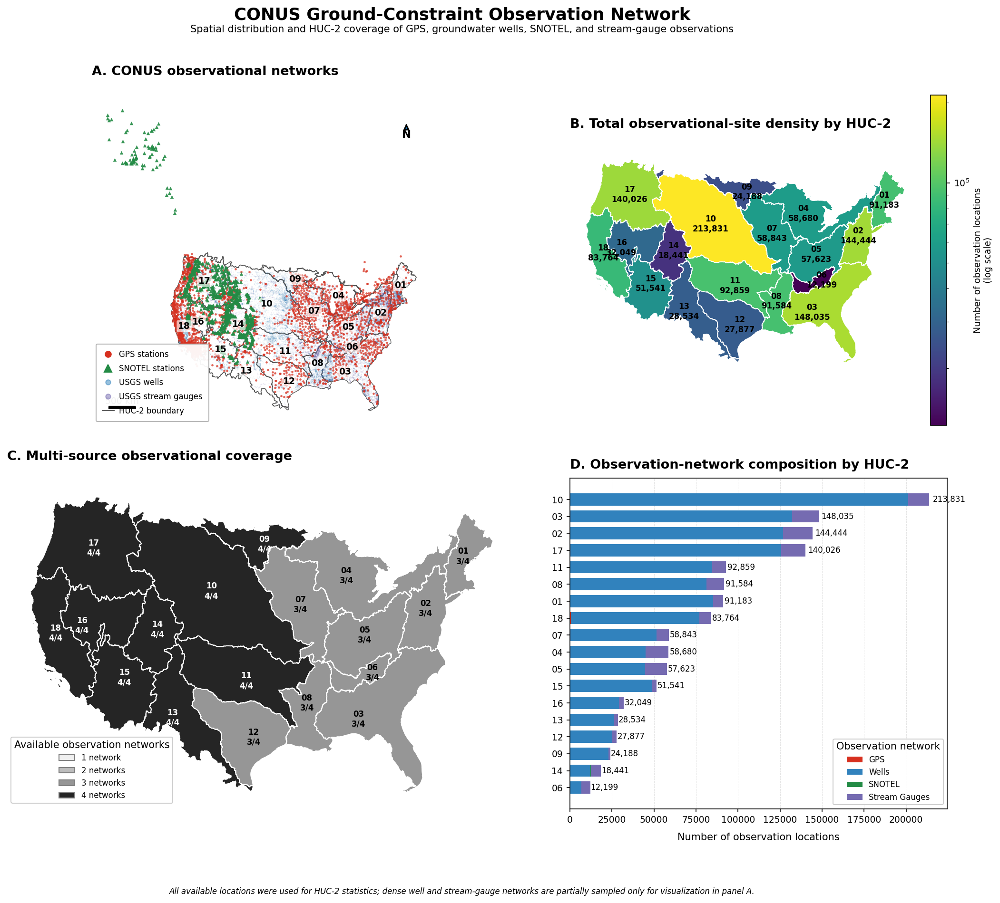


FIGURE SAVED
PNG: /content/drive/MyDrive/ecohydro_project/figures/publication/CONUS_observational_network.png
PDF: /content/drive/MyDrive/ecohydro_project/figures/publication/CONUS_observational_network.pdf


In [ ]:
# ============================================================
# PUBLICATION-QUALITY CONUS OBSERVATIONAL NETWORK FIGURE
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import LogNorm, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

base = "/content/drive/MyDrive/ecohydro_project"

huc2_file = f"{base}/data/raw/wbd_2017/wbd_huc02_raw.geojson"

gps_file = (
    f"{base}/data/raw/gps_metadata/"
    f"peidou_etal_2024/station_catalog_conus.csv"
)

wells_file = (
    f"{base}/data/raw/wells_metadata/"
    f"usgs_wells_conus_metadata.csv"
)

snotel_file = (
    f"{base}/data/raw/snotel_metadata/"
    f"nrcs_snotel_stations_conus.csv"
)

stream_file = (
    f"{base}/data/raw/stream_gauge_metadata/"
    f"usgs_stream_gauges_conus_metadata.csv"
)

output_dir = f"{base}/figures/publication"
os.makedirs(output_dir, exist_ok=True)

# Output filenames
png_out = f"{output_dir}/CONUS_observational_network.png"
pdf_out = f"{output_dir}/CONUS_observational_network.pdf"

# ------------------------------------------------------------
# 2. GLOBAL PLOT SETTINGS
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "axes.linewidth": 0.8,
})

# CONUS Albers Equal Area
plot_crs = "EPSG:5070"

# ------------------------------------------------------------
# 3. LOAD HUC-2 BASINS
# ------------------------------------------------------------

print("Loading HUC-2 basins...")

huc2 = gpd.read_file(huc2_file)

huc2["huc2"] = (
    huc2["huc2"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

# CONUS HUC-2 basins
conus_codes = [f"{i:02d}" for i in range(1, 19)]

huc2 = huc2[
    huc2["huc2"].isin(conus_codes)
].copy()

if huc2.crs is None:
    huc2 = huc2.set_crs("EPSG:4326")

# Keep geographic version for joins
huc2_ll = huc2.to_crs("EPSG:4326")

# Equal-area version for plotting
huc2 = huc2.to_crs(plot_crs)

print(f"HUC-2 basins: {len(huc2)}")

# ------------------------------------------------------------
# 4. FUNCTION TO CREATE POINT GEODATAFRAME
# ------------------------------------------------------------

def make_points(df, lon_col="longitude", lat_col="latitude"):
    """
    Convert a dataframe containing longitude/latitude
    into a GeoDataFrame.
    """

    df = df.copy()

    df[lon_col] = pd.to_numeric(df[lon_col], errors="coerce")
    df[lat_col] = pd.to_numeric(df[lat_col], errors="coerce")

    df = df.dropna(subset=[lon_col, lat_col])

    gdf = gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(
            df[lon_col],
            df[lat_col]
        ),
        crs="EPSG:4326"
    )

    return gdf


# ------------------------------------------------------------
# 5. LOAD GPS
# ------------------------------------------------------------

print("\nLoading GPS stations...")

gps = pd.read_csv(gps_file)

gps = make_points(gps)

print(f"GPS stations: {len(gps):,}")

# ------------------------------------------------------------
# 6. LOAD WELLS
# ------------------------------------------------------------

print("Loading USGS wells...")

wells = pd.read_csv(wells_file)

wells = make_points(wells)

print(f"USGS wells: {len(wells):,}")

# ------------------------------------------------------------
# 7. LOAD SNOTEL
# ------------------------------------------------------------

print("Loading SNOTEL stations...")

snotel = pd.read_csv(snotel_file)

snotel = make_points(snotel)

print(f"SNOTEL stations: {len(snotel):,}")

# ------------------------------------------------------------
# 8. LOAD STREAM GAUGES
# ------------------------------------------------------------

print("Loading USGS stream gauges...")

stream = pd.read_csv(stream_file)

stream = make_points(stream)

print(f"USGS stream gauges: {len(stream):,}")

# ------------------------------------------------------------
# 9. SPATIAL JOIN ALL DATA TO HUC-2
# ------------------------------------------------------------

print("\nAssigning observation locations to HUC-2 basins...")

def assign_huc2(points, huc2_join):
    """
    Spatially assign points to HUC-2.
    """

    joined = gpd.sjoin(
        points,
        huc2_join[["huc2", "name", "geometry"]],
        how="left",
        predicate="within"
    )

    # Avoid duplicated index column issues
    if "index_right" in joined.columns:
        joined = joined.drop(columns="index_right")

    return joined


gps_join = assign_huc2(gps, huc2_ll)
wells_join = assign_huc2(wells, huc2_ll)
snotel_join = assign_huc2(snotel, huc2_ll)
stream_join = assign_huc2(stream, huc2_ll)

# ------------------------------------------------------------
# 10. COUNT OBSERVATIONS BY HUC-2
# ------------------------------------------------------------

gps_counts = (
    gps_join["huc2"]
    .value_counts()
    .rename("GPS")
)

well_counts = (
    wells_join["huc2"]
    .value_counts()
    .rename("Wells")
)

snotel_counts = (
    snotel_join["huc2"]
    .value_counts()
    .rename("SNOTEL")
)

stream_counts = (
    stream_join["huc2"]
    .value_counts()
    .rename("Stream_Gauges")
)

# Combine
counts = pd.concat(
    [
        gps_counts,
        well_counts,
        snotel_counts,
        stream_counts
    ],
    axis=1
).fillna(0)

counts = counts.astype(int)

# Ensure all HUC-2 codes are represented
counts = counts.reindex(conus_codes, fill_value=0)

# ------------------------------------------------------------
# 11. ADD COUNTS TO HUC POLYGONS
# ------------------------------------------------------------

huc2 = huc2.merge(
    counts.reset_index().rename(
        columns={"index": "huc2"}
    ),
    on="huc2",
    how="left"
)

for col in ["GPS", "Wells", "SNOTEL", "Stream_Gauges"]:
    huc2[col] = huc2[col].fillna(0).astype(int)

# Total observational locations
huc2["Total"] = (
    huc2["GPS"]
    + huc2["Wells"]
    + huc2["SNOTEL"]
    + huc2["Stream_Gauges"]
)

# Number of different observational networks represented
huc2["Network_Count"] = (
    (huc2["GPS"] > 0).astype(int)
    + (huc2["Wells"] > 0).astype(int)
    + (huc2["SNOTEL"] > 0).astype(int)
    + (huc2["Stream_Gauges"] > 0).astype(int)
)

# ------------------------------------------------------------
# 12. PRINT SUMMARY TABLE
# ------------------------------------------------------------

summary = huc2[
    [
        "huc2",
        "name",
        "GPS",
        "Wells",
        "SNOTEL",
        "Stream_Gauges",
        "Total",
        "Network_Count"
    ]
].sort_values("huc2")

print("\n" + "=" * 90)
print("HUC-2 OBSERVATIONAL NETWORK SUMMARY")
print("=" * 90)

print(summary.to_string(index=False))

print("\n" + "=" * 90)
print("TOTAL OBSERVATION LOCATIONS")
print("=" * 90)

print(f"GPS:             {gps_join['huc2'].notna().sum():,}")
print(f"Wells:           {wells_join['huc2'].notna().sum():,}")
print(f"SNOTEL:          {snotel_join['huc2'].notna().sum():,}")
print(f"Stream gauges:   {stream_join['huc2'].notna().sum():,}")

print("\n" + "=" * 90)
print("NETWORK COVERAGE")
print("=" * 90)

print(
    f"HUC-2 with GPS: "
    f"{(huc2['GPS'] > 0).sum()} / {len(huc2)}"
)

print(
    f"HUC-2 with wells: "
    f"{(huc2['Wells'] > 0).sum()} / {len(huc2)}"
)

print(
    f"HUC-2 with SNOTEL: "
    f"{(huc2['SNOTEL'] > 0).sum()} / {len(huc2)}"
)

print(
    f"HUC-2 with stream gauges: "
    f"{(huc2['Stream_Gauges'] > 0).sum()} / {len(huc2)}"
)

# ------------------------------------------------------------
# 13. PROJECT POINTS FOR PLOTTING
# ------------------------------------------------------------

gps_plot = gps.to_crs(plot_crs)
wells_plot = wells.to_crs(plot_crs)
snotel_plot = snotel.to_crs(plot_crs)
stream_plot = stream.to_crs(plot_crs)

# ------------------------------------------------------------
# 14. CONTROLLED SAMPLING FOR DENSE NETWORKS
# ------------------------------------------------------------

# Wells and stream gauges can contain tens of thousands
# of points. We use a reproducible sample for the visual map,
# while ALL stations are used for HUC statistics.

WELL_PLOT_N = min(30000, len(wells_plot))
STREAM_PLOT_N = min(20000, len(stream_plot))

wells_sample = wells_plot.sample(
    n=WELL_PLOT_N,
    random_state=42
)

stream_sample = stream_plot.sample(
    n=STREAM_PLOT_N,
    random_state=42
)

# ------------------------------------------------------------
# 15. CREATE FIGURE
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(17, 13),
    constrained_layout=False
)

gs = fig.add_gridspec(
    2,
    2,
    width_ratios=[1.35, 1],
    height_ratios=[1, 1],
    wspace=0.12,
    hspace=0.16
)

axA = fig.add_subplot(gs[0, 0])
axB = fig.add_subplot(gs[0, 1])
axC = fig.add_subplot(gs[1, 0])
axD = fig.add_subplot(gs[1, 1])

# ============================================================
# PANEL A — OBSERVATIONAL NETWORK
# ============================================================

# HUC polygons
huc2.plot(
    ax=axA,
    facecolor="none",
    edgecolor="0.35",
    linewidth=0.7,
    zorder=1
)

# Wells
wells_sample.plot(
    ax=axA,
    color="#3182bd",
    markersize=0.7,
    alpha=0.10,
    linewidth=0,
    rasterized=True,
    zorder=2
)

# Stream gauges
stream_sample.plot(
    ax=axA,
    color="#756bb1",
    markersize=0.9,
    alpha=0.12,
    linewidth=0,
    rasterized=True,
    zorder=3
)

# GPS
gps_plot.plot(
    ax=axA,
    color="#d7301f",
    markersize=5,
    alpha=0.75,
    marker="o",
    linewidth=0,
    zorder=5
)

# SNOTEL
snotel_plot.plot(
    ax=axA,
    color="#238b45",
    markersize=13,
    alpha=0.90,
    marker="^",
    linewidth=0,
    zorder=6
)

# HUC-2 labels
for _, row in huc2.iterrows():

    point = row.geometry.representative_point()

    axA.text(
        point.x,
        point.y,
        row["huc2"],
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        zorder=10,
        bbox=dict(
            boxstyle="round,pad=0.15",
            facecolor="white",
            edgecolor="none",
            alpha=0.65
        )
    )

axA.set_title(
    "A. CONUS observational networks",
    loc="left",
    fontweight="bold",
    pad=10
)

axA.set_axis_off()

# ------------------------------------------------------------
# SCALE BAR
# ------------------------------------------------------------

# Approximate scale bar in EPSG:5070 metres
xmin, xmax = axA.get_xlim()
ymin, ymax = axA.get_ylim()

bar_length = 500_000  # 500 km

bar_x = xmin + 0.05 * (xmax - xmin)
bar_y = ymin + 0.055 * (ymax - ymin)

axA.plot(
    [bar_x, bar_x + bar_length],
    [bar_y, bar_y],
    color="black",
    linewidth=3,
    solid_capstyle="butt",
    zorder=20
)

axA.plot(
    [bar_x, bar_x],
    [bar_y - 12000, bar_y + 12000],
    color="black",
    linewidth=1.5,
    zorder=20
)

axA.plot(
    [bar_x + bar_length, bar_x + bar_length],
    [bar_y - 12000, bar_y + 12000],
    color="black",
    linewidth=1.5,
    zorder=20
)

axA.text(
    bar_x + bar_length / 2,
    bar_y + 25000,
    "500 km",
    ha="center",
    va="bottom",
    fontsize=9
)

# ------------------------------------------------------------
# NORTH ARROW
# ------------------------------------------------------------

nx = xmax - 0.075 * (xmax - xmin)
ny = ymax - 0.12 * (ymax - ymin)

axA.annotate(
    "N",
    xy=(nx, ny + 250000),
    xytext=(nx, ny),
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=1.5
    )
)

# ------------------------------------------------------------
# PANEL A LEGEND
# ------------------------------------------------------------

# ------------------------------------------------------------
# PANEL A LEGEND — CLEAN VERSION
# ------------------------------------------------------------

legend_elements = [

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="#d7301f",
        markeredgecolor="#d7301f",
        markersize=6,
        label="GPS stations"
    ),

    Line2D(
        [0], [0],
        marker="^",
        linestyle="None",
        markerfacecolor="#238b45",
        markeredgecolor="#238b45",
        markersize=8,
        label="SNOTEL stations"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="#3182bd",
        markeredgecolor="#3182bd",
        alpha=0.5,
        markersize=5,
        label="USGS wells"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="#756bb1",
        markeredgecolor="#756bb1",
        alpha=0.5,
        markersize=5,
        label="USGS stream gauges"
    ),

    Line2D(
        [0], [0],
        linestyle="-",
        color="0.35",
        linewidth=1,
        label="HUC-2 boundary"
    )
]

axA.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    framealpha=0.95,
    edgecolor="0.7",
    handlelength=1.5,
    handletextpad=0.6,
    borderpad=0.8,
    labelspacing=0.7
)

# ============================================================
# PANEL B — TOTAL OBSERVATIONAL DENSITY
# ============================================================

# Avoid log(0)
total_for_plot = huc2["Total"].replace(0, np.nan)

huc2.plot(
    ax=axB,
    column="Total",
    cmap="viridis",
    norm=LogNorm(
        vmin=max(1, total_for_plot.min()),
        vmax=total_for_plot.max()
    ),
    edgecolor="white",
    linewidth=0.8,
    legend=False
)

# HUC labels
for _, row in huc2.iterrows():

    point = row.geometry.representative_point()

    axB.text(
        point.x,
        point.y,
        f"{row['huc2']}\n{row['Total']:,}",
        fontsize=8,
        ha="center",
        va="center",
        fontweight="bold"
    )

axB.set_title(
    "B. Total observational-site density by HUC-2",
    loc="left",
    fontweight="bold",
    pad=10
)

axB.set_axis_off()

# Colorbar
sm = ScalarMappable(
    norm=LogNorm(
        vmin=max(1, total_for_plot.min()),
        vmax=total_for_plot.max()
    ),
    cmap="viridis"
)

sm._A = []

cbar = fig.colorbar(
    sm,
    ax=axB,
    fraction=0.045,
    pad=0.025
)

cbar.set_label(
    "Number of observation locations\n(log scale)",
    fontsize=9
)

# ============================================================
# PANEL C — NUMBER OF INDEPENDENT DATA NETWORKS
# ============================================================

network_colors = {
    1: "#f0f0f0",
    2: "#bdbdbd",
    3: "#969696",
    4: "#252525"
}

for network_number, color in network_colors.items():

    subset = huc2[
        huc2["Network_Count"] == network_number
    ]

    if len(subset) > 0:

        subset.plot(
            ax=axC,
            color=color,
            edgecolor="white",
            linewidth=0.9
        )

# HUC labels
for _, row in huc2.iterrows():

    point = row.geometry.representative_point()

    axC.text(
        point.x,
        point.y,
        f"{row['huc2']}\n{row['Network_Count']}/4",
        fontsize=8,
        ha="center",
        va="center",
        fontweight="bold",
        color="black" if row["Network_Count"] < 4 else "white"
    )

axC.set_title(
    "C. Multi-source observational coverage",
    loc="left",
    fontweight="bold",
    pad=10
)

axC.set_axis_off()

network_legend = [
    Patch(
        facecolor=network_colors[1],
        edgecolor="0.5",
        label="1 network"
    ),
    Patch(
        facecolor=network_colors[2],
        edgecolor="0.5",
        label="2 networks"
    ),
    Patch(
        facecolor=network_colors[3],
        edgecolor="0.5",
        label="3 networks"
    ),
    Patch(
        facecolor=network_colors[4],
        edgecolor="0.5",
        label="4 networks"
    )
]

axC.legend(
    handles=network_legend,
    title="Available observation networks",
    loc="lower left",
    frameon=True,
    framealpha=0.95
)

# ============================================================
# PANEL D — NETWORK COMPOSITION
# ============================================================

bar_df = huc2[
    [
        "huc2",
        "GPS",
        "Wells",
        "SNOTEL",
        "Stream_Gauges",
        "Total"
    ]
].copy()

# Sort HUC-2 basins by total number of observations
bar_df = bar_df.sort_values(
    "Total",
    ascending=True
).reset_index(drop=True)

y = np.arange(len(bar_df))

left = np.zeros(len(bar_df))

network_order = [
    ("GPS", "#d7301f"),
    ("Wells", "#3182bd"),
    ("SNOTEL", "#238b45"),
    ("Stream_Gauges", "#756bb1")
]

for variable, color in network_order:

    values = bar_df[variable].values

    axD.barh(
        y,
        values,
        left=left,
        height=0.72,
        color=color,
        edgecolor="none",
        label=variable.replace("_", " ")
    )

    left += values

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

axD.set_yticks(y)

axD.set_yticklabels(
    bar_df["huc2"],
    fontsize=9
)

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

axD.set_xlabel(
    "Number of observation locations",
    labelpad=8
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

axD.set_title(
    "D. Observation-network composition by HUC-2",
    loc="left",
    fontweight="bold",
    pad=10
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

axD.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)

axD.set_axisbelow(True)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

axD.legend(
    loc="lower right",
    frameon=True,
    framealpha=0.95,
    title="Observation network"
)

# ------------------------------------------------------------
# Make x-axis start at zero
# ------------------------------------------------------------

axD.set_xlim(left=0)

# ------------------------------------------------------------
# Add total count at end of each bar
# ------------------------------------------------------------

for i, total in enumerate(bar_df["Total"]):

    axD.text(
        total * 1.01,
        i,
        f"{total:,}",
        va="center",
        fontsize=8
    )

# ------------------------------------------------------------
# 16. FIGURE-LEVEL TITLE
# ------------------------------------------------------------

fig.suptitle(
    "CONUS Ground-Constraint Observation Network",
    fontsize=17,
    fontweight="bold",
    y=0.975
)

fig.text(
    0.5,
    0.948,
    "Spatial distribution and HUC-2 coverage of GPS, groundwater wells, SNOTEL, and stream-gauge observations",
    ha="center",
    fontsize=10
)

# ------------------------------------------------------------
# 17. FOOTNOTE
# ------------------------------------------------------------

fig.text(
    0.5,
    0.018,
    "All available locations were used for HUC-2 statistics; dense well and stream-gauge networks are "
    "partially sampled only for visualization in panel A.",
    ha="center",
    fontsize=8,
    style="italic"
)

# ------------------------------------------------------------
# 18. SAVE HIGH-QUALITY OUTPUT
# ------------------------------------------------------------

plt.savefig(
    png_out,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    pdf_out,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\n" + "=" * 90)
print("FIGURE SAVED")
print("=" * 90)
print(f"PNG: {png_out}")
print(f"PDF: {pdf_out}")

In [ ]:
# Inspect all Hydrogeology raw data folders on Drive
import os

base = "/content/drive/MyDrive/ecohydro_project"
hydro_dir = f"{base}/data/raw/Hydrogeology"

print("=" * 70)
print(f"WALKING: {hydro_dir}")
print("=" * 70)

if not os.path.exists(hydro_dir):
    print("Directory does not exist. Check the exact path/casing on Drive.")
else:
    for root, dirs, files in os.walk(hydro_dir):
        level = root.replace(hydro_dir, "").count(os.sep)
        indent = "  " * level
        print(f"{indent}{os.path.basename(root) or root}/")
        subindent = "  " * (level + 1)
        for f in sorted(files):
            fpath = os.path.join(root, f)
            size_mb = os.path.getsize(fpath) / (1024 * 1024)
            print(f"{subindent}{f}  ({size_mb:.2f} MB)")

print("\n" + "=" * 70)
print("SUMMARY BY EXTENSION")
print("=" * 70)

ext_counts = {}
for root, dirs, files in os.walk(hydro_dir):
    for f in files:
        ext = os.path.splitext(f)[1].lower()
        ext_counts[ext] = ext_counts.get(ext, 0) + 1

for ext, count in sorted(ext_counts.items(), key=lambda x: -x[1]):
    print(f"{ext or '(no extension)'}: {count} files")

WALKING: /content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology
Hydrogeology/
  Principal Aquifers of the 48 Conterminous United States, Hawaii, Puerto Rico, and the U.S. Virgin Islands/
    USAaquiferMAP11_17.pdf  (1.61 MB)
    aquifers_map.jpg  (0.14 MB)
    aquifers_us.xml  (0.06 MB)
    aquifers_us.zip  (7.43 MB)
    aquifrp025.tar.gz  (7.43 MB)
    g_aquifr.tar.gz  (8.00 MB)
    usaq.tar.gz  (2.83 MB)
    aquifers_us/
      us_aquifers.dbf  (0.73 MB)
      us_aquifers.prj  (0.00 MB)
      us_aquifers.sbn  (0.05 MB)
      us_aquifers.sbx  (0.00 MB)
      us_aquifers.shp  (9.70 MB)
      us_aquifers.shp.xml  (0.01 MB)
      us_aquifers.shx  (0.04 MB)
  Cooperative National Geologic Map Earth’s surface geology/
    118545_metadata.zip  (0.15 MB)
    USGS_DR-1210_5-prnt.pdf  (15.35 MB)
    USGS_DR-1210_GeMS.4894.zip  (3330.64 MB)
  Alluvial and Glacial Aquifers/
    USAaquiferMAP11_17.pdf  (1.61 MB)
    alluvial_and_glacial_aquifers.xml  (0.04 MB)
    alluvial_glacial_aq_shp.zi

In [ ]:
# Step A: Inspect karst documentation and attribute tables (read-only)
import geopandas as gpd
import os

base = "/content/drive/MyDrive/ecohydro_project"
hydro_dir = f"{base}/data/raw/Hydrogeology"

karst_dir = f"{hydro_dir}/USKarstMap/Shapefiles/Continguous48"
karst_readme_files = [
    f"{hydro_dir}/USKarstMap/README.doc",
    f"{hydro_dir}/USKarstMap/Shapefiles/READMEshapefiles.doc",
]

print("=" * 70)
print("ATTEMPTING TO READ KARST README FILES AS TEXT")
print("=" * 70)

for path in karst_readme_files:
    print(f"\n--- {path} ---")
    if not os.path.exists(path):
        print("File not found.")
        continue
    try:
        with open(path, "r", errors="replace") as f:
            content = f.read()
        # .doc files often contain binary; only show if it looks like text
        printable_ratio = sum(c.isprintable() or c in "\n\r\t" for c in content[:2000]) / max(len(content[:2000]), 1)
        if printable_ratio > 0.85:
            print(content[:3000])
        else:
            print(f"File appears to be binary Word format (printable ratio {printable_ratio:.2f}). Will need separate handling.")
    except Exception as e:
        print(f"Error reading file: {e}")

print("\n" + "=" * 70)
print("KARST SHAPEFILES: FIELD NAMES AND SAMPLE VALUES")
print("=" * 70)

karst_shapefiles = [
    "Carbonates48.shp",
    "EvapBasins.shp",
    "Evaporites48.shp",
    "GypsumExtent.shp",
    "Piping48.shp",
    "SandstoneKarst48.shp",
    "Volcanics48.shp",
    "glacial_ice_max.shp",
]

for shp_name in karst_shapefiles:
    shp_path = f"{karst_dir}/{shp_name}"
    print(f"\n--- {shp_name} ---")
    if not os.path.exists(shp_path):
        print("File not found.")
        continue
    try:
        gdf = gpd.read_file(shp_path, rows=5)  # read only first 5 rows for speed
        full_gdf_len = None
        try:
            import fiona
            with fiona.open(shp_path) as src:
                full_gdf_len = len(src)
        except Exception:
            pass
        print(f"Feature count: {full_gdf_len if full_gdf_len is not None else 'unknown (fiona unavailable)'}")
        print(f"CRS: {gdf.crs}")
        print(f"Columns: {list(gdf.columns)}")
        print("Sample rows (excluding geometry):")
        print(gdf.drop(columns="geometry").head())
    except Exception as e:
        print(f"Error reading shapefile: {e}")

print("\n" + "=" * 70)
print("PRINCIPAL AQUIFERS SHAPEFILE: FIELD NAMES AND SAMPLE VALUES")
print("=" * 70)

pa_path = f"{hydro_dir}/Principal Aquifers of the 48 Conterminous United States, Hawaii, Puerto Rico, and the U.S. Virgin Islands/aquifers_us/us_aquifers.shp"

if not os.path.exists(pa_path):
    print(f"File not found: {pa_path}")
else:
    try:
        gdf = gpd.read_file(pa_path, rows=10)
        try:
            import fiona
            with fiona.open(pa_path) as src:
                full_len = len(src)
        except Exception:
            full_len = None
        print(f"Feature count: {full_len if full_len is not None else 'unknown'}")
        print(f"CRS: {gdf.crs}")
        print(f"Columns: {list(gdf.columns)}")
        print("Sample rows (excluding geometry):")
        print(gdf.drop(columns="geometry").head(10))

        # If there's an obvious rock-type/category field, show its unique values
        candidate_cat_cols = [c for c in gdf.columns if c.lower() in
                               ("aq_type", "rock_type", "aquifer", "aq_name", "rocktype", "category", "class", "aq_code")]
        print(f"\nCandidate category columns found: {candidate_cat_cols}")
    except Exception as e:
        print(f"Error reading shapefile: {e}")

ATTEMPTING TO READ KARST README FILES AS TEXT

--- /content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/USKarstMap/README.doc ---
File appears to be binary Word format (printable ratio 0.33). Will need separate handling.

--- /content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/USKarstMap/Shapefiles/READMEshapefiles.doc ---
File appears to be binary Word format (printable ratio 0.33). Will need separate handling.

KARST SHAPEFILES: FIELD NAMES AND SAMPLE VALUES

--- Carbonates48.shp ---
Feature count: unknown (fiona unavailable)
CRS: PROJCS["NAD_1983_Albers",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",25],PARAMETER["standard_parallel_2",50],PARAMETER["false_easting",0],PARAME

In [ ]:
# Full unique category lists (read-only, no merging)
import geopandas as gpd
import pandas as pd
import os

base = "/content/drive/MyDrive/ecohydro_project"
hydro_dir = f"{base}/data/raw/Hydrogeology"

karst_dir = f"{hydro_dir}/USKarstMap/Shapefiles/Continguous48"
pa_dir = f"{hydro_dir}/Principal Aquifers of the 48 Conterminous United States, Hawaii, Puerto Rico, and the U.S. Virgin Islands/aquifers_us"

print("=" * 70)
print("KARST SHAPEFILES: FULL UNIQUE KARST_TYPE VALUES")
print("=" * 70)

karst_shapefiles = [
    "Carbonates48.shp",
    "Evaporites48.shp",
    "SandstoneKarst48.shp",
    "Piping48.shp",
    "Volcanics48.shp",
    # Skip GypsumExtent (single polygon, no KARST_TYPE field) and glacial_ice_max (not karst)
]

for shp_name in karst_shapefiles:
    shp_path = f"{karst_dir}/{shp_name}"
    if not os.path.exists(shp_path):
        print(f"\n{shp_name}: File not found")
        continue
    try:
        gdf = gpd.read_file(shp_path)
        if "KARST_TYPE" not in gdf.columns:
            print(f"\n{shp_name}: No KARST_TYPE column found. Columns: {list(gdf.columns)}")
            continue
        unique_vals = gdf["KARST_TYPE"].dropna().unique()
        print(f"\n{shp_name}: {len(unique_vals)} unique KARST_TYPE values")
        for i, val in enumerate(unique_vals[:10]):  # show first 10
            print(f"  {i+1}. {val}")
        if len(unique_vals) > 10:
            print(f"  ... and {len(unique_vals) - 10} more")
    except Exception as e:
        print(f"\n{shp_name}: Error reading: {e}")

print("\n" + "=" * 70)
print("PRINCIPAL AQUIFERS: FULL UNIQUE (ROCK_TYPE, AQ_NAME) PAIRS")
print("=" * 70)

pa_path = f"{pa_dir}/us_aquifers.shp"
if not os.path.exists(pa_path):
    print(f"File not found: {pa_path}")
else:
    try:
        gdf = gpd.read_file(pa_path)
        # Get unique pairs
        pairs = gdf[["ROCK_TYPE", "AQ_NAME"]].drop_duplicates().sort_values(["ROCK_TYPE", "AQ_NAME"])
        print(f"Total unique (ROCK_TYPE, AQ_NAME) pairs: {len(pairs)}")
        print("\nFull list:")
        for _, row in pairs.iterrows():
            print(f"  ROCK_TYPE={row['ROCK_TYPE']:4.0f}  |  AQ_NAME={row['AQ_NAME']}")
    except Exception as e:
        print(f"Error reading shapefile: {e}")

KARST SHAPEFILES: FULL UNIQUE KARST_TYPE VALUES

Carbonates48.shp: 10 unique KARST_TYPE values
  1. Carbonate rocks buried under >50 ft of glacially derived insoluble sediments in a dry climate
  2. Carbonate rocks buried under =50 ft of glacially derived insoluble sediments in a dry climate
  3. Carbonate rocks at or near the land surface in a dry climate
  4. Unconsolidated calcareous or carbonate rocks at or near the land surface in a dry climate
  5. Carbonate rocks buried under <300 ft of insoluble sediments in a humid climate
  6. Carbonate rocks buried under >50 ft of glacially derived insoluble sediments in a humid climate
  7. Carbonate rocks buried under =50 ft of glacially derived insoluble sediments in a humid climate
  8. Carbonate rocks at or near the land surface in a humid climate
  9. Unconsolidated calcareous or carbonate rocks buried under <300 ft of insoluble sediments in a humid climate
  10. Unconsolidated calcareous or carbonate rocks at or near the land surface 

STAGE 2.3 PLOT CREATION
Input table: /content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_ground_constraint_counts.csv
Figures will be saved to: /content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3

Loaded HUC-2 regions: 18
Stage 2.2 passing regions used in plots: 17


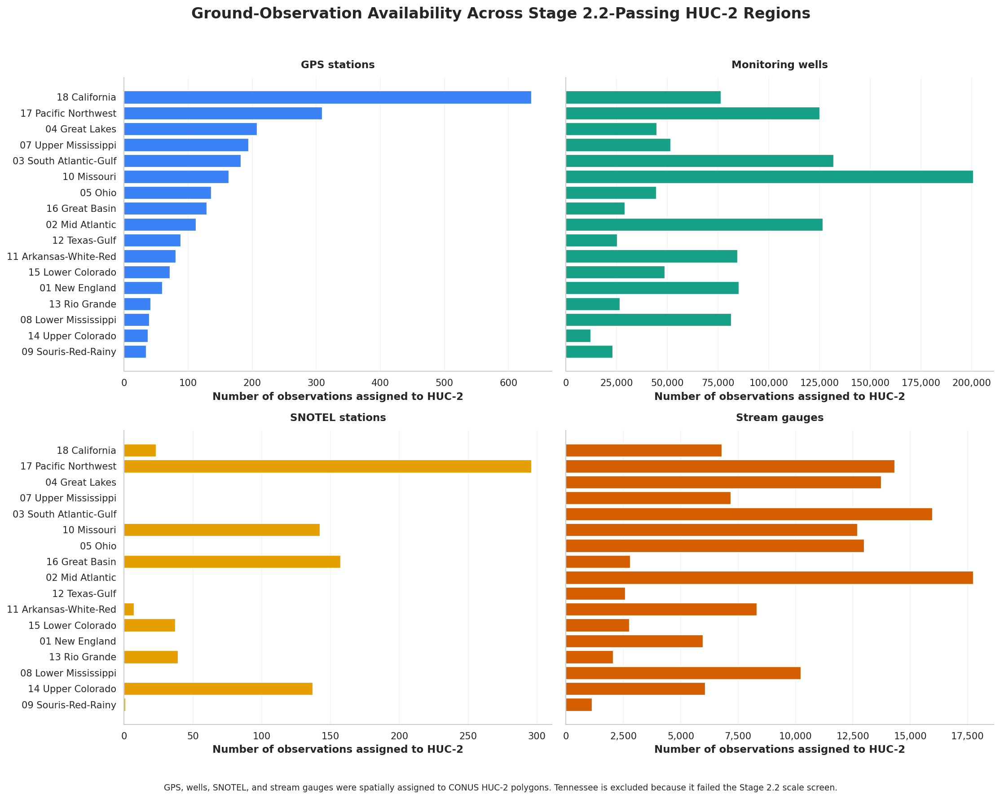


Saved:
PNG: /content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig1_huc2_observation_counts.png
PDF: /content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig1_huc2_observation_counts.pdf


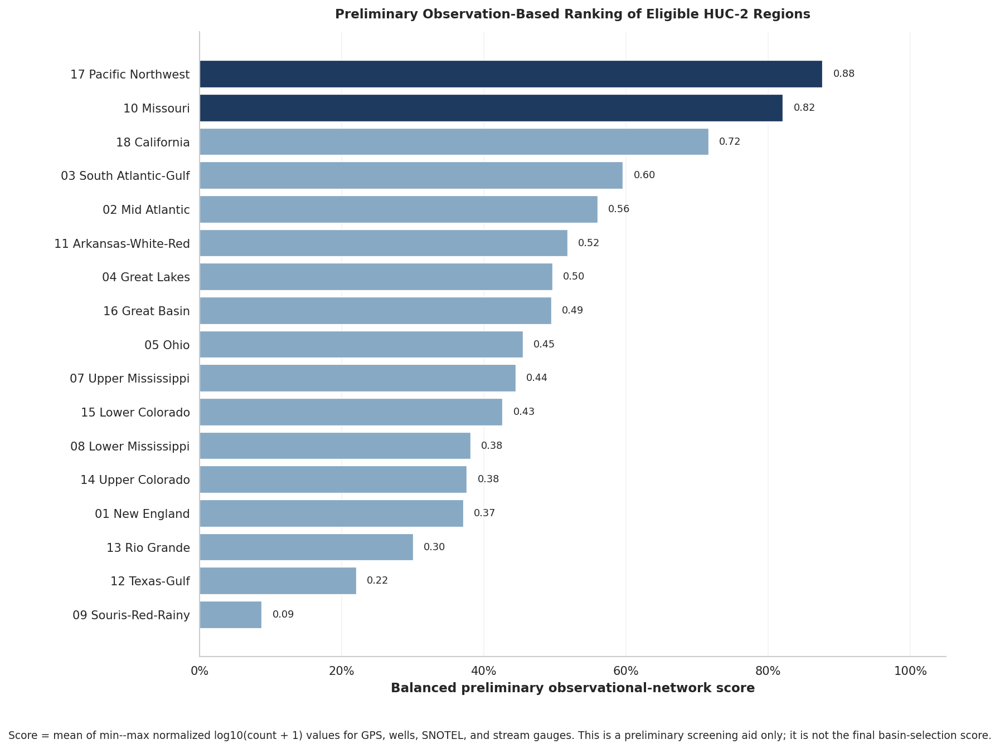


Saved:
PNG: /content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig2_huc2_preliminary_network_score.png
PDF: /content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig2_huc2_preliminary_network_score.pdf

Ranking CSV saved to:
/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_preliminary_observational_ranking.csv


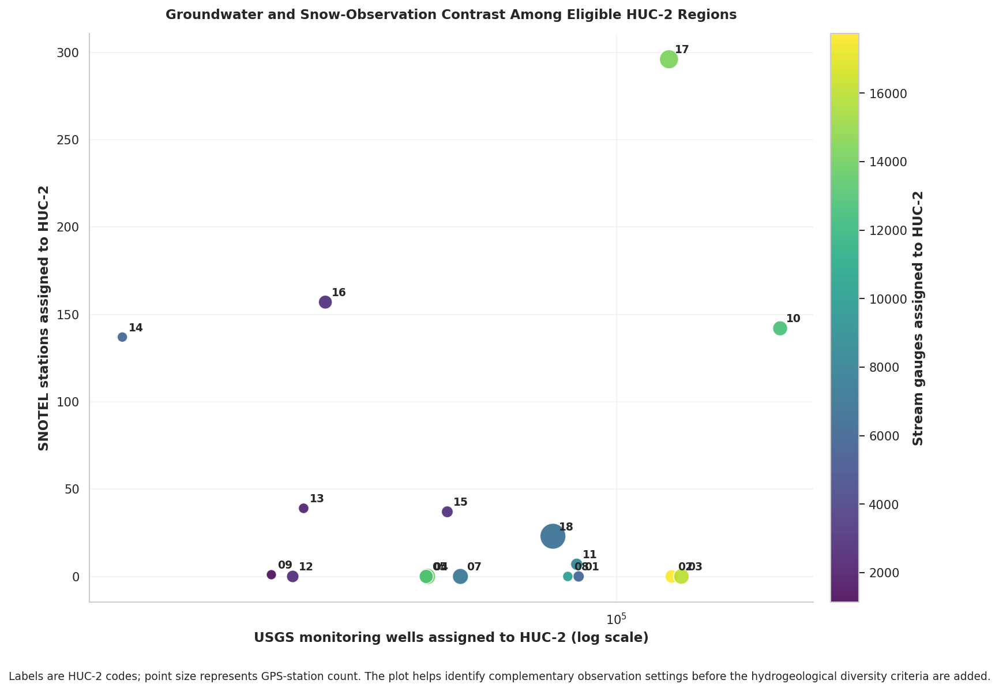


Saved:
PNG: /content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig3_huc2_wells_snotel_contrast.png
PDF: /content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig3_huc2_wells_snotel_contrast.pdf

ALL FIGURES SAVED SUCCESSFULLY
/content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig1_huc2_observation_counts.png  (0.72 MB)
/content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig1_huc2_observation_counts.pdf  (0.03 MB)
/content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig2_huc2_preliminary_network_score.png  (0.43 MB)
/content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig2_huc2_preliminary_network_score.pdf  (0.03 MB)
/content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig3_huc2_wells_snotel_contrast.png  (0.38 MB)
/content/drive/MyDrive/ecohydro_project/outputs/figures/stage_02_3/fig3_huc2_wells_snotel_contrast.pdf  (0.03 MB)

Open Google Drive and navigate to:
MyDrive > ecohydro_pro

In [ ]:
# ============================================================
# Stage 2.3: HUC-2 ground-constraint plots
# Saves permanently to Google Drive and displays all figures
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Image

# ------------------------------------------------------------
# 1. Project paths: follows your existing folder structure
# ------------------------------------------------------------
base = "/content/drive/MyDrive/ecohydro_project"

input_file = os.path.join(
    base,
    "data",
    "processed",
    "basin_selection",
    "huc2_ground_constraint_counts.csv"
)

fig_dir = os.path.join(
    base,
    "outputs",
    "figures",
    "stage_02_3"
)

os.makedirs(fig_dir, exist_ok=True)

print("=" * 70)
print("STAGE 2.3 PLOT CREATION")
print("=" * 70)
print("Input table:", input_file)
print("Figures will be saved to:", fig_dir)

if not os.path.exists(input_file):
    raise FileNotFoundError(
        f"\nCould not find:\n{input_file}\n\n"
        "Please check that the HUC-2 ground-constraint CSV was saved "
        "in data/processed/basin_selection/."
    )

# ------------------------------------------------------------
# 2. Load and prepare data
# ------------------------------------------------------------
df = pd.read_csv(input_file, dtype={"huc2": str})
df["huc2"] = df["huc2"].astype(str).str.zfill(2)

required_cols = [
    "huc2", "name", "screen_result",
    "gps_count", "well_count",
    "snotel_count", "stream_gauge_count"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# Use only Stage 2.2 passing regions for selection figures.
plot_df = df[df["screen_result"].eq("PASS")].copy()

# Short labels for publication-quality plots.
short_names = {
    "01": "01 New England",
    "02": "02 Mid Atlantic",
    "03": "03 South Atlantic-Gulf",
    "04": "04 Great Lakes",
    "05": "05 Ohio",
    "06": "06 Tennessee",
    "07": "07 Upper Mississippi",
    "08": "08 Lower Mississippi",
    "09": "09 Souris-Red-Rainy",
    "10": "10 Missouri",
    "11": "11 Arkansas-White-Red",
    "12": "12 Texas-Gulf",
    "13": "13 Rio Grande",
    "14": "14 Upper Colorado",
    "15": "15 Lower Colorado",
    "16": "16 Great Basin",
    "17": "17 Pacific Northwest",
    "18": "18 California",
}

plot_df["label"] = plot_df["huc2"].map(short_names).fillna(
    plot_df["huc2"] + " " + plot_df["name"]
)

print("\nLoaded HUC-2 regions:", len(df))
print("Stage 2.2 passing regions used in plots:", len(plot_df))

# ------------------------------------------------------------
# 3. Plot style
# ------------------------------------------------------------
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 400,
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

colors = {
    "GPS stations": "#3B82F6",
    "Monitoring wells": "#16A085",
    "SNOTEL stations": "#E69F00",
    "Stream gauges": "#D55E00",
}

saved_files = []

def save_show(fig, filename):
    """Save each figure as PNG and PDF in the permanent Drive folder."""
    png_path = os.path.join(fig_dir, filename + ".png")
    pdf_path = os.path.join(fig_dir, filename + ".pdf")

    fig.savefig(png_path, bbox_inches="tight", dpi=400)
    fig.savefig(pdf_path, bbox_inches="tight")

    saved_files.extend([png_path, pdf_path])

    plt.show()
    plt.close(fig)

    print("\nSaved:")
    print("PNG:", png_path)
    print("PDF:", pdf_path)

# ============================================================
# FIGURE 1: Four separate observation-count panels
# ============================================================
metrics = [
    ("gps_count", "GPS stations"),
    ("well_count", "Monitoring wells"),
    ("snotel_count", "SNOTEL stations"),
    ("stream_gauge_count", "Stream gauges"),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 12), sharey=True)

for ax, (column, title) in zip(axes.flat, metrics):
    temp = plot_df.sort_values(column, ascending=True)

    ax.barh(
        temp["label"],
        temp[column],
        color=colors[title],
        edgecolor="white",
        linewidth=0.6
    )

    ax.set_title(title, pad=10)
    ax.set_xlabel("Number of observations assigned to HUC-2")
    ax.xaxis.set_major_formatter(
        mtick.StrMethodFormatter("{x:,.0f}")
    )

    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, left=False, bottom=False)

fig.suptitle(
    "Ground-Observation Availability Across Stage 2.2-Passing HUC-2 Regions",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.01,
    "GPS, wells, SNOTEL, and stream gauges were spatially assigned to CONUS HUC-2 polygons. "
    "Tennessee is excluded because it failed the Stage 2.2 scale screen.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.04, 1, 0.96])

save_show(fig, "fig1_huc2_observation_counts")

# ============================================================
# FIGURE 2: Balanced preliminary observational-network score
# ============================================================
score_df = plot_df.copy()

for column, _ in metrics:
    log_col = "log_" + column
    norm_col = "norm_" + column

    score_df[log_col] = np.log10(score_df[column] + 1)

    col_min = score_df[log_col].min()
    col_max = score_df[log_col].max()

    if col_max == col_min:
        score_df[norm_col] = 1.0
    else:
        score_df[norm_col] = (
            (score_df[log_col] - col_min) /
            (col_max - col_min)
        )

normalized_columns = ["norm_" + column for column, _ in metrics]

score_df["preliminary_network_score"] = (
    score_df[normalized_columns].mean(axis=1)
)

score_df = score_df.sort_values(
    "preliminary_network_score",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 9))

bar_colors = np.where(
    score_df["huc2"].isin(["10", "17"]),
    "#1F3A5F",
    "#88A9C3"
)

bars = ax.barh(
    score_df["label"],
    score_df["preliminary_network_score"],
    color=bar_colors,
    edgecolor="white",
    linewidth=0.6
)

ax.set_xlim(0, 1.05)
ax.set_xlabel("Balanced preliminary observational-network score")
ax.set_title(
    "Preliminary Observation-Based Ranking of Eligible HUC-2 Regions",
    pad=12
)

ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

for bar, score in zip(bars, score_df["preliminary_network_score"]):
    ax.text(
        score + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.2f}",
        va="center",
        fontsize=8.5
    )

sns.despine(ax=ax, left=False, bottom=False)

fig.text(
    0.5,
    0.01,
    "Score = mean of min--max normalized log10(count + 1) values for GPS, wells, "
    "SNOTEL, and stream gauges. This is a preliminary screening aid only; it is not "
    "the final basin-selection score.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

save_show(fig, "fig2_huc2_preliminary_network_score")

# Save score table for later use in basin selection.
score_table_path = os.path.join(
    base,
    "data",
    "processed",
    "basin_selection",
    "huc2_preliminary_observational_ranking.csv"
)

score_df[
    [
        "huc2", "name", "screen_result",
        "gps_count", "well_count",
        "snotel_count", "stream_gauge_count",
        "preliminary_network_score"
    ]
].sort_values(
    "preliminary_network_score",
    ascending=False
).to_csv(score_table_path, index=False)

print("\nRanking CSV saved to:")
print(score_table_path)

# ============================================================
# FIGURE 3: Well/SNOTEL contrast for deliberate basin selection
# ============================================================
fig, ax = plt.subplots(figsize=(11, 8))

scatter = ax.scatter(
    plot_df["well_count"],
    plot_df["snotel_count"],
    s=50 + plot_df["gps_count"] * 0.65,
    c=plot_df["stream_gauge_count"],
    cmap="viridis",
    alpha=0.88,
    edgecolor="white",
    linewidth=0.8
)

for _, row in plot_df.iterrows():
    ax.annotate(
        row["huc2"],
        (row["well_count"], row["snotel_count"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

ax.set_xscale("log")
ax.set_xlabel("USGS monitoring wells assigned to HUC-2 (log scale)")
ax.set_ylabel("SNOTEL stations assigned to HUC-2")

ax.set_title(
    "Groundwater and Snow-Observation Contrast Among Eligible HUC-2 Regions",
    pad=12
)

cbar = fig.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label("Stream gauges assigned to HUC-2")

ax.grid(alpha=0.25)
sns.despine(ax=ax)

fig.text(
    0.5,
    0.01,
    "Labels are HUC-2 codes; point size represents GPS-station count. "
    "The plot helps identify complementary observation settings before the "
    "hydrogeological diversity criteria are added.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

save_show(fig, "fig3_huc2_wells_snotel_contrast")

# ============================================================
# Final file listing
# ============================================================
print("\n" + "=" * 70)
print("ALL FIGURES SAVED SUCCESSFULLY")
print("=" * 70)

for file_path in saved_files:
    size_mb = os.path.getsize(file_path) / (1024 * 1024)
    print(f"{file_path}  ({size_mb:.2f} MB)")

print("\nOpen Google Drive and navigate to:")
print("MyDrive > ecohydro_project > outputs > figures > stage_02_3")

###----------------------------------------------------------------------

In [ ]:
# Karst area fraction per HUC-2 basin — updated to include piping and volcanic pseudokarst
# Mapped karst now = Carbonates48 + Evaporites48 + SandstoneKarst48 + PipingKarst48 + VolcanicPseudokarst48
# GypsumExtent is still kept separate as a coarse "potential zone" layer.

import os
import geopandas as gpd
import pandas as pd

base = "/content/drive/MyDrive/ecohydro_project"
hydro_dir = f"{base}/data/raw/Hydrogeology"
karst_dir = f"{hydro_dir}/USKarstMap/Shapefiles/Continguous48"

albers = "EPSG:5070"

output_dir = f"{base}/data/processed/basin_selection"
os.makedirs(output_dir, exist_ok=True)
output_file = f"{output_dir}/huc2_karst_fraction_with_pseudokarst.csv"

# ------------------------------------------------------------
# Load the 17 basins that passed Stage 2.2
# ------------------------------------------------------------
print("=" * 70)
print("LOADING 17 PASSING HUC-2 BASINS")
print("=" * 70)

scale_file = f"{base}/outputs/stage2_2_basin_screen.csv"
scale = pd.read_csv(scale_file)
scale["huc2"] = scale["huc2"].astype(str).str.zfill(2)

huc2_file = f"{base}/data/raw/wbd_2017/wbd_huc02_raw.geojson"
huc2 = gpd.read_file(huc2_file)
huc2["huc2"] = huc2["huc2"].astype(str).str.zfill(2)

conus_codes = [f"{i:02d}" for i in range(1, 19)]
huc2 = huc2[huc2["huc2"].isin(conus_codes)].copy()

if huc2.crs is None:
    huc2 = huc2.set_crs("EPSG:4326")
huc2 = huc2.to_crs(albers)

passed_codes = scale.loc[scale["screen_result"] == "PASS", "huc2"].tolist()
basins = huc2[huc2["huc2"].isin(passed_codes)].copy()

basins["basin_area_km2"] = basins.geometry.area / 1e6

print(f"Basins passing scale screen: {len(basins)}")
print(basins[["huc2", "name", "basin_area_km2"]].sort_values("huc2").to_string(index=False))

# ------------------------------------------------------------
# Load and combine karst/pseudokarst layers (tagged by source)
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("LOADING KARST AND PSEUDOKARST LAYERS")
print("=" * 70)

karst_shapefiles = [
    "Carbonates48.shp",
    "Evaporites48.shp",
    "SandstoneKarst48.shp",
    "Piping48.shp",          # newly added
    "Volcanics48.shp",  # newly added
    "GypsumExtent.shp",
]

karst_pieces = []

for shp_name in karst_shapefiles:
    shp_path = f"{karst_dir}/{shp_name}"
    gdf = gpd.read_file(shp_path)
    gdf = gdf.to_crs(albers)
    gdf = gdf[["geometry"]].copy()
    gdf["source_layer"] = shp_name
    karst_pieces.append(gdf)
    print(f"{shp_name}: {len(gdf):,} features loaded")

karst_all = pd.concat(karst_pieces, ignore_index=True)
karst_all = gpd.GeoDataFrame(karst_all, geometry="geometry", crs=albers)

print(f"\nTotal karst/pseudokarst features loaded: {len(karst_all):,}")

n_invalid_before = (~karst_all.geometry.is_valid).sum()
print(f"Invalid geometries before fix: {n_invalid_before:,}")

karst_all["geometry"] = karst_all.geometry.buffer(0)

n_invalid_after = (~karst_all.geometry.is_valid).sum()
print(f"Invalid geometries after fix: {n_invalid_after:,}")

# ------------------------------------------------------------
# Build mapped-karst union INCLUDING piping & volcanic pseudokarst
# (everything EXCEPT GypsumExtent)
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("BUILDING MAPPED-KARST LAYER (Carbonates+Evaporites+Sandstone+Piping+Volcanic)")
print("=" * 70)

mapped_karst_layers = karst_all[karst_all["source_layer"] != "GypsumExtent.shp"].copy()
print(f"Mapped-karst source polygons: {len(mapped_karst_layers):,}")

print("Dissolving into one unified mapped-karst layer (this may take a minute)...")
mapped_karst_union = mapped_karst_layers.dissolve()
mapped_karst_union = mapped_karst_union[["geometry"]].copy()

mapped_karst_area_km2 = mapped_karst_union.geometry.area.sum() / 1e6
print(f"Total mapped-karst area (CONUS, incl. piping & volcanic pseudokarst): {mapped_karst_area_km2:,.0f} km2")

# ------------------------------------------------------------
# Isolate GypsumExtent as its own broad-zone layer
# ------------------------------------------------------------
gypsum_only = karst_all[karst_all["source_layer"] == "GypsumExtent.shp"].copy()
gypsum_only = gypsum_only[["geometry"]].copy()
gypsum_area_km2 = gypsum_only.geometry.area.sum() / 1e6
print(f"GypsumExtent broad-zone area (CONUS): {gypsum_area_km2:,.0f} km2")

# ------------------------------------------------------------
# Intersect both layers with the 17 basins
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("INTERSECTING WITH 17 BASINS")
print("=" * 70)

mapped_intersection = gpd.overlay(
    basins[["huc2", "name", "geometry"]], mapped_karst_union, how="intersection"
)
mapped_intersection["mapped_karst_piece_km2"] = mapped_intersection.geometry.area / 1e6

gypsum_intersection = gpd.overlay(
    basins[["huc2", "name", "geometry"]], gypsum_only, how="intersection"
)
gypsum_intersection["gypsum_piece_km2"] = gypsum_intersection.geometry.area / 1e6

mapped_by_basin = (
    mapped_intersection.groupby("huc2")["mapped_karst_piece_km2"].sum().reset_index()
)
gypsum_by_basin = (
    gypsum_intersection.groupby("huc2")["gypsum_piece_km2"].sum().reset_index()
)

result = basins[["huc2", "name", "basin_area_km2"]].merge(
    mapped_by_basin, on="huc2", how="left"
).merge(
    gypsum_by_basin, on="huc2", how="left"
)

result["mapped_karst_piece_km2"] = result["mapped_karst_piece_km2"].fillna(0.0)
result["gypsum_piece_km2"] = result["gypsum_piece_km2"].fillna(0.0)

result["mapped_karst_fraction"] = result["mapped_karst_piece_km2"] / result["basin_area_km2"]
result["gypsum_zone_fraction"] = result["gypsum_piece_km2"] / result["basin_area_km2"]

result = result.sort_values("mapped_karst_fraction", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("MAPPED KARST (incl. pseudokarst) vs. GYPSUM-ZONE FRACTION PER BASIN")
print("=" * 70)
print(
    result[["huc2", "name", "basin_area_km2", "mapped_karst_fraction", "gypsum_zone_fraction"]]
    .to_string(index=False, float_format=lambda x: f"{x:,.4f}")
)

result.to_csv(output_file, index=False)
print(f"\nSaved updated table: {output_file}")

LOADING 17 PASSING HUC-2 BASINS
Basins passing scale screen: 17
huc2                       name  basin_area_km2
  01         New England Region    1.988462e+05
  02        Mid Atlantic Region    2.764838e+05
  03 South Atlantic-Gulf Region    7.396592e+05
  04         Great Lakes Region    6.170527e+05
  05                Ohio Region    4.219575e+05
  07   Upper Mississippi Region    4.920325e+05
  08   Lower Mississippi Region    2.759616e+05
  09    Souris-Red-Rainy Region    2.365952e+05
  10            Missouri Region    1.349375e+06
  11  Arkansas-White-Red Region    6.422843e+05
  12          Texas-Gulf Region    4.745439e+05
  13          Rio Grande Region    4.370647e+05
  14      Upper Colorado Region    2.935688e+05
  15      Lower Colorado Region    4.243490e+05
  16         Great Basin Region    3.670487e+05
  17   Pacific Northwest Region    7.830660e+05
  18          California Region    4.366315e+05

LOADING KARST AND PSEUDOKARST LAYERS
Carbonates48.shp: 77,837 features 

In [ ]:
# Step 1: Principal Aquifers — full ROCK_TYPE breakdown per HUC-2 basin
import os
import geopandas as gpd
import pandas as pd

base = "/content/drive/MyDrive/ecohydro_project"
hydro_dir = f"{base}/data/raw/Hydrogeology"
pa_dir = (
    f"{hydro_dir}/Principal Aquifers of the 48 Conterminous United States, "
    f"Hawaii, Puerto Rico, and the U.S. Virgin Islands/aquifers_us"
)

albers = "EPSG:5070"

output_dir = f"{base}/data/processed/basin_selection"
os.makedirs(output_dir, exist_ok=True)

rocktype_output_file = f"{output_dir}/huc2_principal_aquifers_rocktype_fractions.csv"
aqname_output_file = f"{output_dir}/huc2_principal_aquifers_top_aquifers.csv"

# ------------------------------------------------------------
# Load the 17 basins that passed Stage 2.2
# ------------------------------------------------------------
print("=" * 70)
print("LOADING 17 PASSING HUC-2 BASINS")
print("=" * 70)

scale_file = f"{base}/outputs/stage2_2_basin_screen.csv"
scale = pd.read_csv(scale_file)
scale["huc2"] = scale["huc2"].astype(str).str.zfill(2)

huc2_file = f"{base}/data/raw/wbd_2017/wbd_huc02_raw.geojson"
huc2 = gpd.read_file(huc2_file)
huc2["huc2"] = huc2["huc2"].astype(str).str.zfill(2)

conus_codes = [f"{i:02d}" for i in range(1, 19)]
huc2 = huc2[huc2["huc2"].isin(conus_codes)].copy()

if huc2.crs is None:
    huc2 = huc2.set_crs("EPSG:4326")
huc2 = huc2.to_crs(albers)

passed_codes = scale.loc[scale["screen_result"] == "PASS", "huc2"].tolist()
basins = huc2[huc2["huc2"].isin(passed_codes)].copy()
basins["basin_area_km2"] = basins.geometry.area / 1e6

print(f"Basins passing scale screen: {len(basins)}")

# ------------------------------------------------------------
# Load Principal Aquifers shapefile
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("LOADING PRINCIPAL AQUIFERS SHAPEFILE")
print("=" * 70)

pa_path = f"{pa_dir}/us_aquifers.shp"
aquifers = gpd.read_file(pa_path)

print(f"Features loaded: {len(aquifers):,}")
print(f"Original CRS: {aquifers.crs}")

aquifers = aquifers.to_crs(albers)
print(f"Reprojected to: {albers}")

# ------------------------------------------------------------
# Check and fix geometry validity BEFORE anything else
# ------------------------------------------------------------
n_invalid_before = (~aquifers.geometry.is_valid).sum()
print(f"\nInvalid geometries before fix: {n_invalid_before:,} / {len(aquifers):,}")

if n_invalid_before > 0:
    aquifers["geometry"] = aquifers.geometry.buffer(0)

n_invalid_after = (~aquifers.geometry.is_valid).sum()
print(f"Invalid geometries after fix: {n_invalid_after:,} / {len(aquifers):,}")

# ------------------------------------------------------------
# Sanity check: national area by ROCK_TYPE, before any basin work
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("NATIONAL AREA BY ROCK_TYPE (sanity check)")
print("=" * 70)

aquifers["area_km2"] = aquifers.geometry.area / 1e6

national_by_rocktype = (
    aquifers.groupby("ROCK_TYPE")["area_km2"]
    .sum()
    .reset_index()
    .sort_values("ROCK_TYPE")
)

print(national_by_rocktype.to_string(index=False, float_format=lambda x: f"{x:,.0f}"))

# ------------------------------------------------------------
# Intersect aquifer polygons with each basin
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("INTERSECTING PRINCIPAL AQUIFERS WITH 17 BASINS")
print("=" * 70)

intersection = gpd.overlay(
    basins[["huc2", "name", "geometry"]],
    aquifers[["ROCK_TYPE", "AQ_NAME", "geometry"]],
    how="intersection"
)

intersection["piece_area_km2"] = intersection.geometry.area / 1e6

print(f"Total intersection pieces: {len(intersection):,}")

# ------------------------------------------------------------
# Build the full ROCK_TYPE fraction table (all categories, nothing skipped)
# ------------------------------------------------------------
rocktype_by_basin = (
    intersection.groupby(["huc2", "ROCK_TYPE"])["piece_area_km2"]
    .sum()
    .reset_index()
)

rocktype_pivot = rocktype_by_basin.pivot(
    index="huc2", columns="ROCK_TYPE", values="piece_area_km2"
).fillna(0.0)

rocktype_pivot.columns = [f"rocktype_{int(c)}_km2" for c in rocktype_pivot.columns]
rocktype_pivot = rocktype_pivot.reset_index()

result = basins[["huc2", "name", "basin_area_km2"]].merge(
    rocktype_pivot, on="huc2", how="left"
).fillna(0.0)

area_cols = [c for c in result.columns if c.startswith("rocktype_")]
for col in area_cols:
    frac_col = col.replace("_km2", "_fraction")
    result[frac_col] = result[col] / result["basin_area_km2"]

result = result.sort_values("huc2").reset_index(drop=True)

print("\n" + "=" * 70)
print("FULL ROCK_TYPE FRACTION TABLE PER BASIN")
print("=" * 70)

frac_cols = [c for c in result.columns if c.endswith("_fraction")]
print(
    result[["huc2", "name", "basin_area_km2"] + frac_cols]
    .to_string(index=False, float_format=lambda x: f"{x:,.4f}")
)

result.to_csv(rocktype_output_file, index=False)
print(f"\nSaved: {rocktype_output_file}")

# ------------------------------------------------------------
# Top named aquifers (AQ_NAME) by area, per basin
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("TOP NAMED AQUIFERS BY AREA, PER BASIN")
print("=" * 70)

aqname_by_basin = (
    intersection.groupby(["huc2", "name", "ROCK_TYPE", "AQ_NAME"])["piece_area_km2"]
    .sum()
    .reset_index()
    .sort_values(["huc2", "piece_area_km2"], ascending=[True, False])
)

top_aquifers = aqname_by_basin.groupby("huc2").head(5)

print(
    top_aquifers.to_string(
        index=False, float_format=lambda x: f"{x:,.1f}"
    )
)

top_aquifers.to_csv(aqname_output_file, index=False)
print(f"\nSaved: {aqname_output_file}")

LOADING 17 PASSING HUC-2 BASINS
Basins passing scale screen: 17

LOADING PRINCIPAL AQUIFERS SHAPEFILE
Features loaded: 4,637
Original CRS: EPSG:4269
Reprojected to: EPSG:5070

Invalid geometries before fix: 20 / 4,637
Invalid geometries after fix: 0 / 4,637

NATIONAL AREA BY ROCK_TYPE (sanity check)
 ROCK_TYPE  area_km2
       100 1,458,743
       200   659,457
       300 1,167,449
       400   429,394
       500   384,798
       600   525,319
       999 3,191,527

INTERSECTING PRINCIPAL AQUIFERS WITH 17 BASINS
Total intersection pieces: 4,386

FULL ROCK_TYPE FRACTION TABLE PER BASIN
huc2                       name  basin_area_km2  rocktype_100_fraction  rocktype_200_fraction  rocktype_300_fraction  rocktype_400_fraction  rocktype_500_fraction  rocktype_600_fraction  rocktype_999_fraction
  01         New England Region    198,846.2304                 0.0000                 0.0000                 0.0181                 0.0172                 0.0000                 0.0000               

In [ ]:
# Inspect key attributes of the two aquifer datasets
import os
import geopandas as gpd
import pandas as pd

base = "/content/drive/MyDrive/ecohydro_project"
hydro_dir = f"{base}/data/raw/Hydrogeology"

# Paths
pa_path = os.path.join(
    hydro_dir,
    "Principal Aquifers of the 48 Conterminous United States, Hawaii, Puerto Rico, and the U.S. Virgin Islands",
    "aquifers_us",
    "us_aquifers.shp"
)

ag_path = os.path.join(
    hydro_dir,
    "Alluvial and Glacial Aquifers",
    "alluvial_glacial_aq_shp",
    "alluvial.shp"
)

print("="*80)
print("DATASET 1: PRINCIPAL AQUIFERS")
print("="*80)
if not os.path.exists(pa_path):
    print("File not found:", pa_path)
else:
    pa = gpd.read_file(pa_path)
    print("Features:", len(pa))
    print("CRS:", pa.crs)
    print("Columns:", list(pa.columns))
    print("\nUnique ROCK_TYPE values and counts:")
    print(pa["ROCK_TYPE"].value_counts().sort_index().to_string())
    print("\nSample rows (first 10) with key fields:")
    cols = ["ROCK_TYPE", "ROCK_NAME", "AQ_CODE", "AQ_NAME"]
    cols = [c for c in cols if c in pa.columns]
    print(pa[cols].head(10).to_string())

    # Show all unique AQ_NAME / AQ_CODE pairs (compact)
    print("\nAll unique (AQ_CODE, AQ_NAME) pairs (sorted):")
    pairs = pa[["AQ_CODE", "AQ_NAME"]].drop_duplicates().sort_values("AQ_CODE")
    pd.set_option("display.max_rows", None)
    print(pairs.to_string(index=False))
    pd.reset_option("display.max_rows")

print("\n" + "="*80)
print("DATASET 2: ALLUVIAL AND GLACIAL AQUIFERS")
print("="*80)
if not os.path.exists(ag_path):
    print("File not found:", ag_path)
else:
    ag = gpd.read_file(ag_path)
    print("Features:", len(ag))
    print("CRS:", ag.crs)
    print("Columns:", list(ag.columns))
    print("\nUnique ROCK_TYPE values and counts:")
    print(ag["ROCK_TYPE"].value_counts().sort_index().to_string())
    print("\nUnique AQ_CODE values and counts:")
    print(ag["AQ_CODE"].value_counts().sort_index().to_string())
    print("\nSample rows (first 10) with key fields:")
    cols = ["ROCK_TYPE", "ROCK_NAME", "AQ_CODE", "AQ_NAME"]
    cols = [c for c in cols if c in ag.columns]
    print(ag[cols].head(10).to_string())
    print("\nUnique AQ_NAME values:")
    if "AQ_NAME" in ag.columns:
        print(ag["AQ_NAME"].dropna().unique().tolist())

DATASET 1: PRINCIPAL AQUIFERS
Features: 4637
CRS: EPSG:4269
Columns: ['OBJECTID_1', 'ROCK_NAME', 'ROCK_TYPE', 'AQ_NAME', 'AQ_CODE', 'Shape_Leng', 'Shape_Area', 'geometry']

Unique ROCK_TYPE values and counts:
ROCK_TYPE
100     806
200     581
300     221
400     686
500     210
600     506
999    1627

Sample rows (first 10) with key fields:
   ROCK_TYPE                                ROCK_NAME  AQ_CODE                                                      AQ_NAME
0        999                                     None      999                                                  Other rocks
1        999                                     None      999                                                  Other rocks
2        100  Unconsolidated sand and gravel aquifers      112                                   Puget Sound aquifer system
3        999                                     None      999                                                  Other rocks
4        999                        

In [ ]:
# Step 1 (final): Aquifer area fractions per basin — Principal Aquifers + Alluvial & Glacial Aquifers

import geopandas as gpd
import pandas as pd
import os

base = "/content/drive/MyDrive/ecohydro_project"
hydro_dir = f"{base}/data/raw/Hydrogeology"
proc_dir = f"{base}/data/processed/basin_selection"
os.makedirs(proc_dir, exist_ok=True)

albers = "EPSG:5070"

# ---- Paths ----
pa_path = f"{hydro_dir}/Principal Aquifers of the 48 Conterminous United States, Hawaii, Puerto Rico, and the U.S. Virgin Islands/aquifers_us/us_aquifers.shp"
ag_path = f"{hydro_dir}/Alluvial and Glacial Aquifers/alluvial_glacial_aq_shp/alluvial.shp"
huc2_file = f"{base}/data/raw/wbd_2017/wbd_huc02_raw.geojson"

# ---- 1. Load the 17 basins (same set used for karst) ----
karst_result = pd.read_csv(f"{proc_dir}/huc2_karst_fraction_with_pseudokarst.csv")
passed_codes = karst_result["huc2"].astype(str).str.zfill(2).tolist()

huc2 = gpd.read_file(huc2_file)
huc2["huc2"] = huc2["huc2"].astype(str).str.zfill(2)

basins = huc2[huc2["huc2"].isin(passed_codes)].copy()
if basins.crs is None:
    basins = basins.set_crs("EPSG:4326")
basins = basins.to_crs(albers)
basins["basin_area_m2"] = basins.geometry.area

# Optional: clean index to 0–16
basins = basins.reset_index(drop=True)

print("Basins loaded:", len(basins))
print(basins[["huc2", "name", "basin_area_m2"]].head())

# ---- 2. Define the 7 aquifer groups via AQ_CODE ----
groups = {
    "basin_fill_unconsolidated": [101,102,104,105,106,108,115,116,117],
    "other_unconsolidated": [103,107,109,110,111,112,114],
    "semiconsolidated_sand": [201,202,203,204,205],
    "sandstone_other_consolidated": [301,302,304,305,306,307,308,309,310,311,312,313,314,315,316],
    "carbonate_rock_pure": [401,402,405,406,407,410,411,412,413,414,416,417,418,419,420],
    "sandstone_carbonate_mixed": [501,502,503,504,505],
    "volcanic_basaltic": [601,606,607,608,609,610],
    "crystalline_rock": [611],
    "other_rocks": [999],
}
code_to_group = {code: grp for grp, codes in groups.items() for code in codes}
group_names = list(groups.keys())

# ---- 3. Load and clean Principal Aquifers ----
pa = gpd.read_file(pa_path)
pa = pa.to_crs(albers)
pa["geometry"] = pa["geometry"].buffer(0)
pa = pa[pa.geometry.is_valid & ~pa.geometry.is_empty]

pa["group"] = pa["AQ_CODE"].map(code_to_group)
print("\nUnmapped AQ_CODE rows in Principal Aquifers:", pa["group"].isna().sum())

# ---- 4. Intersect Principal Aquifers with basins ----
pa_x_basins = gpd.overlay(
    pa[["group", "geometry"]],
    basins[["huc2", "name", "geometry"]],
    how="intersection"
)
pa_x_basins["piece_area_m2"] = pa_x_basins.geometry.area

# ---- 5. Sum area per basin per group, then convert to fractions ----
pa_area = (
    pa_x_basins.groupby(["huc2", "group"])["piece_area_m2"]
    .sum()
    .unstack(fill_value=0)
)
pa_area = pa_area.reindex(columns=group_names, fill_value=0)
pa_area = pa_area.reset_index()

pa_area = pa_area.merge(
    basins[["huc2", "name", "basin_area_m2"]],
    on="huc2"
)

for g in group_names:
    pa_area[f"{g}_fraction"] = pa_area[g] / pa_area["basin_area_m2"]

# ---- 6. Load and clean Alluvial and Glacial Aquifers ----
ag = gpd.read_file(ag_path)
ag = ag.to_crs(albers)
ag = ag[ag["AQ_CODE"] == 113]  # keep only aquifer polygons
ag["geometry"] = ag["geometry"].buffer(0)
ag = ag[ag.geometry.is_valid & ~ag.geometry.is_empty]

# ---- 7. Intersect with basins ----
ag_x_basins = gpd.overlay(
    ag[["AQ_CODE", "geometry"]],
    basins[["huc2", "geometry"]],
    how="intersection"
)
ag_x_basins["piece_area_m2"] = ag_x_basins.geometry.area

ag_area = (
    ag_x_basins.groupby("huc2")["piece_area_m2"]
    .sum()
    .reset_index()
    .rename(columns={"piece_area_m2": "alluvial_glacial_area_m2"})
)

ag_area = basins[["huc2", "basin_area_m2"]].merge(ag_area, on="huc2", how="left")
ag_area["alluvial_glacial_area_m2"] = ag_area["alluvial_glacial_area_m2"].fillna(0.0)
ag_area["alluvial_glacial_aquifer_fraction"] = ag_area["alluvial_glacial_area_m2"] / ag_area["basin_area_m2"]

# ---- 8. Merge both results into one table ----
result = pa_area.merge(
    ag_area[["huc2", "alluvial_glacial_aquifer_fraction"]],
    on="huc2"
)

# Build final table with nice column order
final_cols = (
    ["huc2", "name", "basin_area_m2"] +
    [f"{g}_fraction" for g in group_names] +
    ["alluvial_glacial_aquifer_fraction"]
)
result_out = result[final_cols].copy()

# Convert area to km2 for easier reading
result_out["basin_area_km2"] = result_out["basin_area_m2"] / 1e6
result_out = result_out.drop(columns=["basin_area_m2"])

# Reorder columns
final_cols = (
    ["huc2", "name", "basin_area_km2"] +
    [f"{g}_fraction" for g in group_names] +
    ["alluvial_glacial_aquifer_fraction"]
)
result_out = result_out[final_cols]

result_out = result_out.sort_values("huc2").reset_index(drop=True)

print("\nAquifer fractions by basin (Step 1):")
print(result_out.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

out_csv = f"{proc_dir}/huc2_aquifer_fractions_step1.csv"
result_out.to_csv(out_csv, index=False)
print(f"\nSaved: {out_csv}")

Basins loaded: 17
  huc2                       name  basin_area_m2
0   13          Rio Grande Region   4.370647e+11
1   08   Lower Mississippi Region   2.759616e+11
2   12          Texas-Gulf Region   4.745439e+11
3   11  Arkansas-White-Red Region   6.422843e+11
4   17   Pacific Northwest Region   7.830660e+11

Unmapped AQ_CODE rows in Principal Aquifers: 0

Aquifer fractions by basin (Step 1):
huc2                       name  basin_area_km2  basin_fill_unconsolidated_fraction  other_unconsolidated_fraction  semiconsolidated_sand_fraction  sandstone_other_consolidated_fraction  carbonate_rock_pure_fraction  sandstone_carbonate_mixed_fraction  volcanic_basaltic_fraction  crystalline_rock_fraction  other_rocks_fraction  alluvial_glacial_aquifer_fraction
  01         New England Region     198846.2304                              0.0000                         0.0000                          0.0000                                 0.0181                        0.0172                       

In [ ]:
# Step 2 (corrected): Build master table — karst + aquifers + real ground-constraint counts

import pandas as pd
import os

base = "/content/drive/MyDrive/ecohydro_project"
proc_dir = f"{base}/data/processed/basin_selection"

# ---- 1. Load the three tables ----

# Karst fractions (with pseudokarst)
karst = pd.read_csv(f"{proc_dir}/huc2_karst_fraction_with_pseudokarst.csv")
karst["huc2"] = karst["huc2"].astype(str).str.zfill(2)

# Aquifer fractions (Step 1)
aquifer = pd.read_csv(f"{proc_dir}/huc2_aquifer_fractions_step1.csv")
aquifer["huc2"] = aquifer["huc2"].astype(str).str.zfill(2)

# Ground-constraint counts (GPS, wells, SNOTEL, stream gauges) — the real counts
ground = pd.read_csv(f"{proc_dir}/huc2_ground_constraint_counts.csv")
ground["huc2"] = ground["huc2"].astype(str).str.zfill(2)

print("Karst columns:")
print(karst.columns.tolist())
print("\nAquifer columns:")
print(aquifer.columns.tolist())
print("\nGround-constraint columns:")
print(ground.columns.tolist())

# ---- 2. Drop duplicate 'name' / area columns before merging ----
# Each table has its own 'name' and area column; keep one canonical version
# from 'ground' (it already carries screen_result, area, edge_fraction).

karst_trim = karst.drop(columns=["name", "basin_area_km2"], errors="ignore")
aquifer_trim = aquifer.drop(columns=["name", "basin_area_km2"], errors="ignore")

# ---- 3. Merge into one master table (outer join keeps every basin/column) ----
master = ground.merge(karst_trim, on="huc2", how="outer")
master = master.merge(aquifer_trim, on="huc2", how="outer")

# ---- 4. Reorder columns: identity first, then ground constraint, karst, aquifer ----
id_cols = ["huc2", "name", "screen_result", "area_km2_computed", "edge_fraction"]
ground_cols = ["gps_count", "well_count", "snotel_count", "stream_gauge_count", "total_raw_count"]
karst_cols = [c for c in karst_trim.columns if c != "huc2"]
aquifer_cols = [c for c in aquifer_trim.columns if c != "huc2"]

final_cols = id_cols + ground_cols + karst_cols + aquifer_cols
final_cols = [c for c in final_cols if c in master.columns]  # safety check
# Add anything left over that we didn't explicitly list
leftover = [c for c in master.columns if c not in final_cols]
final_cols += leftover

master = master[final_cols]
master = master.sort_values("huc2").reset_index(drop=True)

print("\nMaster table shape:", master.shape)
print("\nMaster columns:")
print(master.columns.tolist())

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
print("\nMaster table (all 17 basins):")
print(master.to_string(index=False))

# ---- 5. Save master table ----
master_out = f"{proc_dir}/huc2_master_table_stage2_3.csv"
master.to_csv(master_out, index=False)
print(f"\nSaved master table: {master_out}")

Karst columns:
['huc2', 'name', 'basin_area_km2', 'mapped_karst_piece_km2', 'gypsum_piece_km2', 'mapped_karst_fraction', 'gypsum_zone_fraction']

Aquifer columns:
['huc2', 'name', 'basin_area_km2', 'basin_fill_unconsolidated_fraction', 'other_unconsolidated_fraction', 'semiconsolidated_sand_fraction', 'sandstone_other_consolidated_fraction', 'carbonate_rock_pure_fraction', 'sandstone_carbonate_mixed_fraction', 'volcanic_basaltic_fraction', 'crystalline_rock_fraction', 'other_rocks_fraction', 'alluvial_glacial_aquifer_fraction']

Ground-constraint columns:
['huc2', 'name', 'gps_count', 'well_count', 'snotel_count', 'stream_gauge_count', 'name_scale', 'area_km2_computed', 'screen_result', 'edge_fraction', 'total_raw_count']

Master table shape: (18, 25)

Master columns:
['huc2', 'name', 'screen_result', 'area_km2_computed', 'edge_fraction', 'gps_count', 'well_count', 'snotel_count', 'stream_gauge_count', 'total_raw_count', 'mapped_karst_piece_km2', 'gypsum_piece_km2', 'mapped_karst_fract

In [ ]:
import geopandas as gpd
import pandas as pd

# ---- Paths ----
hr_path = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Hydrogeologic regions of the conterminous United States/HydrogeologicRegions/HydrogeologicRegions.shp"
hg_prov_path = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Hydrogeologic provinces of the conterminous United States/HG_Provinces/HG_Provinces.shp"
hg_subprov_path = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Hydrogeologic provinces of the conterminous United States/HG_Subrov/HG_Subprov.shp"

# ============================================================
# 1. Hydrogeologic Regions (HR)
# ============================================================
print("="*80)
print("HYDROGEOLOGIC REGIONS (HR)")
print("="*80)

try:
    hr = gpd.read_file(hr_path)

    print("\nColumns:")
    print(hr.columns.tolist())

    print("\nShape:", hr.shape)
    print("CRS:", hr.crs)

    if "HR_Type" in hr.columns:
        print("\nUnique HR_Type values:")
        print(hr["HR_Type"].unique().tolist())

    if "HR_Litholo" in hr.columns:
        print("\nUnique HR_Litholo values:")
        print(hr["HR_Litholo"].unique().tolist())

    if "HR_Name" in hr.columns:
        print("\nSample HR_Name values (first 30):")
        print(hr["HR_Name"].head(30).tolist())

    if "HR_Code" in hr.columns:
        print("\nSample HR_Code values (first 30):")
        print(hr["HR_Code"].head(30).tolist())

    # Check how much is PA vs SHR
    if "HR_Type" in hr.columns:
        print("\nHR_Type value counts:")
        print(hr["HR_Type"].value_counts().to_string())

    # Check lithology distribution
    if "HR_Litholo" in hr.columns:
        print("\nHR_Litholo value counts:")
        print(hr["HR_Litholo"].value_counts().to_string())

except Exception as e:
    print(f"Error loading HR: {e}")

# ============================================================
# 2. Hydrogeologic Provinces (HG_Provinces)
# ============================================================
print("\n" + "="*80)
print("HYDROGEOLOGIC PROVINCES (HG_Provinces)")
print("="*80)

try:
    hg_prov = gpd.read_file(hg_prov_path)

    print("\nColumns:")
    print(hg_prov.columns.tolist())

    print("\nShape:", hg_prov.shape)
    print("CRS:", hg_prov.crs)

    if "HGProvName" in hg_prov.columns:
        print("\nUnique HGProvName values:")
        print(hg_prov["HGProvName"].unique().tolist())
        print("\nHGProvName value counts:")
        print(hg_prov["HGProvName"].value_counts().to_string())

except Exception as e:
    print(f"Error loading HG_Provinces: {e}")

# ============================================================
# 3. Hydrogeologic Subprovinces (HG_Subprov) — optional
# ============================================================
print("\n" + "="*80)
print("HYDROGEOLOGIC SUBPROVINCES (HG_Subprov)")
print("="*80)

try:
    hg_subprov = gpd.read_file(hg_subprov_path)

    print("\nColumns:")
    print(hg_subprov.columns.tolist())

    print("\nShape:", hg_subprov.shape)
    print("CRS:", hg_subprov.crs)

    if "HGProvName" in hg_subprov.columns:
        print("\nUnique HGProvName values:")
        print(hg_subprov["HGProvName"].unique().tolist())
        print("\nHGProvName value counts:")
        print(hg_subprov["HGProvName"].value_counts().to_string())

except Exception as e:
    print(f"Error loading HG_Subprov: {e}")

HYDROGEOLOGIC REGIONS (HR)

Columns:
['HR_Type', 'HR_Name', 'HR_Code', 'HR_ID', 'HR_Litholo', 'geometry']

Shape: (126, 6)
CRS: EPSG:6350

Unique HR_Type values:
['PA', 'SHR']

Unique HR_Litholo values:
['Sandstone aquifers', 'Unconsolidated sand and gravel aquifers', 'Carbonate-rock aquifers', 'Semiconsolidated sand aquifers', 'Igneous and metamorphic-rock aquifers', 'Sandstone and carbonate-rock aquifers', 'Crystalline', 'Sedimentary', 'Mixed', 'Volcanic']

Sample HR_Name values (first 30):
['Ada-Vamoosa aquifer', 'Basin and Range basin-fill aquifers', 'Basin and Range carbonate-rock aquifers', 'Biscayne aquifer', 'Blaine aquifer', 'California Coastal Basin aquifers', 'Cambrian-Ordovician aquifer system', 'Castle Hayne aquifer', 'Central Oklahoma aquifer', 'Central Valley aquifer system', 'Coastal lowlands aquifer system', 'Colorado Plateaus aquifers', 'Columbia Plateau basaltic-rock aquifers', 'Columbia Plateau basin-fill aquifers', 'Denver Basin aquifer system', 'Early Mesozoic bas

In [ ]:
# Step 1: Process HR's SHR polygons (subdivision of "other rocks")

import geopandas as gpd
import pandas as pd
import os

base = "/content/drive/MyDrive/ecohydro_project"
proc_dir = f"{base}/data/processed/basin_selection"
albers = "EPSG:5070"

# ---- Paths ----
hr_path = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Hydrogeologic regions of the conterminous United States/HydrogeologicRegions/HydrogeologicRegions.shp"
huc2_file = f"{base}/data/raw/wbd_2017/wbd_huc02_raw.geojson"

# ---- 1. Load the 17 basins (same set used for karst/aquifers) ----
karst_result = pd.read_csv(f"{proc_dir}/huc2_karst_fraction_with_pseudokarst.csv")
passed_codes = karst_result["huc2"].astype(str).str.zfill(2).tolist()

huc2 = gpd.read_file(huc2_file)
huc2["huc2"] = huc2["huc2"].astype(str).str.zfill(2)

basins = huc2[huc2["huc2"].isin(passed_codes)].copy()
if basins.crs is None:
    basins = basins.set_crs("EPSG:4326")
basins = basins.to_crs(albers)
basins["basin_area_m2"] = basins.geometry.area

print("Basins loaded:", len(basins))
print(basins[["huc2", "name", "basin_area_m2"]].head())

# ---- 2. Load HR and filter to SHR polygons only ----
hr = gpd.read_file(hr_path)
print("\nHR total polygons:", len(hr))
print("HR_Type value counts:")
print(hr["HR_Type"].value_counts().to_string())

# Filter to SHR only
shr = hr[hr["HR_Type"] == "SHR"].copy()
print("\nSHR polygons:", len(shr))
print("SHR HR_Litholo value counts:")
print(shr["HR_Litholo"].value_counts().to_string())

# ---- 3. Reproject SHR to Albers ----
shr = shr.to_crs(albers)
shr["geometry"] = shr["geometry"].buffer(0)  # fix geometry errors
shr = shr[shr.geometry.is_valid & ~shr.geometry.is_empty]

# ---- 4. Group SHR by HR_Litholo ----
# We'll create 4 groups: Crystalline, Sedimentary, Mixed, Volcanic
litholo_groups = {
    "shr_crystalline": ["Crystalline"],
    "shr_sedimentary": ["Sedimentary"],
    "shr_mixed": ["Mixed"],
    "shr_volcanic": ["Volcanic"],
}

# Create a mapping from HR_Litholo to group name
litholo_to_group = {}
for group_name, litholos in litholo_groups.items():
    for litholo in litholos:
        litholo_to_group[litholo] = group_name

shr["group"] = shr["HR_Litholo"].map(litholo_to_group)
print("\nUnmapped HR_Litholo values:", shr["group"].isna().sum())
print("SHR with group assigned:")
print(shr["group"].value_counts().to_string())

# ---- 5. Intersect SHR with basins ----
shr_x_basins = gpd.overlay(
    shr[["group", "geometry"]],
    basins[["huc2", "name", "geometry"]],
    how="intersection"
)
shr_x_basins["piece_area_m2"] = shr_x_basins.geometry.area

# ---- 6. Sum area per basin per group, convert to fractions ----
shr_area = (
    shr_x_basins.groupby(["huc2", "group"])["piece_area_m2"]
    .sum()
    .unstack(fill_value=0)
)

# Ensure all 4 group columns exist
for col in litholo_groups.keys():
    if col not in shr_area.columns:
        shr_area[col] = 0
shr_area = shr_area[list(litholo_groups.keys())]

shr_area = shr_area.reset_index()
shr_area = shr_area.merge(
    basins[["huc2", "basin_area_m2"]],
    on="huc2"
)

for g in litholo_groups.keys():
    shr_area[f"{g}_fraction"] = shr_area[g] / shr_area["basin_area_m2"]

# ---- 7. Save SHR fractions ----
shr_out_cols = ["huc2"] + list(litholo_groups.keys()) + [f"{g}_fraction" for g in litholo_groups.keys()]
shr_out = shr_area[shr_out_cols].copy()
shr_out = shr_out.sort_values("huc2").reset_index(drop=True)

print("\nSHR-derived lithology fractions by basin:")
print(shr_out.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

shr_out_csv = f"{proc_dir}/huc2_shr_lithology_fractions.csv"
shr_out.to_csv(shr_out_csv, index=False)
print(f"\nSaved: {shr_out_csv}")

Basins loaded: 17
  huc2                       name  basin_area_m2
1   13          Rio Grande Region   4.370647e+11
4   08   Lower Mississippi Region   2.759616e+11
5   12          Texas-Gulf Region   4.745439e+11
6   11  Arkansas-White-Red Region   6.422843e+11
8   17   Pacific Northwest Region   7.830660e+11

HR total polygons: 126
HR_Type value counts:
HR_Type
SHR    69
PA     57

SHR polygons: 69
SHR HR_Litholo value counts:
HR_Litholo
Sedimentary    41
Crystalline    14
Volcanic        9
Mixed           5

Unmapped HR_Litholo values: 0
SHR with group assigned:
group
shr_sedimentary    41
shr_crystalline    14
shr_volcanic        9
shr_mixed           5

SHR-derived lithology fractions by basin:
huc2   shr_crystalline   shr_sedimentary        shr_mixed     shr_volcanic  shr_crystalline_fraction  shr_sedimentary_fraction  shr_mixed_fraction  shr_volcanic_fraction
  01 147602261938.2143    692785796.9366           0.0000           0.0000                    0.7423                    0

In [ ]:
# Step 2: Add Hydrogeologic Provinces labels

import geopandas as gpd
import pandas as pd

base = "/content/drive/MyDrive/ecohydro_project"
proc_dir = f"{base}/data/processed/basin_selection"
albers = "EPSG:5070"

# ---- Paths ----
hg_prov_path = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Hydrogeologic provinces of the conterminous United States/HG_Provinces/HG_Provinces.shp"
huc2_file = f"{base}/data/raw/wbd_2017/wbd_huc02_raw.geojson"

# ---- 1. Load the 17 basins ----
karst_result = pd.read_csv(f"{proc_dir}/huc2_karst_fraction_with_pseudokarst.csv")
passed_codes = karst_result["huc2"].astype(str).str.zfill(2).tolist()

huc2 = gpd.read_file(huc2_file)
huc2["huc2"] = huc2["huc2"].astype(str).str.zfill(2)

basins = huc2[huc2["huc2"].isin(passed_codes)].copy()
if basins.crs is None:
    basins = basins.set_crs("EPSG:4326")
basins = basins.to_crs(albers)
basins["basin_area_m2"] = basins.geometry.area

print("Basins loaded:", len(basins))

# ---- 2. Load HG_Provinces ----
hg_prov = gpd.read_file(hg_prov_path)
print("\nHG_Provinces loaded:", len(hg_prov))
print("Unique provinces:")
print(hg_prov["HGProvName"].unique().tolist())

# ---- 3. Reproject to Albers ----
hg_prov = hg_prov.to_crs(albers)
hg_prov["geometry"] = hg_prov["geometry"].buffer(0)
hg_prov = hg_prov[hg_prov.geometry.is_valid & ~hg_prov.geometry.is_empty]

# ---- 4. Intersect with basins ----
prov_x_basins = gpd.overlay(
    hg_prov[["HGProvName", "geometry"]],
    basins[["huc2", "name", "geometry"]],
    how="intersection"
)
prov_x_basins["piece_area_m2"] = prov_x_basins.geometry.area

# ---- 5. Sum area per basin per province ----
prov_area = (
    prov_x_basins.groupby(["huc2", "HGProvName"])["piece_area_m2"]
    .sum()
    .unstack(fill_value=0)
)

prov_area = prov_area.reset_index()
prov_area = prov_area.merge(
    basins[["huc2", "basin_area_m2"]],
    on="huc2"
)

# Compute fraction for each province
province_names = prov_area.columns.drop(["huc2", "basin_area_m2"]).tolist()
for prov in province_names:
    prov_area[f"{prov}_fraction"] = prov_area[prov] / prov_area["basin_area_m2"]

# Find dominant province per basin
prov_area["dominant_province"] = prov_area[province_names].idxmax(axis=1)

# ---- 6. Save province fractions ----
prov_out_cols = ["huc2"] + province_names + [f"{p}_fraction" for p in province_names] + ["dominant_province"]
prov_out = prov_area[prov_out_cols].copy()
prov_out = prov_out.sort_values("huc2").reset_index(drop=True)

print("\nProvince fractions by basin (showing dominant only for brevity):")
print(prov_out[["huc2", "dominant_province"] + [f"{p}_fraction" for p in province_names][:3]].to_string(index=False))

prov_out_csv = f"{proc_dir}/huc2_province_fractions.csv"
prov_out.to_csv(prov_out_csv, index=False)
print(f"\nSaved: {prov_out_csv}")

Basins loaded: 17

HG_Provinces loaded: 8
Unique provinces:
['Appalachian and Ouachita', 'Basin and Range and Rio Grande Rift', 'Central Interior', 'Coastal Plain', 'Colorado Plateau and Laramide Rocky Mountains', 'Northwest Volcanic', 'Rocky Mountain Fold and Thrust Belt', 'Western Cordilleran Terranes']

Province fractions by basin (showing dominant only for brevity):
huc2                             dominant_province  Appalachian and Ouachita_fraction  Basin and Range and Rio Grande Rift_fraction  Central Interior_fraction
  01                      Appalachian and Ouachita                           0.771519                                      0.000000                   0.000000
  02                      Appalachian and Ouachita                           0.468104                                      0.000000                   0.263495
  03                                 Coastal Plain                           0.253371                                      0.000000                   

In [ ]:
# Step 3 (fixed): Merge all components into final master table

import pandas as pd
import os
import numpy as np

base = "/content/drive/MyDrive/ecohydro_project"
proc_dir = f"{base}/data/processed/basin_selection"

# ---- 1. Load all components ----

# Karst (with pseudokarst)
karst = pd.read_csv(f"{proc_dir}/huc2_karst_fraction_with_pseudokarst.csv")
karst["huc2"] = karst["huc2"].astype(str).str.zfill(2)

# PA-derived aquifer fractions
aquifer = pd.read_csv(f"{proc_dir}/huc2_aquifer_fractions_step1.csv")
aquifer["huc2"] = aquifer["huc2"].astype(str).str.zfill(2)

# SHR-derived lithology fractions
shr = pd.read_csv(f"{proc_dir}/huc2_shr_lithology_fractions.csv")
shr["huc2"] = shr["huc2"].astype(str).str.zfill(2)

# Province fractions
prov = pd.read_csv(f"{proc_dir}/huc2_province_fractions.csv")
prov["huc2"] = prov["huc2"].astype(str).str.zfill(2)

# Ground constraint counts
ground = pd.read_csv(f"{proc_dir}/huc2_ground_constraint_counts.csv")
ground["huc2"] = ground["huc2"].astype(str).str.zfill(2)

# Preliminary network score
score_file = f"{proc_dir}/huc2_preliminary_observational_ranking.csv"
score = pd.read_csv(score_file)
score["huc2"] = score["huc2"].astype(str).str.zfill(2)
score = score[["huc2", "preliminary_network_score"]].copy()

print("All components loaded")
print(f"  Karst: {karst.shape}")
print(f"  Aquifer: {aquifer.shape}")
print(f"  SHR: {shr.shape}")
print(f"  Province: {prov.shape}")
print(f"  Ground: {ground.shape}")
print(f"  Score: {score.shape}")

# ---- 2. Start with a canonical basin list ----
# Use ground constraint table as the base (has all 18 basins including Tennessee)
master = ground.copy()

# Keep only huc2 from other tables (drop their name/area columns to avoid duplicates)
karst_trim = karst.drop(columns=["name", "basin_area_km2"], errors="ignore")
aquifer_trim = aquifer.drop(columns=["name", "basin_area_km2"], errors="ignore")
shr_trim = shr.drop(columns=["name"], errors="ignore")
prov_trim = prov.drop(columns=["name"], errors="ignore")

# ---- 3. Merge sequentially ----
master = master.merge(karst_trim, on="huc2", how="outer")
master = master.merge(aquifer_trim, on="huc2", how="outer")
master = master.merge(shr_trim, on="huc2", how="outer")
master = master.merge(prov_trim, on="huc2", how="outer")
master = master.merge(score, on="huc2", how="outer")

print(f"\nAfter all merges: {master.shape}")
print("Columns:", master.columns.tolist())

# ---- 4. Filter to the 17 PASS basins only ----
master = master[master["screen_result"] == "PASS"].copy()
master = master.sort_values("huc2").reset_index(drop=True)

# ---- 5. Save final master table ----
master_out = f"{proc_dir}/huc2_master_table_final.csv"
master.to_csv(master_out, index=False)

print("\n" + "="*80)
print("FINAL MASTER TABLE (17 PASS basins only)")
print("="*80)
print(f"Shape: {master.shape}")

# Show a summary of column groups
count_cols = [c for c in master.columns if "count" in c or c == "preliminary_network_score"]
karst_cols = [c for c in master.columns if "karst" in c or "gypsum" in c]
aquifer_cols = [c for c in master.columns if "_fraction" in c and not any(x in c for x in ["shr_", "karst", "gypsum", "province", "Appalachian", "Basin and", "Central", "Coastal", "Colorado", "Northwest", "Rocky", "Western"])]
shr_cols = [c for c in master.columns if c.startswith("shr_")]
prov_cols = [c for c in master.columns if "province" in c.lower()]

print(f"\nColumn groups:")
print(f"  Ground constraint: {len(count_cols)} columns")
print(f"  Karst: {len(karst_cols)} columns")
print(f"  Aquifer (PA-derived): {len(aquifer_cols)} columns")
print(f"  SHR lithology: {len(shr_cols)} columns")
print(f"  Provinces: {len(prov_cols)} columns")

print("\nFirst 3 rows (key columns only):")
key_cols = ["huc2", "name", "screen_result", "preliminary_network_score", "mapped_karst_fraction", "basin_fill_unconsolidated_fraction", "shr_crystalline_fraction", "dominant_province"]
print(master[key_cols].head(3).to_string(index=False))

print(f"\nSaved: {master_out}")

All components loaded
  Karst: (17, 7)
  Aquifer: (17, 13)
  SHR: (17, 9)
  Province: (17, 18)
  Ground: (18, 11)
  Score: (17, 2)

After all merges: (18, 51)
Columns: ['huc2', 'name', 'gps_count', 'well_count', 'snotel_count', 'stream_gauge_count', 'name_scale', 'area_km2_computed', 'screen_result', 'edge_fraction', 'total_raw_count', 'mapped_karst_piece_km2', 'gypsum_piece_km2', 'mapped_karst_fraction', 'gypsum_zone_fraction', 'basin_fill_unconsolidated_fraction', 'other_unconsolidated_fraction', 'semiconsolidated_sand_fraction', 'sandstone_other_consolidated_fraction', 'carbonate_rock_pure_fraction', 'sandstone_carbonate_mixed_fraction', 'volcanic_basaltic_fraction', 'crystalline_rock_fraction', 'other_rocks_fraction', 'alluvial_glacial_aquifer_fraction', 'shr_crystalline', 'shr_sedimentary', 'shr_mixed', 'shr_volcanic', 'shr_crystalline_fraction', 'shr_sedimentary_fraction', 'shr_mixed_fraction', 'shr_volcanic_fraction', 'Appalachian and Ouachita', 'Basin and Range and Rio Grande R

In [ ]:
import pandas as pd

base = "/content/drive/MyDrive/ecohydro_project"
proc_dir = f"{base}/data/processed/basin_selection"

master = pd.read_csv(f"{proc_dir}/huc2_master_table_final.csv")
master["huc2"] = master["huc2"].astype(str).str.zfill(2)

# Drop redundant / unnecessary columns
master = master.drop(columns=["name_scale", "total_raw_count", "screen_result", "preliminary_network_score"], errors="ignore")

# Rename PA-derived aquifer fractions to have 'pa_' prefix
pa_rename = {
    "basin_fill_unconsolidated_fraction": "pa_basin_fill_unconsolidated_fraction",
    "other_unconsolidated_fraction": "pa_other_unconsolidated_fraction",
    "semiconsolidated_sand_fraction": "pa_semiconsolidated_sand_fraction",
    "sandstone_other_consolidated_fraction": "pa_sandstone_other_consolidated_fraction",
    "carbonate_rock_pure_fraction": "pa_carbonate_rock_pure_fraction",
    "sandstone_carbonate_mixed_fraction": "pa_sandstone_carbonate_mixed_fraction",
    "volcanic_basaltic_fraction": "pa_volcanic_basaltic_fraction",
    "crystalline_rock_fraction": "pa_crystalline_fraction",
    "other_rocks_fraction": "pa_other_rocks_fraction",
    "alluvial_glacial_aquifer_fraction": "pa_alluvial_glacial_aquifer_fraction",
}

# Rename SHR-derived lithology fractions to have 'nonaquifer_' prefix
shr_rename = {
    "shr_crystalline_fraction": "other_rocks_shr_crystalline_fraction",
    "shr_sedimentary_fraction": "other_rocks_shr_sedimentary_fraction",
    "shr_mixed_fraction": "other_rocks_shr_mixed_fraction",
    "shr_volcanic_fraction": "other_rocks_shr_volcanic_fraction",
    "shr_crystalline": "other_rocks_shr_crystalline",
    "shr_sedimentary": "other_rocks_shr_sedimentary",
    "shr_mixed": "other_rocks_shr_mixed",
    "shr_volcanic": "other_rocks_shr_volcanic",
}


master = master.rename(columns={**pa_rename, **shr_rename})

print("Updated columns:")
print(master.columns.tolist())

master_out = f"{proc_dir}/huc2_master_table_final_clean.csv"
master.to_csv(master_out, index=False)
print(f"\nSaved: {master_out}")

Updated columns:
['huc2', 'name', 'gps_count', 'well_count', 'snotel_count', 'stream_gauge_count', 'area_km2_computed', 'edge_fraction', 'mapped_karst_piece_km2', 'gypsum_piece_km2', 'mapped_karst_fraction', 'gypsum_zone_fraction', 'pa_basin_fill_unconsolidated_fraction', 'pa_other_unconsolidated_fraction', 'pa_semiconsolidated_sand_fraction', 'pa_sandstone_other_consolidated_fraction', 'pa_carbonate_rock_pure_fraction', 'pa_sandstone_carbonate_mixed_fraction', 'pa_volcanic_basaltic_fraction', 'pa_crystalline_fraction', 'pa_other_rocks_fraction', 'pa_alluvial_glacial_aquifer_fraction', 'other_rocks_shr_crystalline', 'other_rocks_shr_sedimentary', 'other_rocks_shr_mixed', 'other_rocks_shr_volcanic', 'other_rocks_shr_crystalline_fraction', 'other_rocks_shr_sedimentary_fraction', 'other_rocks_shr_mixed_fraction', 'other_rocks_shr_volcanic_fraction', 'Appalachian and Ouachita', 'Basin and Range and Rio Grande Rift', 'Central Interior', 'Coastal Plain', 'Colorado Plateau and Laramide Rocky 

### DEM DOwnload ---------------------------------------------------

In [ ]:
import ee
from google.colab import drive

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------
drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. Initialize Earth Engine
# ------------------------------------------------------------
try:
    ee.Initialize(project="ecohydro-project")
except Exception:
    ee.Authenticate()
    ee.Initialize(project="ecohydro-project")

print("Earth Engine initialized.")

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(
*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine initialized.


In [ ]:
# ------------------------------------------------------------
# 3. USGS 3DEP 10 m DEM
# ------------------------------------------------------------
dem = (
    ee.ImageCollection("USGS/3DEP/10m_collection")
    .select("elevation")
    .mosaic()
)

# ------------------------------------------------------------
# 4. USGS 2017 HUC02
# ------------------------------------------------------------
huc02 = ee.FeatureCollection("USGS/WBD/2017/HUC02")

# Your 17 provisional basins
passing_huc02 = [
    "01", "02", "03", "04", "05",
    "07", "08", "09", "10", "11",
    "12", "13", "14", "15", "16",
    "17", "18"
]

huc02_selected = huc02.filter(
    ee.Filter.inList("huc2", passing_huc02)
)

print("Number of selected basins:",
      huc02_selected.size().getInfo())

Number of selected basins: 17


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


In [ ]:
# ------------------------------------------------------------
# 5. Export one DEM per HUC02
# ------------------------------------------------------------

basin_list = huc02_selected.toList(huc02_selected.size())
n_basins = huc02_selected.size().getInfo()

for i in range(n_basins):

    basin = ee.Feature(basin_list.get(i))

    huc_code = basin.get("huc2").getInfo()
    basin_name = basin.get("name").getInfo()

    print(
        f"Creating export task for HUC02 {huc_code}: "
        f"{basin_name}"
    )

    clipped_dem = dem.clip(basin.geometry())

    task = ee.batch.Export.image.toDrive(
        image=clipped_dem,
        description=f"HUC02_{huc_code}_3DEP_10m",
        folder="ecohydro_3DEP_HUC02",
        fileNamePrefix=f"HUC02_{huc_code}_3DEP_10m",
        region=basin.geometry(),
        scale=10,
        crs="EPSG:4326",
        maxPixels=1e13,
        fileFormat="GeoTIFF"
    )

    task.start()

print("\nAll export tasks have been submitted.")

Creating export task for HUC02 13: Rio Grande Region
Creating export task for HUC02 08: Lower Mississippi Region
Creating export task for HUC02 12: Texas-Gulf Region
Creating export task for HUC02 11: Arkansas-White-Red Region
Creating export task for HUC02 17: Pacific Northwest Region
Creating export task for HUC02 02: Mid Atlantic Region
Creating export task for HUC02 10: Missouri Region
Creating export task for HUC02 09: Souris-Red-Rainy Region
Creating export task for HUC02 03: South Atlantic-Gulf Region
Creating export task for HUC02 15: Lower Colorado Region
Creating export task for HUC02 14: Upper Colorado Region
Creating export task for HUC02 18: California Region
Creating export task for HUC02 16: Great Basin Region
Creating export task for HUC02 07: Upper Mississippi Region
Creating export task for HUC02 05: Ohio Region
Creating export task for HUC02 01: New England Region
Creating export task for HUC02 04: Great Lakes Region

All export tasks have been submitted.


In [ ]:
from pathlib import Path
import shutil

root = Path("/content/drive/MyDrive")
source = root / "ecohydro_3DEP_HUC02"
raw_parent = root / "ecohydro_project" / "data" / "raw" / "dem_3dep"
destination = raw_parent / "ecohydro_3DEP_HUC02"

if not source.is_dir():
    raise FileNotFoundError(f"Source folder not found: {source}")

if destination.exists():
    raise FileExistsError(
        f"Destination already exists: {destination}. "
        "Do not rerun the move; inspect both folders first."
    )

files = list(source.glob("HUC02_*_3DEP_10m*.tif"))
print(f"Source GeoTIFFs: {len(files)}")

if len(files) != 307:
    raise RuntimeError("Expected 307 files. Stopping before the move.")

raw_parent.mkdir(parents=True, exist_ok=True)
print(f"Moving:\n  {source}\n  → {destination}")

shutil.move(str(source), str(destination))

print("Move finished.")
print("Destination exists:", destination.is_dir())
print("Original folder still exists:", source.exists())

Source GeoTIFFs: 307
Moving:
  /content/drive/MyDrive/ecohydro_3DEP_HUC02
  → /content/drive/MyDrive/ecohydro_project/data/raw/dem_3dep/ecohydro_3DEP_HUC02
Move finished.
Destination exists: True
Original folder still exists: False


### DEM Stats ----------------------------------------------------------

In [ ]:
import ee
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Initialize Earth Engine
try:
    ee.Initialize(project="ecohydro-project")
except Exception:
    ee.Authenticate()
    ee.Initialize(project="ecohydro-project")

print("Earth Engine initialized successfully.")

# ------------------------------------------------------------
# Load DEM, set native projection, then apply a tightened mask
# ------------------------------------------------------------

dem_collection = (
    ee.ImageCollection("USGS/3DEP/10m_collection")
    .select("elevation")
)

# CHANGE A: set the mosaic's default projection to the native
# projection of the source 3DEP tiles. Without this, the mosaic
# defaults to WGS84 with a coarse nominal scale, which makes
# ee.Terrain.slope() compute pixel spacing incorrectly.
dem = (
    dem_collection
    .mosaic()
    .setDefaultProjection(dem_collection.first().projection())
)

# CHANGE B: tightened mask from (-100, 4500) to (-90, 4500).
# -90 m comfortably includes Death Valley, the real CONUS low point
# (~-86 m), tighter than before to further reduce residual near-boundary
# artifacts (e.g. the -96 to -99 m values seen in H02/H03/H17/H18).
valid_elevation_mask = dem.gte(-90).And(dem.lte(4500))
dem = dem.updateMask(valid_elevation_mask)

# Slope computed AFTER setting native projection AND masking
slope = ee.Terrain.slope(dem)

print("DEM given native projection, masked (tightened range), and slope layer created.")

# ------------------------------------------------------------
# Load HUC-2 basins and filter to the 17 that passed Stage 2.2
# ------------------------------------------------------------

huc02 = ee.FeatureCollection("USGS/WBD/2017/HUC02")

passing_huc2 = [
    "01", "02", "03", "04", "05",
    "07", "08", "09", "10", "11",
    "12", "13", "14", "15", "16",
    "17", "18"
]

huc02_selected = huc02.filter(
    ee.Filter.inList("huc2", passing_huc2)
)

print(
    "Number of HUC02 basins:",
    huc02_selected.size().getInfo()
)

# ------------------------------------------------------------
# Analysis settings
# ------------------------------------------------------------

ANALYSIS_SCALE = 30
ANALYSIS_CRS = "EPSG:5070"

# ------------------------------------------------------------
# Combine elevation + slope into one image
# ------------------------------------------------------------

elev_slope = (
    dem.rename("elevation")
    .addBands(
        slope.rename("slope")
    )
)

# ------------------------------------------------------------
# P05, median, P95, P99 + min/max reducer
# (P99, min, max are QA-only; P05/median/P95 are selection-safe)
# ------------------------------------------------------------

elev_slope_reducer = (
    ee.Reducer.percentile([5, 50, 95, 99])
    .combine(
        reducer2=ee.Reducer.minMax(),
        sharedInputs=True
    )
)

# ------------------------------------------------------------
# Run ONE zonal reduction for all 17 HUC02s
# ------------------------------------------------------------

elev_slope_stats = elev_slope.reduceRegions(
    collection=huc02_selected,
    reducer=elev_slope_reducer,
    scale=ANALYSIS_SCALE,
    crs=ANALYSIS_CRS,
    tileScale=8
)

print("Elevation + slope zonal statistics created.")

# ------------------------------------------------------------
# Elevation threshold masks (built from the cleaned, projected dem)
# ------------------------------------------------------------

above_1500 = dem.gte(1500).rename("above_1500m")
above_2000 = dem.gte(2000).rename("above_2000m")
above_2500 = dem.gte(2500).rename("above_2500m")

thresholds = (
    above_1500
    .addBands(above_2000)
    .addBands(above_2500)
)

threshold_stats = thresholds.reduceRegions(
    collection=huc02_selected,
    reducer=ee.Reducer.mean(),
    scale=ANALYSIS_SCALE,
    crs=ANALYSIS_CRS,
    tileScale=8
)

print("Elevation-threshold statistics created.")

# ------------------------------------------------------------
# Join the two FeatureCollections using HUC02 code
# ------------------------------------------------------------

join_filter = ee.Filter.equals(
    leftField="huc2",
    rightField="huc2"
)

joined = ee.Join.inner().apply(
    elev_slope_stats,
    threshold_stats,
    join_filter
)

def merge_stats(feature):
    left = ee.Feature(feature.get("primary"))
    right = ee.Feature(feature.get("secondary"))
    return left.copyProperties(
        right,
        [
            "above_1500m",
            "above_2000m",
            "above_2500m"
        ]
    )

topographic_stats = ee.FeatureCollection(
    joined.map(merge_stats)
)

print("Combined topographic statistics created.")

def add_elevation_range(feature):
    elevation_range = (
        ee.Number(feature.get("elevation_max"))
        .subtract(ee.Number(feature.get("elevation_min")))
    )
    return feature.set("elevation_range_m", elevation_range)

topographic_stats = topographic_stats.map(add_elevation_range)

# ------------------------------------------------------------
# P95 - P05 relief: the robust relief metric for basin selection
# ------------------------------------------------------------

def add_robust_relief(feature):
    robust_relief = (
        ee.Number(feature.get("elevation_p95"))
        .subtract(ee.Number(feature.get("elevation_p5")))
    )
    return feature.set("relief_p95_p05_m", robust_relief)

topographic_stats = topographic_stats.map(add_robust_relief)

def rename_properties(feature):
    return feature.set({
        "median_elevation_m": feature.get("elevation_p50"),
        "p05_elevation_m": feature.get("elevation_p5"),
        "p95_elevation_m": feature.get("elevation_p95"),
        "p99_elevation_m": feature.get("elevation_p99"),
        "minimum_elevation_m": feature.get("elevation_min"),
        "maximum_elevation_m": feature.get("elevation_max"),
        "median_slope_deg": feature.get("slope_p50"),
        "p95_slope_deg": feature.get("slope_p95"),
        "fraction_above_1500m": feature.get("above_1500m"),
        "fraction_above_2000m": feature.get("above_2000m"),
        "fraction_above_2500m": feature.get("above_2500m"),
        "analysis_scale_m": ANALYSIS_SCALE
    })

topographic_stats = topographic_stats.map(rename_properties)

# ------------------------------------------------------------
# Output columns: robust/selection-safe variables first,
# QA-only min/max/range/P99 grouped at the end
# ------------------------------------------------------------

output_columns = [
    "huc2",
    "name",

    # Robust variables — safe to use for basin selection
    "p05_elevation_m",
    "median_elevation_m",
    "p95_elevation_m",
    "relief_p95_p05_m",
    "median_slope_deg",
    "p95_slope_deg",
    "fraction_above_1500m",
    "fraction_above_2000m",
    "fraction_above_2500m",

    # QA-only variables — NOT for selection, only for anomaly checking
    "p99_elevation_m",
    "minimum_elevation_m",
    "maximum_elevation_m",
    "elevation_range_m",

    "analysis_scale_m"
]

topographic_output = topographic_stats.select(
    propertySelectors=output_columns,
    retainGeometry=False
)

print("Clean topographic output collection prepared.")

# ------------------------------------------------------------
# Export (no interactive getInfo QA — do that after export, in pandas)
# ------------------------------------------------------------

task = ee.batch.Export.table.toDrive(
    collection=topographic_output,
    description="huc2_3DEP_topographic_statistics_v3",
    folder="ecohydro_3DEP_stats",
    fileNamePrefix="huc2_3DEP_topographic_statistics_v3",
    fileFormat="CSV",
    selectors=output_columns
)

task.start()

print("Topographic statistics export task submitted.")
print("Task ID:", task.id)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine initialized successfully.
DEM given native projection, masked (tightened range), and slope layer created.
Number of HUC02 basins: 17
Elevation + slope zonal statistics created.
Elevation-threshold statistics created.
Combined topographic statistics created.
Clean topographic output collection prepared.
Topographic statistics export task submitted.
Task ID: COPTUXJCKFZHY67H3O4USWU7


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


In [ ]:
import pandas as pd

corrected = pd.read_csv(
    "/content/drive/MyDrive/ecohydro_3DEP_stats/huc2_3DEP_topographic_statistics_v3.csv"
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
print(corrected.sort_values("huc2").to_string(index=False))

# Explicit sanity checks
print("\nAny impossible minimum elevations (< -500 m)?")
print(corrected[corrected["minimum_elevation_m"] < -500])

print("\nAny basin where p05 == median == p95 (sign of degenerate percentile)?")
degenerate = corrected[
    (corrected["p05_elevation_m"] == corrected["median_elevation_m"]) &
    (corrected["median_elevation_m"] == corrected["p95_elevation_m"])
]
print(degenerate)

print("\nAny suspiciously huge elevation_range_m (> 6000 m, larger than any real CONUS basin range)?")
print(corrected[corrected["elevation_range_m"] > 6000])

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ecohydro_3DEP_stats/huc2_3DEP_topographic_statistics_v3.csv'

In [ ]:
tasks = ee.batch.Task.list()

for task in tasks:

    status = task.status()
    description = status.get("description", "")

    if "huc2_3DEP_topographic_statistics" in description:

        print(
            description,
            "→",
            status.get("state")
        )

        if status.get("error_message"):
            print(
                "ERROR:",
                status.get("error_message")
            )

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


huc2_3DEP_topographic_statistics_v2 → RUNNING
huc2_3DEP_topographic_statistics_corrected → COMPLETED
huc2_3DEP_topographic_statistics → COMPLETED
huc2_3DEP_topographic_statistics → FAILED
ERROR: Encoded string is too large
huc2_3DEP_topographic_statistics → FAILED
ERROR: Encoded string is too large
huc2_3DEP_topographic_statistics → CANCELLED
ERROR: Cancelled.
huc2_3DEP_topographic_statistics → FAILED
ERROR: Encoded string is too large


In [ ]:
import pandas as pd

base = "/content/drive/MyDrive/ecohydro_project"
dem_stats_dir = "/content/drive/MyDrive/ecohydro_3DEP_stats"
proc_dir = f"{base}/data/processed/basin_selection"

# ---- Load master table (hydrogeology + ground constraint) ----
master = pd.read_csv(f"{proc_dir}/huc2_master_table_final_clean.csv")
master["huc2"] = master["huc2"].astype(str).str.zfill(2)

print("Master table loaded:", master.shape)
print("Master columns:", master.columns.tolist())

# ---- Load DEM topographic statistics (v3) ----
dem = pd.read_csv(f"{dem_stats_dir}/huc2_3DEP_topographic_statistics_v3.csv")
dem["huc2"] = dem["huc2"].astype(str).str.zfill(2)

print("\nDEM stats loaded:", dem.shape)
print("DEM columns:", dem.columns.tolist())

# ---- Merge on huc2 (outer join as a safety check, though both have same 17 basins) ----
merged = master.merge(dem, on="huc2", how="outer", suffixes=("", "_dem"))

# ---- Quick sanity check: do we have 17 rows, no duplicates? ----
print("\nMerged table shape:", merged.shape)
print("Unique huc2 count:", merged["huc2"].nunique())

# ---- Reorder columns: keep DEM variables grouped together at the end ----
# (Optional, but makes the table easier to read)
master_cols = [c for c in merged.columns if not c.startswith("p05_") and not c.startswith("p95_") and not c.startswith("median_") and not c.startswith("relief_") and not c.startswith("fraction_above_") and not c.endswith("_dem")]
dem_cols = [c for c in merged.columns if c.startswith("p05_") or c.startswith("p95_") or c.startswith("median_") or c.startswith("relief_") or c.startswith("fraction_above_") or c.endswith("_dem")]

merged = merged[master_cols + dem_cols]

# ---- Save merged table ----
merged_out = f"{proc_dir}/huc2_master_table_with_dem_v3.csv"
merged.to_csv(merged_out, index=False)

print(f"\nSaved merged master table with DEM: {merged_out}")
print("\nFirst 3 rows (all columns):")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
print(merged.sort_values("huc2").head(3).to_string(index=False))

Master table loaded: (17, 47)
Master columns: ['huc2', 'name', 'gps_count', 'well_count', 'snotel_count', 'stream_gauge_count', 'area_km2_computed', 'edge_fraction', 'mapped_karst_piece_km2', 'gypsum_piece_km2', 'mapped_karst_fraction', 'gypsum_zone_fraction', 'pa_basin_fill_unconsolidated_fraction', 'pa_other_unconsolidated_fraction', 'pa_semiconsolidated_sand_fraction', 'pa_sandstone_other_consolidated_fraction', 'pa_carbonate_rock_pure_fraction', 'pa_sandstone_carbonate_mixed_fraction', 'pa_volcanic_basaltic_fraction', 'pa_crystalline_fraction', 'pa_other_rocks_fraction', 'pa_alluvial_glacial_aquifer_fraction', 'other_rocks_shr_crystalline', 'other_rocks_shr_sedimentary', 'other_rocks_shr_mixed', 'other_rocks_shr_volcanic', 'other_rocks_shr_crystalline_fraction', 'other_rocks_shr_sedimentary_fraction', 'other_rocks_shr_mixed_fraction', 'other_rocks_shr_volcanic_fraction', 'Appalachian and Ouachita', 'Basin and Range and Rio Grande Rift', 'Central Interior', 'Coastal Plain', 'Colorad

In [ ]:
import pandas as pd

base = "/content/drive/MyDrive/ecohydro_project"
proc_dir = f"{base}/data/processed/basin_selection"

# ---- Load merged master table ----
master = pd.read_csv(f"{proc_dir}/huc2_master_table_with_dem_v3.csv")
master["huc2"] = master["huc2"].astype(str).str.zfill(2)

print("Master table loaded:", master.shape)

# ---- Compute densities per 100,000 km² ----
# Why 100,000 km²? It's a round, easy-to-interpret unit for HUC-2 scale
# (typical HUC-2 area is ~200,000–1,300,000 km²), so densities come out
# as small, readable numbers like "42.9 GPS stations per 100k km²"
# instead of tiny decimals like "0.000429 per km²".

master["gps_density_per_100k_km2"] = (
    master["gps_count"] / master["area_km2_computed"] * 100_000
)

master["well_density_per_100k_km2"] = (
    master["well_count"] / master["area_km2_computed"] * 100_000
)

master["snotel_density_per_100k_km2"] = (
    master["snotel_count"] / master["area_km2_computed"] * 100_000
)

master["stream_gauge_density_per_100k_km2"] = (
    master["stream_gauge_count"] / master["area_km2_computed"] * 100_000
)

# ---- Reorder columns: put densities right after the raw counts ----
count_cols = ["gps_count", "well_count", "snotel_count", "stream_gauge_count"]
density_cols = [
    "gps_density_per_100k_km2",
    "well_density_per_100k_km2",
    "snotel_density_per_100k_km2",
    "stream_gauge_density_per_100k_km2"
]

# Find where count_cols end in the current column list
count_end_idx = max(master.columns.get_loc(c) for c in count_cols) + 1

# Build new column order: everything up to/including counts, then densities, then the rest
other_cols = [c for c in master.columns if c not in density_cols]
density_insert_idx = other_cols.index(count_cols[-1]) + 1
final_cols = other_cols[:density_insert_idx] + density_cols + other_cols[density_insert_idx:]

master = master[final_cols]

# ---- Save updated table ----
master_out = f"{proc_dir}/huc2_master_table_with_dem_v3_and_densities.csv"
master.to_csv(master_out, index=False)

print(f"\nSaved master table with densities: {master_out}")
print("\nDensity columns added:")
print(master[["huc2", "name"] + density_cols].sort_values("huc2").to_string(index=False))

Master table loaded: (17, 62)

Saved master table with densities: /content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_master_table_with_dem_v3_and_densities.csv

Density columns added:
huc2                       name  gps_density_per_100k_km2  well_density_per_100k_km2  snotel_density_per_100k_km2  stream_gauge_density_per_100k_km2
  01         New England Region                 29.671168               42826.559917                     0.000000                        2999.805422
  02        Mid Atlantic Region                 40.508696               45784.592090                     0.000000                        6418.096539
  03 South Atlantic-Gulf Region                 24.605926               17832.265831                     0.000000                        2157.074416
  04         Great Lakes Region                 33.546570                7250.596793                     0.000000                        2225.579923
  05                Ohio Region               

### Karst Dominated ----------------------------------------------------------------------------------------------------------------------

In [ ]:
import pandas as pd

base = "/content/drive/MyDrive/ecohydro_project"
proc_dir = f"{base}/data/processed/basin_selection"

# ---- Load master table with DEM + densities ----
master = pd.read_csv(f"{proc_dir}/huc2_master_table_with_dem_v3_and_densities.csv")
master["huc2"] = master["huc2"].astype(str).str.zfill(2)

print("Master table loaded:", master.shape)

# ---- Step 1a: Karst candidate pool ----
# Your suggested threshold: mapped_karst_fraction ≥ 0.30 (upper quartile-ish)
karst_threshold = 0.30
karst_candidates = master[master["mapped_karst_fraction"] >= karst_threshold].copy()

print(f"\nKarst candidates (mapped_karst_fraction ≥ {karst_threshold}):")
print(karst_candidates[["huc2", "name", "mapped_karst_fraction"]].sort_values("mapped_karst_fraction", ascending=False).to_string(index=False))

# ---- Step 1b: Alluvial-fan candidate pool ----
# Your explicit list: H16, H15, H18, H13, H17
alluvial_huc2_list = ["16", "15", "18", "13", "17"]
alluvial_candidates = master[master["huc2"].isin(alluvial_huc2_list)].copy()

print(f"\nAlluvial-fan candidates (your list: {', '.join(alluvial_huc2_list)}):")
print(alluvial_candidates[["huc2", "name", "pa_basin_fill_unconsolidated_fraction"]].sort_values("pa_basin_fill_unconsolidated_fraction", ascending=False).to_string(index=False))

# ---- Step 1c: Union of the two pools ----
# Take the union (some basins may appear in both lists)
union_huc2 = list(set(karst_candidates["huc2"].tolist() + alluvial_candidates["huc2"].tolist()))
union_candidates = master[master["huc2"].isin(union_huc2)].copy()

print(f"\nUnion of karst + alluvial-fan candidates ({len(union_candidates)} basins):")
print(union_candidates[["huc2", "name"]].sort_values("huc2").to_string(index=False))

# ---- Step 1d: For each candidate, show key metrics for inspection ----
# Columns to display:
# - Karst fraction, alluvial-fan fraction
# - Well, gauge, GPS densities (SNOTEL excluded here, reserved for snow role)
# - SHR lithology fractions (crystalline, sedimentary) as first-pass hydrogeology context
display_cols = [
    "huc2",
    "name",
    "mapped_karst_fraction",
    "pa_basin_fill_unconsolidated_fraction",
    "well_density_per_100k_km2",
    "stream_gauge_density_per_100k_km2",
    "gps_density_per_100k_km2",
    "other_rocks_shr_crystalline_fraction",
    "other_rocks_shr_sedimentary_fraction"
]

print("\nProvisional karst + alluvial-fan candidate pool (key metrics for inspection):")
print(union_candidates[display_cols].sort_values("huc2").to_string(index=False))

# ---- Optional: save this small candidate table for reference ----
union_out = f"{proc_dir}/huc2_karst_alluvial_union_candidates_step1.csv"
union_candidates.to_csv(union_out, index=False)
print(f"\nSaved candidate union table: {union_out}")

Master table loaded: (17, 66)

Karst candidates (mapped_karst_fraction ≥ 0.3):
huc2                       name  mapped_karst_fraction
  03 South Atlantic-Gulf Region               0.440606
  11  Arkansas-White-Red Region               0.389142
  07   Upper Mississippi Region               0.383021
  05                Ohio Region               0.323770
  12          Texas-Gulf Region               0.313589

Alluvial-fan candidates (your list: 16, 15, 18, 13, 17):
huc2                     name  pa_basin_fill_unconsolidated_fraction
  16       Great Basin Region                               0.521045
  15    Lower Colorado Region                               0.301350
  18        California Region                               0.299879
  13        Rio Grande Region                               0.197410
  17 Pacific Northwest Region                               0.180444

Union of karst + alluvial-fan candidates (10 basins):
huc2                       name
  03 South Atlantic-Gulf Region


------------------------------------------------------------------------------------

In [ ]:
# ============================================================
# Stage 2.3 — Role 1 hydrogeologic candidate pool
#
# Goal:
#   Build a transparent, reproducible Role 1 candidate pool
#   using only:
#       1) mapped_karst_fraction
#       2) pa_basin_fill_unconsolidated_fraction
#
# Rules:
#   - Start only with the 17 Stage-2.2 basins (all HUC02 except 06)
#   - Do NOT create a composite score
#   - Supporting hydrogeologic, topographic, and observational
#     variables are printed only for interpretation/prioritization
#   - Keep separate karst and basin-fill ranks
# ============================================================

import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Paths and thresholds
# ------------------------------------------------------------
MASTER_CSV = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_master_table_with_dem_v3_and_densities.csv"
# If needed, replace with your actual renamed file path

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_karst_alluvial_union_candidates_step1.1"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUT_ALL_BASINS = os.path.join(OUTPUT_DIR, "stage23_role1_all_17_basins.csv")
OUT_CANDIDATES = os.path.join(OUTPUT_DIR, "stage23_role1_candidate_pool.csv")
OUT_KARST = os.path.join(OUTPUT_DIR, "stage23_role1_karst_pool.csv")
OUT_BASINFILL = os.path.join(OUTPUT_DIR, "stage23_role1_basin_fill_pool.csv")

karst_threshold = 0.30
basin_fill_threshold = 0.15

# ------------------------------------------------------------
# 2. Load master table
# ------------------------------------------------------------
df = pd.read_csv(MASTER_CSV)

print("=" * 80)
print("STAGE 2.3 ROLE 1 — LOAD MASTER TABLE")
print("=" * 80)
print("Input shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 3. Standardize HUC2 and subset to Stage-2.2 passing basins
# ------------------------------------------------------------
df["huc2"] = df["huc2"].astype(str).str.zfill(2)

stage22_pass_codes = [f"{i:02d}" for i in range(1, 19) if i != 6]
df17 = df[df["huc2"].isin(stage22_pass_codes)].copy()

print("\nStage-2.2 expected HUC02 codes:")
print(stage22_pass_codes)

print("\nLoaded Stage-2.2 basin count:", len(df17))
print("Loaded HUC02 codes:")
print(sorted(df17["huc2"].tolist()))

# ------------------------------------------------------------
# 4. QA checks
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("QA CHECKS")
print("=" * 80)

# ---- 4a. Confirm exactly 17 basins and no duplicates ----
if len(df17) != 17:
    raise ValueError(f"Expected 17 Stage-2.2 basins, found {len(df17)}.")

dup_huc2 = df17["huc2"][df17["huc2"].duplicated()].tolist()
if dup_huc2:
    raise ValueError(f"Duplicate HUC02 codes found: {dup_huc2}")

loaded_codes = sorted(df17["huc2"].unique().tolist())
if loaded_codes != stage22_pass_codes:
    raise ValueError(
        f"Stage-2.2 HUC02 mismatch.\nExpected: {stage22_pass_codes}\nFound:    {loaded_codes}"
    )

print("PASS: Exactly the 17 expected Stage-2.2 basins are present, with no duplicates.")

# ---- 4b. Required columns ----
required_cols = [
    "huc2",
    "name",
    "mapped_karst_fraction",
    "pa_basin_fill_unconsolidated_fraction",
    "pa_alluvial_glacial_aquifer_fraction",
    "pa_other_unconsolidated_fraction",
    "pa_semiconsolidated_sand_fraction",
    "pa_sandstone_other_consolidated_fraction",
    "pa_carbonate_rock_pure_fraction",
    "pa_sandstone_carbonate_mixed_fraction",
    "pa_volcanic_basaltic_fraction",
    "pa_crystalline_fraction",
    "pa_other_rocks_fraction",
    "other_rocks_shr_crystalline_fraction",
    "other_rocks_shr_sedimentary_fraction",
    "other_rocks_shr_mixed_fraction",
    "other_rocks_shr_volcanic_fraction",
    "dominant_province",
    "relief_p95_p05_m",
    "median_slope_deg",
    "p95_elevation_m",
    "fraction_above_1500m",
    "fraction_above_2000m",
    "fraction_above_2500m",
    "gps_count",
    "well_count",
    "snotel_count",
    "stream_gauge_count",
    "gps_density_per_100k_km2",
    "well_density_per_100k_km2",
    "snotel_density_per_100k_km2",
    "stream_gauge_density_per_100k_km2",
]

missing_cols = [c for c in required_cols if c not in df17.columns]
if missing_cols:
    raise KeyError(f"Missing required columns:\n{missing_cols}")

print("PASS: All required Stage 2.3 columns are present.")

# ---- 4c. Check defining fractions are numeric, non-null, and in [0,1] ----
defining_cols = ["mapped_karst_fraction", "pa_basin_fill_unconsolidated_fraction"]

for col in defining_cols:
    df17[col] = pd.to_numeric(df17[col], errors="coerce")

    if df17[col].isna().any():
        bad_rows = df17.loc[df17[col].isna(), ["huc2", "name", col]]
        raise ValueError(f"Null or non-numeric values found in {col}:\n{bad_rows.to_string(index=False)}")

    out_of_bounds = df17[(df17[col] < 0) | (df17[col] > 1)]
    if len(out_of_bounds) > 0:
        raise ValueError(
            f"Values outside [0,1] found in {col}:\n"
            f"{out_of_bounds[['huc2', 'name', col]].to_string(index=False)}"
        )

print("PASS: Candidate-defining fractions are non-null numeric values in [0,1].")

# ---- 4d. Convert supporting numeric columns ----
support_numeric_cols = [
    "pa_alluvial_glacial_aquifer_fraction",
    "pa_other_unconsolidated_fraction",
    "pa_semiconsolidated_sand_fraction",
    "pa_sandstone_other_consolidated_fraction",
    "pa_carbonate_rock_pure_fraction",
    "pa_sandstone_carbonate_mixed_fraction",
    "pa_volcanic_basaltic_fraction",
    "pa_crystalline_fraction",
    "pa_other_rocks_fraction",
    "other_rocks_shr_crystalline_fraction",
    "other_rocks_shr_sedimentary_fraction",
    "other_rocks_shr_mixed_fraction",
    "other_rocks_shr_volcanic_fraction",
    "relief_p95_p05_m",
    "median_slope_deg",
    "p95_elevation_m",
    "fraction_above_1500m",
    "fraction_above_2000m",
    "fraction_above_2500m",
    "gps_count",
    "well_count",
    "snotel_count",
    "stream_gauge_count",
    "gps_density_per_100k_km2",
    "well_density_per_100k_km2",
    "snotel_density_per_100k_km2",
    "stream_gauge_density_per_100k_km2",
]

for col in support_numeric_cols:
    df17[col] = pd.to_numeric(df17[col], errors="coerce")

print("PASS: Supporting numeric columns converted.")

# ---- 4e. Document variable meaning ----
print("\nVariable note:")
print(
    "- 'pa_basin_fill_unconsolidated_fraction' is treated as the project Role 1 basin-fill/"
    "unconsolidated principal-aquifer measure."
)
print(
    "- It is NOT interpreted as an 'alluvial-fan fraction'."
)
print(
    "- 'pa_alluvial_glacial_aquifer_fraction' is retained only as a supporting context variable,"
    " because it comes from the separate USGS alluvial/glacial aquifer dataset (AQ_CODE=113)."
)

# ------------------------------------------------------------
# 5. Define Role 1 flags and classes
# ------------------------------------------------------------
df17["karst_flag"] = df17["mapped_karst_fraction"] >= karst_threshold
df17["basin_fill_flag"] = df17["pa_basin_fill_unconsolidated_fraction"] >= basin_fill_threshold

def classify_role1(row):
    if row["karst_flag"] and row["basin_fill_flag"]:
        return "Karst + Basin-fill"
    elif row["karst_flag"]:
        return "Karst"
    elif row["basin_fill_flag"]:
        return "Basin-fill"
    else:
        return "Not Role 1"

df17["role1_class"] = df17.apply(classify_role1, axis=1)

# ------------------------------------------------------------
# 6. Compute separate hydrogeologic ranks
# ------------------------------------------------------------
df17["karst_rank"] = np.nan
df17["basin_fill_rank"] = np.nan

karst_pool = df17[df17["karst_flag"]].copy().sort_values(
    ["mapped_karst_fraction", "huc2"], ascending=[False, True]
)
karst_pool["karst_rank"] = range(1, len(karst_pool) + 1)

basin_fill_pool = df17[df17["basin_fill_flag"]].copy().sort_values(
    ["pa_basin_fill_unconsolidated_fraction", "huc2"], ascending=[False, True]
)
basin_fill_pool["basin_fill_rank"] = range(1, len(basin_fill_pool) + 1)

df17 = df17.merge(
    karst_pool[["huc2", "karst_rank"]],
    on="huc2",
    how="left",
    suffixes=("", "_tmp")
)
if "karst_rank_tmp" in df17.columns:
    df17["karst_rank"] = df17["karst_rank_tmp"]
    df17 = df17.drop(columns=["karst_rank_tmp"])

df17 = df17.merge(
    basin_fill_pool[["huc2", "basin_fill_rank"]],
    on="huc2",
    how="left",
    suffixes=("", "_tmp")
)
if "basin_fill_rank_tmp" in df17.columns:
    df17["basin_fill_rank"] = df17["basin_fill_rank_tmp"]
    df17 = df17.drop(columns=["basin_fill_rank_tmp"])

# ------------------------------------------------------------
# 7. Create output tables
# ------------------------------------------------------------
output_cols = [
    "huc2",
    "name",
    "mapped_karst_fraction",
    "pa_basin_fill_unconsolidated_fraction",
    "karst_flag",
    "basin_fill_flag",
    "role1_class",
    "karst_rank",
    "basin_fill_rank",

    # supporting hydrogeologic context
    "pa_alluvial_glacial_aquifer_fraction",
    "pa_other_unconsolidated_fraction",
    "pa_semiconsolidated_sand_fraction",
    "pa_sandstone_other_consolidated_fraction",
    "pa_carbonate_rock_pure_fraction",
    "pa_sandstone_carbonate_mixed_fraction",
    "pa_volcanic_basaltic_fraction",
    "pa_crystalline_fraction",
    "pa_other_rocks_fraction",
    "other_rocks_shr_crystalline_fraction",
    "other_rocks_shr_sedimentary_fraction",
    "other_rocks_shr_mixed_fraction",
    "other_rocks_shr_volcanic_fraction",
    "dominant_province",

    # topographic support
    "relief_p95_p05_m",
    "median_slope_deg",
    "p95_elevation_m",
    "fraction_above_1500m",
    "fraction_above_2000m",
    "fraction_above_2500m",

    # observational support
    "gps_count",
    "well_count",
    "snotel_count",
    "stream_gauge_count",
    "gps_density_per_100k_km2",
    "well_density_per_100k_km2",
    "snotel_density_per_100k_km2",
    "stream_gauge_density_per_100k_km2",
]

df17_out = df17[output_cols].copy()

# Role 1 candidate pool = union of the two pools
candidates = df17_out[df17_out["role1_class"] != "Not Role 1"].copy()

# Custom sort key for readable grouping
role_sort_map = {
    "Karst + Basin-fill": 1,
    "Karst": 2,
    "Basin-fill": 3,
    "Not Role 1": 4
}

candidates["role_sort"] = candidates["role1_class"].map(role_sort_map)

# Sort by role first, then by the relevant defining fraction
candidates = candidates.sort_values(
    by=[
        "role_sort",
        "mapped_karst_fraction",
        "pa_basin_fill_unconsolidated_fraction",
        "huc2"
    ],
    ascending=[True, False, False, True]
).drop(columns="role_sort")

karst_pool_out = candidates[candidates["karst_flag"]].copy().sort_values(
    ["karst_rank", "huc2"]
)

basin_fill_pool_out = candidates[candidates["basin_fill_flag"]].copy().sort_values(
    ["basin_fill_rank", "huc2"]
)

# For the all-17 table, sort by huc2
df17_out = df17_out.sort_values("huc2").reset_index(drop=True)

# ------------------------------------------------------------
# 8. Save outputs
# ------------------------------------------------------------
df17_out.to_csv(OUT_ALL_BASINS, index=False)
candidates.to_csv(OUT_CANDIDATES, index=False)
karst_pool_out.to_csv(OUT_KARST, index=False)
basin_fill_pool_out.to_csv(OUT_BASINFILL, index=False)

# ------------------------------------------------------------
# 9. Print concise QA + results
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("ROLE 1 THRESHOLDS")
print("=" * 80)
print(f"karst_threshold       = {karst_threshold:.2f}")
print(f"basin_fill_threshold  = {basin_fill_threshold:.2f}")

print("\n" + "=" * 80)
print("ALL 17 STAGE-2.2 BASINS")
print("=" * 80)
print(
    df17_out[
        [
            "huc2",
            "name",
            "mapped_karst_fraction",
            "pa_basin_fill_unconsolidated_fraction",
            "karst_flag",
            "basin_fill_flag",
            "role1_class",
            "karst_rank",
            "basin_fill_rank"
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\n" + "=" * 80)
print("ROLE 1 CANDIDATE POOL (UNION OF KARST AND BASIN-FILL)")
print("=" * 80)
print(
    candidates[
        [
            "huc2",
            "name",
            "mapped_karst_fraction",
            "pa_basin_fill_unconsolidated_fraction",
            "karst_flag",
            "basin_fill_flag",
            "role1_class",
            "karst_rank",
            "basin_fill_rank",
            "dominant_province",
            "gps_count",
            "well_count",
            "snotel_count",
            "stream_gauge_count"
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\n" + "=" * 80)
print("KARST POOL RANKING")
print("=" * 80)
print(
    karst_pool_out[
        [
            "karst_rank",
            "huc2",
            "name",
            "mapped_karst_fraction",
            "role1_class",
            "pa_basin_fill_unconsolidated_fraction",
            "dominant_province"
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\n" + "=" * 80)
print("BASIN-FILL POOL RANKING")
print("=" * 80)
print(
    basin_fill_pool_out[
        [
            "basin_fill_rank",
            "huc2",
            "name",
            "pa_basin_fill_unconsolidated_fraction",
            "role1_class",
            "mapped_karst_fraction",
            "dominant_province"
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\n" + "=" * 80)
print("FILES SAVED")
print("=" * 80)
print(OUT_ALL_BASINS)
print(OUT_CANDIDATES)
print(OUT_KARST)
print(OUT_BASINFILL)

STAGE 2.3 ROLE 1 — LOAD MASTER TABLE
Input shape: (17, 66)
Columns:
['huc2', 'name', 'gps_count', 'well_count', 'snotel_count', 'stream_gauge_count', 'gps_density_per_100k_km2', 'well_density_per_100k_km2', 'snotel_density_per_100k_km2', 'stream_gauge_density_per_100k_km2', 'area_km2_computed', 'edge_fraction', 'mapped_karst_piece_km2', 'gypsum_piece_km2', 'mapped_karst_fraction', 'gypsum_zone_fraction', 'pa_basin_fill_unconsolidated_fraction', 'pa_other_unconsolidated_fraction', 'pa_semiconsolidated_sand_fraction', 'pa_sandstone_other_consolidated_fraction', 'pa_carbonate_rock_pure_fraction', 'pa_sandstone_carbonate_mixed_fraction', 'pa_volcanic_basaltic_fraction', 'pa_crystalline_fraction', 'pa_other_rocks_fraction', 'pa_alluvial_glacial_aquifer_fraction', 'other_rocks_shr_crystalline', 'other_rocks_shr_sedimentary', 'other_rocks_shr_mixed', 'other_rocks_shr_volcanic', 'other_rocks_shr_crystalline_fraction', 'other_rocks_shr_sedimentary_fraction', 'other_rocks_shr_mixed_fraction', 'o

In [ ]:
import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Input / output
# ------------------------------------------------------------
INPUT_CSV = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_karst_alluvial_union_candidates_step1.1/stage23_role1_all_17_basins.csv"
OUTPUT_CSV = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_karst_alluvial_union_candidates_step1.1/stage23_role1_all_17_basins_rank_ordered.csv"

# ------------------------------------------------------------
# 2. Load
# ------------------------------------------------------------
df = pd.read_csv(INPUT_CSV)
df["huc2"] = df["huc2"].astype(str).str.zfill(2)

# Make sure ranks are numeric
for col in ["karst_rank", "basin_fill_rank"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Loaded rows:", len(df))
print("Columns:", df.columns.tolist())

# ------------------------------------------------------------
# 3. Split into three ordered blocks
# ------------------------------------------------------------
# Block 1: all basins with karst rank
karst_block = df[df["karst_rank"].notna()].copy()
karst_block = karst_block.sort_values(["karst_rank", "huc2"], ascending=[True, True])

# Block 2: basins not already used, but with basin-fill rank
used_huc2 = set(karst_block["huc2"])
basin_fill_block = df[
    (~df["huc2"].isin(used_huc2)) &
    (df["basin_fill_rank"].notna())
].copy()
basin_fill_block = basin_fill_block.sort_values(["basin_fill_rank", "huc2"], ascending=[True, True])

# Block 3: all remaining basins
used_huc2 = used_huc2.union(set(basin_fill_block["huc2"]))
rest_block = df[~df["huc2"].isin(used_huc2)].copy()
rest_block = rest_block.sort_values(["huc2"], ascending=[True])

# ------------------------------------------------------------
# 4. Add display order labels
# ------------------------------------------------------------
karst_block["rank_block"] = "Karst-ranked"
basin_fill_block["rank_block"] = "Basin-fill-ranked"
rest_block["rank_block"] = "Unranked remainder"

ordered = pd.concat([karst_block, basin_fill_block, rest_block], ignore_index=True)

# Add final row order
ordered.insert(0, "final_order", range(1, len(ordered) + 1))

# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------
ordered.to_csv(OUTPUT_CSV, index=False)

print("\nSaved ordered table to:")
print(OUTPUT_CSV)

print("\nFinal ordered preview:")
preview_cols = [
    "final_order",
    "huc2",
    "name",
    "role1_class",
    "karst_rank",
    "basin_fill_rank",
    "rank_block",
    "mapped_karst_fraction",
    "pa_basin_fill_unconsolidated_fraction",
]

preview_cols = [c for c in preview_cols if c in ordered.columns]

print(
    ordered[preview_cols].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

Loaded rows: 17
Columns: ['huc2', 'name', 'mapped_karst_fraction', 'pa_basin_fill_unconsolidated_fraction', 'karst_flag', 'basin_fill_flag', 'role1_class', 'karst_rank', 'basin_fill_rank', 'pa_alluvial_glacial_aquifer_fraction', 'pa_other_unconsolidated_fraction', 'pa_semiconsolidated_sand_fraction', 'pa_sandstone_other_consolidated_fraction', 'pa_carbonate_rock_pure_fraction', 'pa_sandstone_carbonate_mixed_fraction', 'pa_volcanic_basaltic_fraction', 'pa_crystalline_fraction', 'pa_other_rocks_fraction', 'other_rocks_shr_crystalline_fraction', 'other_rocks_shr_sedimentary_fraction', 'other_rocks_shr_mixed_fraction', 'other_rocks_shr_volcanic_fraction', 'dominant_province', 'relief_p95_p05_m', 'median_slope_deg', 'p95_elevation_m', 'fraction_above_1500m', 'fraction_above_2000m', 'fraction_above_2500m', 'gps_count', 'well_count', 'snotel_count', 'stream_gauge_count', 'gps_density_per_100k_km2', 'well_density_per_100k_km2', 'snotel_density_per_100k_km2', 'stream_gauge_density_per_100k_km2'

In [ ]:
# ============================================================
# Stage 2.3 — Role 1 observational-support comparison
#
# Purpose:
#   Compare the 10 currently eligible Role-1 hydrogeologic
#   candidates using independent observational networks:
#       - GPS
#       - wells
#       - SNOTEL
#       - stream gauges
#
# Important:
#   - Hydrogeologic eligibility is already defined elsewhere
#     using:
#         mapped_karst_fraction >= 0.30
#         pa_basin_fill_unconsolidated_fraction >= 0.15
#   - This step does NOT create a composite score
#   - Each network is ranked independently by density
#   - Raw counts are shown beside densities
#   - These are current inventory counts, not yet qualified counts
# ============================================================

import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
MASTER_CSV = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_master_table_with_dem_v3_and_densities.csv"
# Change this path if your current file has a different name

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_karst_alluvial_union_candidates_step1.1/stage23_role1_observations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUT_MAIN = os.path.join(OUTPUT_DIR, "stage23_role1_top10_observational_support_table.csv")
OUT_GPS = os.path.join(OUTPUT_DIR, "stage23_role1_top10_gps_density_ranking.csv")
OUT_WELLS = os.path.join(OUTPUT_DIR, "stage23_role1_top10_well_density_ranking.csv")
OUT_SNOTEL = os.path.join(OUTPUT_DIR, "stage23_role1_top10_snotel_density_ranking.csv")
OUT_STREAM = os.path.join(OUTPUT_DIR, "stage23_role1_top10_stream_gauge_density_ranking.csv")

# ------------------------------------------------------------
# 2. Thresholds and candidate list
# ------------------------------------------------------------
karst_threshold = 0.30
basin_fill_threshold = 0.15

top10_huc2 = ["03", "11", "07", "05", "12", "16", "15", "18", "13", "17"]

# ------------------------------------------------------------
# 3. Load data
# ------------------------------------------------------------
df = pd.read_csv(MASTER_CSV)
df["huc2"] = df["huc2"].astype(str).str.zfill(2)

print("=" * 80)
print("LOAD MASTER TABLE")
print("=" * 80)
print("Input shape:", df.shape)

# ------------------------------------------------------------
# 4. Required columns
# ------------------------------------------------------------
required_cols = [
    "huc2",
    "name",
    "mapped_karst_fraction",
    "pa_basin_fill_unconsolidated_fraction",
    "gps_count",
    "well_count",
    "snotel_count",
    "stream_gauge_count",
    "gps_density_per_100k_km2",
    "well_density_per_100k_km2",
    "snotel_density_per_100k_km2",
    "stream_gauge_density_per_100k_km2",
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns:\n{missing_cols}")

# ------------------------------------------------------------
# 5. Keep only the 10 current Role-1 hydrogeologic candidates
# ------------------------------------------------------------
cand = df[df["huc2"].isin(top10_huc2)].copy()

if len(cand) != 10:
    raise ValueError(
        f"Expected 10 Role-1 candidate basins, found {len(cand)}.\n"
        f"Found HUC2 codes: {sorted(cand['huc2'].tolist())}"
    )

dup_huc2 = cand["huc2"][cand["huc2"].duplicated()].tolist()
if dup_huc2:
    raise ValueError(f"Duplicate HUC2 codes found in candidate table: {dup_huc2}")

loaded_codes = sorted(cand["huc2"].tolist())
expected_codes = sorted(top10_huc2)

if loaded_codes != expected_codes:
    raise ValueError(
        f"Candidate HUC2 mismatch.\nExpected: {expected_codes}\nFound:    {loaded_codes}"
    )

print("\nPASS: Loaded exactly the 10 intended Role-1 hydrogeologic candidates.")
print(sorted(cand["huc2"].tolist()))

# ------------------------------------------------------------
# 6. Numeric conversion and hydrogeologic flags
# ------------------------------------------------------------
numeric_cols = [
    "mapped_karst_fraction",
    "pa_basin_fill_unconsolidated_fraction",
    "gps_count",
    "well_count",
    "snotel_count",
    "stream_gauge_count",
    "gps_density_per_100k_km2",
    "well_density_per_100k_km2",
    "snotel_density_per_100k_km2",
    "stream_gauge_density_per_100k_km2",
]

for col in numeric_cols:
    cand[col] = pd.to_numeric(cand[col], errors="coerce")

# Defining hydrogeologic flags
cand["karst_flag"] = cand["mapped_karst_fraction"] >= karst_threshold
cand["basin_fill_flag"] = cand["pa_basin_fill_unconsolidated_fraction"] >= basin_fill_threshold

def classify_role1(row):
    if row["karst_flag"] and row["basin_fill_flag"]:
        return "Karst + Basin-fill"
    elif row["karst_flag"]:
        return "Karst"
    elif row["basin_fill_flag"]:
        return "Basin-fill"
    else:
        return "Not Role 1"

cand["role1_class"] = cand.apply(classify_role1, axis=1)

# ------------------------------------------------------------
# 7. Independent observational-network ranks by density
# ------------------------------------------------------------
# rank 1 = highest density
cand["gps_density_rank"] = cand["gps_density_per_100k_km2"].rank(
    method="dense", ascending=False
).astype(int)

cand["well_density_rank"] = cand["well_density_per_100k_km2"].rank(
    method="dense", ascending=False
).astype(int)

cand["snotel_density_rank"] = cand["snotel_density_per_100k_km2"].rank(
    method="dense", ascending=False
).astype(int)

cand["stream_gauge_density_rank"] = cand["stream_gauge_density_per_100k_km2"].rank(
    method="dense", ascending=False
).astype(int)

# ------------------------------------------------------------
# 8. Reorder columns for the main comparison table
# ------------------------------------------------------------
main_cols = [
    "huc2",
    "name",
    "role1_class",
    "mapped_karst_fraction",
    "pa_basin_fill_unconsolidated_fraction",

    "gps_count",
    "gps_density_per_100k_km2",
    "gps_density_rank",

    "well_count",
    "well_density_per_100k_km2",
    "well_density_rank",

    "snotel_count",
    "snotel_density_per_100k_km2",
    "snotel_density_rank",

    "stream_gauge_count",
    "stream_gauge_density_per_100k_km2",
    "stream_gauge_density_rank",
]

main_table = cand[main_cols].copy()

# A readable default sort:
# first by hydrogeologic class, then by karst fraction, then basin-fill fraction
role_sort_map = {
    "Karst + Basin-fill": 1,
    "Karst": 2,
    "Basin-fill": 3,
    "Not Role 1": 4
}
main_table["role_sort"] = main_table["role1_class"].map(role_sort_map)

main_table = main_table.sort_values(
    by=["role_sort", "mapped_karst_fraction", "pa_basin_fill_unconsolidated_fraction", "huc2"],
    ascending=[True, False, False, True]
).drop(columns="role_sort")

# ------------------------------------------------------------
# 9. Network-specific ranking tables
# ------------------------------------------------------------
gps_table = cand[
    [
        "huc2", "name", "role1_class",
        "mapped_karst_fraction", "pa_basin_fill_unconsolidated_fraction",
        "gps_count", "gps_density_per_100k_km2", "gps_density_rank"
    ]
].copy().sort_values(
    by=["gps_density_rank", "gps_count", "huc2"],
    ascending=[True, False, True]
)

well_table = cand[
    [
        "huc2", "name", "role1_class",
        "mapped_karst_fraction", "pa_basin_fill_unconsolidated_fraction",
        "well_count", "well_density_per_100k_km2", "well_density_rank"
    ]
].copy().sort_values(
    by=["well_density_rank", "well_count", "huc2"],
    ascending=[True, False, True]
)

snotel_table = cand[
    [
        "huc2", "name", "role1_class",
        "mapped_karst_fraction", "pa_basin_fill_unconsolidated_fraction",
        "snotel_count", "snotel_density_per_100k_km2", "snotel_density_rank"
    ]
].copy().sort_values(
    by=["snotel_density_rank", "snotel_count", "huc2"],
    ascending=[True, False, True]
)

stream_table = cand[
    [
        "huc2", "name", "role1_class",
        "mapped_karst_fraction", "pa_basin_fill_unconsolidated_fraction",
        "stream_gauge_count", "stream_gauge_density_per_100k_km2", "stream_gauge_density_rank"
    ]
].copy().sort_values(
    by=["stream_gauge_density_rank", "stream_gauge_count", "huc2"],
    ascending=[True, False, True]
)

# ------------------------------------------------------------
# 10. Save outputs
# ------------------------------------------------------------
main_table.to_csv(OUT_MAIN, index=False)
gps_table.to_csv(OUT_GPS, index=False)
well_table.to_csv(OUT_WELLS, index=False)
snotel_table.to_csv(OUT_SNOTEL, index=False)
stream_table.to_csv(OUT_STREAM, index=False)

# ------------------------------------------------------------
# 11. Print tables
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("ROLE-1 TOP-10 OBSERVATIONAL-SUPPORT TABLE")
print("=" * 80)
print(
    main_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("GPS DENSITY RANKING")
print("=" * 80)
print(
    gps_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("WELL DENSITY RANKING")
print("=" * 80)
print(
    well_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("SNOTEL DENSITY RANKING")
print("=" * 80)
print(
    snotel_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("STREAM-GAUGE DENSITY RANKING")
print("=" * 80)
print(
    stream_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("FILES SAVED")
print("=" * 80)
print(OUT_MAIN)
print(OUT_GPS)
print(OUT_WELLS)
print(OUT_SNOTEL)
print(OUT_STREAM)

print("\nNOTE:")
print("These ranks are based on current inventory counts/densities only.")
print("They are not yet based on qualified continuous/admissible GPS, long wells,")
print("qualifying headwater SNOTEL, or qualifying interior stream gauges.")
print("No composite observational-support score was created.")

LOAD MASTER TABLE
Input shape: (17, 66)

PASS: Loaded exactly the 10 intended Role-1 hydrogeologic candidates.
['03', '05', '07', '11', '12', '13', '15', '16', '17', '18']

ROLE-1 TOP-10 OBSERVATIONAL-SUPPORT TABLE
huc2                       name role1_class  mapped_karst_fraction  pa_basin_fill_unconsolidated_fraction  gps_count  gps_density_per_100k_km2  gps_density_rank  well_count  well_density_per_100k_km2  well_density_rank  snotel_count  snotel_density_per_100k_km2  snotel_density_rank  stream_gauge_count  stream_gauge_density_per_100k_km2  stream_gauge_density_rank
  03 South Atlantic-Gulf Region       Karst                 0.4406                                 0.0000        182                   24.6059                 6      131898                 17832.2658                  1             0                       0.0000                    7               15955                          2157.0744                          2
  11  Arkansas-White-Red Region       Karst            

###High Snow Dominated Basins----------------------------------------------------------------------

In [ ]:
# %% 1. Imports
import pandas as pd
import numpy as np
import os

# %% 2. Load the master table with DEM and densities
input_path = (
    '/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/'
    'huc2_master_table_with_dem_v3_and_densities.csv'
)
df = pd.read_csv(input_path).copy()

# %% 3. Standardize HUC02 identifier as a two-character string
# This prevents silent merge failures with other datasets that use "01", "03", etc.
df['huc2'] = (
    df['huc2']
    .astype(str)
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(2)
)

# %% 4. Sanity check: required columns must exist
required_cols = [
    'huc2', 'name', 'area_km2_computed', 'snotel_count',
    'median_elevation_m', 'fraction_above_1500m', 'fraction_above_2000m',
    'fraction_above_2500m', 'relief_p95_p05_m', 'median_slope_deg', 'p95_slope_deg',
    'well_density_per_100k_km2', 'stream_gauge_density_per_100k_km2',
    'gps_density_per_100k_km2', 'dominant_province'
]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# %% 5. Compute SNOTEL density (per 100k km²)
df['snotel_density_per_100k_km2'] = (
    df['snotel_count'] / df['area_km2_computed'] * 100000
)

# %% 6. Build Boolean flags for topographic evidence
# Note: SNOTEL is an independent observational-support variable, not the physical
# definition of a snow/mountain basin. The physical mountain signal is established
# by elevation, high-elevation coverage, relief, and slope.

# Elevation and high-elevation fraction flags
df['high_median_elevation'] = df['median_elevation_m'] >= 1500
df['high_fraction_1500'] = df['fraction_above_1500m'] >= 0.50
df['high_fraction_2000'] = df['fraction_above_2000m'] >= 0.20
df['high_fraction_2500'] = df['fraction_above_2500m'] >= 0.10

# Relief and slope flags
df['high_relief'] = df['relief_p95_p05_m'] >= 1500
df['high_slope'] = (df['median_slope_deg'] >= 5) | (df['p95_slope_deg'] >= 25)

# %% 7. Build transparent SNOTEL flags (no combined snow-evidence count)
df['snotel_density_strong'] = df['snotel_density_per_100k_km2'] >= 10
df['snotel_count_strong'] = df['snotel_count'] >= 10
df['strong_snotel'] = df['snotel_density_strong'] | df['snotel_count_strong']

# %% 8. Print individual flag pass counts (sanity check)
topo_flag_cols = [
    'high_median_elevation', 'high_fraction_1500', 'high_fraction_2000',
    'high_fraction_2500', 'high_relief', 'high_slope'
]
print("Individual flag pass counts (out of 17 basins):")
for c in topo_flag_cols + ['strong_snotel', 'snotel_density_strong', 'snotel_count_strong']:
    passed = df.loc[df[c], 'name'].tolist()
    print(f"  {c}: {df[c].sum()} basins -> {passed}")

# %% 9. Two-pathway mountain logic

# Pathway A: high-elevation pathway
# Requires meaningful high median elevation and/or substantial high-elevation area,
# plus SNOTEL support.
df['pathway_A_high_elevation'] = (
    (df['high_median_elevation'] | df['high_fraction_1500'] | df['high_fraction_2000'])
    & df['strong_snotel']
)

# Pathway B: relief-dominated mountain pathway
# Requires strong relief + strong slope, plus either meaningful high-elevation coverage
# OR SNOTEL support.
df['pathway_B_relief_dominated'] = (
    df['high_relief']
    & df['high_slope']
    & (
        (df['high_fraction_1500'] | df['high_fraction_2000'] | df['high_fraction_2500'])
        | df['strong_snotel']
    )
)

# Candidate pool: must satisfy at least one pathway
# SNOTEL alone can never make a basin a candidate.
df['candidate_pool'] = df['pathway_A_high_elevation'] | df['pathway_B_relief_dominated']

# %% 10. Assign screening status based on pathway membership

def assign_screening_status(row):
    """
    Primary candidate:
        Basin satisfies Pathway A or Pathway B (candidate_pool = True).
    Diagnostic candidate:
        Basin has some mountain signal (topographic flag + SNOTEL) but does not
        satisfy either full pathway. Retained for spatial inspection.
    Not selected:
        No meaningful mountain/snow signal.
    """
    topo_count = row['topographic_evidence_count']
    snotel = row['strong_snotel']
    path_A = row['pathway_A_high_elevation']
    path_B = row['pathway_B_relief_dominated']

    if path_A or path_B:
        return 'Primary candidate'
    elif (topo_count >= 1) and snotel:
        return 'Diagnostic candidate'
    else:
        return 'Not selected'


df['topographic_evidence_count'] = df[topo_flag_cols].sum(axis=1)
df['screening_status'] = df.apply(assign_screening_status, axis=1)

# %% 11. Assign an interpretable mountain_role category

def assign_mountain_role(row):
    """
    Convert Boolean pathway columns into an immediately interpretable category.
    This does not change selection; it only improves readability and communication.
    """
    path_A = row['pathway_A_high_elevation']
    path_B = row['pathway_B_relief_dominated']
    status = row['screening_status']

    if status == 'Not selected':
        return 'Not selected'
    elif status == 'Diagnostic candidate':
        return 'Diagnostic mountain signal'
    elif path_A and path_B:
        return 'High-elevation + relief-dominated mountain'
    elif path_A:
        return 'High-elevation mountain'
    elif path_B:
        return 'Relief-dominated mountain'
    else:
        # Should not occur given logic above, but kept for safety
        return 'Unclassified'


df['mountain_role'] = df.apply(assign_mountain_role, axis=1)

# %% 12. Generate a human-readable selection_reason for each basin

def build_selection_reason_v5(row):
    parts = []
    if row['high_median_elevation']:
        parts.append(f"high median elevation ({row['median_elevation_m']:.0f} m)")
    if row['high_fraction_1500']:
        parts.append(f"{row['fraction_above_1500m']*100:.0f}% of area above 1500 m")
    if row['high_fraction_2000']:
        parts.append(f"{row['fraction_above_2000m']*100:.0f}% above 2000 m")
    if row['high_fraction_2500']:
        parts.append(f"{row['fraction_above_2500m']*100:.0f}% above 2500 m")
    if row['high_relief']:
        parts.append(f"strong relief ({row['relief_p95_p05_m']:.0f} m)")
    if row['high_slope']:
        parts.append(
            f"steep slopes (median {row['median_slope_deg']:.1f} deg, P95 {row['p95_slope_deg']:.1f} deg)"
        )
    if row['strong_snotel']:
        # Distinguish whether SNOTEL support comes from density, count, or both
        if row['snotel_density_strong'] and row['snotel_count_strong']:
            snotel_note = (
                f"SNOTEL network support ({row['snotel_count']:.0f} stations; "
                f"{row['snotel_density_per_100k_km2']:.1f}/100k km² — both density and count strong)"
            )
        elif row['snotel_density_strong']:
            snotel_note = (
                f"SNOTEL network support ({row['snotel_count']:.0f} stations; "
                f"{row['snotel_density_per_100k_km2']:.1f}/100k km² — density strong)"
            )
        else:
            snotel_note = (
                f"SNOTEL network support ({row['snotel_count']:.0f} stations; "
                f"{row['snotel_density_per_100k_km2']:.1f}/100k km² — count strong)"
            )
        parts.append(snotel_note)
    if not parts:
        return "No meaningful snow/mountain signal"
    return "; ".join(parts)


df['selection_reason'] = df.apply(build_selection_reason_v5, axis=1)

# %% 13. Sort for a clean output

status_order = {
    'Primary candidate': 0,
    'Diagnostic candidate': 1,
    'Not selected': 2
}
df['status_sort'] = df['screening_status'].map(status_order)
df = df.sort_values(
    ['status_sort', 'topographic_evidence_count'],
    ascending=[True, False]
).drop(columns=['status_sort'])

# %% 14. Choose output columns

output_cols = [
    'huc2', 'name', 'mountain_role',
    'median_elevation_m', 'fraction_above_1500m', 'fraction_above_2000m',
    'fraction_above_2500m', 'relief_p95_p05_m', 'median_slope_deg', 'p95_slope_deg',
    'snotel_count', 'snotel_density_per_100k_km2',
    'well_density_per_100k_km2', 'stream_gauge_density_per_100k_km2',
    'gps_density_per_100k_km2',
    'high_median_elevation', 'high_fraction_1500', 'high_fraction_2000',
    'high_fraction_2500', 'high_relief', 'high_slope',
    'snotel_density_strong', 'snotel_count_strong', 'strong_snotel',
    'topographic_evidence_count',
    'pathway_A_high_elevation', 'pathway_B_relief_dominated',
    'candidate_pool', 'screening_status', 'dominant_province', 'selection_reason'
]

# Keep only columns that exist
output_cols = [c for c in output_cols if c in df.columns]

out_df = df[output_cols].copy()

# %% 15. Save the snow/mountain candidate table

os.makedirs(
    '/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection',
    exist_ok=True
)
output_path = (
    '/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/'
    'huc2_snow_mountain_candidates_step2.csv'
)
out_df.to_csv(output_path, index=False)

print(f"\nSaved candidate table: {output_path}")
print("\nScreening summary:")
print(
    out_df[[
        'huc2', 'name', 'mountain_role', 'screening_status', 'candidate_pool',
        'pathway_A_high_elevation', 'pathway_B_relief_dominated',
        'topographic_evidence_count', 'strong_snotel'
    ]].to_string(index=False)
)

Individual flag pass counts (out of 17 basins):
  high_median_elevation: 2 basins -> ['Upper Colorado Region', 'Great Basin Region']
  high_fraction_1500: 2 basins -> ['Upper Colorado Region', 'Great Basin Region']
  high_fraction_2000: 2 basins -> ['Upper Colorado Region', 'Great Basin Region']
  high_fraction_2500: 1 basins -> ['Upper Colorado Region']
  high_relief: 7 basins -> ['Missouri Region', 'Arkansas-White-Red Region', 'Rio Grande Region', 'Upper Colorado Region', 'Lower Colorado Region', 'Pacific Northwest Region', 'California Region']
  high_slope: 6 basins -> ['Ohio Region', 'Upper Colorado Region', 'Lower Colorado Region', 'Great Basin Region', 'Pacific Northwest Region', 'California Region']
  strong_snotel: 7 basins -> ['Missouri Region', 'Rio Grande Region', 'Upper Colorado Region', 'Lower Colorado Region', 'Great Basin Region', 'Pacific Northwest Region', 'California Region']
  snotel_density_strong: 4 basins -> ['Missouri Region', 'Upper Colorado Region', 'Great Basi

In [ ]:
# %% 1. Imports
import pandas as pd
import numpy as np
import os


# Screening/classification thresholds (named constants for clarity and reproducibility)
MAX_RELIEF_M = 700
MAX_MEDIAN_SLOPE_DEG = 4
STRONG_OTHER_ROCKS_MIN = 0.50
STRONG_CRYSTALLINE_SHARE_MIN = 0.50
MIXED_OTHER_ROCKS_MIN = 0.30
KARST_SUBSTANTIAL_MIN = 0.20
BASIN_FILL_UNCONSOLIDATED_SUBSTANTIAL_MIN = 0.10
OTHER_UNCONSOLIDATED_SUBSTANTIAL_MIN = 0.20
SHR_SUM_TOL = 0.01
RELIEF_CHECK_TOL_M = 1.0


# %% 2. Load the 17-basin master table (already passed Stage 2.2 scale screen)
input_path = (
    '/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/'
    'huc2_master_table_with_dem_v3_and_densities.csv'
)
df = pd.read_csv(input_path).copy()

# Capture the ORIGINAL master column order before any new columns are added,
# so we can append any remaining original columns at the end later.
original_master_cols = df.columns.tolist()


# %% 3. Standardize HUC02 as two-character string
df['huc2'] = (
    df['huc2']
    .astype(str)
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(2)
)


# %% 4. Data QA: population, duplicates, required columns, fractions, SHR consistency


# 4a. Exactly 17 rows, expected HUC02 set, no duplicates
expected_huc2s = {'01','02','03','04','05','07','08','09','10','11','12','13','14','15','16','17','18'}
if df.shape[0] != 17:
    raise ValueError(f"Expected 17 rows, got {df.shape[0]}.")
if df['huc2'].duplicated().any():
    raise ValueError("Duplicate HUC02 codes detected.")
if set(df['huc2'].unique()) != expected_huc2s:
    missing = expected_huc2s - set(df['huc2'].unique())
    extra = set(df['huc2'].unique()) - expected_huc2s
    msg = "HUC02 set mismatch."
    if missing: msg += f" Missing: {missing}."
    if extra: msg += f" Extra: {extra}."
    raise ValueError(msg)


# 4b. Required columns present (only those actually used for classification)
classification_required_cols = [
    'huc2', 'name',
    'relief_p95_p05_m', 'median_slope_deg',
    'p05_elevation_m', 'p95_elevation_m',
    'mapped_karst_fraction', 'pa_basin_fill_unconsolidated_fraction',
    'pa_other_unconsolidated_fraction', 'pa_alluvial_glacial_aquifer_fraction',
    'pa_other_rocks_fraction',
    'other_rocks_shr_crystalline_fraction', 'other_rocks_shr_sedimentary_fraction',
    'other_rocks_shr_mixed_fraction', 'other_rocks_shr_volcanic_fraction'
]
missing = [c for c in classification_required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns for classification: {missing}")


# 4c. Non-null check for classification-critical variables
# Include competing-context fractions and the elevation quantiles used in relief validation.
critical_cols = ['relief_p95_p05_m', 'median_slope_deg', 'pa_other_rocks_fraction',
                 'other_rocks_shr_crystalline_fraction', 'other_rocks_shr_sedimentary_fraction',
                 'other_rocks_shr_mixed_fraction', 'other_rocks_shr_volcanic_fraction',
                 'mapped_karst_fraction', 'pa_basin_fill_unconsolidated_fraction',
                 'pa_other_unconsolidated_fraction',
                 'p05_elevation_m', 'p95_elevation_m', 'pa_alluvial_glacial_aquifer_fraction']
if df[critical_cols].isnull().any().any():
    bad = df[critical_cols].columns[df[critical_cols].isnull().any()].tolist()
    raise ValueError(f"Null values in critical columns: {bad}")


# 4d. All fraction columns in [0, 1]
fraction_cols = ['mapped_karst_fraction', 'pa_basin_fill_unconsolidated_fraction',
                 'pa_other_unconsolidated_fraction', 'pa_alluvial_glacial_aquifer_fraction',
                 'pa_other_rocks_fraction', 'other_rocks_shr_crystalline_fraction',
                 'other_rocks_shr_sedimentary_fraction', 'other_rocks_shr_mixed_fraction',
                 'other_rocks_shr_volcanic_fraction']
for c in fraction_cols:
    if (df[c] < 0).any() or (df[c] > 1).any():
        bad_huc2 = df.loc[(df[c] < 0) | (df[c] > 1), 'huc2'].tolist()
        raise ValueError(f"Fraction {c} outside [0,1] in HUC02: {bad_huc2}")


# 4e. SHR components sum to pa_other_rocks_fraction within tolerance
shr_sum = (df['other_rocks_shr_crystalline_fraction'] +
           df['other_rocks_shr_sedimentary_fraction'] +
           df['other_rocks_shr_mixed_fraction'] +
           df['other_rocks_shr_volcanic_fraction'])
sum_diff = np.abs(shr_sum - df['pa_other_rocks_fraction'])
if (sum_diff > SHR_SUM_TOL).any():
    bad = df.loc[sum_diff > SHR_SUM_TOL, ['huc2', 'pa_other_rocks_fraction']].copy()
    bad['shr_sum'] = shr_sum.loc[sum_diff > SHR_SUM_TOL].values
    bad['diff'] = sum_diff.loc[sum_diff > SHR_SUM_TOL].values
    raise ValueError(f"SHR components deviate from pa_other_rocks_fraction by >{SHR_SUM_TOL} in:\n{bad}")


# 4f. Verify relief_p95_p05_m ≈ p95_elevation_m - p05_elevation_m
relief_check = np.abs(df['relief_p95_p05_m'] - (df['p95_elevation_m'] - df['p05_elevation_m']))
if (relief_check > RELIEF_CHECK_TOL_M).any():
    bad = df.loc[relief_check > RELIEF_CHECK_TOL_M, ['huc2', 'relief_p95_p05_m']].copy()
    bad['p95-p05'] = (df['p95_elevation_m'] - df['p05_elevation_m']).loc[relief_check > RELIEF_CHECK_TOL_M].values
    raise ValueError(f"relief_p95_p05_m inconsistent with p95-p05 elevation in:\n{bad}")


# %% 5. Low-relief screen (topography only)


df['low_relief'] = (df['relief_p95_p05_m'] <= MAX_RELIEF_M) & (df['median_slope_deg'] <= MAX_MEDIAN_SLOPE_DEG)


print("Low-relief screen pass counts (out of 17 basins):")
print(f"  relief <= {MAX_RELIEF_M} m: {(df['relief_p95_p05_m'] <= MAX_RELIEF_M).sum()} basins -> {df.loc[df['relief_p95_p05_m'] <= MAX_RELIEF_M, 'name'].tolist()}")
print(f"  slope <= {MAX_MEDIAN_SLOPE_DEG}°: {(df['median_slope_deg'] <= MAX_MEDIAN_SLOPE_DEG).sum()} basins -> {df.loc[df['median_slope_deg'] <= MAX_MEDIAN_SLOPE_DEG, 'name'].tolist()}")
print(f"  BOTH (low_relief): {df['low_relief'].sum()} basins -> {df.loc[df['low_relief'], 'name'].tolist()}")


# %% 6. Hydrogeologic context: Other Rocks and conditional SHR composition


def safe_share(numerator, denominator):
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(denominator > 0, numerator / denominator, np.nan)


df['shr_crystalline_share_of_other_rocks'] = safe_share(
    df['other_rocks_shr_crystalline_fraction'], df['pa_other_rocks_fraction']
)
df['shr_sedimentary_share_of_other_rocks'] = safe_share(
    df['other_rocks_shr_sedimentary_fraction'], df['pa_other_rocks_fraction']
)
df['shr_mixed_share_of_other_rocks'] = safe_share(
    df['other_rocks_shr_mixed_fraction'], df['pa_other_rocks_fraction']
)
df['shr_volcanic_share_of_other_rocks'] = safe_share(
    df['other_rocks_shr_volcanic_fraction'], df['pa_other_rocks_fraction']
)


# QA: conditional shares sum to ~1 where pa_other_rocks_fraction > 0
shr_cond_sum = (df['shr_crystalline_share_of_other_rocks'] +
                df['shr_sedimentary_share_of_other_rocks'] +
                df['shr_mixed_share_of_other_rocks'] +
                df['shr_volcanic_share_of_other_rocks'])
mask = df['pa_other_rocks_fraction'] > 0
if (~np.isnan(shr_cond_sum[mask]) & (np.abs(shr_cond_sum[mask] - 1.0) > 0.02)).any():
    bad_idx = np.where((~np.isnan(shr_cond_sum[mask])) & (np.abs(shr_cond_sum[mask] - 1.0) > 0.02))[0]
    bad = df.loc[mask, ['huc2', 'pa_other_rocks_fraction']].iloc[bad_idx].copy()
    bad['shr_cond_sum'] = shr_cond_sum[mask].iloc[bad_idx]
    raise ValueError(f"Conditional SHR shares do not sum to ~1 in:\n{bad}")


# %% 7. Competing hydrogeologic-context flags


df['karst_substantial'] = df['mapped_karst_fraction'] >= KARST_SUBSTANTIAL_MIN
df['basin_fill_unconsolidated_substantial'] = df['pa_basin_fill_unconsolidated_fraction'] >= BASIN_FILL_UNCONSOLIDATED_SUBSTANTIAL_MIN
df['other_unconsolidated_substantial'] = df['pa_other_unconsolidated_fraction'] >= OTHER_UNCONSOLIDATED_SUBSTANTIAL_MIN
df['alluvial_glacial_present'] = df['pa_alluvial_glacial_aquifer_fraction'] > 0.05  # informational only


# %% 8. Hydrogeologic-context classification


def classify_hydro_context(row):
    other_frac = row['pa_other_rocks_fraction']
    cryst_share = row['shr_crystalline_share_of_other_rocks']
    karst = row['karst_substantial']
    basin_fill = row['basin_fill_unconsolidated_substantial']
    uncons = row['other_unconsolidated_substantial']


    strong_other = other_frac >= STRONG_OTHER_ROCKS_MIN
    strong_cryst = (not np.isnan(cryst_share)) and (cryst_share >= STRONG_CRYSTALLINE_SHARE_MIN)
    no_competing = (not karst) and (not basin_fill) and (not uncons)


    if strong_other and strong_cryst and no_competing:
        return 'Strong potential lower-permeability context'
    elif other_frac >= MIXED_OTHER_ROCKS_MIN and no_competing:
        return 'Mixed potential lower-permeability context'
    else:
        return 'Weak/diagnostic context'


df['hydrogeologic_context'] = df.apply(classify_hydro_context, axis=1)


# %% 9. Combine topography + hydrogeologic context into workflow categories


def assign_low_relief_status(row):
    if not row['low_relief']:
        return 'Not selected'
    hydro = row['hydrogeologic_context']
    if hydro == 'Strong potential lower-permeability context':
        return 'Primary candidate'
    elif hydro == 'Mixed potential lower-permeability context':
        return 'Secondary candidate'
    else:
        return 'Diagnostic candidate'


df['low_relief_status'] = df.apply(assign_low_relief_status, axis=1)


# %% 10. Audit table for low-relief basins


audit_cols = ['huc2','name','low_relief_status','hydrogeologic_context',
              'relief_p95_p05_m','median_slope_deg','pa_other_rocks_fraction',
              'shr_crystalline_share_of_other_rocks','mapped_karst_fraction',
              'pa_basin_fill_unconsolidated_fraction','pa_other_unconsolidated_fraction',
              'pa_alluvial_glacial_aquifer_fraction']
audit_df = df.loc[df['low_relief'], audit_cols].copy()
print("\nLow-relief candidate audit table:")
print(audit_df.to_string(index=False))


# %% 11. Sort by status, then ascending relief


status_order = {'Primary candidate':0, 'Secondary candidate':1, 'Diagnostic candidate':2, 'Not selected':3}
df['status_sort'] = df['low_relief_status'].map(status_order)
df = df.sort_values(['status_sort','relief_p95_p05_m'], ascending=[True,True]).drop(columns=['status_sort'])


# %% 12. Choose output columns (logical scientific order),
#         then append any remaining ORIGINAL master columns at the end
#         so no information from huc2_master_table_with_dem_v3_and_densities.csv is lost


output_cols = [
    # Identifiers
    'huc2', 'name',
    # Screening status
    'low_relief_status', 'hydrogeologic_context',
    # Topography
    'relief_p95_p05_m', 'p05_elevation_m', 'p95_elevation_m',
    'median_slope_deg', 'p95_slope_deg',
    # Hydrogeology: Other Rocks and SHR composition
    'pa_other_rocks_fraction',
    'shr_crystalline_share_of_other_rocks', 'shr_sedimentary_share_of_other_rocks',
    'shr_mixed_share_of_other_rocks', 'shr_volcanic_share_of_other_rocks',
    # Competing-context variables
    'mapped_karst_fraction', 'pa_basin_fill_unconsolidated_fraction',
    'pa_other_unconsolidated_fraction', 'pa_alluvial_glacial_aquifer_fraction',
    'pa_carbonate_rock_pure_fraction', 'pa_sandstone_carbonate_mixed_fraction',
    'pa_sandstone_other_consolidated_fraction',
    # Observation densities (supporting information only)
    'well_density_per_100k_km2', 'stream_gauge_density_per_100k_km2',
    'gps_density_per_100k_km2', 'snotel_density_per_100k_km2', 'dominant_province',
    # Diagnostic flags
    'low_relief', 'karst_substantial', 'basin_fill_unconsolidated_substantial',
    'other_unconsolidated_substantial', 'alluvial_glacial_present'
]

# Keep only columns that exist, preserve order, remove duplicates
seen = set()
output_cols_ordered = []
for c in output_cols:
    if c in df.columns and c not in seen:
        output_cols_ordered.append(c)
        seen.add(c)

# Append any remaining ORIGINAL master columns not already included above,
# in their original file order, so the full master table is preserved
remaining_master_cols = [
    c for c in original_master_cols
    if c not in seen and c in df.columns
]

final_cols_ordered = output_cols_ordered + remaining_master_cols

out_df = df[final_cols_ordered].copy()

print(f"\nCurated/derived columns kept: {len(output_cols_ordered)}")
print(f"Remaining original master columns appended: {len(remaining_master_cols)}")
print(f"Total columns in final output: {out_df.shape[1]}")
if remaining_master_cols:
    print("Appended original master columns (in order):")
    print(remaining_master_cols)


# %% 13. Save master screening table (all 17 basins)


os.makedirs('/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection', exist_ok=True)
output_path = '/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_low_relief_potential_lower_permeability_context_candidates_step3.csv'
out_df.to_csv(output_path, index=False)
print(f"\nSaved master screening table: {output_path}")


# %% 14. Print final screening summary


print("\nScreening summary (all 17 basins):")
print(out_df[['huc2','name','low_relief_status','hydrogeologic_context','low_relief',
              'pa_other_rocks_fraction','shr_crystalline_share_of_other_rocks']].to_string(index=False))

Low-relief screen pass counts (out of 17 basins):
  relief <= 700 m: 8 basins -> ['New England Region', 'Mid Atlantic Region', 'South Atlantic-Gulf Region', 'Great Lakes Region', 'Ohio Region', 'Upper Mississippi Region', 'Lower Mississippi Region', 'Souris-Red-Rainy Region']
  slope <= 4°: 13 basins -> ['New England Region', 'Mid Atlantic Region', 'South Atlantic-Gulf Region', 'Great Lakes Region', 'Upper Mississippi Region', 'Lower Mississippi Region', 'Souris-Red-Rainy Region', 'Missouri Region', 'Arkansas-White-Red Region', 'Texas-Gulf Region', 'Rio Grande Region', 'Lower Colorado Region', 'Great Basin Region']
  BOTH (low_relief): 7 basins -> ['New England Region', 'Mid Atlantic Region', 'South Atlantic-Gulf Region', 'Great Lakes Region', 'Upper Mississippi Region', 'Lower Mississippi Region', 'Souris-Red-Rainy Region']

Low-relief candidate audit table:
huc2                       name    low_relief_status                       hydrogeologic_context  relief_p95_p05_m  median_slope

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

HUC02 GEOMETRY
Rows: 18
CRS: EPSG:4326
HUC02 codes: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18']
Geometry QA: PASS

MASTER TABLE
Rows: 17
Master-table QA: PASS
Basins with DEM attributes: 17/18

TOPOGRAPHIC SCREEN SUMMARY
Relief <= 700 m: 8

Median slope is retained as a supporting descriptive variable only.

Detailed values:
huc2                       name  relief_p95_p05_m  median_slope_deg  relief_pass
  01         New England Region        563.251243          3.245815         True
  02        Mid Atlantic Region        658.438216          3.747108         True
  03 South Atlantic-Gulf Region        297.312077          1.237517         True
  04         Great Lakes Region        360.058021          0.074944         True
  05                Ohio Region        599.901219          4.746449         True
  07   Upper Mississippi Region        283.875691          1.234674         True
  08   Lower Mississippi Region        15

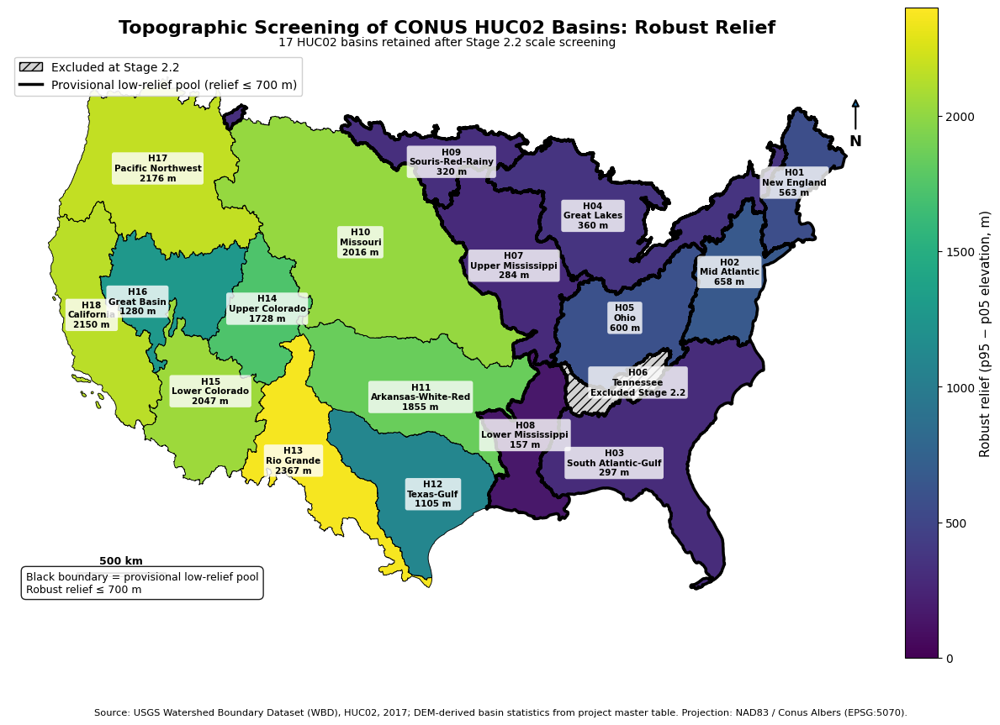


Relief figures saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/basin_selection/figure_huc02_robust_relief.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/basin_selection/figure_huc02_robust_relief.pdf
/content/drive/MyDrive/ecohydro_project/outputs/figures/basin_selection/figure_huc02_robust_relief.svg


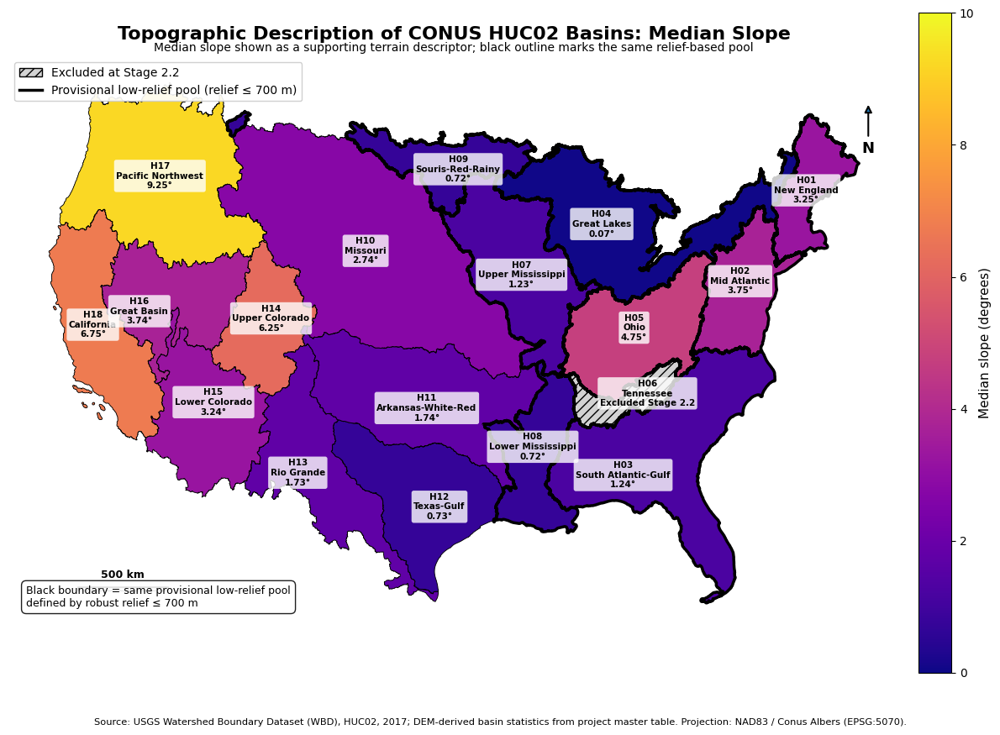


Slope figures saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/basin_selection/figure_huc02_median_slope.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/basin_selection/figure_huc02_median_slope.pdf
/content/drive/MyDrive/ecohydro_project/outputs/figures/basin_selection/figure_huc02_median_slope.svg

PLOTTING COMPLETE
Primary screen: robust relief <= 700 m
Number of provisional low-relief basins: 8

Median slope remains available as a supporting descriptive variable and is not used as a selection threshold.


In [ ]:
# ============================================================
# ECOHYDRO PROJECT
# HUC02 TOPOGRAPHIC SCREENING MAPS
# Revised workflow:
#   - Robust relief is the primary topographic screen
#   - Median slope is descriptive/supporting only
#   - No slope threshold / no dual boundary system
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# ============================================================
# 1. PATHS
# ============================================================

BASE = '/content/drive/MyDrive/ecohydro_project'

HUC02_PATH = (
    f'{BASE}/data/raw/wbd_2017/'
    'wbd_huc02_conus_ee_2017.geojson'
)

MASTER_PATH = (
    f'{BASE}/data/processed/basin_selection/'
    'huc2_master_table_with_dem_v3_and_densities.csv'
)

OUTPUT_DIR = (
    f'{BASE}/outputs/figures/basin_selection'
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 2. TOPOGRAPHIC SCREEN
# ============================================================

# Primary screening threshold
RELIEF_THRESHOLD_M = 700.0

EXPECTED_HUC02 = {
    f'{i:02d}' for i in range(1, 19)
}


# ============================================================
# 3. LOAD HUC02 GEOMETRY
# ============================================================

huc02 = gpd.read_file(HUC02_PATH)

huc02['huc2'] = (
    huc02['huc2']
    .astype(str)
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(2)
)

print("=" * 70)
print("HUC02 GEOMETRY")
print("=" * 70)

print("Rows:", len(huc02))
print("CRS:", huc02.crs)
print("HUC02 codes:", sorted(huc02['huc2'].tolist()))

# Geometry QA
assert set(huc02['huc2']) == EXPECTED_HUC02
assert not huc02['huc2'].duplicated().any()
assert not huc02.geometry.isna().any()
assert not huc02.geometry.is_empty.any()
assert huc02.geometry.is_valid.all()

print("Geometry QA: PASS")


# ============================================================
# 4. LOAD MASTER TABLE
# ============================================================

master = pd.read_csv(MASTER_PATH)

master['huc2'] = (
    master['huc2']
    .astype(str)
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(2)
)

required_cols = [
    'huc2',
    'name',
    'relief_p95_p05_m',
    'median_slope_deg',
    'p05_elevation_m',
    'p95_elevation_m'
]

missing = [
    c for c in required_cols
    if c not in master.columns
]

if missing:
    raise ValueError(
        f"Missing master-table columns: {missing}"
    )

assert not master['huc2'].duplicated().any()

print("\n" + "=" * 70)
print("MASTER TABLE")
print("=" * 70)

print("Rows:", len(master))
print("Master-table QA: PASS")


# ============================================================
# 5. CREATE HUC02 GEOMETRY TABLE
# ============================================================

# Keep the polygon name separately because H06 is not
# present in the master table.

huc02_map = huc02[
    ['huc2', 'name', 'geometry']
].copy()

huc02_map = huc02_map.rename(
    columns={'name': 'huc02_name'}
)


# ============================================================
# 6. JOIN MASTER ATTRIBUTES TO HUC02 GEOMETRY
# ============================================================

map_gdf = huc02_map.merge(
    master[required_cols],
    on='huc2',
    how='left',
    validate='one_to_one'
)


# ============================================================
# 7. USE MASTER NAME WHERE AVAILABLE
#    HUC02 GEOMETRY NAME AS FALLBACK
# ============================================================

map_gdf['name'] = map_gdf['name'].fillna(
    map_gdf['huc02_name']
)

map_gdf = map_gdf.drop(
    columns=['huc02_name']
)


# ============================================================
# 8. CHECK MASTER-TABLE MATCHING
# ============================================================

n_with_attributes = (
    map_gdf['relief_p95_p05_m'].notna().sum()
)

print(
    f"Basins with DEM attributes: "
    f"{n_with_attributes}/{len(map_gdf)}"
)

assert n_with_attributes == 17

# Every basin should still have a name,
# including H06 from the geometry source.
assert map_gdf['name'].notna().all()


# ============================================================
# 9. STAGE 2.2 STATUS
# ============================================================

master_huc2 = set(master['huc2'])

map_gdf['stage22_status'] = np.where(
    map_gdf['huc2'].isin(master_huc2),
    'Retained after Stage 2.2',
    'Excluded at Stage 2.2'
)


# ============================================================
# 10. PRIMARY TOPOGRAPHIC SCREEN
# ============================================================

# Only robust relief determines the provisional
# low-relief screening pool.

map_gdf['relief_pass'] = (
    map_gdf['relief_p95_p05_m']
    <= RELIEF_THRESHOLD_M
)

# Median slope is NOT used as a pass/fail criterion.
# It remains in the table only as a supporting descriptor.


# ============================================================
# 11. EQUAL-AREA PROJECTION
# ============================================================

map_gdf = map_gdf.to_crs('EPSG:5070')


# ============================================================
# 12. SPLIT RETAINED / EXCLUDED BASINS
# ============================================================

retained = map_gdf[
    map_gdf['stage22_status']
    == 'Retained after Stage 2.2'
].copy()

excluded = map_gdf[
    map_gdf['stage22_status']
    == 'Excluded at Stage 2.2'
].copy()


# ============================================================
# 13. PROVISIONAL LOW-RELIEF POOL
# ============================================================

low_relief_gdf = retained[
    retained['relief_pass']
].copy()


# ============================================================
# 14. PRINT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("TOPOGRAPHIC SCREEN SUMMARY")
print("=" * 70)

n_low_relief = int(
    retained['relief_pass'].sum()
)

print(
    f"Relief <= {RELIEF_THRESHOLD_M:.0f} m:",
    n_low_relief
)

print(
    "\nMedian slope is retained as a "
    "supporting descriptive variable only."
)

print("\nDetailed values:")

summary_cols = [
    'huc2',
    'name',
    'relief_p95_p05_m',
    'median_slope_deg',
    'relief_pass'
]

print(
    retained[
        summary_cols
    ]
    .sort_values('huc2')
    .to_string(index=False)
)

print("\nProvisional low-relief HUC02 basins:")

print(
    low_relief_gdf[
        [
            'huc2',
            'name',
            'relief_p95_p05_m',
            'median_slope_deg'
        ]
    ]
    .sort_values('huc2')
    .to_string(index=False)
)


# ============================================================
# 15. REPRESENTATIVE POINTS FOR LABELING
# ============================================================

label_points = map_gdf.copy()

label_points['label_point'] = (
    label_points.geometry.representative_point()
)


# ============================================================
# 16. PLOT SETTINGS
# ============================================================

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 16,
    'axes.labelsize': 11
})


# ============================================================
# FIGURE 1 — ROBUST RELIEF
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 9)
)


# ------------------------------------------------------------
# H06: excluded at Stage 2.2
# ------------------------------------------------------------

if len(excluded) > 0:

    excluded.plot(
        ax=ax,
        color='lightgray',
        edgecolor='black',
        linewidth=1.0,
        hatch='///',
        zorder=1
    )


# ------------------------------------------------------------
# Relief color scale
# ------------------------------------------------------------

relief_values = retained[
    'relief_p95_p05_m'
].dropna()

relief_vmax = max(
    700,
    float(
        np.ceil(
            relief_values.max() / 100
        ) * 100
    )
)

relief_norm = Normalize(
    vmin=0,
    vmax=relief_vmax
)


# ------------------------------------------------------------
# Basin fill
# ------------------------------------------------------------

retained.plot(
    ax=ax,
    column='relief_p95_p05_m',
    cmap='viridis',
    norm=relief_norm,
    edgecolor='black',
    linewidth=0.65,
    zorder=2
)


# ------------------------------------------------------------
# PRIMARY SCREEN OUTLINE
#
# Black outline = relief <= 700 m
# ------------------------------------------------------------

low_relief_gdf.boundary.plot(
    ax=ax,
    color='black',
    linewidth=2.5,
    zorder=4
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

for _, row in label_points.iterrows():

    x = row['label_point'].x
    y = row['label_point'].y

    basin_name = str(
        row['name']
    ).replace(' Region', '')

    if row['huc2'] == '06':

        label = (
            f"H06\n"
            f"{basin_name}\n"
            "Excluded Stage 2.2"
        )

    else:

        label = (
            f"H{row['huc2']}\n"
            f"{basin_name}\n"
            f"{row['relief_p95_p05_m']:.0f} m"
        )

    ax.text(
        x,
        y,
        label,
        ha='center',
        va='center',
        fontsize=7.5,
        fontweight='bold',
        zorder=6,
        bbox=dict(
            boxstyle='round,pad=0.25',
            facecolor='white',
            edgecolor='none',
            alpha=0.80
        )
    )


# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

sm = ScalarMappable(
    cmap='viridis',
    norm=relief_norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.02
)

cbar.set_label(
    'Robust relief (p95 − p05 elevation, m)',
    fontsize=11
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend_handles = [

    Patch(
        facecolor='lightgray',
        edgecolor='black',
        hatch='///',
        label='Excluded at Stage 2.2'
    ),

    Line2D(
        [0],
        [0],
        color='black',
        lw=2.5,
        label='Provisional low-relief pool (relief ≤ 700 m)'
    )
]

ax.legend(
    handles=legend_handles,
    loc='upper left',
    frameon=True,
    framealpha=0.92
)


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    'Topographic Screening of CONUS HUC02 Basins: Robust Relief',
    fontweight='bold',
    pad=15
)

ax.text(
    0.5,
    1.005,
    '17 HUC02 basins retained after Stage 2.2 scale screening',
    transform=ax.transAxes,
    ha='center',
    va='bottom',
    fontsize=10
)


# ------------------------------------------------------------
# North arrow
# ------------------------------------------------------------

ax.annotate(
    'N',
    xy=(0.965, 0.92),
    xytext=(0.965, 0.84),
    xycoords='axes fraction',
    textcoords='axes fraction',
    ha='center',
    va='center',
    fontsize=13,
    fontweight='bold',
    arrowprops=dict(
        arrowstyle='-|>',
        lw=1.5
    )
)


# ------------------------------------------------------------
# Scale bar
# ------------------------------------------------------------

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

scale_km = 500
scale_m = scale_km * 1000

bar_x = xmin + 0.08 * (xmax - xmin)
bar_y = ymin + 0.07 * (ymax - ymin)

ax.plot(
    [bar_x, bar_x + scale_m],
    [bar_y, bar_y],
    color='black',
    linewidth=4,
    zorder=10
)

ax.plot(
    [bar_x, bar_x + scale_m],
    [bar_y, bar_y],
    color='white',
    linewidth=2,
    zorder=11
)

ax.text(
    bar_x + scale_m / 2,
    bar_y + 0.015 * (ymax - ymin),
    f'{scale_km} km',
    ha='center',
    va='bottom',
    fontsize=9,
    fontweight='bold',
    bbox=dict(
        boxstyle='round,pad=0.2',
        facecolor='white',
        edgecolor='none',
        alpha=0.8
    ),
    zorder=12
)


# ------------------------------------------------------------
# Explanation box
# ------------------------------------------------------------

ax.text(
    0.02,
    0.035,
    'Black boundary = provisional low-relief pool\n'
    'Robust relief ≤ 700 m',
    transform=ax.transAxes,
    fontsize=9,
    va='bottom',
    ha='left',
    bbox=dict(
        boxstyle='round,pad=0.45',
        facecolor='white',
        edgecolor='black',
        alpha=0.88
    ),
    zorder=20
)


# ------------------------------------------------------------
# Source note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.012,
    'Source: USGS Watershed Boundary Dataset (WBD), HUC02, 2017; '
    'DEM-derived basin statistics from project master table. '
    'Projection: NAD83 / Conus Albers (EPSG:5070).',
    ha='center',
    fontsize=8.2
)

ax.set_axis_off()

plt.tight_layout(
    rect=[0, 0.035, 1, 1]
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

relief_png = (
    f'{OUTPUT_DIR}/figure_huc02_robust_relief.png'
)

relief_pdf = (
    f'{OUTPUT_DIR}/figure_huc02_robust_relief.pdf'
)

relief_svg = (
    f'{OUTPUT_DIR}/figure_huc02_robust_relief.svg'
)

fig.savefig(
    relief_png,
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    relief_pdf,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    relief_svg,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("\nRelief figures saved:")
print(relief_png)
print(relief_pdf)
print(relief_svg)


# ============================================================
# FIGURE 2 — MEDIAN SLOPE
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 9)
)


# ------------------------------------------------------------
# H06: excluded at Stage 2.2
# ------------------------------------------------------------

if len(excluded) > 0:

    excluded.plot(
        ax=ax,
        color='lightgray',
        edgecolor='black',
        linewidth=1.0,
        hatch='///',
        zorder=1
    )


# ------------------------------------------------------------
# Slope color scale
# ------------------------------------------------------------

slope_values = retained[
    'median_slope_deg'
].dropna()

slope_vmax = max(
    4,
    float(
        np.ceil(
            slope_values.max()
        )
    )
)

slope_norm = Normalize(
    vmin=0,
    vmax=slope_vmax
)


# ------------------------------------------------------------
# Basin fill
# ------------------------------------------------------------

retained.plot(
    ax=ax,
    column='median_slope_deg',
    cmap='plasma',
    norm=slope_norm,
    edgecolor='black',
    linewidth=0.65,
    zorder=2
)


# ------------------------------------------------------------
# SAME PRIMARY SCREEN OUTLINE AS FIGURE 1
#
# Black outline = relief <= 700 m
#
# Important:
# The slope map does NOT create a new slope-based
# candidate class.
# ------------------------------------------------------------

low_relief_gdf.boundary.plot(
    ax=ax,
    color='black',
    linewidth=2.5,
    zorder=4
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

for _, row in label_points.iterrows():

    x = row['label_point'].x
    y = row['label_point'].y

    basin_name = str(
        row['name']
    ).replace(' Region', '')

    if row['huc2'] == '06':

        label = (
            f"H06\n"
            f"{basin_name}\n"
            "Excluded Stage 2.2"
        )

    else:

        label = (
            f"H{row['huc2']}\n"
            f"{basin_name}\n"
            f"{row['median_slope_deg']:.2f}°"
        )

    ax.text(
        x,
        y,
        label,
        ha='center',
        va='center',
        fontsize=7.5,
        fontweight='bold',
        zorder=6,
        bbox=dict(
            boxstyle='round,pad=0.25',
            facecolor='white',
            edgecolor='none',
            alpha=0.80
        )
    )


# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

sm = ScalarMappable(
    cmap='plasma',
    norm=slope_norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.02
)

cbar.set_label(
    'Median slope (degrees)',
    fontsize=11
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='upper left',
    frameon=True,
    framealpha=0.92
)


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    'Topographic Description of CONUS HUC02 Basins: Median Slope',
    fontweight='bold',
    pad=15
)

ax.text(
    0.5,
    1.005,
    'Median slope shown as a supporting terrain descriptor; '
    'black outline marks the same relief-based pool',
    transform=ax.transAxes,
    ha='center',
    va='bottom',
    fontsize=10
)


# ------------------------------------------------------------
# North arrow
# ------------------------------------------------------------

ax.annotate(
    'N',
    xy=(0.965, 0.92),
    xytext=(0.965, 0.84),
    xycoords='axes fraction',
    textcoords='axes fraction',
    ha='center',
    va='center',
    fontsize=13,
    fontweight='bold',
    arrowprops=dict(
        arrowstyle='-|>',
        lw=1.5
    )
)


# ------------------------------------------------------------
# Scale bar
# ------------------------------------------------------------

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

bar_x = xmin + 0.08 * (xmax - xmin)
bar_y = ymin + 0.07 * (ymax - ymin)

ax.plot(
    [bar_x, bar_x + scale_m],
    [bar_y, bar_y],
    color='black',
    linewidth=4,
    zorder=10
)

ax.plot(
    [bar_x, bar_x + scale_m],
    [bar_y, bar_y],
    color='white',
    linewidth=2,
    zorder=11
)

ax.text(
    bar_x + scale_m / 2,
    bar_y + 0.015 * (ymax - ymin),
    f'{scale_km} km',
    ha='center',
    va='bottom',
    fontsize=9,
    fontweight='bold',
    bbox=dict(
        boxstyle='round,pad=0.2',
        facecolor='white',
        edgecolor='none',
        alpha=0.8
    ),
    zorder=12
)


# ------------------------------------------------------------
# Explanation box
# ------------------------------------------------------------

ax.text(
    0.02,
    0.035,
    'Black boundary = same provisional low-relief pool\n'
    'defined by robust relief ≤ 700 m',
    transform=ax.transAxes,
    fontsize=9,
    va='bottom',
    ha='left',
    bbox=dict(
        boxstyle='round,pad=0.45',
        facecolor='white',
        edgecolor='black',
        alpha=0.88
    ),
    zorder=20
)


# ------------------------------------------------------------
# Source note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.012,
    'Source: USGS Watershed Boundary Dataset (WBD), HUC02, 2017; '
    'DEM-derived basin statistics from project master table. '
    'Projection: NAD83 / Conus Albers (EPSG:5070).',
    ha='center',
    fontsize=8.2
)

ax.set_axis_off()

plt.tight_layout(
    rect=[0, 0.035, 1, 1]
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

slope_png = (
    f'{OUTPUT_DIR}/figure_huc02_median_slope.png'
)

slope_pdf = (
    f'{OUTPUT_DIR}/figure_huc02_median_slope.pdf'
)

slope_svg = (
    f'{OUTPUT_DIR}/figure_huc02_median_slope.svg'
)

fig.savefig(
    slope_png,
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    slope_pdf,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    slope_svg,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("\nSlope figures saved:")
print(slope_png)
print(slope_pdf)
print(slope_svg)


# ============================================================
# FINAL QA / SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("PLOTTING COMPLETE")
print("=" * 70)

print(
    f"Primary screen: robust relief <= "
    f"{RELIEF_THRESHOLD_M:.0f} m"
)

print(
    f"Number of provisional low-relief basins: "
    f"{n_low_relief}"
)

print(
    "\nMedian slope remains available as a "
    "supporting descriptive variable and is "
    "not used as a selection threshold."
)

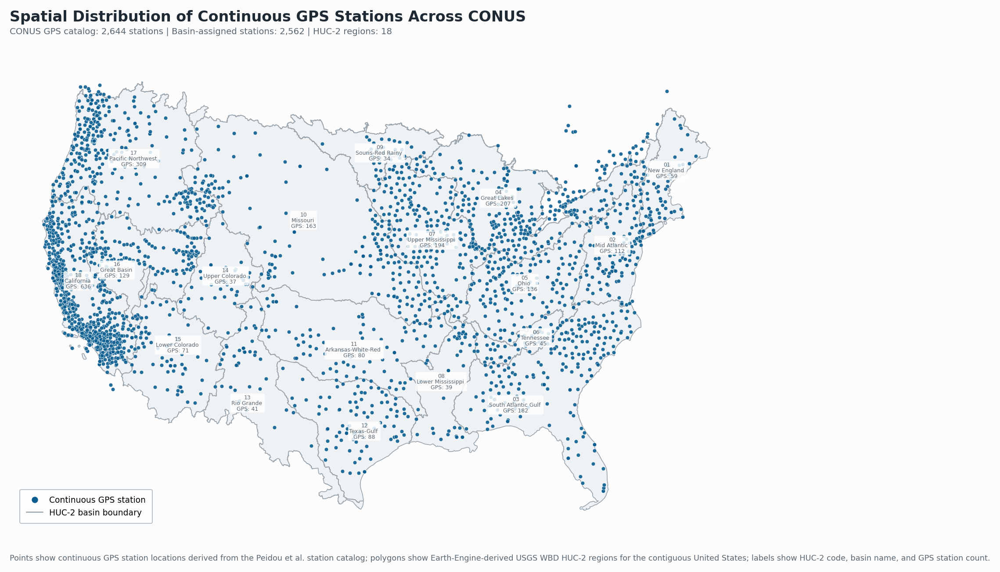

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/gps_stations_conus_map_with_basin_counts.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/gps_stations_conus_map_with_basin_counts.pdf
Total GPS stations plotted: 2,644
Stations assigned to a HUC-2 basin: 2,562

Basin-wise GPS counts:
huc2  gps_count
  01         59
  02        112
  03        182
  04        207
  05        136
  06         45
  07        194
  08         39
  09         34
  10        163
  11         80
  12         88
  13         41
  14         37
  15         71
  16        129
  17        309
  18        636


In [ ]:
# ============================================================
# Publication-quality map of GPS station distribution across CONUS
# with basin-wise GPS station counts
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
base = "/content/drive/MyDrive/ecohydro_project"

gps_file = f"{base}/data/raw/gps_metadata/peidou_etal_2024/station_catalog_conus_complete.csv"
basin_file = f"{base}/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"
output_dir = f"{base}/outputs/figures"
os.makedirs(output_dir, exist_ok=True)

output_png = f"{output_dir}/gps_stations_conus_map_with_basin_counts.png"
output_pdf = f"{output_dir}/gps_stations_conus_map_with_basin_counts.pdf"

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#eef2f5"
BASIN_EDGE = "#9aa4ad"
POINT_COLOR = "#0b5d8f"
POINT_EDGE = "white"
TEXT_COLOR = "#1f2933"
MUTED_TEXT = "#5b6770"
FRAME_COLOR = "#b8c1c8"

# ------------------------------------------------------------
# 3. Load data
# ------------------------------------------------------------
gps = pd.read_csv(gps_file)
basins = gpd.read_file(basin_file)

# Keep only required columns
gps = gps[["station_id", "longitude", "latitude"]].copy()

# Drop rows with missing coordinates
gps["longitude"] = pd.to_numeric(gps["longitude"], errors="coerce")
gps["latitude"] = pd.to_numeric(gps["latitude"], errors="coerce")
gps = gps.dropna(subset=["longitude", "latitude"]).copy()

# Create GeoDataFrame
gps_gdf = gpd.GeoDataFrame(
    gps,
    geometry=gpd.points_from_xy(gps["longitude"], gps["latitude"]),
    crs="EPSG:4326"
)

# Standardize HUC2 field
basins["huc2"] = basins["huc2"].astype(str).str.zfill(2)

# Spatial join to count stations inside basin polygons
gps_with_basin = gpd.sjoin(
    gps_gdf,
    basins[["huc2", "name", "geometry"]],
    how="left",
    predicate="within"
)

total_stations = len(gps_gdf)
mapped_stations = gps_with_basin["huc2"].notna().sum()

# ------------------------------------------------------------
# 4. Basin-wise GPS counts
# ------------------------------------------------------------
gps_counts = (
    gps_with_basin.dropna(subset=["huc2"])
    .groupby("huc2")["station_id"]
    .nunique()
    .reset_index(name="gps_count")
)

basins = basins.merge(gps_counts, on="huc2", how="left")
basins["gps_count"] = basins["gps_count"].fillna(0).astype(int)

# ------------------------------------------------------------
# 5. Reproject to CONUS-friendly projection
# ------------------------------------------------------------
proj = "EPSG:5070"   # NAD83 / Conus Albers

basins_proj = basins.to_crs(proj)
gps_proj = gps_gdf.to_crs(proj)

# ------------------------------------------------------------
# 6. Plot setup
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 8.8))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# Basin polygons
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.8,
    zorder=1
)

# GPS points
gps_proj.plot(
    ax=ax,
    markersize=18,
    color=POINT_COLOR,
    edgecolor=POINT_EDGE,
    linewidth=0.35,
    alpha=0.9,
    zorder=3
)

# ------------------------------------------------------------
# 7. Basin labels with GPS counts
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["centroid"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

for _, row in label_basins.iterrows():
    x, y = row["centroid"].x, row["centroid"].y
    label = f'{row["huc2"]}\n{row["short_name"]}\nGPS: {row["gps_count"]:,}'
    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=6.0,
        color=MUTED_TEXT,
        linespacing=1.0,
        zorder=4,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="white",
            edgecolor="none",
            alpha=0.84
        )
    )

# ------------------------------------------------------------
# 8. Map extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.04
ypad = (ymax - ymin) * 0.04
ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 9. Titles and metadata
# ------------------------------------------------------------
fig.suptitle(
    "Spatial Distribution of Continuous GPS Stations Across CONUS",
    x=0.125,
    y=0.975,
    ha="left",
    fontsize=16,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.125,
    0.945,
    f"CONUS GPS catalog: {total_stations:,} stations | Basin-assigned stations: {mapped_stations:,} | HUC-2 regions: {len(basins)}",
    ha="left",
    va="top",
    fontsize=9.5,
    color=MUTED_TEXT
)

fig.text(
    0.125,
    0.02,
    "Points show continuous GPS station locations derived from the Peidou et al. station catalog; "
    "polygons show Earth-Engine-derived USGS WBD HUC-2 regions for the contiguous United States; "
    "labels show HUC-2 code, basin name, and GPS station count.",
    ha="left",
    va="bottom",
    fontsize=8.5,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 10. Legend
# ------------------------------------------------------------
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        label="Continuous GPS station",
        markerfacecolor=POINT_COLOR,
        markeredgecolor=POINT_EDGE,
        markeredgewidth=0.6,
        markersize=7.5
    ),
    Line2D(
        [0], [0],
        color=BASIN_EDGE,
        lw=1.2,
        label="HUC-2 basin boundary"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.95,
    fontsize=9,
    borderpad=0.8
)

# ------------------------------------------------------------
# 11. Clean axes
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.075,
    right=0.97,
    bottom=0.08,
    top=0.88
)

# ------------------------------------------------------------
# 12. Save figure
# ------------------------------------------------------------
plt.savefig(output_png, dpi=600, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.savefig(output_pdf, dpi=600, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

print("Saved:")
print(output_png)
print(output_pdf)
print(f"Total GPS stations plotted: {total_stations:,}")
print(f"Stations assigned to a HUC-2 basin: {mapped_stations:,}")
print("\nBasin-wise GPS counts:")
print(gps_counts.sort_values("huc2").to_string(index=False))

Count-table columns: ['huc2', 'name', 'gps_count', 'well_count', 'snotel_count', 'stream_gauge_count', 'name_scale', 'area_km2_computed', 'screen_result', 'edge_fraction', 'total_raw_count']
Using 'well_count' as the well-count column.
Valid CONUS wells to plot: 1,223,819


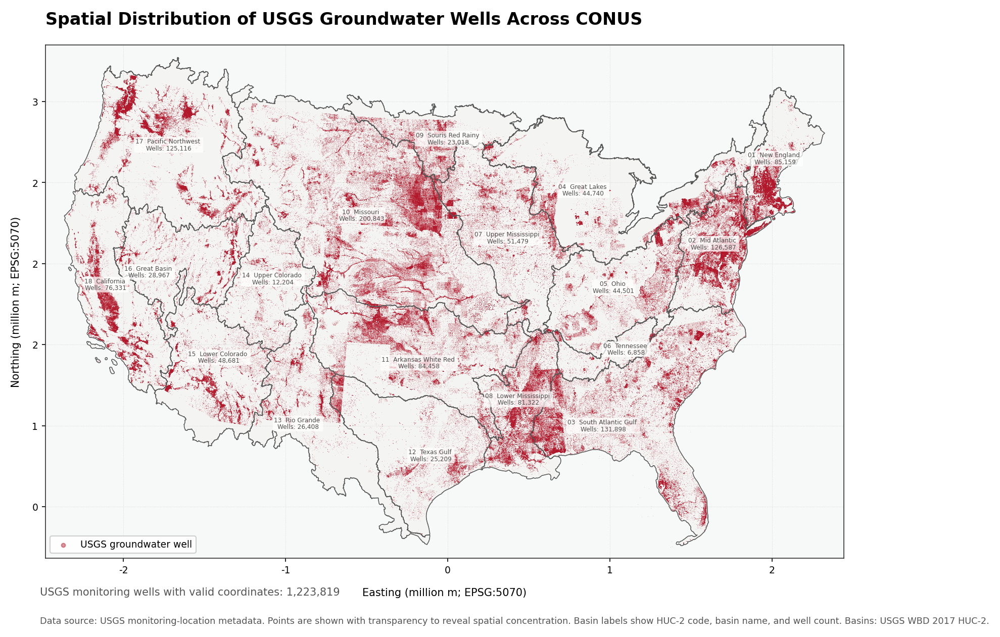

Saved: /content/drive/MyDrive/ecohydro_project/outputs/well_maps/conus_usgs_wells_transparent_points_basin_counts.png
Valid plotted wells: 1,223,819
Map generation complete.


In [ ]:
# ============================================================
# CONUS USGS WELL DISTRIBUTION MAP
# Semi-transparent point map with basin number, basin name,
# and basin-wise well count
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. File paths
# ------------------------------------------------------------

WELL_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wells_metadata/usgs_wells_conus_metadata.csv"
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"
COUNT_FILE = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_ground_constraint_counts.csv"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/well_maps"
os.makedirs(OUTPUT_DIR, exist_ok=True)

POINT_MAP_FILE = os.path.join(
    OUTPUT_DIR,
    "conus_usgs_wells_transparent_points_basin_counts.png"
)

# ------------------------------------------------------------
# 2. Plot settings
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.edgecolor": "#303030",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

# ------------------------------------------------------------
# 3. Load basin-wise count table
# ------------------------------------------------------------

counts = pd.read_csv(COUNT_FILE)
print("Count-table columns:", counts.columns.tolist())

if "huc2" not in counts.columns:
    raise KeyError(
        f"'huc2' column not found in {COUNT_FILE}. "
        f"Available columns: {counts.columns.tolist()}"
    )

counts["huc2"] = counts["huc2"].astype(str).str.zfill(2)

possible_well_cols = [
    "wellcount",
    "well_count",
    "wells",
    "n_wells",
    "usgs_wells",
    "well_count_huc2"
]

well_col = None
for col in possible_well_cols:
    if col in counts.columns:
        well_col = col
        break

if well_col is None:
    # Try a fuzzy fallback: any column containing both "well" and "count"
    for col in counts.columns:
        c = col.lower()
        if ("well" in c) and ("count" in c):
            well_col = col
            break

if well_col is None:
    raise KeyError(
        "Could not find a well-count column in the HUC-2 count file.\n"
        f"Available columns: {counts.columns.tolist()}"
    )

counts = counts[["huc2", well_col]].copy()
counts = counts.rename(columns={well_col: "wellcount"})
counts["wellcount"] = pd.to_numeric(counts["wellcount"], errors="coerce").fillna(0).astype(int)

print(f"Using '{well_col}' as the well-count column.")

# ------------------------------------------------------------
# 4. Load well data
# ------------------------------------------------------------

wells = pd.read_csv(WELL_FILE, low_memory=False)

required_cols = ["monitoring_location_id", "latitude", "longitude"]
missing_cols = [c for c in required_cols if c not in wells.columns]
if missing_cols:
    raise KeyError(f"Missing required columns in well file: {missing_cols}")

wells["latitude"] = pd.to_numeric(wells["latitude"], errors="coerce")
wells["longitude"] = pd.to_numeric(wells["longitude"], errors="coerce")

wells_clean = wells.dropna(subset=["latitude", "longitude"]).copy()

wells_clean = wells_clean[
    wells_clean["latitude"].between(24, 50) &
    wells_clean["longitude"].between(-125, -66.5)
].copy()

wells_clean = wells_clean.drop_duplicates(
    subset=["monitoring_location_id"]
).copy()

print(f"Valid CONUS wells to plot: {len(wells_clean):,}")

wells_gdf = gpd.GeoDataFrame(
    wells_clean,
    geometry=gpd.points_from_xy(
        wells_clean["longitude"],
        wells_clean["latitude"]
    ),
    crs="EPSG:4326"
)

# ------------------------------------------------------------
# 5. Load basin polygons
# ------------------------------------------------------------

basins = gpd.read_file(BASIN_FILE)

if "huc2" not in basins.columns:
    raise KeyError(
        f"'huc2' column not found in basin file. "
        f"Available columns: {basins.columns.tolist()}"
    )

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[
    basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])
].copy()

basins["geometry"] = basins.geometry.make_valid()

# ------------------------------------------------------------
# 6. Reproject to CONUS equal-area CRS
# ------------------------------------------------------------

MAP_CRS = "EPSG:5070"

basins_proj = basins.to_crs(MAP_CRS)
wells_proj = wells_gdf.to_crs(MAP_CRS)

# Merge basin-wise well counts
basins_proj = basins_proj.merge(
    counts[["huc2", "wellcount"]],
    on="huc2",
    how="left"
)

basins_proj["wellcount"] = basins_proj["wellcount"].fillna(0).astype(int)

# ------------------------------------------------------------
# 7. Map extent
# ------------------------------------------------------------

minx, miny, maxx, maxy = basins_proj.total_bounds

xpad = (maxx - minx) * 0.025
ypad = (maxy - miny) * 0.025

X_LIMITS = (minx - xpad, maxx + xpad)
Y_LIMITS = (miny - ypad, maxy + ypad)

# ------------------------------------------------------------
# 8. Basin label function
# ------------------------------------------------------------

def add_basin_labels(ax, basin_gdf):
    label_basins = basin_gdf.copy()
    label_basins["label_point"] = label_basins.geometry.representative_point()

    if "name" in label_basins.columns:
        label_basins["short_name"] = (
            label_basins["name"]
            .astype(str)
            .str.replace("Region", "", regex=False)
            .str.replace("-", " ", regex=False)
        )
    else:
        label_basins["short_name"] = ""

    for _, row in label_basins.iterrows():
        pt = row["label_point"]

        label = (
            f'{row["huc2"]}  {row["short_name"]}\n'
            f'Wells: {row["wellcount"]:,}'
        )

        ax.text(
            pt.x,
            pt.y,
            label,
            ha="center",
            va="center",
            fontsize=5.8,
            color="#4d4d4d",
            linespacing=1.05,
            zorder=6,
            bbox=dict(
                boxstyle="round,pad=0.18",
                facecolor="white",
                edgecolor="none",
                alpha=0.74
            )
        )

# ------------------------------------------------------------
# 9. Axis styling
# ------------------------------------------------------------

def style_map_axes(ax):
    ax.set_xlim(*X_LIMITS)
    ax.set_ylim(*Y_LIMITS)
    ax.set_aspect("equal")

    ax.grid(
        True,
        color="#b8b8b8",
        linewidth=0.45,
        linestyle=":",
        alpha=0.55
    )

    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x / 1e6:.0f}")
    )
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda y, pos: f"{y / 1e6:.0f}")
    )

    ax.set_xlabel("Easting (million m; EPSG:5070)", labelpad=12)
    ax.set_ylabel("Northing (million m; EPSG:5070)", labelpad=10)

# ------------------------------------------------------------
# 10. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 9.4))
fig.patch.set_facecolor("white")
ax.set_facecolor("#f7f8f8")

# Manual space for title/subtitle and footnote
fig.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.86,
    bottom=0.14
)

# Basin background
basins_proj.plot(
    ax=ax,
    facecolor="#f4f5f3",
    edgecolor="#9a9a9a",
    linewidth=0.65,
    zorder=1
)

# Semi-transparent well points
wells_proj.plot(
    ax=ax,
    color="#b2182b",
    markersize=0.22,
    alpha=0.14,
    linewidth=0,
    rasterized=True,
    zorder=3
)

# Basin boundaries above points
basins_proj.boundary.plot(
    ax=ax,
    color="#575757",
    linewidth=0.65,
    zorder=5
)

# Add basin labels
add_basin_labels(ax, basins_proj)

# Style axes
style_map_axes(ax)

# Title
ax.set_title(
    "Spatial Distribution of USGS Groundwater Wells Across CONUS",
    loc="left",
    pad=20
)

# Subtitle
fig.text(
    0.07,
    0.085,
    f"USGS monitoring wells with valid coordinates: {len(wells_proj):,}",
    ha="left",
    va="bottom",
    fontsize=10,
    color="#555555"
)

# Legend
ax.scatter(
    [],
    [],
    s=14,
    color="#b2182b",
    alpha=0.45,
    label="USGS groundwater well"
)

ax.legend(
    loc="lower left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="#cccccc"
)

# Footnote
fig.text(
    0.07,
    0.045,
    "Data source: USGS monitoring-location metadata. "
    "Points are shown with transparency to reveal spatial concentration. "
    "Basin labels show HUC-2 code, basin name, and well count. "
    "Basins: USGS WBD 2017 HUC-2.",
    ha="left",
    va="bottom",
    fontsize=8.5,
    color="#555555"
)

# Save and show
plt.savefig(
    POINT_MAP_FILE,
    dpi=600,
    facecolor="white"
)

plt.show()
plt.close(fig)

print(f"Saved: {POINT_MAP_FILE}")
print(f"Valid plotted wells: {len(wells_proj):,}")
print("Map generation complete.")

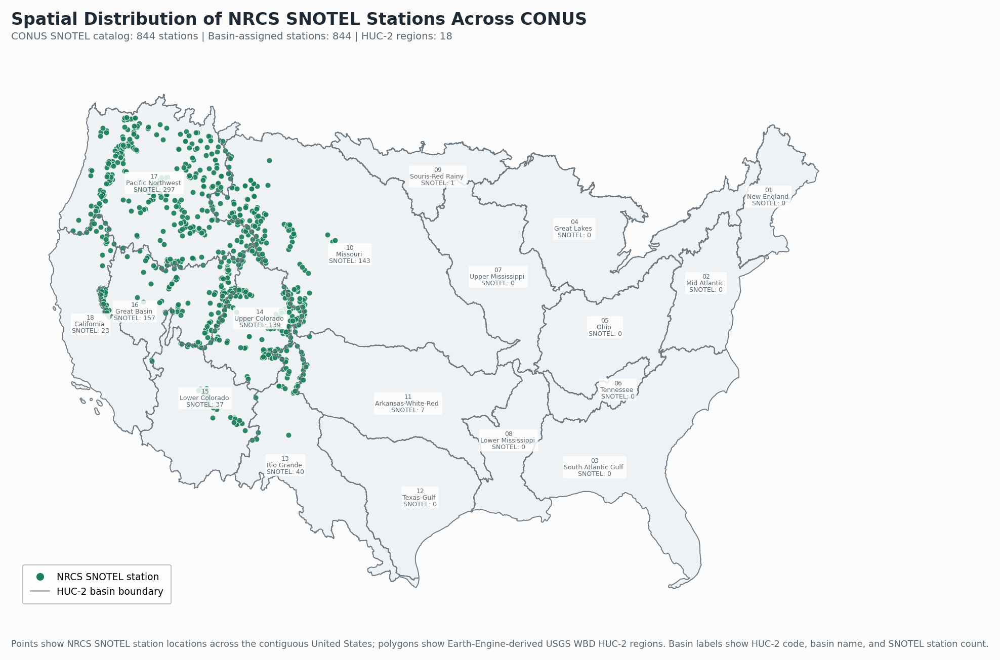

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/snotel_stations_conus_map.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/snotel_stations_conus_map.pdf
Total SNOTEL stations plotted: 844
Stations assigned to a HUC-2 basin: 844

Basin-wise SNOTEL counts:
huc2  snotel_count
  09             1
  10           143
  11             7
  13            40
  14           139
  15            37
  16           157
  17           297
  18            23


In [ ]:
# ============================================================
# Publication-quality map of SNOTEL station distribution across CONUS
# with basin-wise station counts
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
SNOTEL_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/snotel_metadata/nrcs_snotel_stations_conus.csv"
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PNG = os.path.join(OUTPUT_DIR, "snotel_stations_conus_map.png")
OUTPUT_PDF = os.path.join(OUTPUT_DIR, "snotel_stations_conus_map.pdf")

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#eef2f5"
BASIN_EDGE = "#97a3ad"
POINT_COLOR = "#1b7f5a"
POINT_EDGE = "white"
TEXT_COLOR = "#1f2933"
MUTED_TEXT = "#5b6770"
FRAME_COLOR = "#b8c1c8"

# ------------------------------------------------------------
# 3. Load data
# ------------------------------------------------------------
snotel = pd.read_csv(SNOTEL_FILE)
basins = gpd.read_file(BASIN_FILE)

required_cols = ["station_id", "latitude", "longitude"]
missing_cols = [c for c in required_cols if c not in snotel.columns]
if missing_cols:
    raise KeyError(f"Missing required columns in SNOTEL file: {missing_cols}")

snotel = snotel[[
    "station_id",
    "station_name",
    "state_code",
    "latitude",
    "longitude"
]].copy()

# Clean coordinates
snotel["latitude"] = pd.to_numeric(snotel["latitude"], errors="coerce")
snotel["longitude"] = pd.to_numeric(snotel["longitude"], errors="coerce")
snotel = snotel.dropna(subset=["latitude", "longitude"]).copy()

# Optional CONUS coordinate filter
snotel = snotel[
    snotel["latitude"].between(24, 50) &
    snotel["longitude"].between(-125, -66.5)
].copy()

# Remove duplicate stations by station_id
snotel = snotel.drop_duplicates(subset=["station_id"]).copy()

# Create GeoDataFrame
snotel_gdf = gpd.GeoDataFrame(
    snotel,
    geometry=gpd.points_from_xy(snotel["longitude"], snotel["latitude"]),
    crs="EPSG:4326"
)

# ------------------------------------------------------------
# 4. Prepare basin data
# ------------------------------------------------------------
if "huc2" not in basins.columns:
    raise KeyError(
        f"'huc2' column not found in basin file. Available columns: {basins.columns.tolist()}"
    )

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[
    basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])
].copy()

basins["geometry"] = basins.geometry.make_valid()

# ------------------------------------------------------------
# 5. Spatial join for basin-wise counts
# ------------------------------------------------------------
snotel_with_basin = gpd.sjoin(
    snotel_gdf,
    basins[["huc2", "name", "geometry"]],
    how="left",
    predicate="within"
)

total_stations = len(snotel_gdf)
mapped_stations = snotel_with_basin["huc2"].notna().sum()

snotel_counts = (
    snotel_with_basin
    .dropna(subset=["huc2"])
    .groupby("huc2")["station_id"]
    .nunique()
    .reset_index(name="snotel_count")
)

basins = basins.merge(snotel_counts, on="huc2", how="left")
basins["snotel_count"] = basins["snotel_count"].fillna(0).astype(int)

# ------------------------------------------------------------
# 6. Reproject to CONUS equal-area CRS
# ------------------------------------------------------------
MAP_CRS = "EPSG:5070"

basins_proj = basins.to_crs(MAP_CRS)
snotel_proj = snotel_gdf.to_crs(MAP_CRS)

# ------------------------------------------------------------
# 7. Plot setup
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 8.8))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# Basin polygons
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.8,
    zorder=1
)

# SNOTEL points
snotel_proj.plot(
    ax=ax,
    markersize=28,
    color=POINT_COLOR,
    edgecolor=POINT_EDGE,
    linewidth=0.45,
    alpha=0.92,
    zorder=3
)

# Basin boundaries emphasized above fill
basins_proj.boundary.plot(
    ax=ax,
    color="#6e7881",
    linewidth=0.8,
    zorder=4
)

# ------------------------------------------------------------
# 8. Basin labels
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["label_point"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

for _, row in label_basins.iterrows():
    x, y = row["label_point"].x, row["label_point"].y
    label = (
        f'{row["huc2"]}\n'
        f'{row["short_name"]}\n'
        f'SNOTEL: {row["snotel_count"]:,}'
    )

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=6.0,
        color=MUTED_TEXT,
        linespacing=1.0,
        zorder=5,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="white",
            edgecolor="none",
            alpha=0.84
        )
    )

# ------------------------------------------------------------
# 9. Map extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.04
ypad = (ymax - ymin) * 0.04

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 10. Titles and metadata
# ------------------------------------------------------------
fig.suptitle(
    "Spatial Distribution of NRCS SNOTEL Stations Across CONUS",
    x=0.125,
    y=0.975,
    ha="left",
    fontsize=16,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.125,
    0.945,
    f"CONUS SNOTEL catalog: {total_stations:,} stations | Basin-assigned stations: {mapped_stations:,} | HUC-2 regions: {len(basins)}",
    ha="left",
    va="top",
    fontsize=9.5,
    color=MUTED_TEXT
)

fig.text(
    0.125,
    0.02,
    "Points show NRCS SNOTEL station locations across the contiguous United States; "
    "polygons show Earth-Engine-derived USGS WBD HUC-2 regions. "
    "Basin labels show HUC-2 code, basin name, and SNOTEL station count.",
    ha="left",
    va="bottom",
    fontsize=8.5,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 11. Legend
# ------------------------------------------------------------
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        label="NRCS SNOTEL station",
        markerfacecolor=POINT_COLOR,
        markeredgecolor=POINT_EDGE,
        markeredgewidth=0.7,
        markersize=8
    ),
    Line2D(
        [0], [0],
        color=BASIN_EDGE,
        lw=1.2,
        label="HUC-2 basin boundary"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.96,
    fontsize=9,
    borderpad=0.8
)

# ------------------------------------------------------------
# 12. Clean axes
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.075,
    right=0.97,
    bottom=0.08,
    top=0.88
)

# ------------------------------------------------------------
# 13. Save
# ------------------------------------------------------------
plt.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    OUTPUT_PDF,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved:")
print(OUTPUT_PNG)
print(OUTPUT_PDF)
print(f"Total SNOTEL stations plotted: {total_stations:,}")
print(f"Stations assigned to a HUC-2 basin: {mapped_stations:,}")
print("\nBasin-wise SNOTEL counts:")
print(snotel_counts.sort_values("huc2").to_string(index=False))

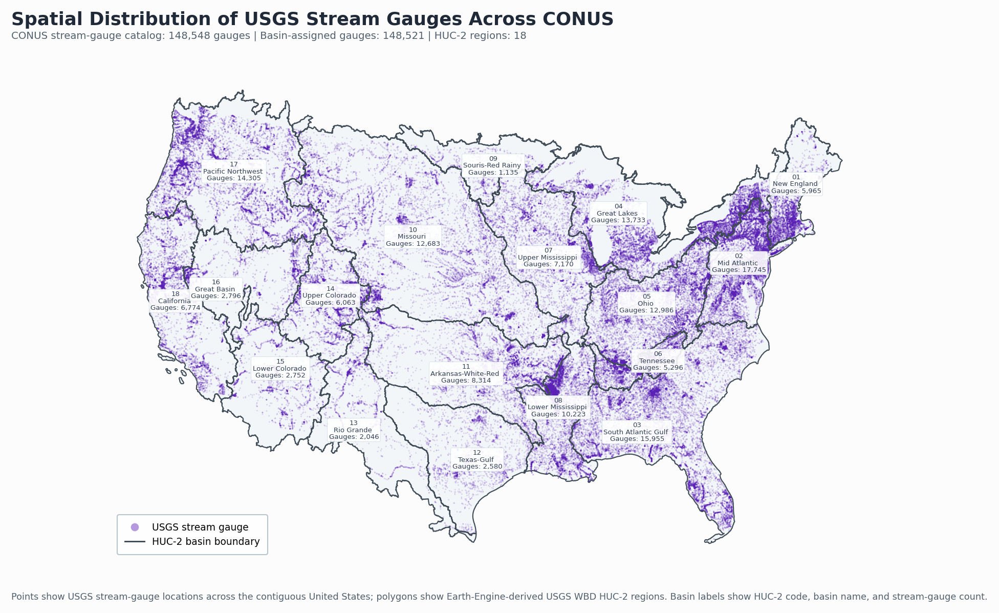

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/stream_gauges_conus_map_revised.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/stream_gauges_conus_map_revised.pdf
Total stream gauges plotted: 148,548
Gauges assigned to a HUC-2 basin: 148,521

Basin-wise stream-gauge counts:
huc2  gauge_count
  01         5965
  02        17745
  03        15955
  04        13733
  05        12986
  06         5296
  07         7170
  08        10223
  09         1135
  10        12683
  11         8314
  12         2580
  13         2046
  14         6063
  15         2752
  16         2796
  17        14305
  18         6774


In [ ]:
# ============================================================
# Publication-quality map of USGS stream gauge distribution across CONUS
# with basin-wise stream-gauge counts
# Revised styling for better visual contrast and less dull appearance
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
STREAM_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/stream_gauge_metadata/usgs_stream_gauges_conus_metadata.csv"
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PNG = os.path.join(OUTPUT_DIR, "stream_gauges_conus_map_revised.png")
OUTPUT_PDF = os.path.join(OUTPUT_DIR, "stream_gauges_conus_map_revised.pdf")

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#f3f6f8"
BASIN_EDGE = "#7d8994"
BOUNDARY_COLOR = "#3f4b56"
POINT_COLOR = "#5b21b6"
POINT_EDGE = "none"
TEXT_COLOR = "#1f2937"
MUTED_TEXT = "#52606d"
LABEL_TEXT = "#334155"
FRAME_COLOR = "#b8c1c8"

# ------------------------------------------------------------
# 3. Load data
# ------------------------------------------------------------
gauges = pd.read_csv(STREAM_FILE, low_memory=False)
basins = gpd.read_file(BASIN_FILE)

required_cols = ["monitoring_location_id", "latitude", "longitude"]
missing_cols = [c for c in required_cols if c not in gauges.columns]
if missing_cols:
    raise KeyError(f"Missing required columns in stream-gauge file: {missing_cols}")

gauges = gauges[[
    "monitoring_location_id",
    "monitoring_location_number",
    "monitoring_location_name",
    "state_code",
    "latitude",
    "longitude"
]].copy()

# Clean coordinates
gauges["latitude"] = pd.to_numeric(gauges["latitude"], errors="coerce")
gauges["longitude"] = pd.to_numeric(gauges["longitude"], errors="coerce")
gauges = gauges.dropna(subset=["latitude", "longitude"]).copy()

# Optional CONUS filter
gauges = gauges[
    gauges["latitude"].between(24, 50) &
    gauges["longitude"].between(-125, -66.5)
].copy()

# Remove duplicate gauges
gauges = gauges.drop_duplicates(subset=["monitoring_location_id"]).copy()

# Create GeoDataFrame
gauges_gdf = gpd.GeoDataFrame(
    gauges,
    geometry=gpd.points_from_xy(gauges["longitude"], gauges["latitude"]),
    crs="EPSG:4326"
)

# ------------------------------------------------------------
# 4. Prepare basin data
# ------------------------------------------------------------
if "huc2" not in basins.columns:
    raise KeyError(
        f"'huc2' column not found in basin file. Available columns: {basins.columns.tolist()}"
    )

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[
    basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])
].copy()

basins["geometry"] = basins.geometry.make_valid()

# If basin-name field differs by capitalization, fix it here
if "name" not in basins.columns:
    if "NAME" in basins.columns:
        basins = basins.rename(columns={"NAME": "name"})
    else:
        raise KeyError(
            f"No basin-name column found. Available columns: {basins.columns.tolist()}"
        )

# ------------------------------------------------------------
# 5. Spatial join for basin-wise counts
# ------------------------------------------------------------
gauges_with_basin = gpd.sjoin(
    gauges_gdf,
    basins[["huc2", "name", "geometry"]],
    how="left",
    predicate="within"
)

total_gauges = len(gauges_gdf)
mapped_gauges = gauges_with_basin["huc2"].notna().sum()

gauge_counts = (
    gauges_with_basin
    .dropna(subset=["huc2"])
    .groupby("huc2")["monitoring_location_id"]
    .nunique()
    .reset_index(name="gauge_count")
)

basins = basins.merge(gauge_counts, on="huc2", how="left")
basins["gauge_count"] = basins["gauge_count"].fillna(0).astype(int)

# ------------------------------------------------------------
# 6. Reproject to CONUS equal-area CRS
# ------------------------------------------------------------
MAP_CRS = "EPSG:5070"

basins_proj = basins.to_crs(MAP_CRS)
gauges_proj = gauges_gdf.to_crs(MAP_CRS)

# ------------------------------------------------------------
# 7. Plot setup
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 8.2))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# Basin polygons
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.65,
    zorder=1
)

# Stream-gauge points
gauges_proj.plot(
    ax=ax,
    markersize=2.0,
    color=POINT_COLOR,
    edgecolor="none",
    alpha=0.16,
    linewidth=0,
    rasterized=True,
    zorder=3
)

# Basin boundaries above points
basins_proj.boundary.plot(
    ax=ax,
    color=BOUNDARY_COLOR,
    linewidth=1.05,
    alpha=0.95,
    zorder=4
)

# ------------------------------------------------------------
# 8. Basin labels
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["label_point"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

for _, row in label_basins.iterrows():
    x, y = row["label_point"].x, row["label_point"].y
    label = (
        f'{row["huc2"]}\n'
        f'{row["short_name"]}\n'
        f'Gauges: {row["gauge_count"]:,}'
    )

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=6.4,
        fontweight="medium",
        color=LABEL_TEXT,
        linespacing=1.05,
        zorder=5,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="#ffffff",
            edgecolor="#cbd5e1",
            linewidth=0.35,
            alpha=0.90
        )
    )

# ------------------------------------------------------------
# 9. Map extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.035
ypad = (ymax - ymin) * 0.035

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 10. Titles and metadata
# ------------------------------------------------------------
fig.suptitle(
    "Spatial Distribution of USGS Stream Gauges Across CONUS",
    x=0.07,
    y=0.965,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.07,
    0.934,
    f"CONUS stream-gauge catalog: {total_gauges:,} gauges | "
    f"Basin-assigned gauges: {mapped_gauges:,} | "
    f"HUC-2 regions: {len(basins)}",
    ha="left",
    va="top",
    fontsize=9.5,
    color=MUTED_TEXT
)

fig.text(
    0.07,
    0.028,
    "Points show USGS stream-gauge locations across the contiguous United States; "
    "polygons show Earth-Engine-derived USGS WBD HUC-2 regions. "
    "Basin labels show HUC-2 code, basin name, and stream-gauge count.",
    ha="left",
    va="bottom",
    fontsize=8.5,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 11. Legend
# ------------------------------------------------------------
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        label="USGS stream gauge",
        markerfacecolor=POINT_COLOR,
        markeredgecolor="none",
        markersize=7.5,
        alpha=0.45
    ),
    Line2D(
        [0], [0],
        color=BOUNDARY_COLOR,
        lw=1.4,
        label="HUC-2 basin boundary"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.96,
    fontsize=9,
    borderpad=0.8
)

# ------------------------------------------------------------
# 12. Clean axes
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.055,
    right=0.975,
    bottom=0.095,
    top=0.865
)

# ------------------------------------------------------------
# 13. Save figure
# ------------------------------------------------------------
plt.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    OUTPUT_PDF,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved:")
print(OUTPUT_PNG)
print(OUTPUT_PDF)
print(f"Total stream gauges plotted: {total_gauges:,}")
print(f"Gauges assigned to a HUC-2 basin: {mapped_gauges:,}")
print("\nBasin-wise stream-gauge counts:")
print(gauge_counts.sort_values("huc2").to_string(index=False))

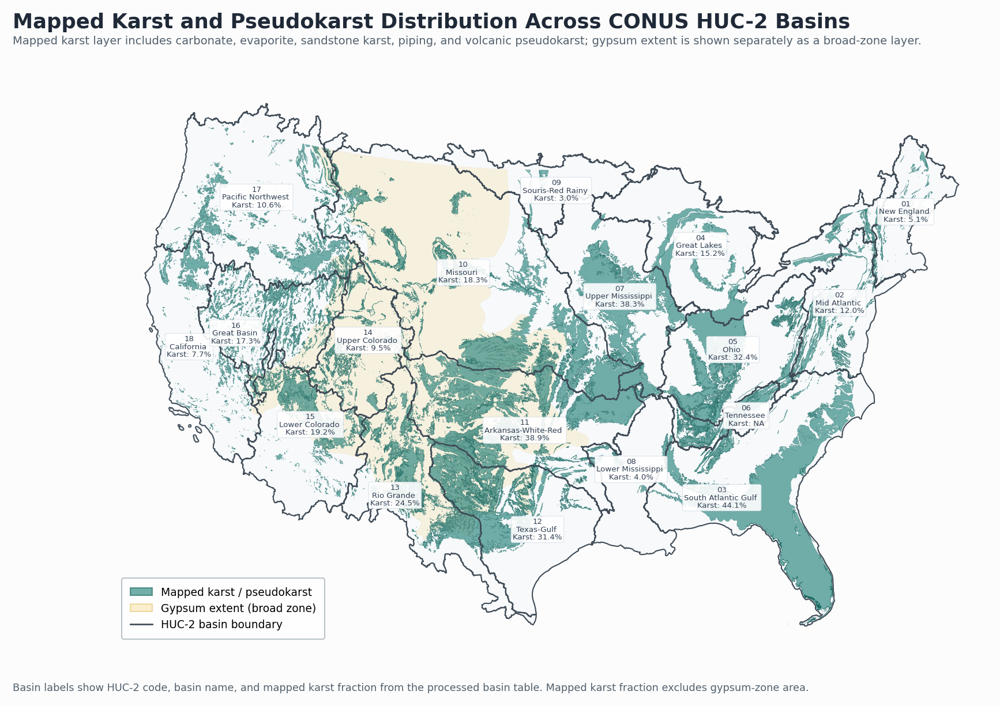

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/karst_huc2_conus_map.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/karst_huc2_conus_map.pdf

Mapped karst fractions by basin (excluding gypsum):
huc2                       name  mapped_karst_fraction  gypsum_zone_fraction
  01         New England Region               0.051217              0.000000
  02        Mid Atlantic Region               0.119884              0.000000
  03 South Atlantic-Gulf Region               0.440606              0.000000
  04         Great Lakes Region               0.152337              0.000000
  05                Ohio Region               0.323770              0.000000
  07   Upper Mississippi Region               0.383021              0.000000
  08   Lower Mississippi Region               0.039506              0.000056
  09    Souris-Red-Rainy Region               0.030123              0.119157
  10            Missouri Region               0.182799              0.656816
  11  Ar

In [ ]:
# ============================================================
# Publication-quality CONUS karst map on HUC-2 basins
# Includes:
#   - mapped karst + pseudokarst polygons
#   - gypsum extent as separate broad-zone overlay
#   - basin-wise mapped karst fraction labels (excluding gypsum)
# ============================================================

import os
import warnings
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"
KARST_DIR = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/USKarstMap/Shapefiles/Continguous48"
KARST_FRACTION_FILE = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_karst_fraction_with_pseudokarst.csv"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PNG = os.path.join(OUTPUT_DIR, "karst_huc2_conus_map.png")
OUTPUT_PDF = os.path.join(OUTPUT_DIR, "karst_huc2_conus_map.pdf")

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#f7f9fb"
BASIN_EDGE = "#7d8994"
BOUNDARY_COLOR = "#3f4b56"

KARST_FACE = "#0f766e"       # mapped karst / pseudokarst
KARST_EDGE = "#0b5d56"

GYPSUM_FACE = "#f4c95d"      # broad gypsum extent
GYPSUM_EDGE = "#c99700"

TEXT_COLOR = "#1f2937"
MUTED_TEXT = "#52606d"
LABEL_TEXT = "#334155"
FRAME_COLOR = "#b8c1c8"

MAP_CRS = "EPSG:5070"

# ------------------------------------------------------------
# 3. Load HUC-2 basins
# ------------------------------------------------------------
basins = gpd.read_file(BASIN_FILE)

if "huc2" not in basins.columns:
    raise KeyError(f"'huc2' not found in basin file. Columns: {basins.columns.tolist()}")

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])].copy()
basins["geometry"] = basins.geometry.make_valid()

if "name" not in basins.columns:
    if "NAME" in basins.columns:
        basins = basins.rename(columns={"NAME": "name"})
    else:
        raise KeyError(f"No basin-name column found. Columns: {basins.columns.tolist()}")

basins_proj = basins.to_crs(MAP_CRS)

# ------------------------------------------------------------
# 4. Load karst fraction summary table
# ------------------------------------------------------------
frac = pd.read_csv(KARST_FRACTION_FILE)

required_frac_cols = [
    "huc2",
    "name",
    "basin_area_km2",
    "mapped_karst_fraction",
    "gypsum_zone_fraction"
]
missing_frac = [c for c in required_frac_cols if c not in frac.columns]
if missing_frac:
    raise KeyError(f"Missing expected columns in karst fraction file: {missing_frac}")

frac["huc2"] = frac["huc2"].astype(str).str.zfill(2)
frac["mapped_karst_fraction"] = pd.to_numeric(frac["mapped_karst_fraction"], errors="coerce")
frac["gypsum_zone_fraction"] = pd.to_numeric(frac["gypsum_zone_fraction"], errors="coerce")

basins_proj = basins_proj.merge(
    frac[["huc2", "mapped_karst_fraction", "gypsum_zone_fraction"]],
    on="huc2",
    how="left"
)

# ------------------------------------------------------------
# 5. Load and combine karst shapefiles
#    mapped karst excludes gypsum
# ------------------------------------------------------------
mapped_karst_files = [
    "Carbonates48.shp",
    "Evaporites48.shp",
    "SandstoneKarst48.shp",
    "Piping48.shp",
    "Volcanics48.shp"
]

karst_parts = []
for shp in mapped_karst_files:
    shp_path = os.path.join(KARST_DIR, shp)
    if not os.path.exists(shp_path):
        raise FileNotFoundError(f"Missing shapefile: {shp_path}")
    gdf = gpd.read_file(shp_path)
    if gdf.crs is None:
        gdf = gdf.set_crs("EPSG:4326")
    gdf = gdf.to_crs(MAP_CRS)
    gdf = gdf[gdf.geometry.notna()].copy()
    gdf["geometry"] = gdf.geometry.make_valid()
    gdf["source_layer"] = shp
    karst_parts.append(gdf[["source_layer", "geometry"]])

mapped_karst = pd.concat(karst_parts, ignore_index=True)
mapped_karst = gpd.GeoDataFrame(mapped_karst, geometry="geometry", crs=MAP_CRS)
mapped_karst = mapped_karst[mapped_karst.geometry.notna()].copy()

# Dissolve into one mapped-karst layer
mapped_karst["dissolve_key"] = 1
mapped_karst_union = mapped_karst.dissolve(by="dissolve_key").reset_index(drop=True)
mapped_karst_union["geometry"] = mapped_karst_union.geometry.make_valid()

# ------------------------------------------------------------
# 6. Load gypsum extent separately
# ------------------------------------------------------------
gypsum_path = os.path.join(KARST_DIR, "GypsumExtent.shp")
if not os.path.exists(gypsum_path):
    raise FileNotFoundError(f"Missing gypsum shapefile: {gypsum_path}")

gypsum = gpd.read_file(gypsum_path)
if gypsum.crs is None:
    gypsum = gypsum.set_crs("EPSG:4326")
gypsum = gypsum.to_crs(MAP_CRS)
gypsum = gypsum[gypsum.geometry.notna()].copy()
gypsum["geometry"] = gypsum.geometry.make_valid()

# ------------------------------------------------------------
# 7. Prepare label names
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["label_point"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

# ------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 8.4))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# Basins background
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.7,
    zorder=1
)

# Gypsum broad-zone overlay first
gypsum.plot(
    ax=ax,
    facecolor=GYPSUM_FACE,
    edgecolor=GYPSUM_EDGE,
    linewidth=0.15,
    alpha=0.18,
    zorder=2
)

# Mapped karst overlay above gypsum
mapped_karst_union.plot(
    ax=ax,
    facecolor=KARST_FACE,
    edgecolor=KARST_EDGE,
    linewidth=0.20,
    alpha=0.58,
    zorder=3
)

# Basin boundaries on top
basins_proj.boundary.plot(
    ax=ax,
    color=BOUNDARY_COLOR,
    linewidth=1.0,
    alpha=0.95,
    zorder=4
)

# ------------------------------------------------------------
# 9. Basin labels with mapped karst fraction (excluding gypsum)
# ------------------------------------------------------------
for _, row in label_basins.iterrows():
    x, y = row["label_point"].x, row["label_point"].y

    karst_frac = row["mapped_karst_fraction"]
    karst_pct = f"{karst_frac * 100:.1f}%" if pd.notna(karst_frac) else "NA"

    label = (
        f'{row["huc2"]}\n'
        f'{row["short_name"]}\n'
        f'Karst: {karst_pct}'
    )

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=6.4,
        fontweight="medium",
        color=LABEL_TEXT,
        linespacing=1.05,
        zorder=5,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="#cbd5e1",
            linewidth=0.35,
            alpha=0.90
        )
    )

# ------------------------------------------------------------
# 10. Extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.035
ypad = (ymax - ymin) * 0.035

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 11. Titles and notes
# ------------------------------------------------------------
fig.suptitle(
    "Mapped Karst and Pseudokarst Distribution Across CONUS HUC-2 Basins",
    x=0.07,
    y=0.965,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.07,
    0.934,
    "Mapped karst layer includes carbonate, evaporite, sandstone karst, piping, and volcanic pseudokarst; "
    "gypsum extent is shown separately as a broad-zone layer.",
    ha="left",
    va="top",
    fontsize=9.4,
    color=MUTED_TEXT
)

fig.text(
    0.07,
    0.028,
    "Basin labels show HUC-2 code, basin name, and mapped karst fraction from the processed basin table. "
    "Mapped karst fraction excludes gypsum-zone area.",
    ha="left",
    va="bottom",
    fontsize=8.5,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 12. Legend
# ------------------------------------------------------------
legend_elements = [
    Patch(
        facecolor=KARST_FACE,
        edgecolor=KARST_EDGE,
        label="Mapped karst / pseudokarst",
        alpha=0.58
    ),
    Patch(
        facecolor=GYPSUM_FACE,
        edgecolor=GYPSUM_EDGE,
        label="Gypsum extent (broad zone)",
        alpha=0.30
    ),
    Line2D(
        [0], [0],
        color=BOUNDARY_COLOR,
        lw=1.3,
        label="HUC-2 basin boundary"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.97,
    fontsize=9,
    borderpad=0.8
)

# ------------------------------------------------------------
# 13. Final cleanup
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.055,
    right=0.975,
    bottom=0.095,
    top=0.865
)

# ------------------------------------------------------------
# 14. Save
# ------------------------------------------------------------
plt.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    OUTPUT_PDF,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved:")
print(OUTPUT_PNG)
print(OUTPUT_PDF)

print("\nMapped karst fractions by basin (excluding gypsum):")
print(
    frac[["huc2", "name", "mapped_karst_fraction", "gypsum_zone_fraction"]]
    .sort_values("huc2")
    .to_string(index=False)
)

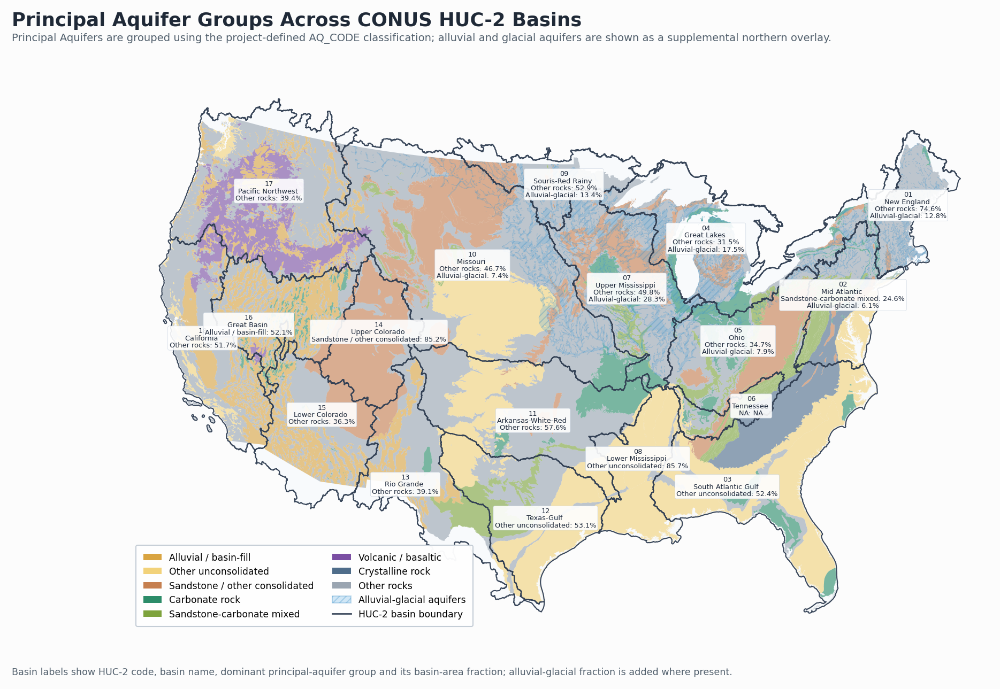

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/principal_aquifer_huc2_conus_map.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/principal_aquifer_huc2_conus_map.pdf

Dominant aquifer summary by basin:
huc2                       name           dominant_group_label  dominant_group_fraction  alluvial_glacial_aquifer_fraction
  01         New England Region                    Other rocks                 0.745761                           0.128279
  02        Mid Atlantic Region      Sandstone-carbonate mixed                 0.246380                           0.061248
  03 South Atlantic-Gulf Region           Other unconsolidated                 0.524286                           0.000000
  04         Great Lakes Region                    Other rocks                 0.315081                           0.174908
  05                Ohio Region                    Other rocks                 0.346658                           0.078757
  07   Upper Mississippi Region  

In [ ]:
# ============================================================
# Publication-quality CONUS principal aquifer map on HUC-2 basins
# Includes:
#   - Principal Aquifers polygons grouped into custom aquifer classes
#   - Alluvial and Glacial Aquifers as separate overlay
#   - Basin labels with dominant aquifer group and fractions
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"

PA_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Principal Aquifers of the 48 Conterminous United States, Hawaii, Puerto Rico, and the U.S. Virgin Islands/aquifers_us/us_aquifers.shp"
AG_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Alluvial and Glacial Aquifers/alluvial_glacial_aq_shp/alluvial.shp"

AQUIFER_FRACTION_FILE = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_aquifer_fractions_step1.csv"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PNG = os.path.join(OUTPUT_DIR, "principal_aquifer_huc2_conus_map.png")
OUTPUT_PDF = os.path.join(OUTPUT_DIR, "principal_aquifer_huc2_conus_map.pdf")

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#f8fafc"
BASIN_EDGE = "#88939d"
BOUNDARY_COLOR = "#334155"
TEXT_COLOR = "#1f2937"
MUTED_TEXT = "#52606d"
LABEL_TEXT = "#1e293b"
FRAME_COLOR = "#c3ccd5"

MAP_CRS = "EPSG:5070"

# ------------------------------------------------------------
# 3. Aquifer group definitions
# ------------------------------------------------------------
groups = {
    "alluvial_fan_basin_fill": [101, 102, 104, 105, 106, 108, 115, 116, 117],
    "other_unconsolidated": [103, 107, 109, 110, 111, 112, 114, 201, 202, 203, 204, 205],
    "sandstone_other_consolidated": [301, 302, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316],
    "carbonate_rock_pure": [401, 402, 405, 406, 407, 410, 411, 412, 413, 414, 416, 417, 418, 419, 420],
    "sandstone_carbonate_mixed": [501, 502, 503, 504, 505],
    "volcanic_basaltic": [601, 606, 607, 608, 609, 610],
    "crystalline_rock": [611],
    "other_rocks": [999],
}

code_to_group = {code: grp for grp, codes in groups.items() for code in codes}

group_label_map = {
    "alluvial_fan_basin_fill": "Alluvial / basin-fill",
    "other_unconsolidated": "Other unconsolidated",
    "sandstone_other_consolidated": "Sandstone / other consolidated",
    "carbonate_rock_pure": "Carbonate rock",
    "sandstone_carbonate_mixed": "Sandstone-carbonate mixed",
    "volcanic_basaltic": "Volcanic / basaltic",
    "crystalline_rock": "Crystalline rock",
    "other_rocks": "Other rocks",
}

group_color_map = {
    "alluvial_fan_basin_fill": "#d9a441",
    "other_unconsolidated": "#f2d27a",
    "sandstone_other_consolidated": "#c67f4f",
    "carbonate_rock_pure": "#2c8c69",
    "sandstone_carbonate_mixed": "#7ea33c",
    "volcanic_basaltic": "#7b4fa3",
    "crystalline_rock": "#4f6d8a",
    "other_rocks": "#9aa5b1",
}

fraction_cols = [
    "alluvial_fan_basin_fill_fraction",
    "other_unconsolidated_fraction",
    "sandstone_other_consolidated_fraction",
    "carbonate_rock_pure_fraction",
    "sandstone_carbonate_mixed_fraction",
    "volcanic_basaltic_fraction",
    "crystalline_rock_fraction",
    "other_rocks_fraction",
]

fraction_to_group = {
    "alluvial_fan_basin_fill_fraction": "alluvial_fan_basin_fill",
    "other_unconsolidated_fraction": "other_unconsolidated",
    "sandstone_other_consolidated_fraction": "sandstone_other_consolidated",
    "carbonate_rock_pure_fraction": "carbonate_rock_pure",
    "sandstone_carbonate_mixed_fraction": "sandstone_carbonate_mixed",
    "volcanic_basaltic_fraction": "volcanic_basaltic",
    "crystalline_rock_fraction": "crystalline_rock",
    "other_rocks_fraction": "other_rocks",
}

# ------------------------------------------------------------
# 4. Load HUC-2 basins
# ------------------------------------------------------------
basins = gpd.read_file(BASIN_FILE)

if "huc2" not in basins.columns:
    raise KeyError(f"'huc2' not found in basin file. Columns: {basins.columns.tolist()}")

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])].copy()
basins["geometry"] = basins.geometry.make_valid()

if "name" not in basins.columns:
    if "NAME" in basins.columns:
        basins = basins.rename(columns={"NAME": "name"})
    else:
        raise KeyError(f"No basin-name column found. Columns: {basins.columns.tolist()}")

basins_proj = basins.to_crs(MAP_CRS)

# ------------------------------------------------------------
# 5. Load processed aquifer-fraction table
# ------------------------------------------------------------
aq = pd.read_csv(AQUIFER_FRACTION_FILE)

required_aq_cols = [
    "huc2", "name", "basin_area_km2",
    "alluvial_fan_basin_fill_fraction",
    "other_unconsolidated_fraction",
    "sandstone_other_consolidated_fraction",
    "carbonate_rock_pure_fraction",
    "sandstone_carbonate_mixed_fraction",
    "volcanic_basaltic_fraction",
    "crystalline_rock_fraction",
    "other_rocks_fraction",
    "alluvial_glacial_aquifer_fraction",
]

missing_aq = [c for c in required_aq_cols if c not in aq.columns]
if missing_aq:
    raise KeyError(f"Missing expected columns in aquifer fraction file: {missing_aq}")

aq["huc2"] = aq["huc2"].astype(str).str.zfill(2)

for col in required_aq_cols[3:]:
    aq[col] = pd.to_numeric(aq[col], errors="coerce")

# Determine dominant principal aquifer group safely
aq["dominant_fraction_col"] = aq[fraction_cols].idxmax(axis=1)
aq["dominant_group_key"] = aq["dominant_fraction_col"].map(fraction_to_group)
aq["dominant_group_label"] = aq["dominant_group_key"].map(group_label_map)
aq["dominant_group_fraction"] = aq.apply(
    lambda row: row[row["dominant_fraction_col"]] if pd.notna(row["dominant_fraction_col"]) else np.nan,
    axis=1
)

basins_proj = basins_proj.merge(
    aq[[
        "huc2",
        "dominant_group_key",
        "dominant_group_label",
        "dominant_group_fraction",
        "alluvial_glacial_aquifer_fraction"
    ]],
    on="huc2",
    how="left"
)

# ------------------------------------------------------------
# 6. Load and process Principal Aquifers polygons
# ------------------------------------------------------------
pa = gpd.read_file(PA_FILE)

required_pa_cols = ["AQ_CODE", "geometry"]
missing_pa = [c for c in required_pa_cols if c not in pa.columns]
if missing_pa:
    raise KeyError(f"Missing expected columns in principal aquifer file: {missing_pa}")

if pa.crs is None:
    pa = pa.set_crs("EPSG:4269")

pa = pa.to_crs(MAP_CRS)
pa = pa[pa.geometry.notna()].copy()
pa["geometry"] = pa.geometry.make_valid()

pa["AQ_CODE"] = pd.to_numeric(pa["AQ_CODE"], errors="coerce")
pa["aq_group"] = pa["AQ_CODE"].map(code_to_group)
pa = pa[pa["aq_group"].notna()].copy()

# Clip to HUC-2 footprint
pa = gpd.overlay(
    pa[["AQ_CODE", "aq_group", "geometry"]],
    basins_proj[["geometry"]],
    how="intersection"
)

# ------------------------------------------------------------
# 7. Load and process Alluvial and Glacial Aquifers overlay
# ------------------------------------------------------------
ag = gpd.read_file(AG_FILE)

if ag.crs is None:
    ag = ag.set_crs("EPSG:4269")

ag = ag.to_crs(MAP_CRS)
ag = ag[ag.geometry.notna()].copy()
ag["geometry"] = ag.geometry.make_valid()

if "AQ_CODE" in ag.columns:
    ag["AQ_CODE"] = pd.to_numeric(ag["AQ_CODE"], errors="coerce")
    ag = ag[ag["AQ_CODE"] == 113].copy()

ag = gpd.overlay(
    ag[["geometry"]],
    basins_proj[["geometry"]],
    how="intersection"
)

# ------------------------------------------------------------
# 8. Prepare label names
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["label_point"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

# ------------------------------------------------------------
# 9. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 8.8))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# Basin background
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.55,
    zorder=1
)

# Plot principal aquifer polygons by group
plot_order = [
    "other_rocks",
    "other_unconsolidated",
    "alluvial_fan_basin_fill",
    "sandstone_other_consolidated",
    "sandstone_carbonate_mixed",
    "carbonate_rock_pure",
    "crystalline_rock",
    "volcanic_basaltic",
]

for grp in plot_order:
    subset = pa[pa["aq_group"] == grp]
    if len(subset) == 0:
        continue
    subset.plot(
        ax=ax,
        facecolor=group_color_map[grp],
        edgecolor="none",
        alpha=0.62,
        zorder=2
    )

# Plot alluvial-glacial aquifers overlay
if len(ag) > 0:
    ag.plot(
        ax=ax,
        facecolor="#5dade2",
        edgecolor="#2e86c1",
        linewidth=0.15,
        alpha=0.28,
        hatch="////",
        zorder=3
    )

# Basin boundaries
basins_proj.boundary.plot(
    ax=ax,
    color=BOUNDARY_COLOR,
    linewidth=1.0,
    alpha=0.95,
    zorder=4
)

# ------------------------------------------------------------
# 10. Basin labels
# ------------------------------------------------------------
for _, row in label_basins.iterrows():
    x, y = row["label_point"].x, row["label_point"].y

    group_label = row["dominant_group_label"] if pd.notna(row["dominant_group_label"]) else "NA"
    dom_frac = row["dominant_group_fraction"]
    ag_frac = row["alluvial_glacial_aquifer_fraction"]

    dom_pct = f"{dom_frac * 100:.1f}%" if pd.notna(dom_frac) else "NA"
    ag_pct = f"{ag_frac * 100:.1f}%" if pd.notna(ag_frac) else None

    label = (
        f'{row["huc2"]}\n'
        f'{row["short_name"]}\n'
        f'{group_label}: {dom_pct}'
    )

    if pd.notna(ag_frac) and ag_frac > 0:
        label += f'\nAlluvial-glacial: {ag_pct}'

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=6.2,
        fontweight="medium",
        color=LABEL_TEXT,
        linespacing=1.03,
        zorder=5,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="#cbd5e1",
            linewidth=0.35,
            alpha=0.90
        )
    )

# ------------------------------------------------------------
# 11. Extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.035
ypad = (ymax - ymin) * 0.035

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 12. Titles and notes
# ------------------------------------------------------------
fig.suptitle(
    "Principal Aquifer Groups Across CONUS HUC-2 Basins",
    x=0.06,
    y=0.968,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.06,
    0.938,
    "Principal Aquifers are grouped using the project-defined AQ_CODE classification; "
    "alluvial and glacial aquifers are shown as a supplemental northern overlay.",
    ha="left",
    va="top",
    fontsize=9.4,
    color=MUTED_TEXT
)

fig.text(
    0.06,
    0.025,
    "Basin labels show HUC-2 code, basin name, dominant principal-aquifer group and its basin-area fraction; "
    "alluvial-glacial fraction is added where present.",
    ha="left",
    va="bottom",
    fontsize=8.4,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 13. Legend
# ------------------------------------------------------------
legend_elements = [
    Patch(facecolor=group_color_map["alluvial_fan_basin_fill"], edgecolor="none", label="Alluvial / basin-fill"),
    Patch(facecolor=group_color_map["other_unconsolidated"], edgecolor="none", label="Other unconsolidated"),
    Patch(facecolor=group_color_map["sandstone_other_consolidated"], edgecolor="none", label="Sandstone / other consolidated"),
    Patch(facecolor=group_color_map["carbonate_rock_pure"], edgecolor="none", label="Carbonate rock"),
    Patch(facecolor=group_color_map["sandstone_carbonate_mixed"], edgecolor="none", label="Sandstone-carbonate mixed"),
    Patch(facecolor=group_color_map["volcanic_basaltic"], edgecolor="none", label="Volcanic / basaltic"),
    Patch(facecolor=group_color_map["crystalline_rock"], edgecolor="none", label="Crystalline rock"),
    Patch(facecolor=group_color_map["other_rocks"], edgecolor="none", label="Other rocks"),
    Patch(facecolor="#5dade2", edgecolor="#2e86c1", hatch="////", label="Alluvial-glacial aquifers", alpha=0.28),
    Line2D([0], [0], color=BOUNDARY_COLOR, lw=1.3, label="HUC-2 basin boundary")
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.97,
    fontsize=8.3,
    borderpad=0.8,
    ncol=2
)

# ------------------------------------------------------------
# 14. Clean up
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.045,
    right=0.985,
    bottom=0.09,
    top=0.87
)

# ------------------------------------------------------------
# 15. Save
# ------------------------------------------------------------
plt.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    OUTPUT_PDF,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved:")
print(OUTPUT_PNG)
print(OUTPUT_PDF)

print("\nDominant aquifer summary by basin:")
summary_cols = [
    "huc2",
    "name",
    "dominant_group_label",
    "dominant_group_fraction",
    "alluvial_glacial_aquifer_fraction"
]
print(
    aq[summary_cols]
    .sort_values("huc2")
    .to_string(index=False)
)

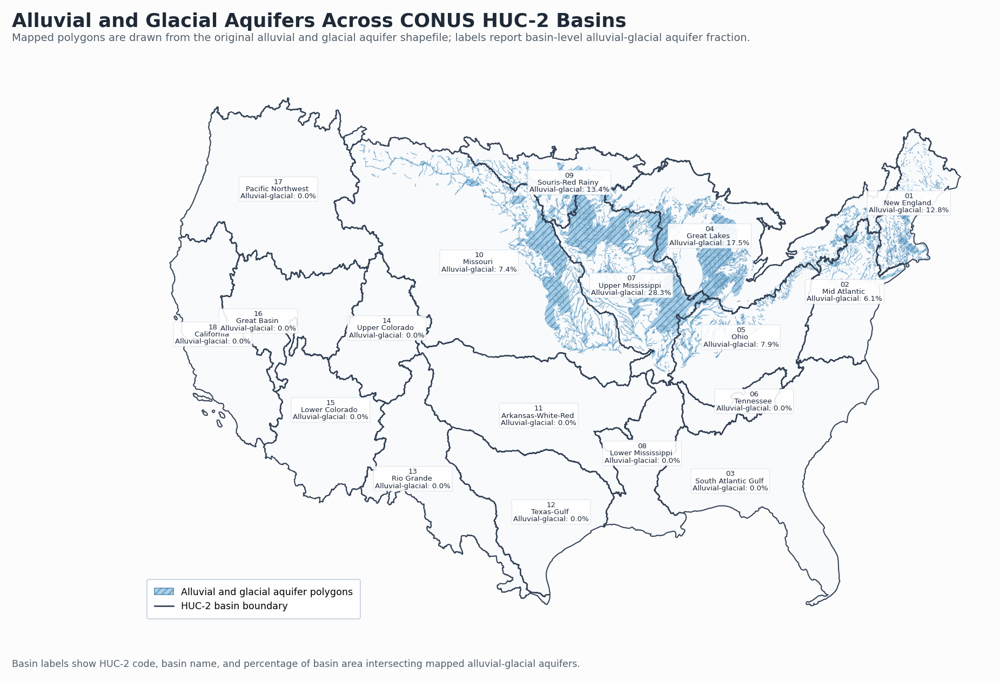

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/alluvial_glacial_aquifer_shapefile_huc2_map.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/alluvial_glacial_aquifer_shapefile_huc2_map.pdf

Basin values:
huc2                       name  alluvial_glacial_aquifer_fraction
  01         New England Region                             0.1283
  02        Mid Atlantic Region                             0.0612
  03 South Atlantic-Gulf Region                             0.0000
  04         Great Lakes Region                             0.1749
  05                Ohio Region                             0.0788
  06           Tennessee Region                             0.0000
  07   Upper Mississippi Region                             0.2829
  08   Lower Mississippi Region                             0.0000
  09    Souris-Red-Rainy Region                             0.1343
  10            Missouri Region                             0.0738
  11  Arkansas-White-Red Region  

In [ ]:
# ============================================================
# Publication-quality CONUS map of alluvial & glacial aquifers
# using the original shapefile geometry over HUC-2 basins
# Labels show basin-level alluvial_glacial_aquifer_fraction
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"
AG_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Alluvial and Glacial Aquifers/alluvial_glacial_aq_shp/alluvial.shp"
AQUIFER_FRACTION_FILE = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_aquifer_fractions_step1.csv"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PNG = os.path.join(OUTPUT_DIR, "alluvial_glacial_aquifer_shapefile_huc2_map.png")
OUTPUT_PDF = os.path.join(OUTPUT_DIR, "alluvial_glacial_aquifer_shapefile_huc2_map.pdf")

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#f8fafc"
BASIN_EDGE = "#88939d"
BOUNDARY_COLOR = "#334155"
TEXT_COLOR = "#1f2937"
MUTED_TEXT = "#52606d"
LABEL_TEXT = "#1e293b"
FRAME_COLOR = "#cbd5e1"

AG_FACE = "#6baed6"
AG_EDGE = "#2b6c9e"

MAP_CRS = "EPSG:5070"

# ------------------------------------------------------------
# 3. Load HUC-2 basins
# ------------------------------------------------------------
basins = gpd.read_file(BASIN_FILE)

if "huc2" not in basins.columns:
    raise KeyError(f"'huc2' not found in basin file. Columns: {basins.columns.tolist()}")

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])].copy()
basins["geometry"] = basins.geometry.make_valid()

if "name" not in basins.columns:
    if "NAME" in basins.columns:
        basins = basins.rename(columns={"NAME": "name"})
    else:
        raise KeyError(f"No basin-name column found. Columns: {basins.columns.tolist()}")

basins_proj = basins.to_crs(MAP_CRS)

# ------------------------------------------------------------
# 4. Load basin-level alluvial-glacial fractions
# ------------------------------------------------------------
aq = pd.read_csv(AQUIFER_FRACTION_FILE)

required_cols = ["huc2", "name", "alluvial_glacial_aquifer_fraction"]
missing = [c for c in required_cols if c not in aq.columns]
if missing:
    raise KeyError(f"Missing expected columns in aquifer fraction file: {missing}")

aq["huc2"] = aq["huc2"].astype(str).str.zfill(2)
aq["alluvial_glacial_aquifer_fraction"] = pd.to_numeric(
    aq["alluvial_glacial_aquifer_fraction"], errors="coerce"
)

basins_proj = basins_proj.merge(
    aq[["huc2", "alluvial_glacial_aquifer_fraction"]],
    on="huc2",
    how="left"
)

basins_proj["alluvial_glacial_aquifer_fraction"] = basins_proj["alluvial_glacial_aquifer_fraction"].fillna(0)

# ------------------------------------------------------------
# 5. Load and process alluvial-glacial aquifer shapefile
# ------------------------------------------------------------
ag = gpd.read_file(AG_FILE)

if ag.crs is None:
    ag = ag.set_crs("EPSG:4269")

ag = ag.to_crs(MAP_CRS)
ag = ag[ag.geometry.notna()].copy()
ag["geometry"] = ag.geometry.make_valid()

# keep the true alluvial-glacial aquifer polygons
if "AQCODE" in ag.columns:
    ag["AQCODE"] = pd.to_numeric(ag["AQCODE"], errors="coerce")
    ag = ag[ag["AQCODE"] == 113].copy()

# clip to CONUS HUC-2 extent
ag_clip = gpd.overlay(
    ag[["geometry"]],
    basins_proj[["geometry"]],
    how="intersection"
)

# ------------------------------------------------------------
# 6. Label positions
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["label_point"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

# ------------------------------------------------------------
# 7. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 8.6))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# basin background
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.55,
    zorder=1
)

# alluvial-glacial aquifer polygons from shapefile
if len(ag_clip) > 0:
    ag_clip.plot(
        ax=ax,
        facecolor=AG_FACE,
        edgecolor=AG_EDGE,
        linewidth=0.15,
        alpha=0.55,
        hatch="////",
        zorder=2
    )

# basin boundaries on top
basins_proj.boundary.plot(
    ax=ax,
    color=BOUNDARY_COLOR,
    linewidth=1.0,
    alpha=0.95,
    zorder=3
)

# ------------------------------------------------------------
# 8. Basin labels
# ------------------------------------------------------------
for _, row in label_basins.iterrows():
    x, y = row["label_point"].x, row["label_point"].y
    frac = row["alluvial_glacial_aquifer_fraction"]
    pct = frac * 100

    label = (
        f'{row["huc2"]}\n'
        f'{row["short_name"]}\n'
        f'Alluvial-glacial: {pct:.1f}%'
    )

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=6.4,
        fontweight="medium",
        color=LABEL_TEXT,
        linespacing=1.03,
        zorder=4,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="#cbd5e1",
            linewidth=0.35,
            alpha=0.90
        )
    )

# ------------------------------------------------------------
# 9. Extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.035
ypad = (ymax - ymin) * 0.035

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 10. Titles and notes
# ------------------------------------------------------------
fig.suptitle(
    "Alluvial and Glacial Aquifers Across CONUS HUC-2 Basins",
    x=0.06,
    y=0.968,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.06,
    0.938,
    "Mapped polygons are drawn from the original alluvial and glacial aquifer shapefile; "
    "labels report basin-level alluvial-glacial aquifer fraction.",
    ha="left",
    va="top",
    fontsize=9.4,
    color=MUTED_TEXT
)

fig.text(
    0.06,
    0.025,
    "Basin labels show HUC-2 code, basin name, and percentage of basin area intersecting mapped alluvial-glacial aquifers.",
    ha="left",
    va="bottom",
    fontsize=8.4,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 11. Legend
# ------------------------------------------------------------
legend_elements = [
    Patch(
        facecolor=AG_FACE,
        edgecolor=AG_EDGE,
        hatch="////",
        label="Alluvial and glacial aquifer polygons",
        alpha=0.55
    ),
    Line2D([0], [0], color=BOUNDARY_COLOR, lw=1.3, label="HUC-2 basin boundary")
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.97,
    fontsize=8.4,
    borderpad=0.8
)

# ------------------------------------------------------------
# 12. Clean up
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.045,
    right=0.985,
    bottom=0.09,
    top=0.87
)

# ------------------------------------------------------------
# 13. Save
# ------------------------------------------------------------
plt.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    OUTPUT_PDF,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved:")
print(OUTPUT_PNG)
print(OUTPUT_PDF)

print("\nBasin values:")
print(
    basins_proj[["huc2", "name", "alluvial_glacial_aquifer_fraction"]]
    .sort_values("huc2")
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

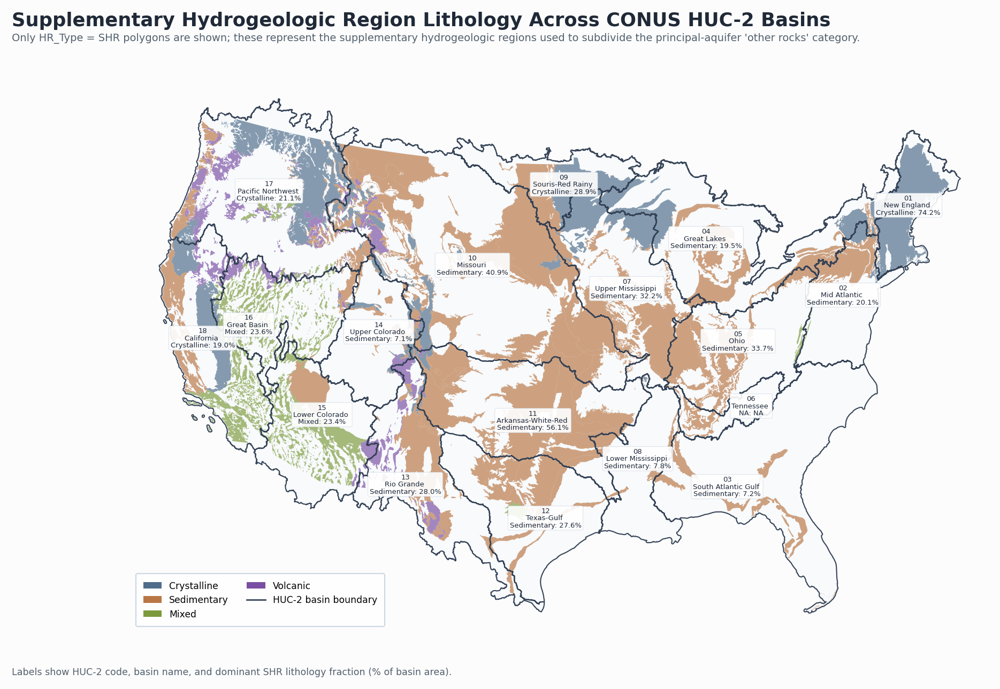

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/shr_hydrogeologic_regions_huc2_map.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/shr_hydrogeologic_regions_huc2_map.pdf

Dominant SHR lithology by basin:
huc2                       name dominant_group_label  dominant_group_fraction  shr_crystalline_fraction  shr_sedimentary_fraction  shr_mixed_fraction  shr_volcanic_fraction
  01         New England Region          Crystalline                   0.7423                    0.7423                    0.0035              0.0000                 0.0000
  02        Mid Atlantic Region          Sedimentary                   0.2007                    0.0405                    0.2007              0.0042                 0.0000
  03 South Atlantic-Gulf Region          Sedimentary                   0.0716                    0.0000                    0.0716              0.0000                 0.0000
  04         Great Lakes Region          Sedimentary                   0.1952

In [ ]:
# ============================================================
# Publication-quality CONUS map of SHR hydrogeologic regions
# plotted from the original Hydrogeologic Regions shapefile
# over HUC-2 basins
#
# SHR = supplementary hydrogeologic regions used to subdivide
# the PA-derived "other_rocks_fraction"
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"

HR_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Hydrogeologic regions of the conterminous United States/HydrogeologicRegions/HydrogeologicRegions.shp"

SHR_FRACTION_FILE = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_shr_lithology_fractions.csv"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PNG = os.path.join(OUTPUT_DIR, "shr_hydrogeologic_regions_huc2_map.png")
OUTPUT_PDF = os.path.join(OUTPUT_DIR, "shr_hydrogeologic_regions_huc2_map.pdf")

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#f8fafc"
BASIN_EDGE = "#88939d"
BOUNDARY_COLOR = "#334155"
TEXT_COLOR = "#1f2937"
MUTED_TEXT = "#52606d"
LABEL_TEXT = "#1e293b"
FRAME_COLOR = "#cbd5e1"

MAP_CRS = "EPSG:5070"

# SHR lithology colors
shr_color_map = {
    "shr_crystalline": "#4f6d8a",
    "shr_sedimentary": "#b97745",
    "shr_mixed": "#7c9a3d",
    "shr_volcanic": "#7a4fa3",
}

shr_label_map = {
    "shr_crystalline": "Crystalline",
    "shr_sedimentary": "Sedimentary",
    "shr_mixed": "Mixed",
    "shr_volcanic": "Volcanic",
}

# ------------------------------------------------------------
# 3. Load HUC-2 basins
# ------------------------------------------------------------
basins = gpd.read_file(BASIN_FILE)

if "huc2" not in basins.columns:
    raise KeyError(f"'huc2' not found in basin file. Columns: {basins.columns.tolist()}")

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])].copy()
basins["geometry"] = basins.geometry.make_valid()

if "name" not in basins.columns:
    if "NAME" in basins.columns:
        basins = basins.rename(columns={"NAME": "name"})
    else:
        raise KeyError(f"No basin-name column found. Columns: {basins.columns.tolist()}")

basins_proj = basins.to_crs(MAP_CRS)

# ------------------------------------------------------------
# 4. Load SHR fraction table
# ------------------------------------------------------------
shr_frac = pd.read_csv(SHR_FRACTION_FILE)

required_cols = [
    "huc2",
    "shr_crystalline_fraction",
    "shr_sedimentary_fraction",
    "shr_mixed_fraction",
    "shr_volcanic_fraction",
]

missing_cols = [c for c in required_cols if c not in shr_frac.columns]
if missing_cols:
    raise KeyError(f"Missing expected columns in SHR fraction file: {missing_cols}")

shr_frac["huc2"] = shr_frac["huc2"].astype(str).str.zfill(2)

for col in required_cols[1:]:
    shr_frac[col] = pd.to_numeric(shr_frac[col], errors="coerce").fillna(0)

fraction_cols = [
    "shr_crystalline_fraction",
    "shr_sedimentary_fraction",
    "shr_mixed_fraction",
    "shr_volcanic_fraction",
]

group_from_fraction_col = {
    "shr_crystalline_fraction": "shr_crystalline",
    "shr_sedimentary_fraction": "shr_sedimentary",
    "shr_mixed_fraction": "shr_mixed",
    "shr_volcanic_fraction": "shr_volcanic",
}

shr_frac["dominant_fraction_col"] = shr_frac[fraction_cols].idxmax(axis=1)
shr_frac["dominant_group_key"] = shr_frac["dominant_fraction_col"].map(group_from_fraction_col)
shr_frac["dominant_group_label"] = shr_frac["dominant_group_key"].map(shr_label_map)

shr_frac["dominant_group_fraction"] = shr_frac.apply(
    lambda row: row[row["dominant_fraction_col"]] if pd.notna(row["dominant_fraction_col"]) else np.nan,
    axis=1
)

basins_proj = basins_proj.merge(
    shr_frac[[
        "huc2",
        "dominant_group_key",
        "dominant_group_label",
        "dominant_group_fraction",
        "shr_crystalline_fraction",
        "shr_sedimentary_fraction",
        "shr_mixed_fraction",
        "shr_volcanic_fraction",
    ]],
    on="huc2",
    how="left"
)

# ------------------------------------------------------------
# 5. Load Hydrogeologic Regions shapefile and keep SHR only
# ------------------------------------------------------------
hr = gpd.read_file(HR_FILE)

required_hr_cols = ["HR_Type", "HR_Litholo", "geometry"]
missing_hr = [c for c in required_hr_cols if c not in hr.columns]
if missing_hr:
    raise KeyError(f"Missing expected columns in HR shapefile: {missing_hr}")

shr = hr[hr["HR_Type"] == "SHR"].copy()

if shr.crs is None:
    raise ValueError("HR shapefile CRS is missing.")

shr = shr.to_crs(MAP_CRS)
shr = shr[shr.geometry.notna()].copy()
shr["geometry"] = shr.geometry.make_valid()

# ------------------------------------------------------------
# 6. Group SHR polygons by lithology
# ------------------------------------------------------------
litholo_to_group = {
    "Crystalline": "shr_crystalline",
    "Sedimentary": "shr_sedimentary",
    "Mixed": "shr_mixed",
    "Volcanic": "shr_volcanic",
}

shr["group"] = shr["HR_Litholo"].map(litholo_to_group)
shr = shr[shr["group"].notna()].copy()

# Clip SHR polygons to HUC-2 extent
shr_clip = gpd.overlay(
    shr[["group", "geometry"]],
    basins_proj[["geometry"]],
    how="intersection"
)

# ------------------------------------------------------------
# 7. Label positions
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["label_point"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

# ------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 8.8))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# basin background
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.55,
    zorder=1
)

# plot SHR polygons by group
plot_order = [
    "shr_sedimentary",
    "shr_crystalline",
    "shr_mixed",
    "shr_volcanic",
]

for grp in plot_order:
    subset = shr_clip[shr_clip["group"] == grp]
    if len(subset) == 0:
        continue
    subset.plot(
        ax=ax,
        facecolor=shr_color_map[grp],
        edgecolor="none",
        alpha=0.68,
        zorder=2
    )

# basin boundaries on top
basins_proj.boundary.plot(
    ax=ax,
    color=BOUNDARY_COLOR,
    linewidth=1.0,
    alpha=0.95,
    zorder=3
)

# ------------------------------------------------------------
# 9. Basin labels
# ------------------------------------------------------------
for _, row in label_basins.iterrows():
    x, y = row["label_point"].x, row["label_point"].y

    dom_label = row["dominant_group_label"] if pd.notna(row["dominant_group_label"]) else "NA"
    dom_frac = row["dominant_group_fraction"]
    dom_pct = f"{dom_frac * 100:.1f}%" if pd.notna(dom_frac) else "NA"

    label = (
        f'{row["huc2"]}\n'
        f'{row["short_name"]}\n'
        f'{dom_label}: {dom_pct}'
    )

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=6.3,
        fontweight="medium",
        color=LABEL_TEXT,
        linespacing=1.03,
        zorder=4,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="#cbd5e1",
            linewidth=0.35,
            alpha=0.90
        )
    )

# ------------------------------------------------------------
# 10. Extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.035
ypad = (ymax - ymin) * 0.035

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 11. Titles and notes
# ------------------------------------------------------------
fig.suptitle(
    "Supplementary Hydrogeologic Region Lithology Across CONUS HUC-2 Basins",
    x=0.06,
    y=0.968,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.06,
    0.938,
    "Only HR_Type = SHR polygons are shown; these represent the supplementary hydrogeologic regions used to subdivide "
    "the principal-aquifer 'other rocks' category.",
    ha="left",
    va="top",
    fontsize=9.3,
    color=MUTED_TEXT
)

fig.text(
    0.06,
    0.025,
    "Labels show HUC-2 code, basin name, and dominant SHR lithology fraction (% of basin area).",
    ha="left",
    va="bottom",
    fontsize=8.4,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 12. Legend
# ------------------------------------------------------------
legend_elements = [
    Patch(facecolor=shr_color_map["shr_crystalline"], edgecolor="none", label="Crystalline"),
    Patch(facecolor=shr_color_map["shr_sedimentary"], edgecolor="none", label="Sedimentary"),
    Patch(facecolor=shr_color_map["shr_mixed"], edgecolor="none", label="Mixed"),
    Patch(facecolor=shr_color_map["shr_volcanic"], edgecolor="none", label="Volcanic"),
    Line2D([0], [0], color=BOUNDARY_COLOR, lw=1.3, label="HUC-2 basin boundary")
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.97,
    fontsize=8.3,
    borderpad=0.8,
    ncol=2
)

# ------------------------------------------------------------
# 13. Clean up
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.045,
    right=0.985,
    bottom=0.09,
    top=0.87
)

# ------------------------------------------------------------
# 14. Save
# ------------------------------------------------------------
plt.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    OUTPUT_PDF,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved:")
print(OUTPUT_PNG)
print(OUTPUT_PDF)

print("\nDominant SHR lithology by basin:")
summary_cols = [
    "huc2",
    "name",
    "dominant_group_label",
    "dominant_group_fraction",
    "shr_crystalline_fraction",
    "shr_sedimentary_fraction",
    "shr_mixed_fraction",
    "shr_volcanic_fraction",
]
print(
    basins_proj[summary_cols]
    .sort_values("huc2")
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

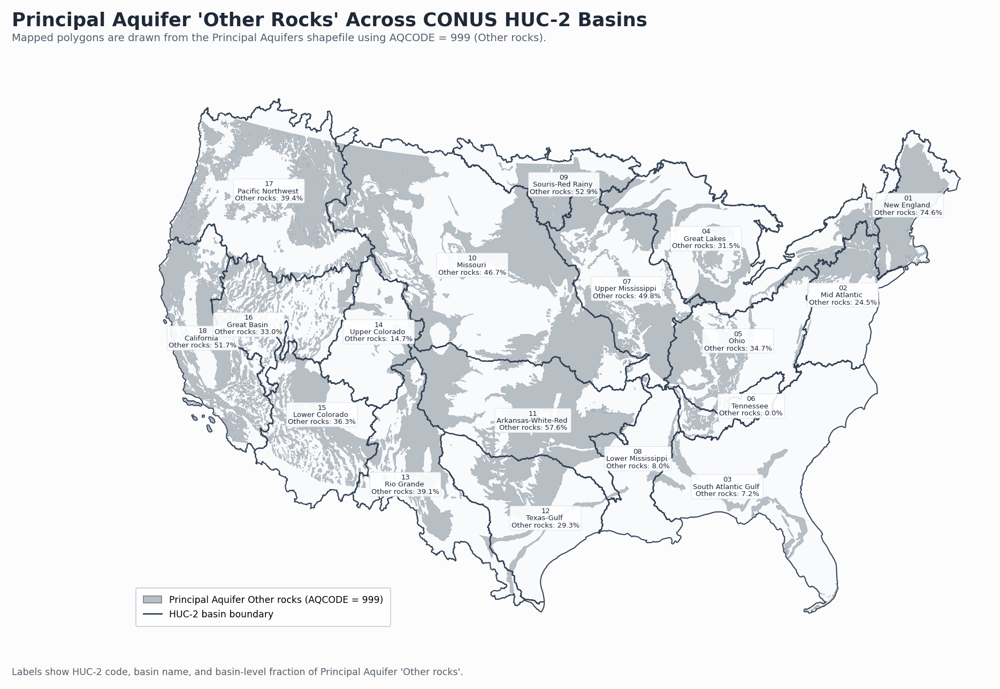

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/pa_other_rocks_huc2_map.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/pa_other_rocks_huc2_map.pdf

Basin values:
huc2                       name  other_rocks_fraction
  01         New England Region                0.7458
  02        Mid Atlantic Region                0.2454
  03 South Atlantic-Gulf Region                0.0716
  04         Great Lakes Region                0.3151
  05                Ohio Region                0.3467
  06           Tennessee Region                0.0000
  07   Upper Mississippi Region                0.4983
  08   Lower Mississippi Region                0.0801
  09    Souris-Red-Rainy Region                0.5293
  10            Missouri Region                0.4673
  11  Arkansas-White-Red Region                0.5765
  12          Texas-Gulf Region                0.2929
  13          Rio Grande Region                0.3915
  14      Upper Colorado Region                0.1475


In [ ]:
# ============================================================
# Publication-quality CONUS map of Principal Aquifer "Other rocks"
# (AQCODE = 999) over HUC-2 basins
# Labels show basin-level other_rocks_fraction
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"

PA_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Principal Aquifers of the 48 Conterminous United States, Hawaii, Puerto Rico, and the U.S. Virgin Islands/aquifers_us/us_aquifers.shp"

AQUIFER_FRACTION_FILE = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_aquifer_fractions_step1.csv"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PNG = os.path.join(OUTPUT_DIR, "pa_other_rocks_huc2_map.png")
OUTPUT_PDF = os.path.join(OUTPUT_DIR, "pa_other_rocks_huc2_map.pdf")

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#f8fafc"
BASIN_EDGE = "#88939d"
BOUNDARY_COLOR = "#334155"
TEXT_COLOR = "#1f2937"
MUTED_TEXT = "#52606d"
LABEL_TEXT = "#1e293b"
FRAME_COLOR = "#cbd5e1"

OTHER_ROCKS_FACE = "#8f99a3"
OTHER_ROCKS_EDGE = "#5b6672"

MAP_CRS = "EPSG:5070"

# ------------------------------------------------------------
# 3. Load HUC-2 basins
# ------------------------------------------------------------
basins = gpd.read_file(BASIN_FILE)

if "huc2" not in basins.columns:
    raise KeyError(f"'huc2' not found in basin file. Columns: {basins.columns.tolist()}")

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])].copy()
basins["geometry"] = basins.geometry.make_valid()

if "name" not in basins.columns:
    if "NAME" in basins.columns:
        basins = basins.rename(columns={"NAME": "name"})
    else:
        raise KeyError(f"No basin-name column found. Columns: {basins.columns.tolist()}")

basins_proj = basins.to_crs(MAP_CRS)

# ------------------------------------------------------------
# 4. Load basin-level aquifer fraction table
# ------------------------------------------------------------
aq = pd.read_csv(AQUIFER_FRACTION_FILE)

required_cols = ["huc2", "name", "other_rocks_fraction"]
missing = [c for c in required_cols if c not in aq.columns]
if missing:
    raise KeyError(f"Missing expected columns in aquifer fraction file: {missing}")

aq["huc2"] = aq["huc2"].astype(str).str.zfill(2)
aq["other_rocks_fraction"] = pd.to_numeric(aq["other_rocks_fraction"], errors="coerce").fillna(0)

basins_proj = basins_proj.merge(
    aq[["huc2", "other_rocks_fraction"]],
    on="huc2",
    how="left"
)

basins_proj["other_rocks_fraction"] = basins_proj["other_rocks_fraction"].fillna(0)

# ------------------------------------------------------------
# 5. Load Principal Aquifers shapefile and isolate "Other rocks"
# ------------------------------------------------------------
pa = gpd.read_file(PA_FILE)

required_pa_cols = ["AQ_CODE", "geometry"]
missing_pa = [c for c in required_pa_cols if c not in pa.columns]
if missing_pa:
    raise KeyError(f"Missing expected columns in principal aquifer file: {missing_pa}")

if pa.crs is None:
    pa = pa.set_crs("EPSG:4269")

pa = pa.to_crs(MAP_CRS)
pa = pa[pa.geometry.notna()].copy()
pa["geometry"] = pa.geometry.make_valid()

pa["AQ_CODE"] = pd.to_numeric(pa["AQ_CODE"], errors="coerce")

# Keep only AQCODE = 999 (Other rocks)
pa_other = pa[pa["AQ_CODE"] == 999].copy()

# Clip to HUC-2 footprint
pa_other_clip = gpd.overlay(
    pa_other[["geometry"]],
    basins_proj[["geometry"]],
    how="intersection"
)

# ------------------------------------------------------------
# 6. Label positions
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["label_point"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

# ------------------------------------------------------------
# 7. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 8.8))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# basin background
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.55,
    zorder=1
)

# other-rocks polygons from PA shapefile
if len(pa_other_clip) > 0:
    pa_other_clip.plot(
        ax=ax,
        facecolor=OTHER_ROCKS_FACE,
        edgecolor=OTHER_ROCKS_EDGE,
        linewidth=0.18,
        alpha=0.62,
        zorder=2
    )

# basin boundaries
basins_proj.boundary.plot(
    ax=ax,
    color=BOUNDARY_COLOR,
    linewidth=1.0,
    alpha=0.95,
    zorder=3
)

# ------------------------------------------------------------
# 8. Basin labels
# ------------------------------------------------------------
for _, row in label_basins.iterrows():
    x, y = row["label_point"].x, row["label_point"].y
    frac = row["other_rocks_fraction"]
    pct = frac * 100

    label = (
        f'{row["huc2"]}\n'
        f'{row["short_name"]}\n'
        f'Other rocks: {pct:.1f}%'
    )

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=6.3,
        fontweight="medium",
        color=LABEL_TEXT,
        linespacing=1.03,
        zorder=4,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="#cbd5e1",
            linewidth=0.35,
            alpha=0.90
        )
    )

# ------------------------------------------------------------
# 9. Extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.035
ypad = (ymax - ymin) * 0.035

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 10. Titles and notes
# ------------------------------------------------------------
fig.suptitle(
    "Principal Aquifer 'Other Rocks' Across CONUS HUC-2 Basins",
    x=0.06,
    y=0.968,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.06,
    0.938,
    "Mapped polygons are drawn from the Principal Aquifers shapefile using AQCODE = 999 (Other rocks).",
    ha="left",
    va="top",
    fontsize=9.4,
    color=MUTED_TEXT
)

fig.text(
    0.06,
    0.025,
    "Labels show HUC-2 code, basin name, and basin-level fraction of Principal Aquifer 'Other rocks'.",
    ha="left",
    va="bottom",
    fontsize=8.4,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 11. Legend
# ------------------------------------------------------------
legend_elements = [
    Patch(
        facecolor=OTHER_ROCKS_FACE,
        edgecolor=OTHER_ROCKS_EDGE,
        label="Principal Aquifer Other rocks (AQCODE = 999)",
        alpha=0.62
    ),
    Line2D([0], [0], color=BOUNDARY_COLOR, lw=1.3, label="HUC-2 basin boundary")
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.97,
    fontsize=8.3,
    borderpad=0.8
)

# ------------------------------------------------------------
# 12. Clean up
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.045,
    right=0.985,
    bottom=0.09,
    top=0.87
)

# ------------------------------------------------------------
# 13. Save
# ------------------------------------------------------------
plt.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    OUTPUT_PDF,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved:")
print(OUTPUT_PNG)
print(OUTPUT_PDF)

print("\nBasin values:")
print(
    basins_proj[["huc2", "name", "other_rocks_fraction"]]
    .sort_values("huc2")
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

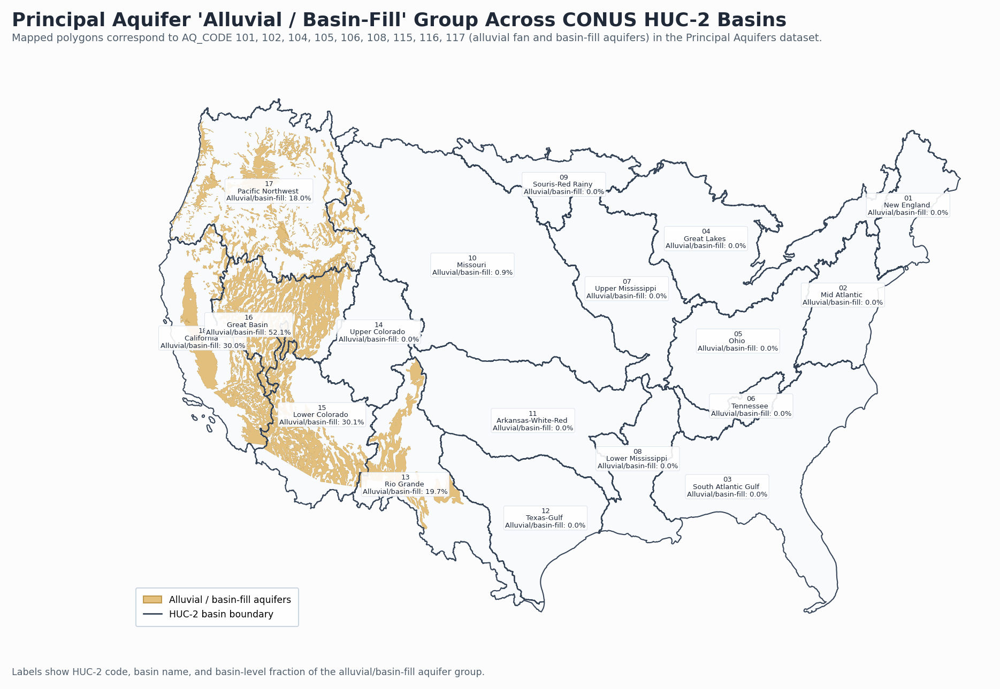

Saved:
/content/drive/MyDrive/ecohydro_project/outputs/figures/pa_alluvial_fan_basin_fill_huc2_map.png
/content/drive/MyDrive/ecohydro_project/outputs/figures/pa_alluvial_fan_basin_fill_huc2_map.pdf

Basin values:
huc2                       name  alluvial_fan_basin_fill_fraction
  01         New England Region                            0.0000
  02        Mid Atlantic Region                            0.0000
  03 South Atlantic-Gulf Region                            0.0000
  04         Great Lakes Region                            0.0000
  05                Ohio Region                            0.0000
  06           Tennessee Region                            0.0000
  07   Upper Mississippi Region                            0.0000
  08   Lower Mississippi Region                            0.0000
  09    Souris-Red-Rainy Region                            0.0000
  10            Missouri Region                            0.0091
  11  Arkansas-White-Red Region                            0

In [ ]:
# ============================================================
# Publication-quality CONUS map of Principal Aquifer
# "Alluvial / basin-fill" group (AQ_CODE 101,102,104,105,106,108,115,116,117)
# over HUC-2 basins
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"

PA_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/Hydrogeology/Principal Aquifers of the 48 Conterminous United States, Hawaii, Puerto Rico, and the U.S. Virgin Islands/aquifers_us/us_aquifers.shp"

AQUIFER_FRACTION_FILE = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_aquifer_fractions_step1.csv"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PNG = os.path.join(OUTPUT_DIR, "pa_alluvial_fan_basin_fill_huc2_map.png")
OUTPUT_PDF = os.path.join(OUTPUT_DIR, "pa_alluvial_fan_basin_fill_huc2_map.pdf")

# ------------------------------------------------------------
# 2. Style settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15
})

BG_COLOR = "#fcfcfc"
BASIN_FACE = "#f8fafc"
BASIN_EDGE = "#88939d"
BOUNDARY_COLOR = "#334155"
TEXT_COLOR = "#1f2937"
MUTED_TEXT = "#52606d"
LABEL_TEXT = "#1e293b"
FRAME_COLOR = "#cbd5e1"

ALLUVIAL_FACE = "#d9a441"
ALLUVIAL_EDGE = "#a97a1f"

MAP_CRS = "EPSG:5070"

# ------------------------------------------------------------
# 3. Group definition — alluvial / basin-fill only
# ------------------------------------------------------------
ALLUVIAL_CODES = [101, 102, 104, 105, 106, 108, 115, 116, 117]

# ------------------------------------------------------------
# 4. Load HUC-2 basins
# ------------------------------------------------------------
basins = gpd.read_file(BASIN_FILE)

if "huc2" not in basins.columns:
    raise KeyError(f"'huc2' not found in basin file. Columns: {basins.columns.tolist()}")

basins["huc2"] = (
    basins["huc2"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

basins = basins[basins["huc2"].isin([f"{i:02d}" for i in range(1, 19)])].copy()
basins["geometry"] = basins.geometry.make_valid()

if "name" not in basins.columns:
    if "NAME" in basins.columns:
        basins = basins.rename(columns={"NAME": "name"})
    else:
        raise KeyError(f"No basin-name column found. Columns: {basins.columns.tolist()}")

basins_proj = basins.to_crs(MAP_CRS)

# ------------------------------------------------------------
# 5. Load basin-level fraction table
# ------------------------------------------------------------
aq = pd.read_csv(AQUIFER_FRACTION_FILE)

required_cols = ["huc2", "name", "alluvial_fan_basin_fill_fraction"]
missing = [c for c in required_cols if c not in aq.columns]
if missing:
    raise KeyError(f"Missing expected columns in aquifer fraction file: {missing}")

aq["huc2"] = aq["huc2"].astype(str).str.zfill(2)
aq["alluvial_fan_basin_fill_fraction"] = pd.to_numeric(
    aq["alluvial_fan_basin_fill_fraction"], errors="coerce"
).fillna(0)

basins_proj = basins_proj.merge(
    aq[["huc2", "alluvial_fan_basin_fill_fraction"]],
    on="huc2",
    how="left"
)

basins_proj["alluvial_fan_basin_fill_fraction"] = basins_proj["alluvial_fan_basin_fill_fraction"].fillna(0)

# ------------------------------------------------------------
# 6. Load Principal Aquifers shapefile and isolate the group
# ------------------------------------------------------------
pa = gpd.read_file(PA_FILE)

required_pa_cols = ["AQ_CODE", "geometry"]
missing_pa = [c for c in required_pa_cols if c not in pa.columns]
if missing_pa:
    raise KeyError(f"Missing expected columns in principal aquifer file: {missing_pa}")

if pa.crs is None:
    pa = pa.set_crs("EPSG:4269")

pa = pa.to_crs(MAP_CRS)
pa = pa[pa.geometry.notna()].copy()
pa["geometry"] = pa.geometry.make_valid()

pa["AQ_CODE"] = pd.to_numeric(pa["AQ_CODE"], errors="coerce")

pa_alluvial = pa[pa["AQ_CODE"].isin(ALLUVIAL_CODES)].copy()

# Clip to HUC-2 footprint
pa_alluvial_clip = gpd.overlay(
    pa_alluvial[["geometry"]],
    basins_proj[["geometry"]],
    how="intersection"
)

# ------------------------------------------------------------
# 7. Label positions
# ------------------------------------------------------------
label_basins = basins_proj.copy()
label_basins["label_point"] = label_basins.geometry.representative_point()

label_basins["short_name"] = (
    label_basins["name"]
    .astype(str)
    .str.replace("Region", "", regex=False)
    .str.replace("Atlantic-Gulf", "Atlantic Gulf", regex=False)
    .str.replace("Red-Rainy", "Red Rainy", regex=False)
)

# ------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 8.8))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

# basin background
basins_proj.plot(
    ax=ax,
    facecolor=BASIN_FACE,
    edgecolor=BASIN_EDGE,
    linewidth=0.55,
    zorder=1
)

# alluvial/basin-fill polygons
if len(pa_alluvial_clip) > 0:
    pa_alluvial_clip.plot(
        ax=ax,
        facecolor=ALLUVIAL_FACE,
        edgecolor=ALLUVIAL_EDGE,
        linewidth=0.18,
        alpha=0.68,
        zorder=2
    )

# basin boundaries
basins_proj.boundary.plot(
    ax=ax,
    color=BOUNDARY_COLOR,
    linewidth=1.0,
    alpha=0.95,
    zorder=3
)

# ------------------------------------------------------------
# 9. Basin labels
# ------------------------------------------------------------
for _, row in label_basins.iterrows():
    x, y = row["label_point"].x, row["label_point"].y
    frac = row["alluvial_fan_basin_fill_fraction"]
    pct = frac * 100

    label = (
        f'{row["huc2"]}\n'
        f'{row["short_name"]}\n'
        f'Alluvial/basin-fill: {pct:.1f}%'
    )

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=6.3,
        fontweight="medium",
        color=LABEL_TEXT,
        linespacing=1.03,
        zorder=4,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="#cbd5e1",
            linewidth=0.35,
            alpha=0.90
        )
    )

# ------------------------------------------------------------
# 10. Extent
# ------------------------------------------------------------
xmin, ymin, xmax, ymax = basins_proj.total_bounds
xpad = (xmax - xmin) * 0.035
ypad = (ymax - ymin) * 0.035

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 11. Titles and notes
# ------------------------------------------------------------
fig.suptitle(
    "Principal Aquifer 'Alluvial / Basin-Fill' Group Across CONUS HUC-2 Basins",
    x=0.06,
    y=0.968,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color=TEXT_COLOR
)

fig.text(
    0.06,
    0.938,
    "Mapped polygons correspond to AQ_CODE 101, 102, 104, 105, 106, 108, 115, 116, 117 "
    "(alluvial fan and basin-fill aquifers) in the Principal Aquifers dataset.",
    ha="left",
    va="top",
    fontsize=9.3,
    color=MUTED_TEXT
)

fig.text(
    0.06,
    0.025,
    "Labels show HUC-2 code, basin name, and basin-level fraction of the alluvial/basin-fill aquifer group.",
    ha="left",
    va="bottom",
    fontsize=8.4,
    color=MUTED_TEXT
)

# ------------------------------------------------------------
# 12. Legend
# ------------------------------------------------------------
legend_elements = [
    Patch(
        facecolor=ALLUVIAL_FACE,
        edgecolor=ALLUVIAL_EDGE,
        label="Alluvial / basin-fill aquifers",
        alpha=0.68
    ),
    Line2D([0], [0], color=BOUNDARY_COLOR, lw=1.3, label="HUC-2 basin boundary")
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=FRAME_COLOR,
    framealpha=0.97,
    fontsize=8.3,
    borderpad=0.8
)

# ------------------------------------------------------------
# 13. Clean up
# ------------------------------------------------------------
ax.set_axis_off()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor(FRAME_COLOR)
    spine.set_linewidth(0.8)

plt.subplots_adjust(
    left=0.045,
    right=0.985,
    bottom=0.09,
    top=0.87
)

# ------------------------------------------------------------
# 14. Save
# ------------------------------------------------------------
plt.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    OUTPUT_PDF,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved:")
print(OUTPUT_PNG)
print(OUTPUT_PDF)

print("\nBasin values:")
print(
    basins_proj[["huc2", "name", "alluvial_fan_basin_fill_fraction"]]
    .sort_values("huc2")
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

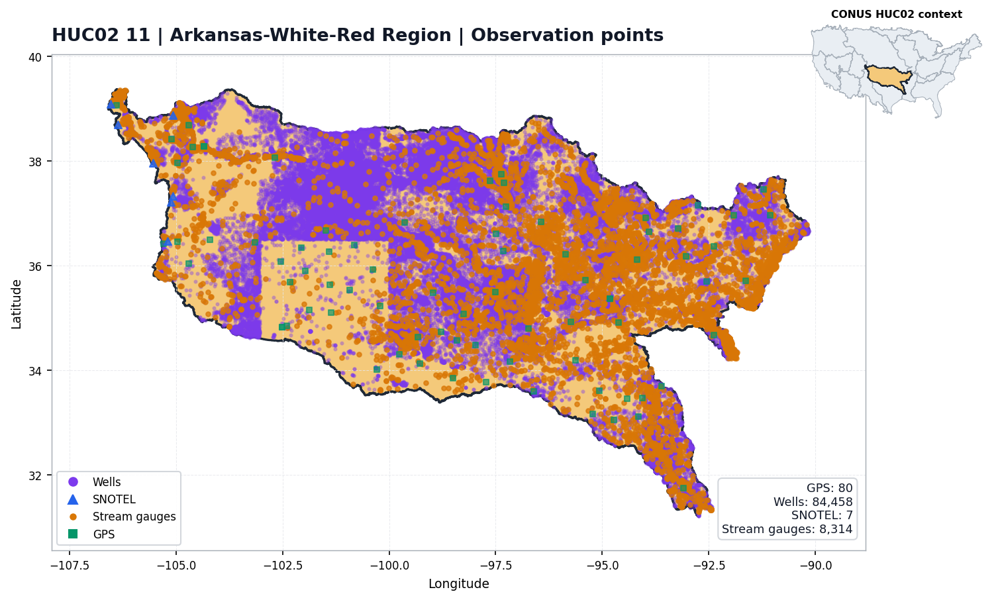

Saved: /content/drive/MyDrive/ecohydro_project/figures/simple_selected_basin_maps/huc02_11_simple_map.png
Saved: /content/drive/MyDrive/ecohydro_project/figures/simple_selected_basin_maps/huc02_11_simple_map.pdf


In [ ]:
# ============================================================
# Plot one selected HUC02 basin with GPS, wells, SNOTEL,
# and stream-gauge point overlays
# Easy to edit: just change TARGET_HUC2
# ============================================================

import os
import warnings
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# Change only this
TARGET_HUC2 = "11"

MASTER_FILE = "/content/drive/MyDrive/ecohydro_project/data/processed/basin_selection/huc2_master_table_with_dem_v3_and_densities.csv"
BASIN_FILE  = "/content/drive/MyDrive/ecohydro_project/data/raw/wbd_2017/wbd_huc02_conus_ee_2017.geojson"

WELL_FILE   = "/content/drive/MyDrive/ecohydro_project/data/raw/wells_metadata/usgs_wells_conus_metadata.csv"
SNOTEL_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/snotel_metadata/nrcs_snotel_stations_conus.csv"
STREAM_FILE = "/content/drive/MyDrive/ecohydro_project/data/raw/stream_gauge_metadata/usgs_stream_gauges_conus_metadata.csv"
GPS_FILE    = "/content/drive/MyDrive/ecohydro_project/data/raw/gps_metadata/peidou_etal_2024/station_catalog_conus_complete.csv"

OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/figures/simple_selected_basin_maps"
os.makedirs(OUTPUT_DIR, exist_ok=True)

COLORS = {
    "basin_fill": "#F4C97A",
    "basin_edge": "#1F2937",
    "context_fill": "#E9EEF3",
    "context_edge": "#A7B0BA",
    "gps": "#059669",
    "well": "#7C3AED",
    "snotel": "#2563EB",
    "stream": "#D97706",
    "text": "#111827",
    "muted": "#6B7280",
    "bg": "#FFFFFF",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 13,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 500,
})

def standardize_huc2(series):
    return (
        series.astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(2)
    )

def find_column(df, candidates):
    lower_cols = {str(c).lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower_cols:
            return lower_cols[c.lower()]
    for c in candidates:
        matches = [col for col in df.columns if c.lower() in str(col).lower()]
        if matches:
            return matches[0]
    raise KeyError(f"Could not find any of these columns: {candidates}")

def load_points(csv_path, lon_candidates, lat_candidates):
    if not os.path.exists(csv_path):
        print(f"Missing file: {csv_path}")
        return None
    df = pd.read_csv(csv_path, low_memory=False)
    lon_col = find_column(df, lon_candidates)
    lat_col = find_column(df, lat_candidates)

    df[lon_col] = pd.to_numeric(df[lon_col], errors="coerce")
    df[lat_col] = pd.to_numeric(df[lat_col], errors="coerce")
    df = df.dropna(subset=[lon_col, lat_col]).copy()

    return gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(df[lon_col], df[lat_col]),
        crs="EPSG:4326"
    )

def clip_points_to_basin(points_gdf, basin_gdf):
    if points_gdf is None or points_gdf.empty:
        return None
    try:
        return gpd.sjoin(points_gdf, basin_gdf[["geometry"]], predicate="within", how="inner")
    except Exception:
        return points_gdf.cx[
            basin_gdf.total_bounds[0]:basin_gdf.total_bounds[2],
            basin_gdf.total_bounds[1]:basin_gdf.total_bounds[3]
        ]

master = pd.read_csv(MASTER_FILE)
master["huc2"] = standardize_huc2(master["huc2"])

basins = gpd.read_file(BASIN_FILE)
huc_col = find_column(basins, ["huc2", "huc02", "huc_2", "huc2_code"])
basins["huc2"] = standardize_huc2(basins[huc_col])

if basins.crs is None:
    basins = basins.set_crs("EPSG:4326")


wells  = load_points(WELL_FILE,   ["longitude", "lon", "x"], ["latitude", "lat", "y"])
snotel = load_points(SNOTEL_FILE, ["longitude", "lon", "x"], ["latitude", "lat", "y"])
stream = load_points(STREAM_FILE, ["longitude", "lon", "x"], ["latitude", "lat", "y"])
gps    = load_points(GPS_FILE,    ["longitude", "lon", "x"], ["latitude", "lat", "y"])

basin = basins[basins["huc2"] == TARGET_HUC2].copy()
row = master[master["huc2"] == TARGET_HUC2].iloc[0]

if basin.empty:
    raise ValueError(f"No basin geometry found for HUC02 = {TARGET_HUC2}")


wells_in  = clip_points_to_basin(wells, basin)
snotel_in = clip_points_to_basin(snotel, basin)
stream_in = clip_points_to_basin(stream, basin)
gps_in    = clip_points_to_basin(gps, basin)

fig = plt.figure(figsize=(10.5, 7.5), facecolor=COLORS["bg"])
ax = fig.add_axes([0.06, 0.08, 0.78, 0.84])
ax.set_facecolor("white")

basin.plot(
    ax=ax,
    facecolor=COLORS["basin_fill"],
    edgecolor=COLORS["basin_edge"],
    linewidth=1.6,
    zorder=1
)


if wells_in is not None and not wells_in.empty:
    wells_in.plot(ax=ax, color=COLORS["well"], marker="o", markersize=4, alpha=0.30, zorder=2)

if snotel_in is not None and not snotel_in.empty:
    snotel_in.plot(ax=ax, color=COLORS["snotel"], marker="^", markersize=28, alpha=0.85, zorder=4)

if stream_in is not None and not stream_in.empty:
    stream_in.plot(ax=ax, color=COLORS["stream"], marker="o", markersize=10, alpha=0.75, zorder=3)

if gps_in is not None and not gps_in.empty:
    gps_in.plot(ax=ax, color=COLORS["gps"], marker="s", markersize=12, alpha=0.65, zorder=3)

minx, miny, maxx, maxy = basin.total_bounds
padx = 0.08 * (maxx - minx)
pady = 0.08 * (maxy - miny)
ax.set_xlim(minx - padx, maxx + padx)
ax.set_ylim(miny - pady, maxy + pady)

ax.set_title(
    f"HUC02 {TARGET_HUC2} | {row['name']} | Observation points",
    loc="left",
    pad=10,
    fontweight="bold",
    color=COLORS["text"]
)

ax.grid(color="#E5E7EB", linestyle="--", linewidth=0.5, alpha=0.8)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# Count box inside plot
count_text = (
    f"GPS: {int(row['gps_count']):,}\n"
    f"Wells: {int(row['well_count']):,}\n"
    f"SNOTEL: {int(row['snotel_count']):,}\n"
    f"Stream gauges: {int(row['stream_gauge_count']):,}"
)

ax.text(
    0.985, 0.03,
    count_text,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=8.5,
    color=COLORS["text"],
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#D1D5DB",
        alpha=0.95
    ),
    zorder=20
)

inset = fig.add_axes([0.78, 0.70, 0.18, 0.22])
inset.set_facecolor("white")

basins.plot(
    ax=inset,
    facecolor=COLORS["context_fill"],
    edgecolor=COLORS["context_edge"],
    linewidth=0.5
)
basin.plot(
    ax=inset,
    facecolor=COLORS["basin_fill"],
    edgecolor=COLORS["basin_edge"],
    linewidth=0.9
)
inset.set_title("CONUS HUC02 context", fontsize=7.5, pad=2)
inset.set_axis_off()

legend_handles = [
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=COLORS["well"], markeredgecolor=COLORS["well"],
           markersize=6, label='Wells'),
    Line2D([0], [0], marker='^', color='none',
           markerfacecolor=COLORS["snotel"], markeredgecolor=COLORS["snotel"],
           markersize=7, label='SNOTEL'),
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=COLORS["stream"], markeredgecolor=COLORS["stream"],
           markersize=4, label='Stream gauges'),
    Line2D([0], [0], marker='s', color='none',
           markerfacecolor=COLORS["gps"], markeredgecolor=COLORS["gps"],
           markersize=6, label='GPS'),
]

ax.legend(
    handles=legend_handles,
    loc="lower left",
    frameon=True,
    framealpha=0.95,
    facecolor="white",
    edgecolor="#D1D5DB"
)

output_png = os.path.join(OUTPUT_DIR, f"huc02_{TARGET_HUC2}_simple_map.png")
output_pdf = os.path.join(OUTPUT_DIR, f"huc02_{TARGET_HUC2}_simple_map.pdf")

fig.savefig(output_png, bbox_inches="tight")
fig.savefig(output_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {output_png}")
print(f"Saved: {output_pdf}")

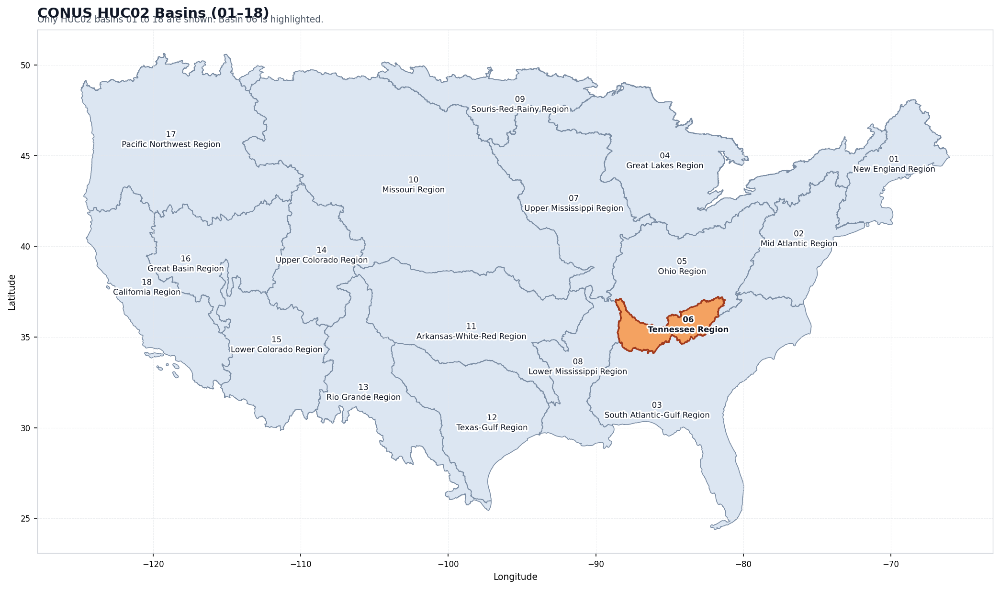

Saved: /content/drive/MyDrive/ecohydro_project/figures/huc02_overview/domestic_huc02_01_to_18_h06_highlighted.png
Saved: /content/drive/MyDrive/ecohydro_project/figures/huc02_overview/domestic_huc02_01_to_18_h06_highlighted.pdf


In [ ]:
# ============================================================
# Plot CONUS HUC02 basins only (01 to 18)
# - Show HUC2 code and basin name on each basin
# - Highlight HUC02 = 06 differently
# - Using domestic_basins_huc02.geojson
# ============================================================

import os
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 1. File paths
# ------------------------------------------------------------
BASIN_FILE = "/content/drive/MyDrive/ecohydro_project/outputs/vectors/domestic_basins_huc02.geojson"
OUTPUT_DIR = "/content/drive/MyDrive/ecohydro_project/figures/huc02_overview"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. Style
# ------------------------------------------------------------
COLORS = {
    "normal_fill": "#DCE6F2",
    "normal_edge": "#7A8CA3",
    "highlight_fill": "#F4A261",
    "highlight_edge": "#A23B1E",
    "text": "#111827",
    "muted": "#4B5563",
    "bg": "#FFFFFF",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 14,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 500,
})


# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------
def find_column(df, candidates):
    lower_cols = {str(c).lower(): c for c in df.columns}

    for c in candidates:
        if c.lower() in lower_cols:
            return lower_cols[c.lower()]

    for c in candidates:
        matches = [col for col in df.columns if c.lower() in str(col).lower()]
        if matches:
            return matches[0]

    raise KeyError(f"Could not find any of these columns: {candidates}")


def standardize_huc2(series):
    return (
        series.astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(2)
    )


# ------------------------------------------------------------
# 4. Read HUC02 basins
# ------------------------------------------------------------
gdf = gpd.read_file(BASIN_FILE)

huc2_col = find_column(gdf, ["huc2", "huc02", "huc_2", "huc2_code"])
name_col = find_column(gdf, ["name", "basin_name", "gnis_name"])

gdf["huc2"] = standardize_huc2(gdf[huc2_col])
gdf["basin_name"] = gdf[name_col].astype(str)

if gdf.crs is None:
    gdf = gdf.set_crs("EPSG:4326")


# ------------------------------------------------------------
# 5. Keep only HUC02 codes 01 to 18
# ------------------------------------------------------------
valid_huc2 = [f"{i:02d}" for i in range(1, 19)]
gdf = gdf[gdf["huc2"].isin(valid_huc2)].copy()

gdf = gdf.sort_values("huc2").reset_index(drop=True)
gdf["label_point"] = gdf.representative_point()


# ------------------------------------------------------------
# 6. Plot
# ------------------------------------------------------------
HIGHLIGHT_HUC2 = "06"

fig, ax = plt.subplots(figsize=(14, 9), facecolor=COLORS["bg"])
ax.set_facecolor("white")

# Plot all basins except highlighted basin
gdf[gdf["huc2"] != HIGHLIGHT_HUC2].plot(
    ax=ax,
    facecolor=COLORS["normal_fill"],
    edgecolor=COLORS["normal_edge"],
    linewidth=0.8,
    zorder=1
)

# Highlight selected basin
gdf[gdf["huc2"] == HIGHLIGHT_HUC2].plot(
    ax=ax,
    facecolor=COLORS["highlight_fill"],
    edgecolor=COLORS["highlight_edge"],
    linewidth=1.4,
    zorder=2
)

# Labels
for _, row in gdf.iterrows():
    x = row["label_point"].x
    y = row["label_point"].y
    label = f"{row['huc2']}\n{row['basin_name']}"

    txt = ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=8,
        color=COLORS["text"],
        fontweight="bold" if row["huc2"] == HIGHLIGHT_HUC2 else "normal",
        zorder=5
    )
    txt.set_path_effects([
        pe.withStroke(linewidth=3, foreground="white")
    ])

# Title and note
ax.set_title(
    "CONUS HUC02 Basins (01–18)",
    loc="left",
    fontweight="bold",
    color=COLORS["text"],
    pad=12
)

ax.text(
    0.00, 1.01,
    "Only HUC02 basins 01 to 18 are shown. Basin 06 is highlighted.",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=9,
    color=COLORS["muted"]
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(color="#E5E7EB", linestyle="--", linewidth=0.5, alpha=0.7)

for spine in ax.spines.values():
    spine.set_color("#D1D5DB")

plt.tight_layout()


# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------
output_png = os.path.join(OUTPUT_DIR, "domestic_huc02_01_to_18_h06_highlighted.png")
output_pdf = os.path.join(OUTPUT_DIR, "domestic_huc02_01_to_18_h06_highlighted.pdf")

fig.savefig(output_png, bbox_inches="tight")
fig.savefig(output_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {output_png}")
print(f"Saved: {output_pdf}")